# PHM2018 종합 수행 결과 — V1 · V2 · V3

**정리 기준일: 2026-11-12 · 실제 데이터의 저장된 수행 결과 · 시간 표기는 raw**

원본 점검/EDA → V1 모델58개·그룹 교차검증16개 → V2 원본 재감사·대표2대 진단 → V3 전체20대 전처리/시각화 → 공통 모델 비교 → seed 민감도 → 보호된 장비 그룹 검증 → 모델/임계값 동결·최종 시간 평가 →03M02 전용 모델 파일럿을 종합했습니다.

표와 그림, 설정·검사 기록을 파일 안에 내장했습니다. 저장된 출력으로 바로 읽을 수 있고, 다른 폴더에서 전체 셀을 재실행할 수 있습니다. 실행에 pandas/PyArrow/IPython이 필요합니다. 원본 CSV나 모델 파일 없이 저장 결과를 조회하며 새 학습·모델 추론·임계값 탐색은 수행하지 않습니다. 원본82백만 행과 모든 모델 바이너리를 포함한 학습 재현 패키지는 아닙니다.

**현재 핵심 결과:** V3 최종 B 공통 모델은 두 고정 설정에서7/194개와33/194개를 검출했습니다. 입력 가용91개 기준은7.7%/36.3%입니다. 장비 전용 파일럿03M02는 후반 입력 가용3개 고장을 검출하지 못했습니다. 입력 공백·미확인 정답·경보 부담 때문에 현재는 연구 기준선으로 보존합니다.

**읽는 순서:** [버전 차이](#section-1) · [V1 연구](#section-2) · [V2 재검증](#section-3) · [V3 원본/전처리](#section-4) · [라벨](#section-5) · [특징/이벤트](#section-6) · [분할](#section-7) · [경보 평가](#section-8) · [최초 학습](#section-9) · [공통 코호트](#section-10) · [튜닝/seed](#section-11) · [장비 그룹](#section-12) · [동결/최종 평가](#section-13) · [장비 전용](#section-14) · [자원/검증](#section-15) · [종합 판단](#section-16) · [전체 표 목록](#section-17) · [원문 보고서](#section-18)

이전 보고서와 그림의 “미학습/holdout 미사용/다음 단계” 문구는 **당시 시점의 기록**입니다. V1은 A/B/C=8/80/83, V2/V3는8/32/44로 정의가 다릅니다. V1에 초 단위 해석을 지지한 기록이 있어도 이 종합본에서 새 단위 검증을 수행한 것은 아니므로 V3 원칙대로 raw를 유지합니다. V1/V3 성능을 같은 평가로 합산하거나 개선 폭으로 계산하지 않습니다.

In [1]:
# 내장 자료 읽기: 원본·모델 파일을 열지 않습니다.
import base64,gzip,hashlib,io,json
import numpy as np,pandas as pd
from IPython.display import display,Markdown
_PACKED='...'
DATA=json.loads(gzip.decompress(base64.b64decode(_PACKED)))
del _PACKED
def T(name):
    key=name if name.startswith(('V1/','V3/')) else 'V3/'+name
    entry=DATA['tables'][key]
    raw=base64.b64decode(entry['data'])
    assert hashlib.sha256(raw).hexdigest()==entry['sha256'],key
    return pd.read_parquet(io.BytesIO(raw))
def J(path):
    return DATA['json'][path]
def show(name,columns=None,rows=30):
    d=T(name)
    if columns is not None:d=d[columns]
    display(Markdown(f'**{name}** · 전체 {len(d):,}행 × {len(d.columns)}열'+(f' · 앞 {rows}행 표시, 전체 값은 `T({name!r})`로 조회' if len(d)>rows else '')))
    with pd.option_context('display.max_rows',rows,'display.max_columns',None,'display.max_colwidth',90,'display.width',180):display(d.head(rows))
def show_frame(d):
    with pd.option_context('display.max_columns',None,'display.max_rows',100,'display.max_colwidth',100):display(d)
print('내장 표:',len(DATA['tables']),'개 | 설정·감사 JSON:',len(DATA['json']),'개 | 이전 Notebook:',len(DATA['notebooks']),'개')


내장 표: 104 개 | 설정·감사 JSON: 58 개 | 이전 Notebook: 26 개


<a id="section-1"></a>

## 1. 버전과 평가 조건의 차이

V1은 초기 표본/모델 연구, V2는 정답 근거 재감사, V3는 명시적 가용성·경보 부담 평가를 강화한 연구입니다. V2가 학습을 중단한 사실과 이후 V3가 연구용 라벨로 실험을 진행한 사실을 함께 기록합니다. 정비 종료·이력 완전성 검증이 끝났다는 뜻은 아닙니다.

In [2]:
show_frame(pd.DataFrame([['V1','8/80/83','원본/EDA·58개 모델·16개 그룹CV','당시 정답·관측 조건의 평가; V3와 직접 비교 불가'],['V2','8/32/44','20대 감사·2대 진단; 모델0회','확정 학습 데이터0행; 배포 차단'],['V3 공통','8/32/44','단계2~6 학습·동결·시간 평가','최종 B; 시간 뒤20% 점수는 선택 전 보류'],['V3 전용','B32','03M02 전용 모델1개','이미 본 뒤20%의 후속 연구 비교'] ],columns=['버전','A/B/C 특징 수','수행 내용','평가 해석']))
tool=T('tool_summary');evt=T('events')
assert len(tool)==20 and int(tool.raw_rows.sum())==82189440 and len(evt)==1211
show_frame(pd.DataFrame({'항목':['장비','원본 train 행','고유 고장','원본 고장 행','중복 제거 행'],'값':[len(tool),int(tool.raw_rows.sum()),len(evt),int(tool.raw_fault_rows.sum()),int(tool.raw_fault_rows.sum())-len(evt)]}))

,버전,A/B/C 특징 수,수행 내용,평가 해석
0,V1,8/80/83,원본/EDA·58개 모델·16개 그룹CV,당시 정답·관측 조건의 평가; V3와 직접 비교 불가
1,V2,8/32/44,20대 감사·2대 진단; 모델0회,확정 학습 데이터0행; 배포 차단
2,V3 공통,8/32/44,단계2~6 학습·동결·시간 평가,최종 B; 시간 뒤20% 점수는 선택 전 보류
3,V3 전용,B32,03M02 전용 모델1개,이미 본 뒤20%의 후속 연구 비교


,항목,값
0,장비,20
1,원본 train 행,82189440
2,고유 고장,1211
3,원본 고장 행,1236
4,중복 제거 행,25


<a id="section-2"></a>

## 2. V1 원본 점검·EDA·최초 모델과 그룹 교차검증

초기 파일65개, train82,189,440행, 공식 test7,198,948행을 점검했습니다. test 파일 점검이 공식 test 성능 평가를 뜻하지 않습니다. Dummy/압력 기준/RF/XGBoost와 식별 보조 변수 진단까지58개 실험, 이후4-Fold×4구성의16개 CUDA 그룹 실험을 수행했습니다. 당시 조건부 이벤트 분모와 V3 전체 기록 분모는 다릅니다. 낮은 조건부 오경보율은 전체 현장 FAR가 아닙니다. 아래 수치는 저장된 과거 집계의 재표시입니다.

In [3]:
v1=J('PHM2018-Project/outputs/stage4/summary.json')
assert v1['checks']['experiments']==58
show_frame(pd.DataFrame(v1['selected_per_family']))
show_frame(pd.DataFrame(v1['event_metrics'])[['scheme','model','events','detected','event_recall','median_lead_raw']])
show_frame(pd.DataFrame(v1['prospective']))
show('V1/stage4/metrics',rows=12)
show('V1/stage4_5/cv_summary',rows=20)
display(Markdown('V1의 시간당 지표는 당시 초 해석에 따른 역사적 값입니다. 현재 V3의 raw 경보 부담과 수치 비교하지 않습니다. 그룹 CV에서 정규화 강화 C의 개선도 Fold 간 변동이 커 안정적 일반화를 입증하지 못했습니다.'))

,scheme,selected_by_validation_AP,validation_AP,precision,recall,f1,pr_auc_ap,roc_auc,tn,fp,fn,tp
0,split_tool,RF_A,0.013677,0.170213,0.069565,0.098765,0.047113,0.583816,30008,117,321,24
1,split_tool,XGB_A,0.011794,1.000000,0.069565,0.130081,0.085175,0.457383,30125,0,321,24
2,split_time,RF_B,0.028168,0.415663,0.145263,0.215289,0.191183,0.636709,9793,97,406,69
3,split_time,XGB_C,0.050873,0.880952,0.155789,0.264758,0.278805,0.643686,9880,10,401,74


,scheme,model,events,detected,event_recall,median_lead_raw
0,split_tool,RF_A,45,4,0.088889,344.0
1,split_tool,XGB_A,45,4,0.088889,344.0
2,split_time,RF_B,56,10,0.178571,552.0
3,split_time,XGB_C,56,17,0.303571,298.0


,scheme,selected_RF_XGB,all_feature_ready_rows,unknown_label_rows,unknown_row_alarm_fraction,recorded_events,evaluable_events,event_coverage,recorded_events_hit,recorded_recall_with_observation_limit,unknown_alarm_episodes,false_alarm_episodes
0,split_time,XGB_C,442840,432475,0.128162,194,56,0.288660,26,0.134021,31440,8
1,split_tool,RF_A,335124,304654,0.260860,244,45,0.184426,8,0.032787,23747,17


**V1/stage4/metrics** · 전체 174행 × 39열 · 앞 12행 표시, 전체 값은 `T('V1/stage4/metrics')`로 조회

,scheme,horizon,name,config,split,threshold,identity_diagnostic,n,positive,negative,precision,recall,f1,pr_auc_ap,roc_auc,accuracy,tn,fp,fn,tp,evaluable_events,detected_events,event_recall,recorded_events,recorded_events_hit,recorded_recall_with_observation_limit,event_coverage,alarm_episodes,false_alarm_episodes,unknown_alarm_episodes,negative_exposure_raw,false_alarms_per_3600raw,false_alarm_time_fraction,active_negative_exposure_raw,active_false_alarm_episodes,false_alarms_per_active_hour_seconds_interpretation,lead_time_median_raw,lead_time_min_raw,lead_time_max_raw
0,split_time,1800,Dummy,none,train,0.500000,False,294751,3103,291648,NaN,0.000000,0.000000,0.010528,0.500000,0.989472,291648,0,3103,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,split_time,1800,Dummy,none,validation,0.500000,False,49029,1056,47973,NaN,0.000000,0.000000,0.021538,0.500000,0.978462,47973,0,1056,0,56.0,0.0,0.000000,232.0,0.0,0.000000,0.241379,0.0,0.0,0.0,2804122.0,0.000000,0.000000,2781082.0,0.0,0.000000,NaN,NaN,NaN
2,split_time,1800,Dummy,none,evaluation,0.500000,False,5245,1171,4074,NaN,0.000000,0.000000,0.223260,0.500000,0.776740,4074,0,1171,0,56.0,0.0,0.000000,194.0,0.0,0.000000,0.288660,0.0,0.0,0.0,236636.0,0.000000,0.000000,236636.0,0.0,0.000000,NaN,NaN,NaN
3,split_time,1800,Pressure,pressure,train,0.867430,False,294751,3103,291648,0.021241,0.267483,0.039356,0.014354,0.497110,0.862531,253402,38246,2273,830,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,split_time,1800,Pressure,pressure,validation,0.867430,False,49029,1056,47973,0.088082,0.351326,0.140850,0.090852,0.484401,0.907687,44132,3841,685,371,56.0,24.0,0.428571,232.0,24.0,0.103448,0.241379,181.0,156.0,0.0,2804122.0,0.200277,0.082078,2781082.0,156.0,0.201936,764.0,2.0,1794.0
5,split_time,1800,Pressure,pressure,evaluation,0.867430,False,5245,1171,4074,0.287212,0.233988,0.257882,0.383394,0.538752,0.699333,3394,680,897,274,56.0,20.0,0.357143,194.0,20.0,0.103093,0.288660,53.0,30.0,0.0,236636.0,0.456397,0.171402,236636.0,30.0,0.456397,453.0,2.0,1800.0
6,split_time,1800,RF_A,A,train,0.775855,False,294751,3103,291648,0.413301,0.652917,0.506184,0.552137,0.980526,0.986589,288772,2876,1077,2026,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,split_time,1800,RF_A,A,validation,0.775855,False,49029,1056,47973,0.384354,0.107008,0.167407,0.109575,0.777994,0.977075,47792,181,943,113,56.0,11.0,0.196429,232.0,11.0,0.047414,0.241379,86.0,68.0,0.0,2804122.0,0.087300,0.005092,2781082.0,68.0,0.088023,774.0,28.0,1774.0
8,split_time,1800,RF_A,A,evaluation,0.775855,False,5245,1171,4074,0.751678,0.095645,0.169697,0.519541,0.751190,0.791039,4037,37,1059,112,56.0,14.0,0.250000,194.0,14.0,0.072165,0.288660,26.0,6.0,0.0,236636.0,0.091279,0.010142,236636.0,6.0,0.091279,414.0,2.0,1780.0
9,split_time,1800,RF_B,B,train,0.717759,False,294751,3103,291648,0.398090,0.792459,0.529957,0.648560,0.989395,0.985201,287930,3718,644,2459,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**V1/stage4_5/cv_summary** · 전체 8행 × 16열

,model,policy,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,pr_auc_ap_mean,pr_auc_ap_std,event_recall_mean,event_recall_std,false_alarms_per_active_hour_mean,false_alarms_per_active_hour_std,lead_time_median_raw_mean,lead_time_median_raw_std
0,A,event_far,0.084000,0.143763,0.065171,0.127001,0.003465,0.004674,0.012257,0.014817,0.078793,0.143893,0.799327,1.596704,386.000000,93.338095
1,A,f1,0.002470,0.003556,0.220475,0.269994,0.004880,0.007015,0.012257,0.014817,0.267183,0.342236,1.487565,1.750742,475.500000,33.234019
2,B,event_far,0.029001,0.038678,0.023621,0.037885,0.017228,0.032501,0.009328,0.007101,0.088390,0.140331,0.143208,0.193910,72.500000,0.707107
3,B,f1,0.016923,0.026312,0.317794,0.458401,0.021925,0.029437,0.009328,0.007101,0.407010,0.373380,1.617664,2.570927,216.750000,234.994149
4,C,event_far,0.029294,0.038264,0.023621,0.037885,0.017457,0.032370,0.009492,0.007465,0.088390,0.140331,0.142571,0.192740,72.500000,0.707107
5,C,f1,0.017147,0.026414,0.294297,0.472378,0.022202,0.029970,0.009492,0.007465,0.354871,0.413725,1.539215,2.618728,253.666667,273.233112
6,C_regularized,event_far,0.025934,0.032782,0.091456,0.105623,0.020770,0.038009,0.005864,0.005250,0.174613,0.222051,0.756848,1.326254,239.000000,147.078210
7,C_regularized,f1,0.010503,0.017079,0.381875,0.412294,0.018097,0.028410,0.005864,0.005250,0.457137,0.349413,2.993185,1.987291,350.250000,175.613923


V1의 시간당 지표는 당시 초 해석에 따른 역사적 값입니다. 현재 V3의 raw 경보 부담과 수치 비교하지 않습니다. 그룹 CV에서 정규화 강화 C의 개선도 Fold 간 변동이 커 안정적 일반화를 입증하지 못했습니다.

<a id="fig-087"></a>

**event process conditions**

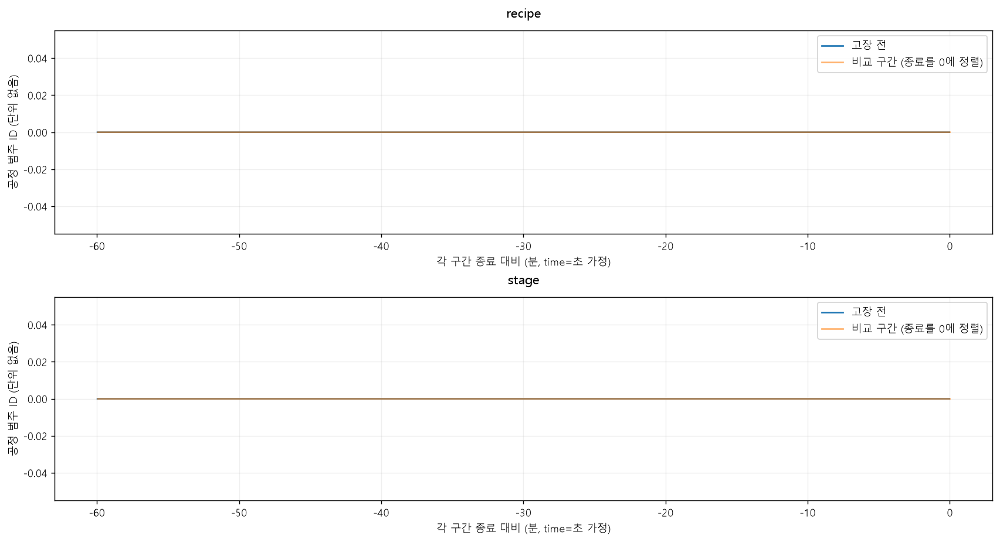

출처: `PHM2018-Project/reports/local/eda/figures/event_process_conditions.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-088"></a>

**fault distribution**

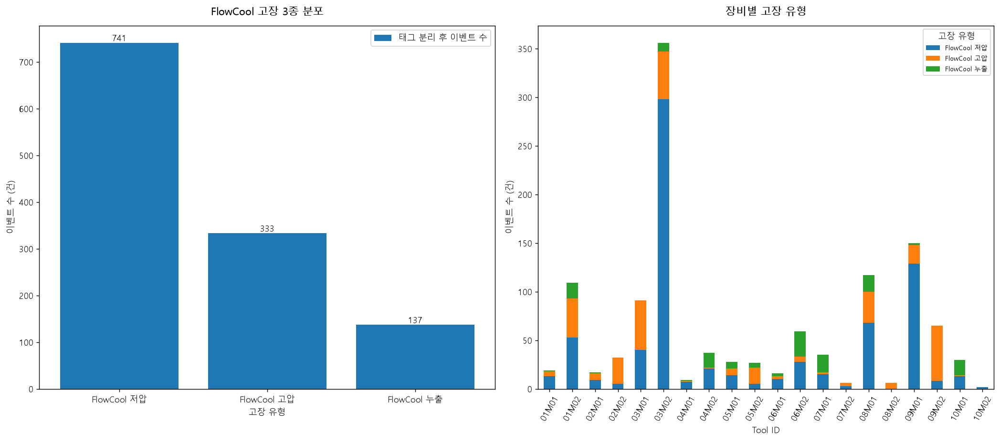

출처: `PHM2018-Project/reports/local/eda/figures/fault_distribution.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-089"></a>

**pre event**

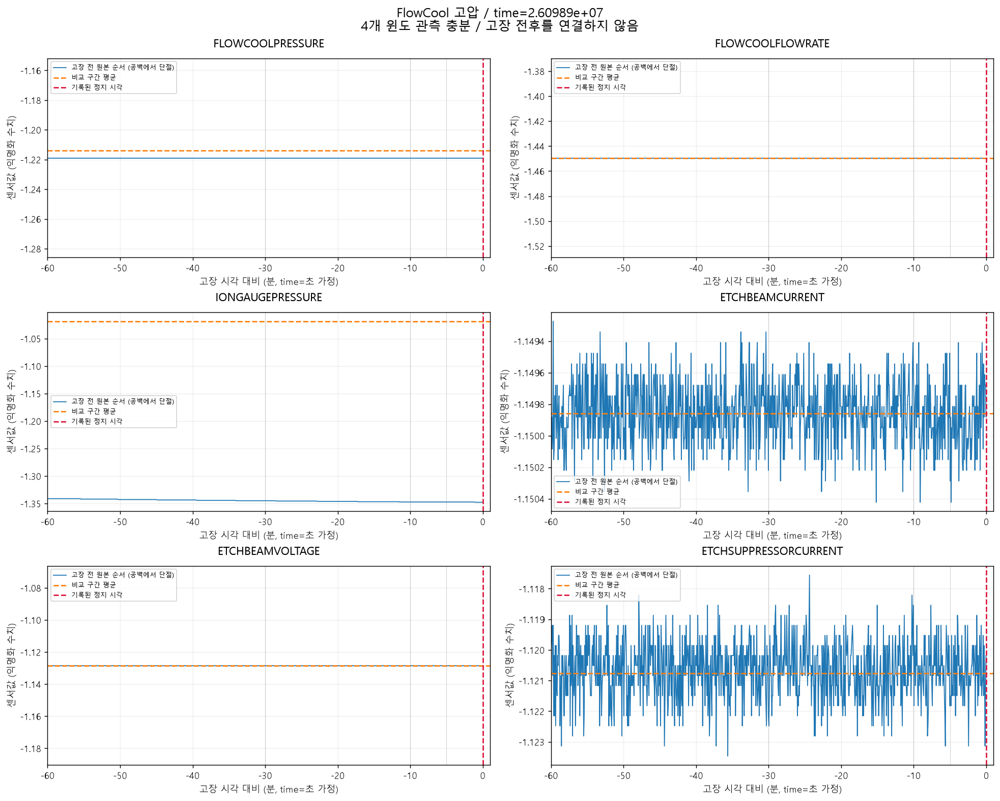

출처: `PHM2018-Project/reports/local/eda/figures/pre_event.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-090"></a>

**process sensor means**

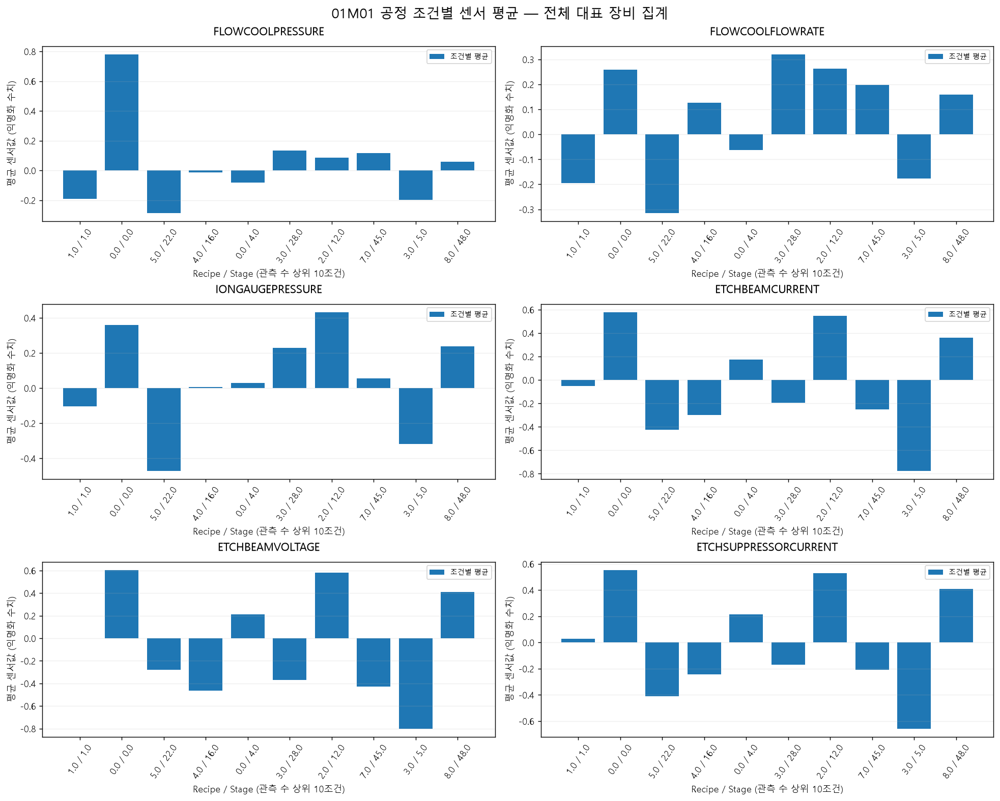

출처: `PHM2018-Project/reports/local/eda/figures/process_sensor_means.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-091"></a>

**recipe stage distribution**

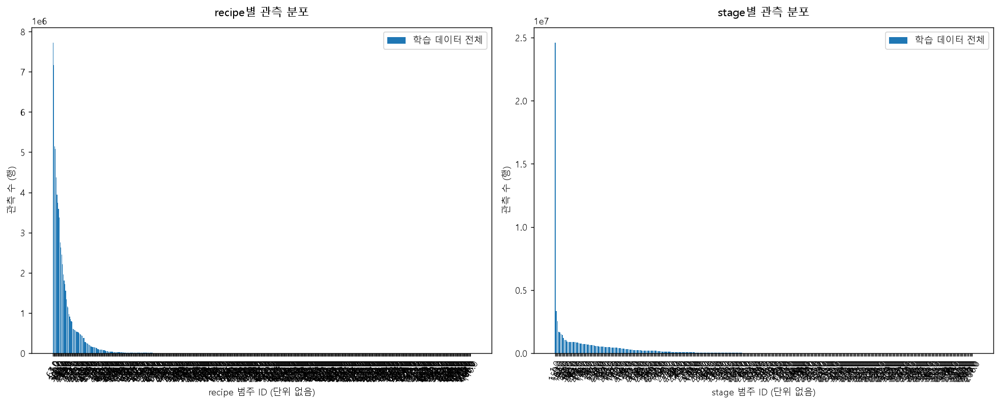

출처: `PHM2018-Project/reports/local/eda/figures/recipe_stage_distribution.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-092"></a>

**secondary pre event**

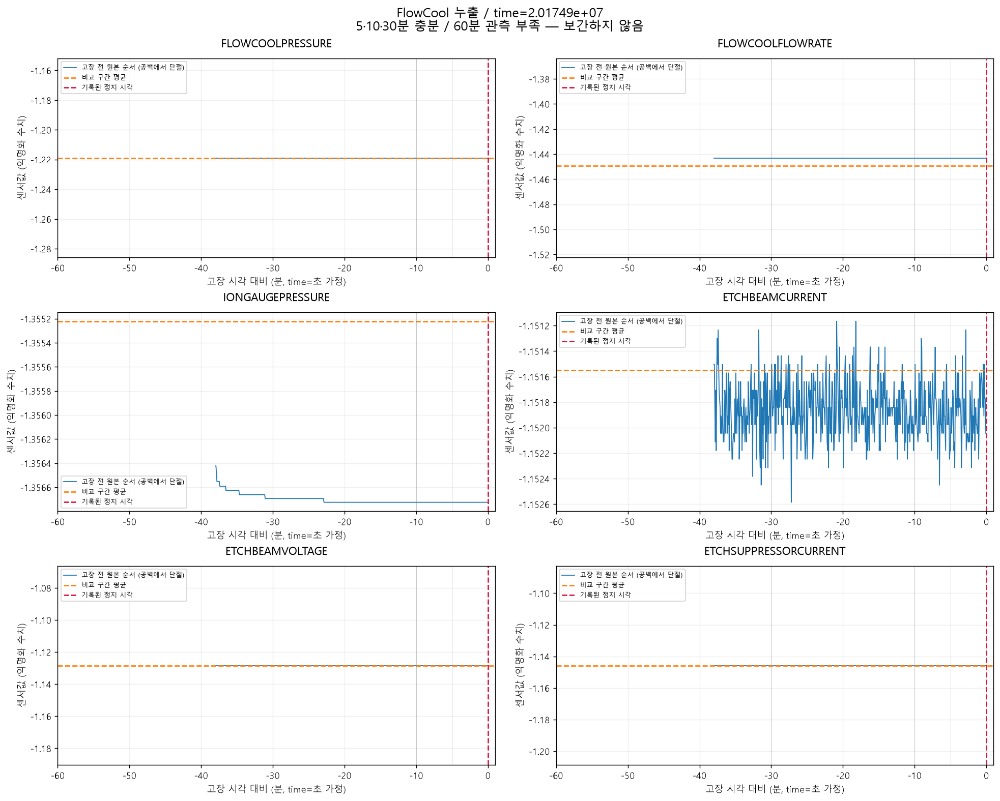

출처: `PHM2018-Project/reports/local/eda/figures/secondary_pre_event.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-093"></a>

**sensor correlation**

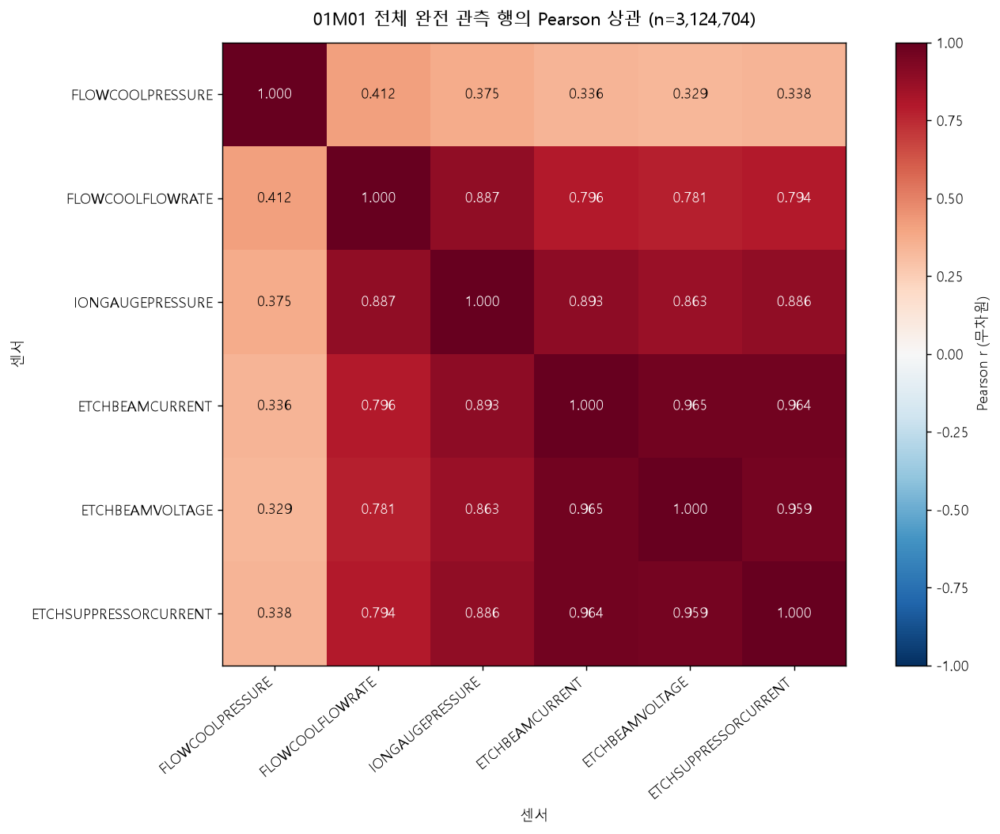

출처: `PHM2018-Project/reports/local/eda/figures/sensor_correlation.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-094"></a>

**sensor histograms**

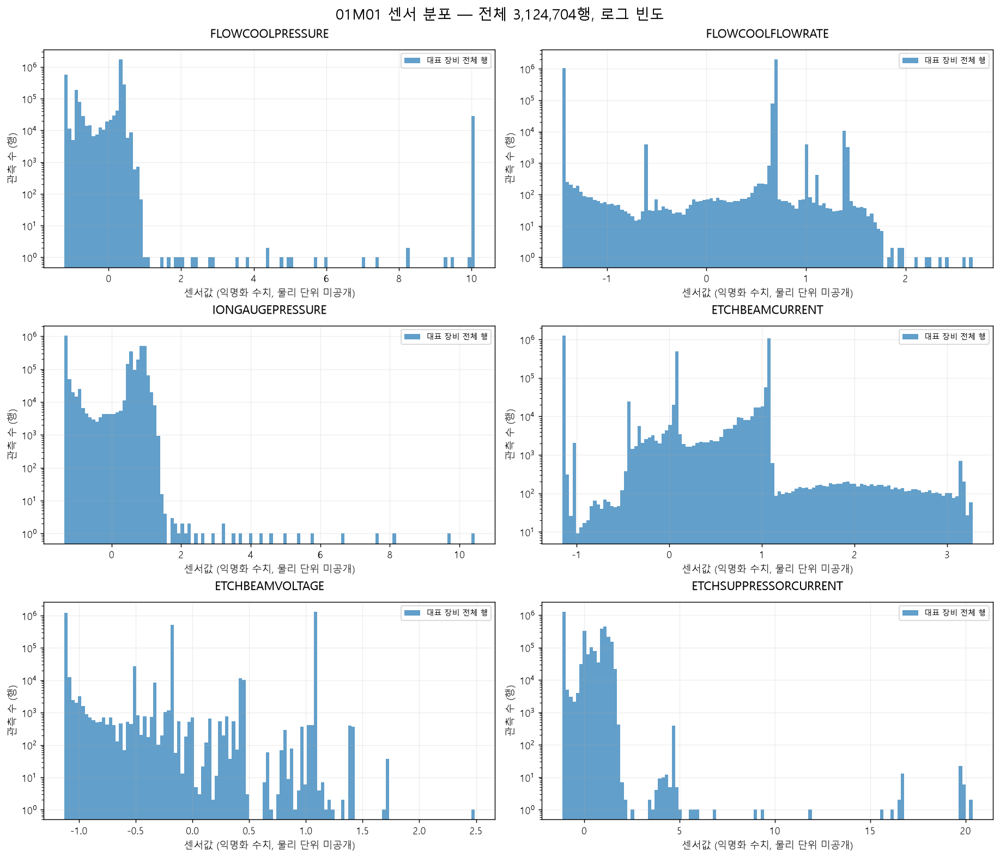

출처: `PHM2018-Project/reports/local/eda/figures/sensor_histograms.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-095"></a>

**sensor timeline**

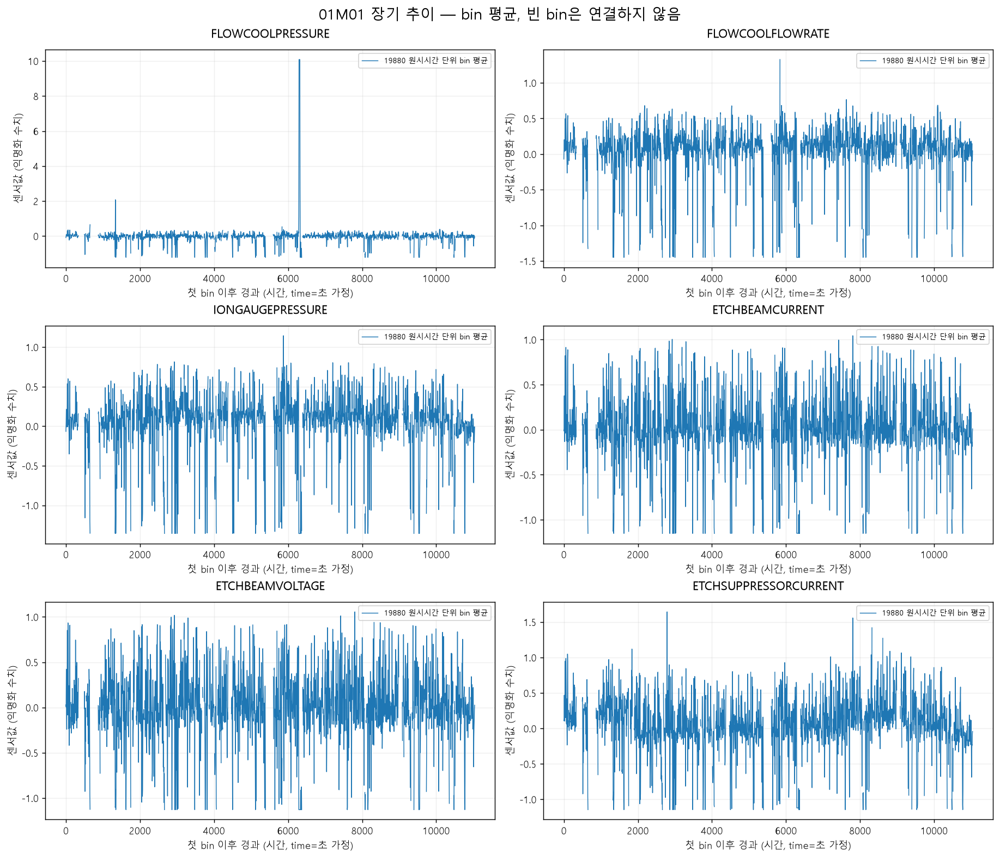

출처: `PHM2018-Project/reports/local/eda/figures/sensor_timeline.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-096"></a>

**tool rows**

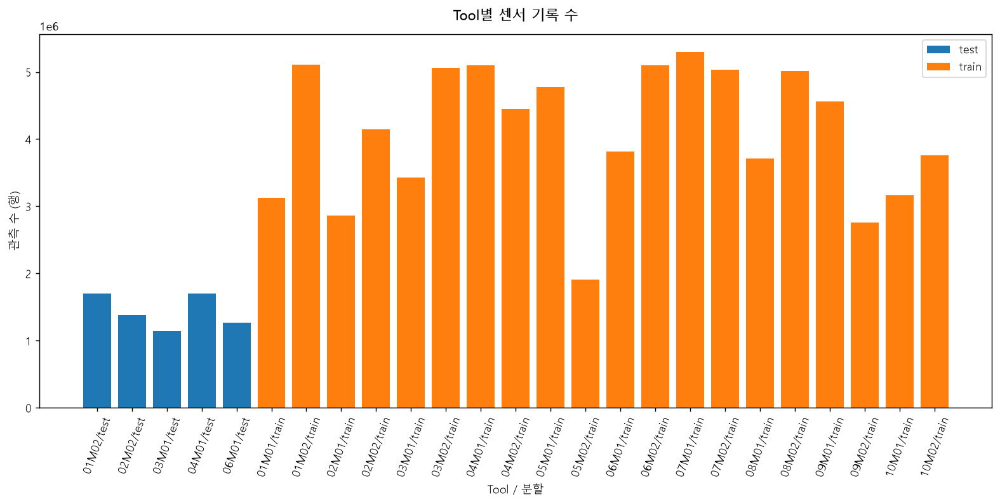

출처: `PHM2018-Project/reports/local/eda/figures/tool_rows.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-097"></a>

**baseline comparison**

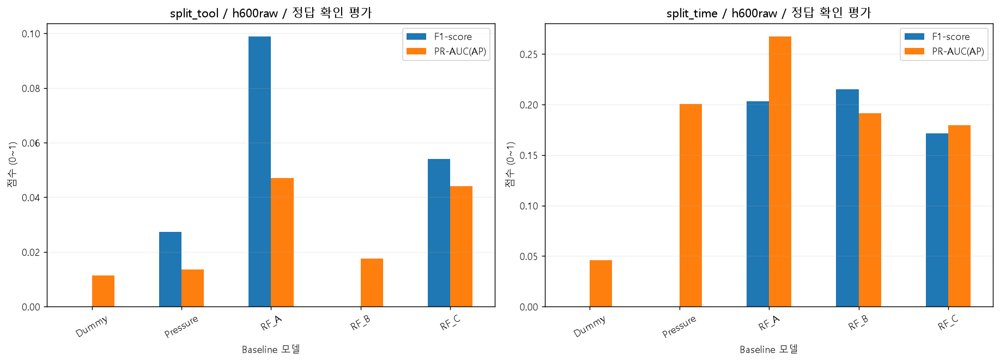

출처: `PHM2018-Project/outputs/stage4/figures/baseline_comparison.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-098"></a>

**split time confusion**

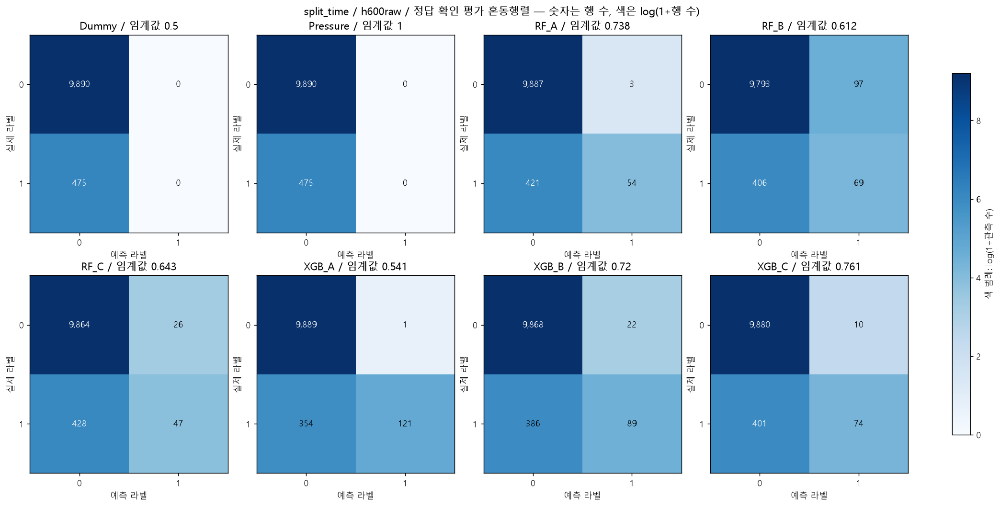

출처: `PHM2018-Project/outputs/stage4/figures/split_time_confusion.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-099"></a>

**split time false alarm case**

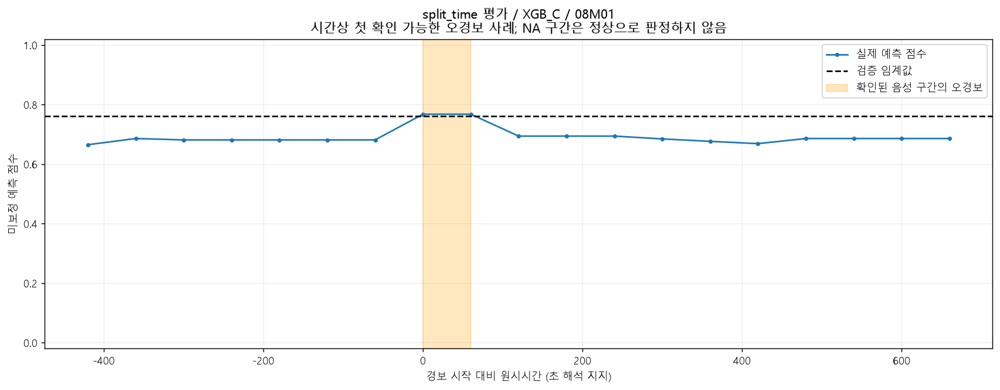

출처: `PHM2018-Project/outputs/stage4/figures/split_time_false_alarm_case.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-100"></a>

**split time importance**

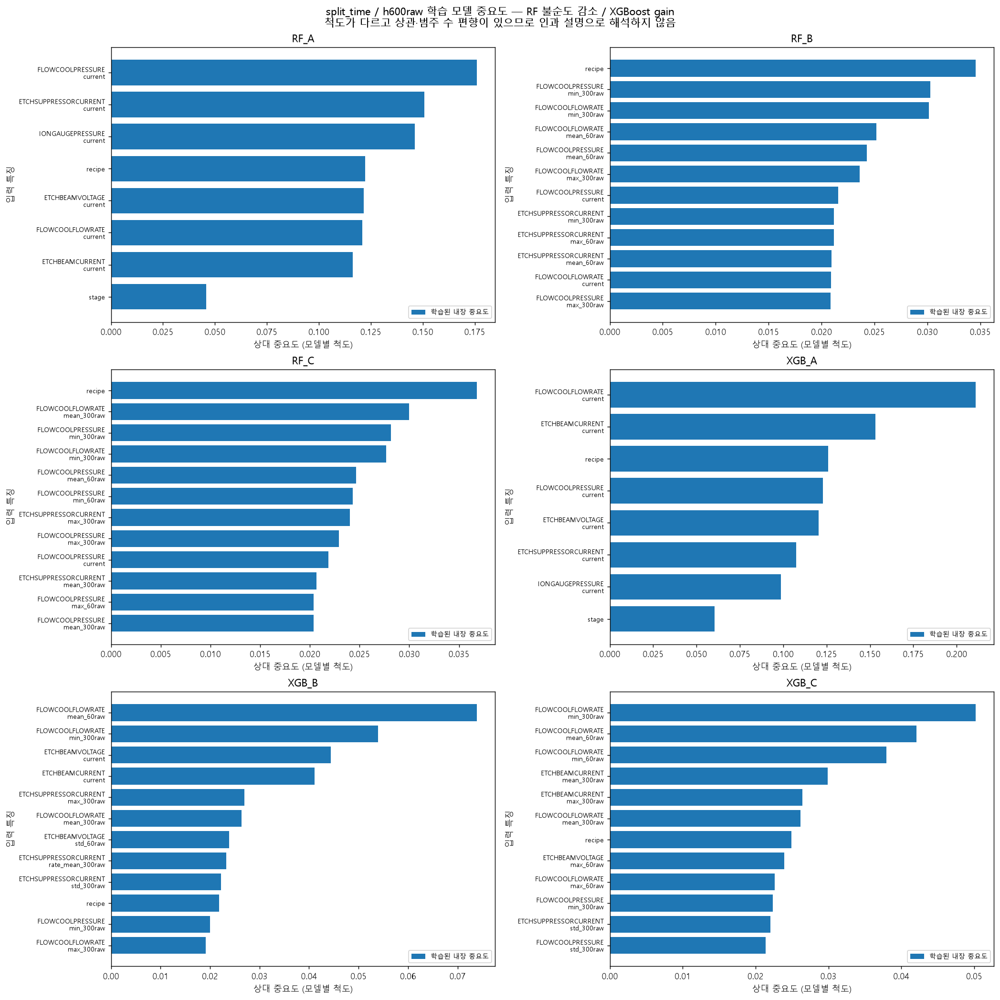

출처: `PHM2018-Project/outputs/stage4/figures/split_time_importance.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-101"></a>

**split time metrics**

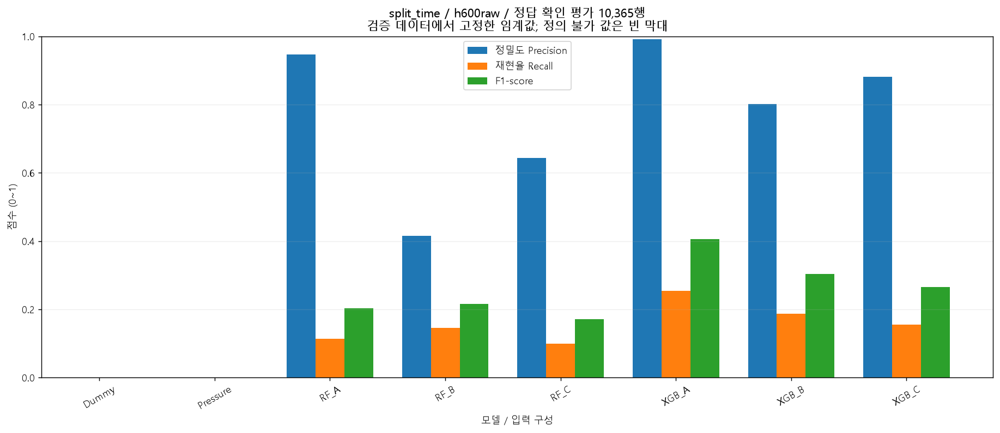

출처: `PHM2018-Project/outputs/stage4/figures/split_time_metrics.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-102"></a>

**split time pr curves**

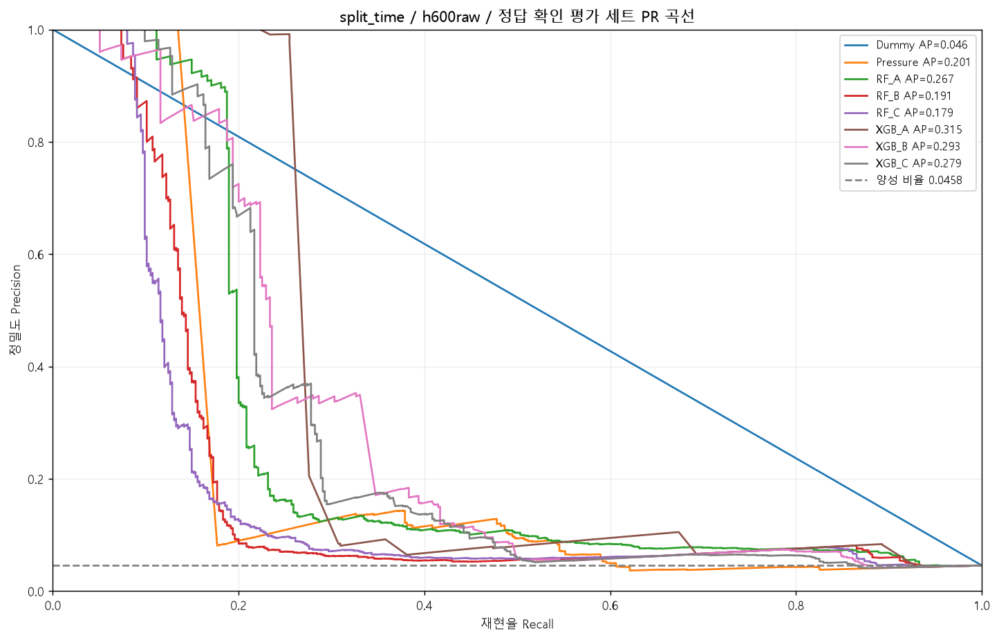

출처: `PHM2018-Project/outputs/stage4/figures/split_time_pr_curves.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-103"></a>

**split time pre fault scores**

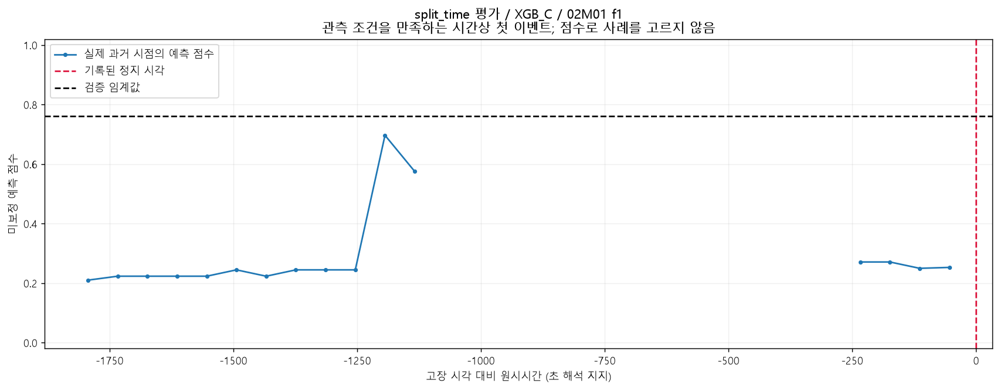

출처: `PHM2018-Project/outputs/stage4/figures/split_time_pre_fault_scores.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-104"></a>

**split time score distribution**

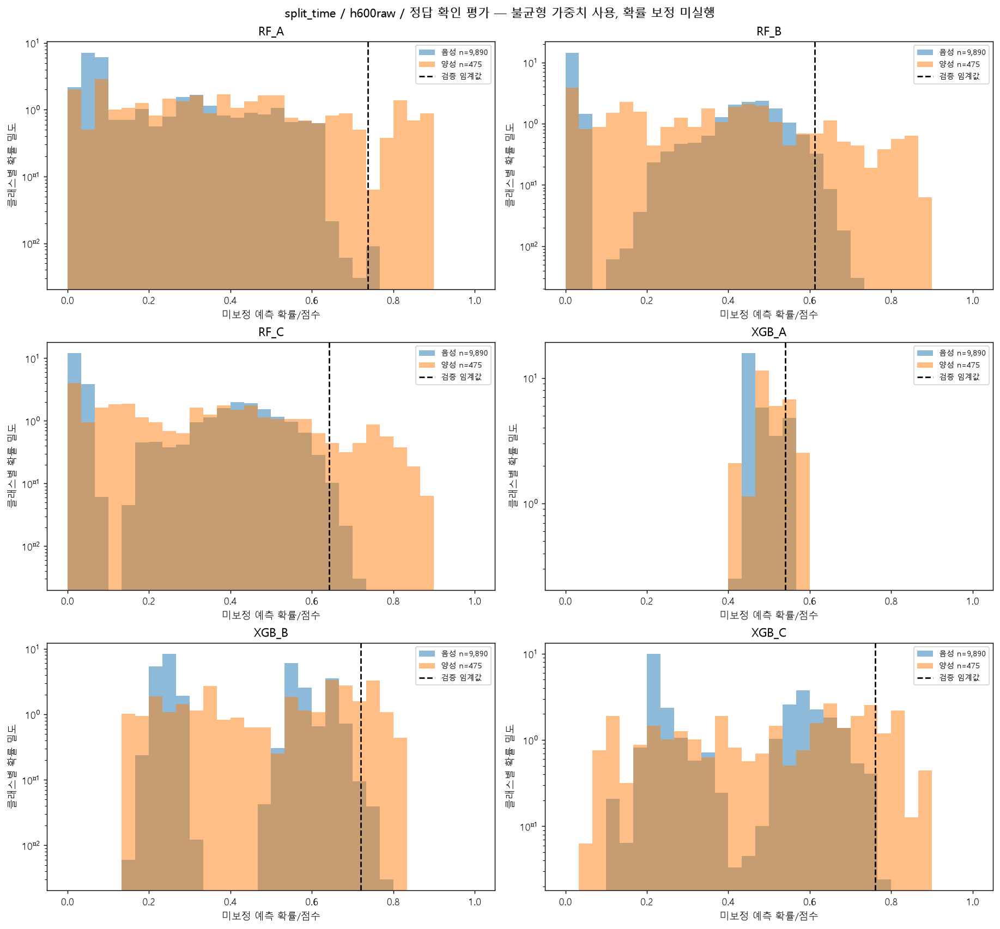

출처: `PHM2018-Project/outputs/stage4/figures/split_time_score_distribution.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-105"></a>

**split tool confusion**

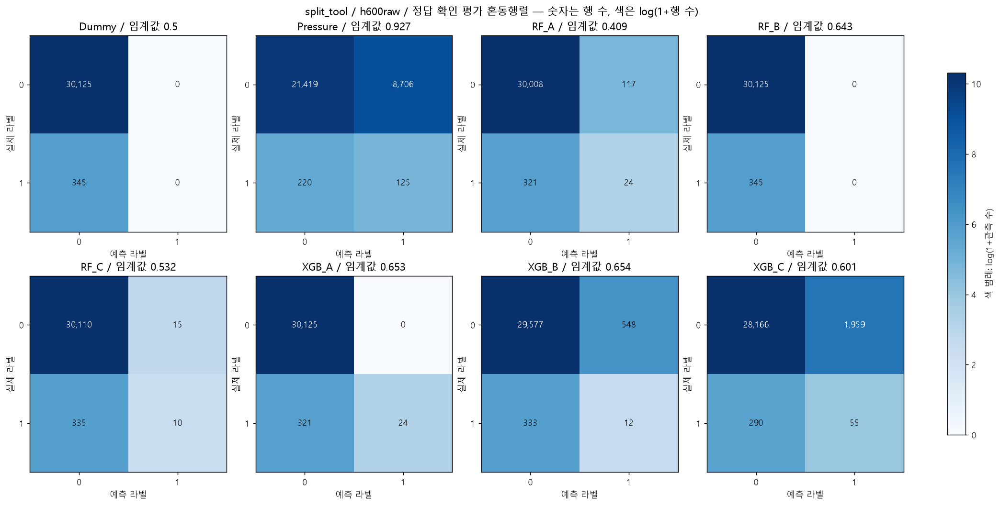

출처: `PHM2018-Project/outputs/stage4/figures/split_tool_confusion.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-106"></a>

**split tool false alarm case**

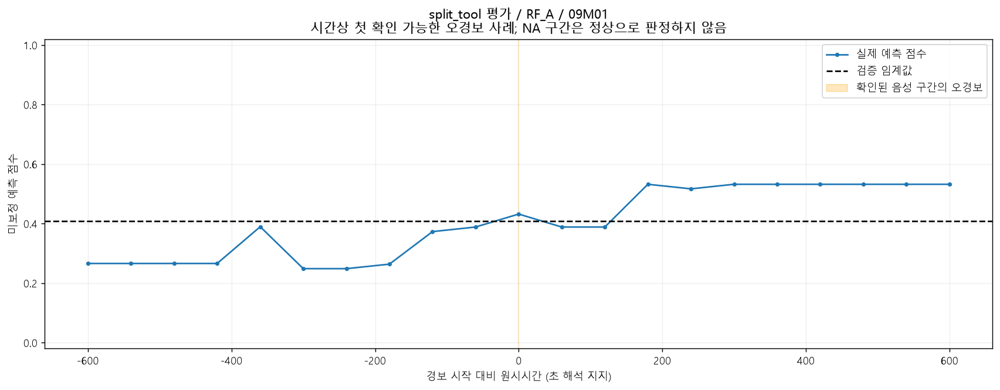

출처: `PHM2018-Project/outputs/stage4/figures/split_tool_false_alarm_case.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-107"></a>

**split tool importance**

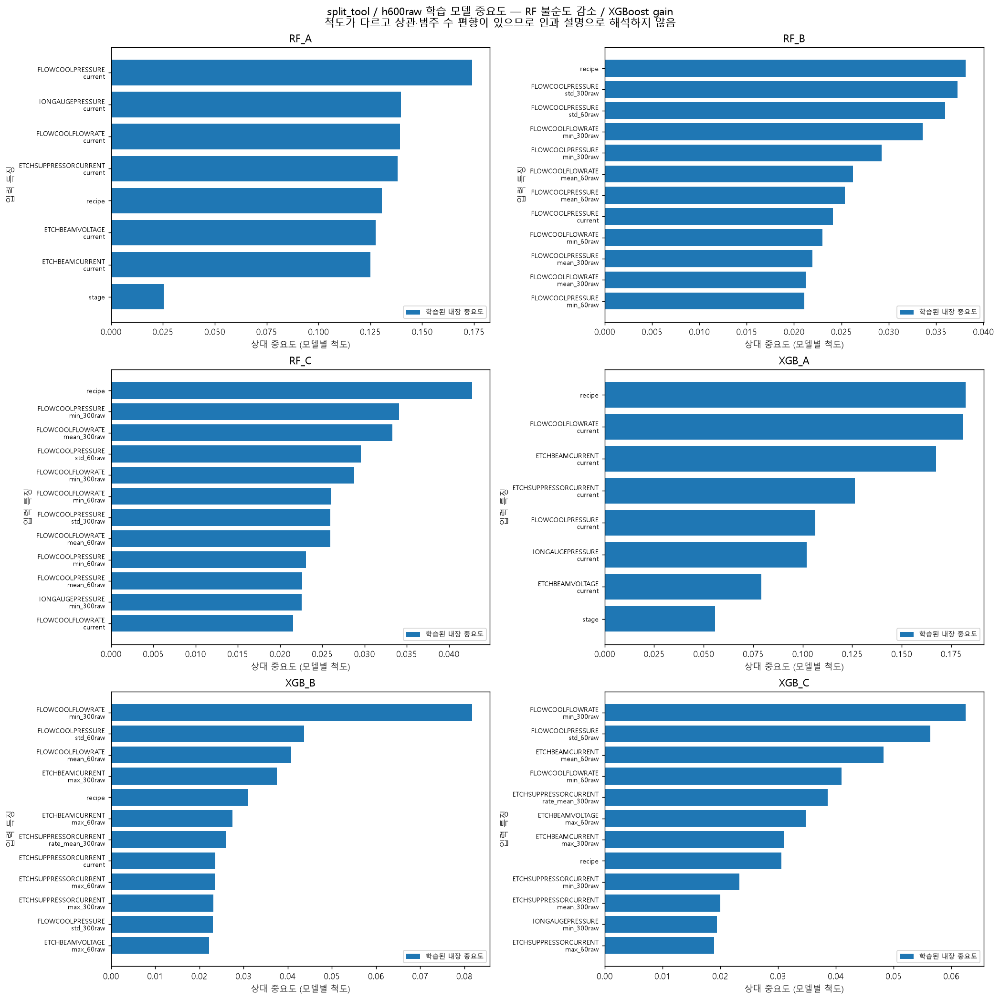

출처: `PHM2018-Project/outputs/stage4/figures/split_tool_importance.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-108"></a>

**split tool metrics**

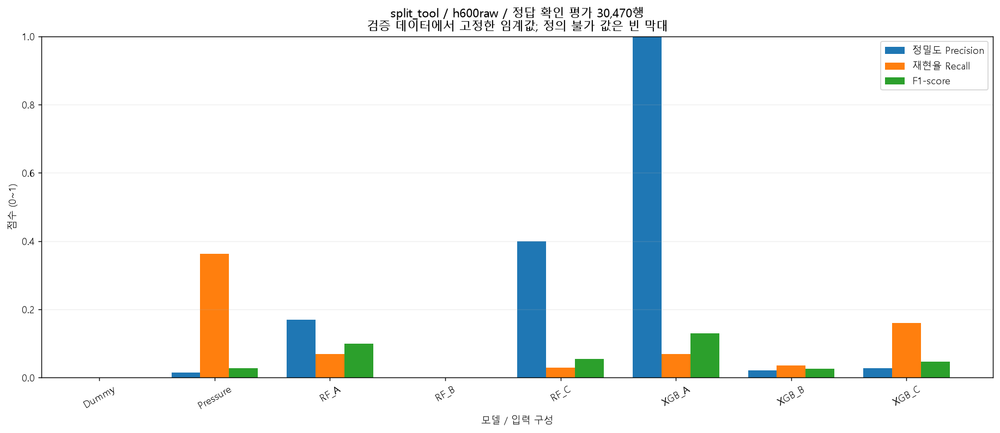

출처: `PHM2018-Project/outputs/stage4/figures/split_tool_metrics.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-109"></a>

**split tool pr curves**

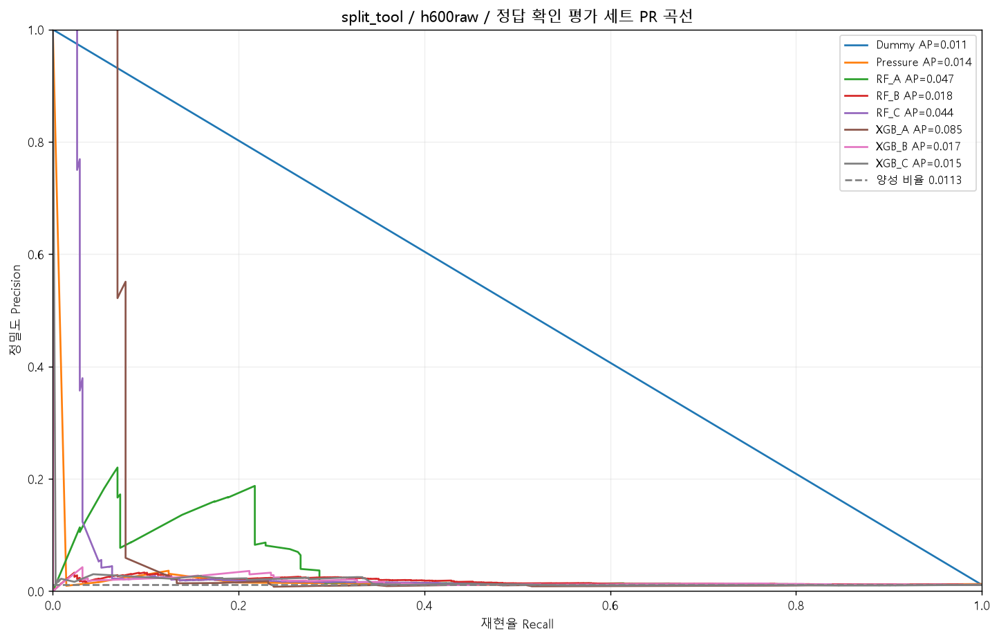

출처: `PHM2018-Project/outputs/stage4/figures/split_tool_pr_curves.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-110"></a>

**split tool pre fault scores**

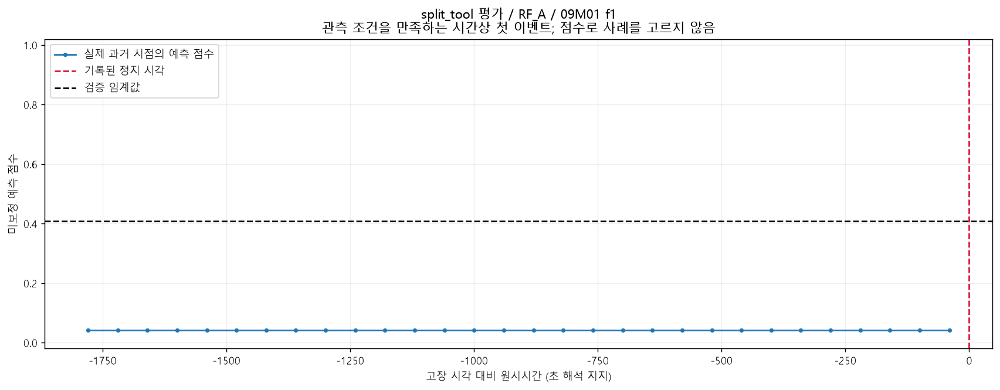

출처: `PHM2018-Project/outputs/stage4/figures/split_tool_pre_fault_scores.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-111"></a>

**split tool score distribution**

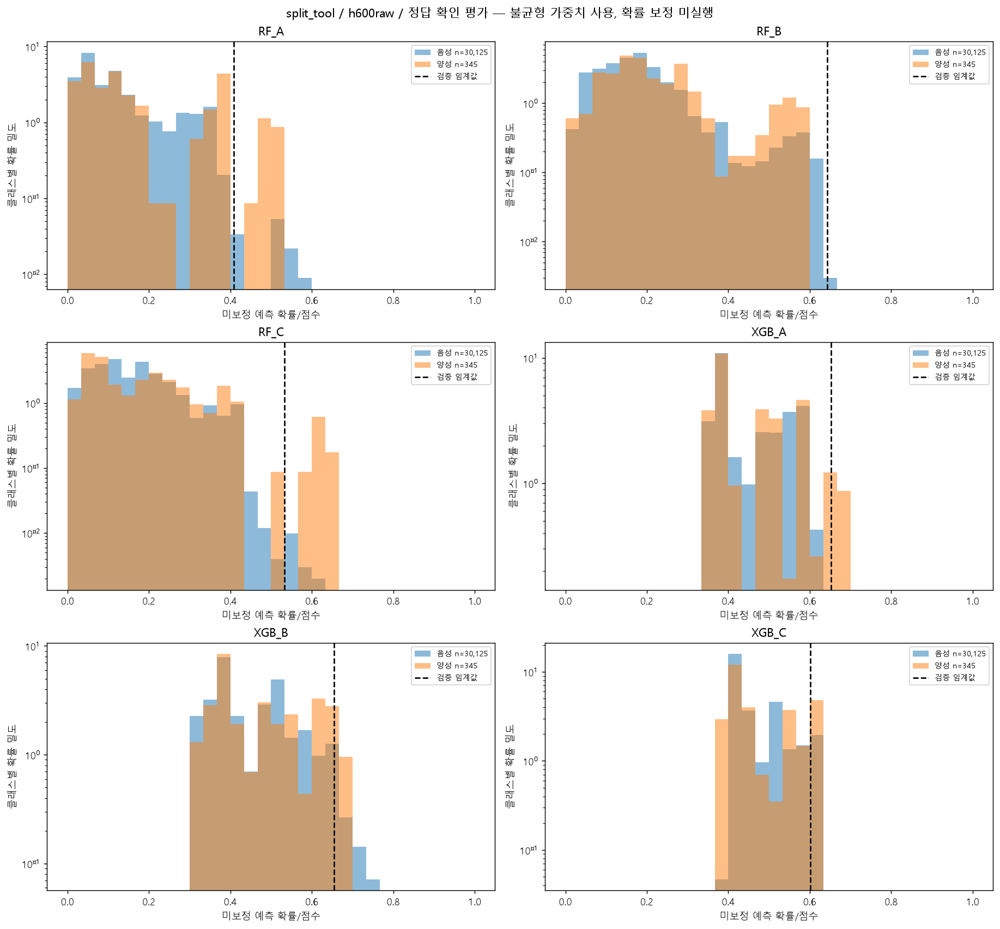

출처: `PHM2018-Project/outputs/stage4/figures/split_tool_score_distribution.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-112"></a>

**xgboost learning curves**

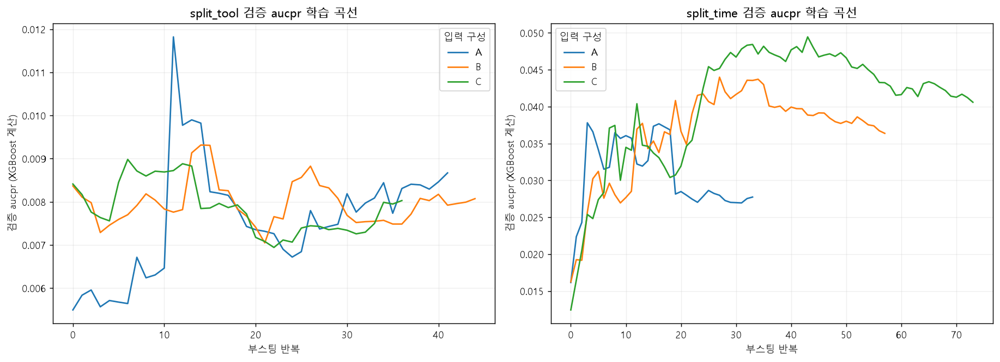

출처: `PHM2018-Project/outputs/stage4/figures/xgboost_learning_curves.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-113"></a>

**cv comparison**

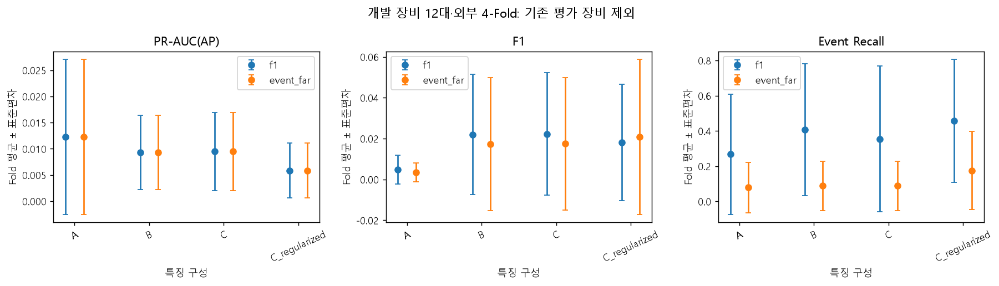

출처: `PHM2018-Project/outputs/stage4_5/figures/cv_comparison.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-114"></a>

**hardware**

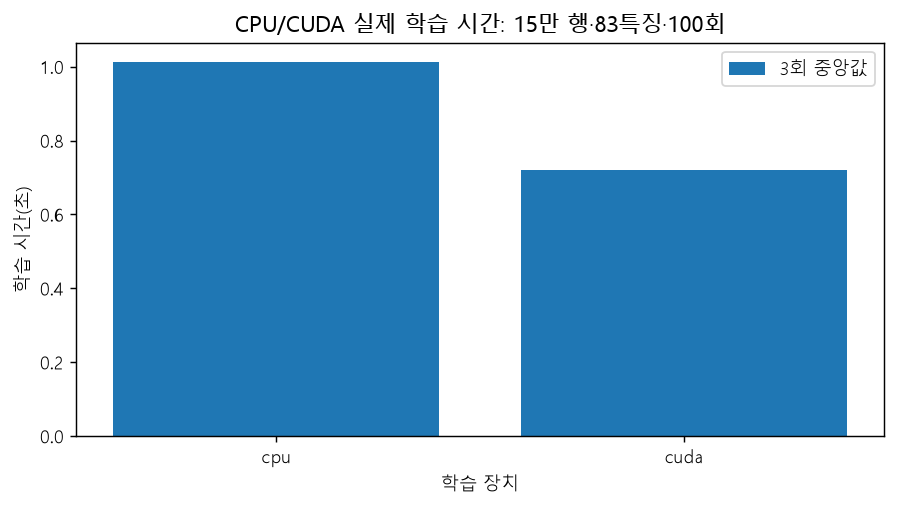

출처: `PHM2018-Project/outputs/stage4_5/figures/hardware.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-115"></a>

**na reasons**

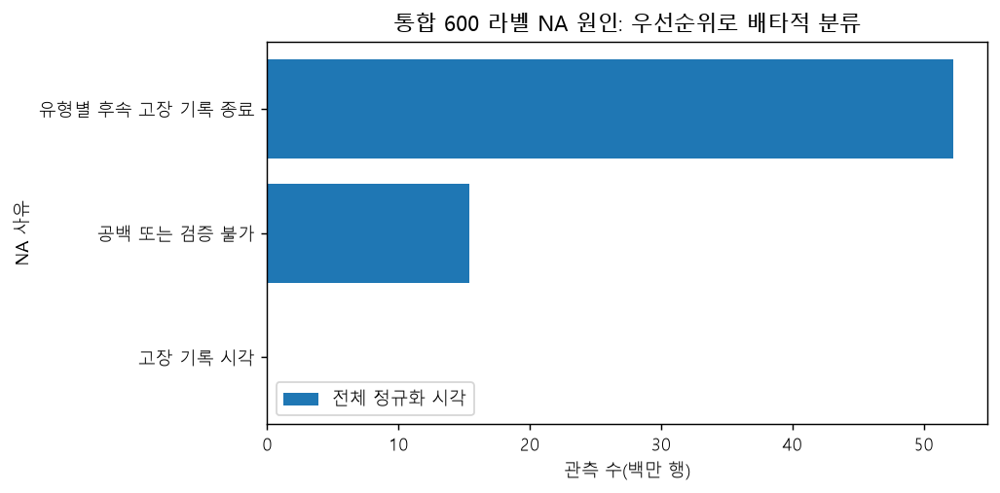

출처: `PHM2018-Project/outputs/stage4_5/figures/na_reasons.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-116"></a>

**na tools**

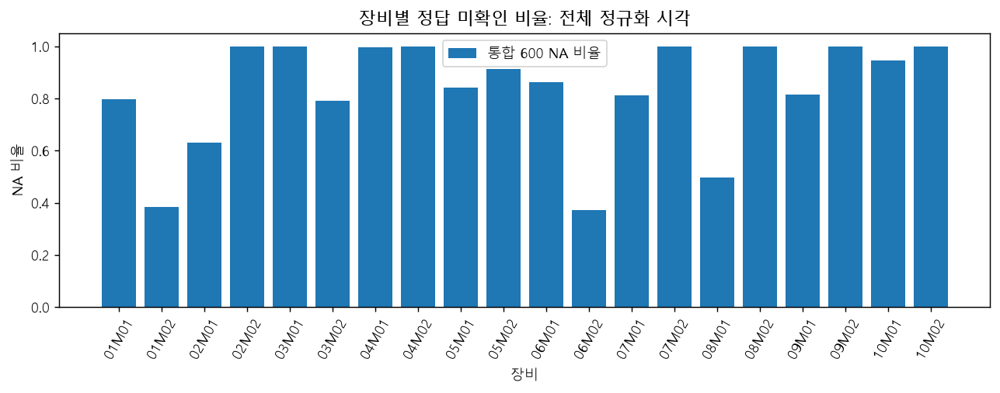

출처: `PHM2018-Project/outputs/stage4_5/figures/na_tools.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-117"></a>

**old fault scores**

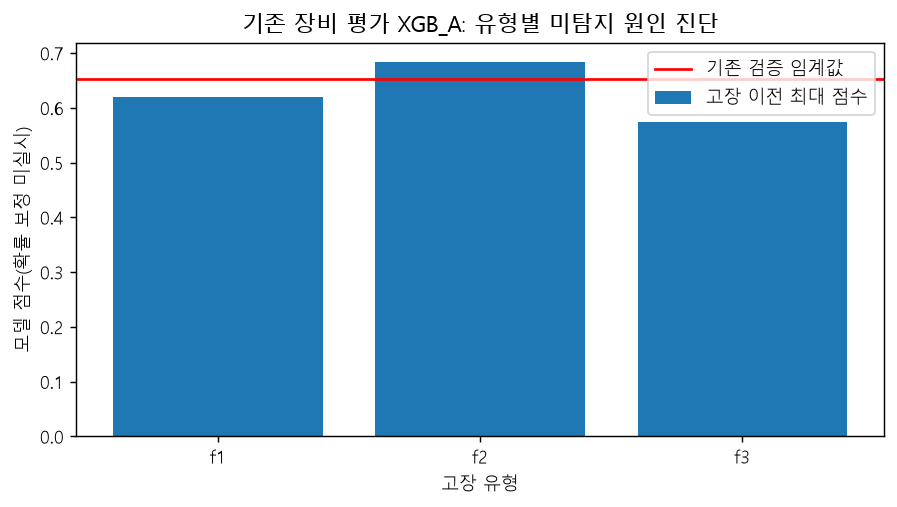

출처: `PHM2018-Project/outputs/stage4_5/figures/old_fault_scores.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-118"></a>

**thresholds**

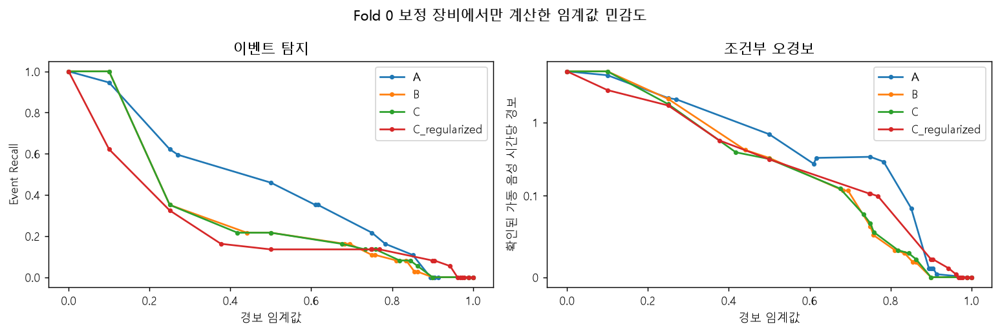

출처: `PHM2018-Project/outputs/stage4_5/figures/thresholds.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-119"></a>

**tool shift**

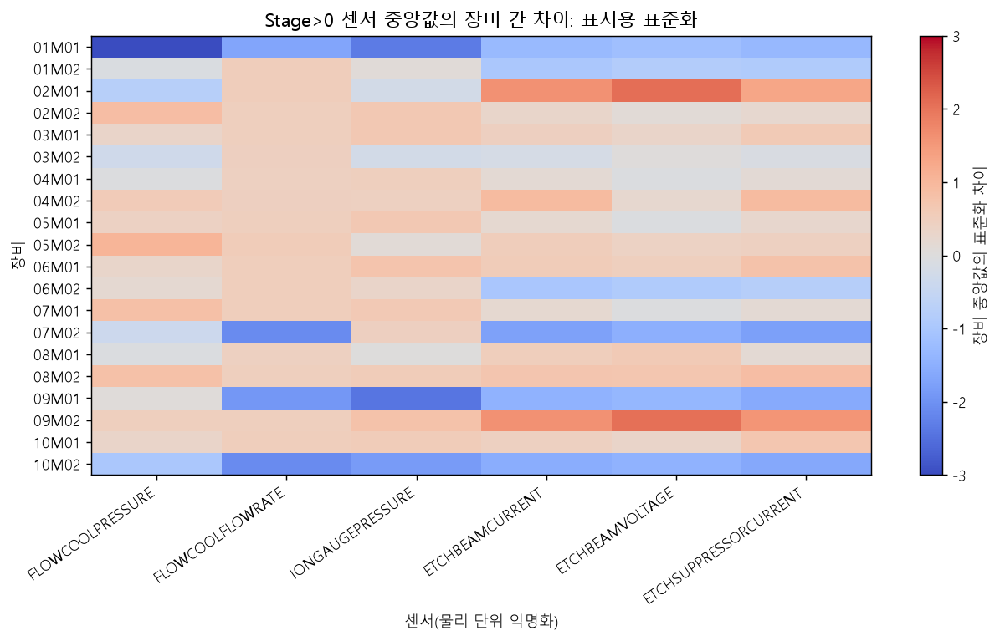

출처: `PHM2018-Project/outputs/stage4_5/figures/tool_shift.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="section-3"></a>

## 3. V2 원본 재감사·대표2대 전처리 진단

20대 원본을 감사하고01M01/03M02 두 장비만 진단 Parquet로 만들었습니다. 승인된 학습 자료는0행, 모델 학습0회이며 단위·이력 유효범위·정비 종료 미확정으로 전체 확정 데이터 생성을 차단했습니다. 블록 처리로 메모리 문제를 개선하고 진단 자료 재생성의 동일 SHA256을 확인한 기록이 있습니다.

In [4]:
display(J('PHM2018-Project-V2/outputs/release_status.json'))
display(J('PHM2018-Project-V2/outputs/reproducibility.json'))
display(J('PHM2018-Project-V2/outputs/notebook_validation.json'))
show_frame(pd.DataFrame([['01M01',3124704,662570,19,13,2],['03M02',5060498,679083,356,111,52]],columns=['장비','원본 행','격자 Anchor','고유 이벤트','센서 가용 격자 이벤트','900이력 양성 격자 이벤트']))

{'status': 'BLOCKED',
 'approved_training_rows': 0,
 'blockers': ['물리 초 단위/변환 미검증; 현재 창은 원시시간 단위 진단용',
  'Fault 이력의 유효 범위와 TTF Null 검열 한계 미확정',
  '고장 후 정비 종료 시각/구간 미확정',
  '정식 단위 변환·정비 구간 검증 및 20대 배포 경로 미승인']}

{'01M01': {'before_sha256': 'dee101094ea8990698e5ce69560ba0da1f98e13db73f3d4e73e1d17fc4a7babd',
  'after_sha256': 'dee101094ea8990698e5ce69560ba0da1f98e13db73f3d4e73e1d17fc4a7babd',
  'identical': True},
 '03M02': {'before_sha256': '74b078341ae9b58ab0ee8a0ae2924018f817dce2dc7dc4cbeeb278d3940561b8',
  'after_sha256': '74b078341ae9b58ab0ee8a0ae2924018f817dce2dc7dc4cbeeb278d3940561b8',
  'identical': True}}

[{'notebook': 'notebooks\\01_raw_data_validation.ipynb',
  'errors': 0,
  'executed_code_cells': 2},
 {'notebook': 'notebooks\\02_fault_label_generation.ipynb',
  'errors': 0,
  'executed_code_cells': 2},
 {'notebook': 'notebooks\\03_feature_engineering.ipynb',
  'errors': 0,
  'executed_code_cells': 2},
 {'notebook': 'notebooks\\04_dataset_validation.ipynb',
  'errors': 0,
  'executed_code_cells': 2}]

,장비,원본 행,격자 Anchor,고유 이벤트,센서 가용 격자 이벤트,900이력 양성 격자 이벤트
0,01M01,3124704,662570,19,13,2
1,03M02,5060498,679083,356,111,52


<a id="fig-120"></a>

**01 raw rows**

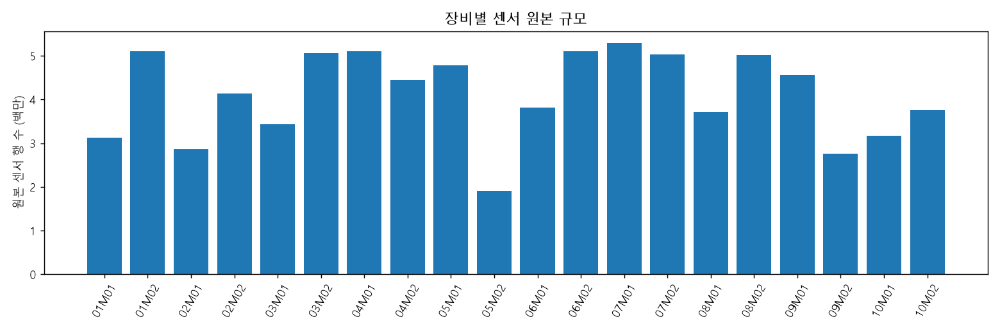

출처: `PHM2018-Project-V2/reports/figures/01_raw_rows.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-121"></a>

**02 seven tools**

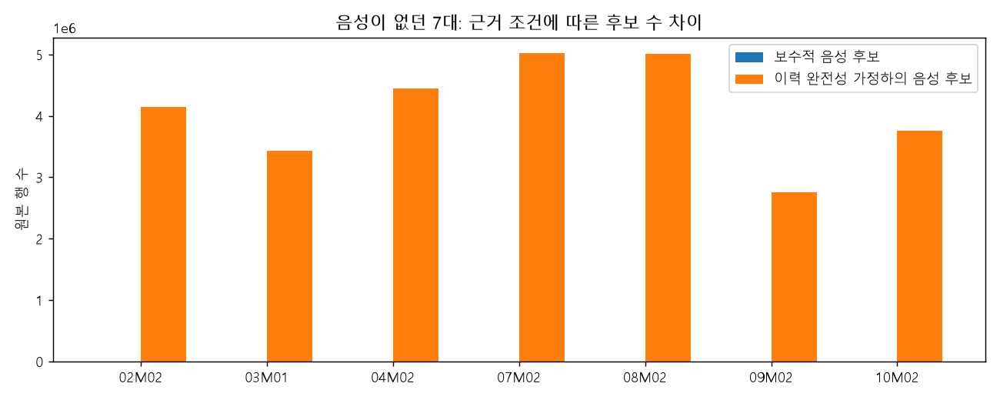

출처: `PHM2018-Project-V2/reports/figures/02_seven_tools.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-122"></a>

**03 features**

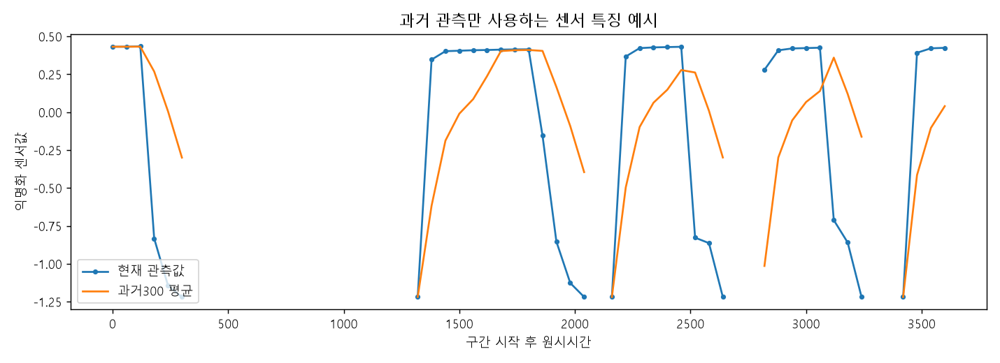

출처: `PHM2018-Project-V2/reports/figures/03_features.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="fig-123"></a>

**04 event preservation**

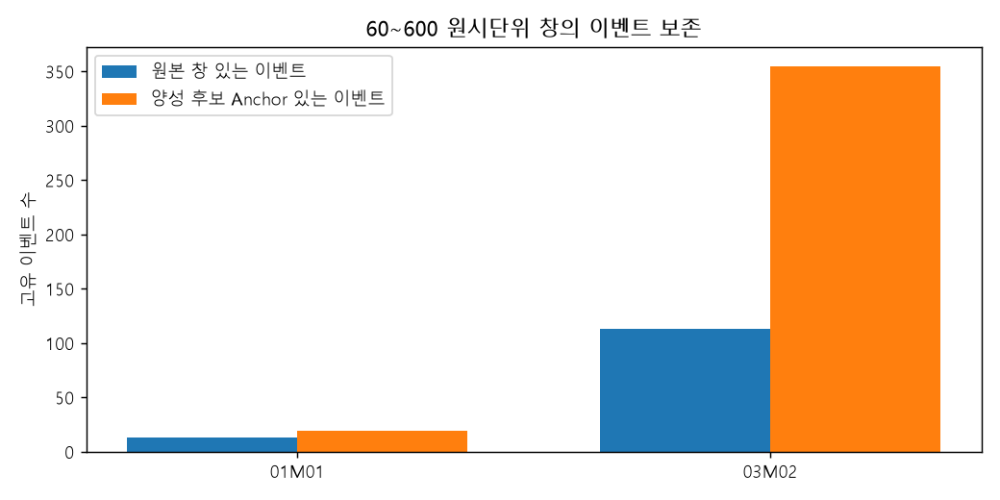

출처: `PHM2018-Project-V2/reports/figures/04_event_preservation.png`

이전 버전 작성 당시의 저장 그림. 현재 V3의 분모·라벨·시간 규약과 직접 합산하지 않음.

<a id="section-4"></a>

## 4. V3 전체20대 원본·관측 타임라인과 품질

같은 시각 센서를 평균 집계해 정규화하고 원본 행 출처를 보존했습니다. dt>12 raw 또는 공정 충돌에서 세그먼트를 끊고 공백을 보간하지 않았습니다. 공정 충돌은 recipe/stage/recipe_step/Lot/runnum의 동일 시각 불일치입니다. 전체 관측 범위와 고정100,000 raw 구간/연속 세그먼트를 함께 진단했습니다.

In [5]:
show('tool_summary',rows=20)
show('gap_summary',rows=20)
show('preprocessing_preservation',rows=12)
show('time_segment_summary',rows=8)

**tool_summary** · 전체 20행 × 23열

,Tool,raw_rows,normalized_rows,time_start,time_end,fault_events,raw_fault_rows,duplicate_rows,duplicate_times,conflict_times,long_gaps,max_gap,anchors,available_A,available_B,available_C,usable_events_C_h600_conservative,fault_low,fault_high,fault_leak,ttf_null_ratio_low,ttf_null_ratio_high,ttf_null_ratio_leak
0,01M01,3124704,3119431,3283106,43037336,19,19,5273,5061,10,12057,794480.0,662570,209780,150827,67945,2,13,5,1,0.022971,0.050736,0.561588
1,01M02,5110542,5103087,3283834,39789840,109,109,7455,7215,30,5779,511624.0,608434,340862,312734,259356,58,53,40,16,0.095101,0.263931,0.095928
2,02M01,2865625,2864055,3283718,32494970,17,17,1570,1524,3,10530,505844.0,486854,192644,140309,76842,4,9,7,1,0.082302,0.054120,0.265636
3,02M02,4143973,4141715,3283198,36485084,32,33,2258,2104,6,20056,361122.0,553365,279266,179506,35161,3,5,27,0,0.632818,0.009922,1.000000
4,03M01,3432217,3431191,3286668,41658086,91,93,1026,943,2,15474,347956.0,639524,231362,154157,49643,10,40,51,0,0.170058,0.049465,1.000000
5,03M02,5060498,5059330,3284714,44029722,356,361,1168,1063,8,23542,358128.0,679083,341336,223853,59515,52,298,49,9,0.189091,0.001314,0.369989
6,04M01,5097901,5096263,3283122,43627882,9,9,1638,1566,19,24832,339488.0,672413,343739,219622,46446,2,7,1,1,0.318064,0.989444,0.887332
7,04M02,4450348,4449140,3997500,42499202,37,37,1208,1159,4,4981,427854.0,641696,297447,272812,225234,24,21,1,15,0.020220,1.000000,0.051082
8,05M01,4779554,4759318,3280856,42635582,28,28,20236,20091,179,24748,346278.0,655913,320244,197495,36005,3,14,7,7,0.389696,0.167173,0.138879
9,05M02,1907102,1897629,3286308,43254162,27,28,9473,9416,88,11219,630426.0,666131,127912,72481,10954,1,5,17,5,0.343621,0.070229,0.618795


**gap_summary** · 전체 20행 × 6열

,Tool,gaps_above_4,p50,p90,p99,max
0,01M01,42075,6.0,124.0,14116.0,794480.0
1,01M02,39043,6.0,112.0,6688.0,511624.0
2,02M01,45358,6.0,192.0,9096.0,505844.0
3,02M02,65296,6.0,188.0,4572.0,361122.0
4,03M01,33325,6.0,676.0,15358.0,347956.0
5,03M02,47557,6.0,264.0,8144.0,358128.0
6,04M01,43687,124.0,144.0,8860.0,339488.0
7,04M02,24009,6.0,100.0,23350.0,427854.0
8,05M01,76743,6.0,152.0,4652.0,346278.0
9,05M02,34829,6.0,540.0,20696.0,630426.0


**preprocessing_preservation** · 전체 4,320행 × 18열 · 앞 12행 표시, 전체 값은 `T('preprocessing_preservation')`로 조회

,Tool,policy,H,feature_set,stage_order,stage,unit,input_rows,input_unit,output_rows,excluded_rows,exclusion_reason,denominator_changed,source_events,events_with_sensor,events_with_eligible_history,positive_anchor_events,note
0,01M01,conservative,300,A,0,원본 Sensor,원본 행,3124704,원본 행,3124704,NaN,원본 입력,True,19,13,13,NaN,단위 변경 단계는 행 제외율을 계산하지 않음; A/B/C 독립 분기
1,01M01,conservative,300,A,1,시간 정규화,고유 시각,3124704,원본 행,3119431,NaN,동시각 평균으로 단위 변경; 원본 별도 보존,True,19,13,13,NaN,단위 변경 단계는 행 제외율을 계산하지 않음; A/B/C 독립 분기
2,01M01,conservative,300,A,2,중복·충돌 처리,고유 시각,3119431,고유 시각,3119421,10.0,동일 시각 공정 충돌을 입력 후보에서 제외; 원본 보존,False,19,13,13,NaN,단위 변경 단계는 행 제외율을 계산하지 않음; A/B/C 독립 분기
3,01M01,conservative,300,A,3,Anchor 생성,Anchor,3119421,고유 시각,662570,NaN,60 raw 격자로 단위 변경; 공백 Anchor 보존,True,19,13,13,NaN,단위 변경 단계는 행 제외율을 계산하지 않음; A/B/C 독립 분기
4,01M01,conservative,300,A,4,현재 센서 가용성,Anchor,662570,Anchor,209780,452790.0,관측 없음/12 raw 초과/공정 충돌/센서 비유한,False,19,13,13,NaN,단위 변경 단계는 행 제외율을 계산하지 않음; A/B/C 독립 분기
5,01M01,conservative,300,A,5,라벨 상태 검사,Anchor,209780,Anchor,91947,117833.0,선택 정책/H에서 NA 또는 EXCLUDE,False,19,13,13,13.0,단위 변경 단계는 행 제외율을 계산하지 않음; A/B/C 독립 분기
6,01M01,conservative,300,A,6,연구용 후보,Anchor,91947,Anchor,91947,0.0,추가 제외 없음; 운영용 확정 정답 아님,False,19,13,13,13.0,단위 변경 단계는 행 제외율을 계산하지 않음; A/B/C 독립 분기
7,01M01,conservative,300,B,0,원본 Sensor,원본 행,3124704,원본 행,3124704,NaN,원본 입력,True,19,13,13,NaN,단위 변경 단계는 행 제외율을 계산하지 않음; A/B/C 독립 분기
8,01M01,conservative,300,B,1,시간 정규화,고유 시각,3124704,원본 행,3119431,NaN,동시각 평균으로 단위 변경; 원본 별도 보존,True,19,13,13,NaN,단위 변경 단계는 행 제외율을 계산하지 않음; A/B/C 독립 분기
9,01M01,conservative,300,B,2,중복·충돌 처리,고유 시각,3119431,고유 시각,3119421,10.0,동일 시각 공정 충돌을 입력 후보에서 제외; 원본 보존,False,19,13,13,NaN,단위 변경 단계는 행 제외율을 계산하지 않음; A/B/C 독립 분기


**time_segment_summary** · 전체 343,337행 × 21열 · 앞 8행 표시, 전체 값은 `T('time_segment_summary')`로 조회

,start,end,sensor_observations,raw_rows,max_gap,process_changes,conflicts,null_low,null_high,null_leak,Tool,kind,segment_id,ttf_null_ratio_low,ttf_null_ratio_high,ttf_null_ratio_leak,density,fault_count,fault_near,has_gap,states
0,3283106,3299999,1579,1579,2188.0,45,0,0,0,0,01M01,fixed,-1,0.0,0.0,0.0,0.373794,0,False,True,OBSERVED|SPARSE|GAP
1,3300000,3399999,8919,8919,10976.0,321,0,0,0,0,01M01,fixed,-1,0.0,0.0,0.0,0.356749,0,False,True,OBSERVED|SPARSE|GAP
2,3400000,3499999,9463,9463,16476.0,153,0,0,0,0,01M01,fixed,-1,0.0,0.0,0.0,0.378509,0,False,True,OBSERVED|SPARSE|GAP
3,3500000,3599999,5133,5133,29760.0,134,0,0,0,0,01M01,fixed,-1,0.0,0.0,0.0,0.205314,0,False,True,OBSERVED|SPARSE|GAP
4,3600000,3699999,6371,6371,27864.0,151,0,0,0,0,01M01,fixed,-1,0.0,0.0,0.0,0.254832,0,False,True,OBSERVED|SPARSE|GAP
5,3700000,3799999,3087,3087,50924.0,99,0,0,0,0,01M01,fixed,-1,0.0,0.0,0.0,0.123476,0,False,True,OBSERVED|SPARSE|GAP
6,3800000,3899999,7823,7824,19124.0,252,0,0,0,0,01M01,fixed,-1,0.0,0.0,0.0,0.312911,0,False,True,OBSERVED|SPARSE|GAP
7,3900000,3999999,8064,8069,14076.0,216,0,0,0,0,01M01,fixed,-1,0.0,0.0,0.0,0.322550,0,False,True,OBSERVED|SPARSE|GAP


<a id="fig-001"></a>

**장비별 원본 데이터 규모**

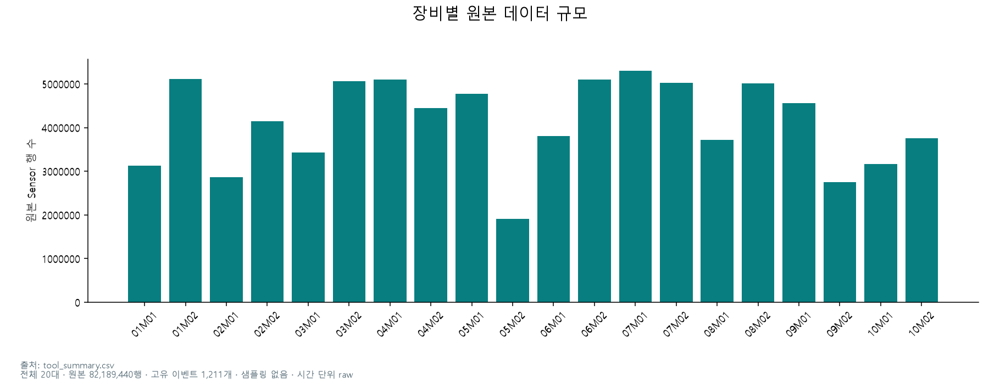

출처: `PHM2018-Project-V3/outputs/figures/tool_overview/raw_rows.png`

전체 20대 · 원본 82,189,440행 · 고유 이벤트 1,211개 · 샘플링 없음 · 시간 단위 raw

<a id="fig-002"></a>

**장비별 고장 유형 분포**

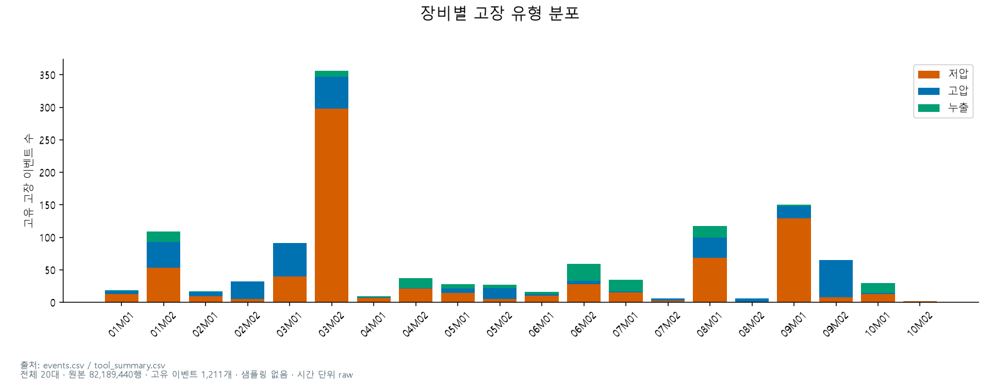

출처: `PHM2018-Project-V3/outputs/figures/tool_overview/fault_types.png`

전체 20대 · 원본 82,189,440행 · 고유 이벤트 1,211개 · 샘플링 없음 · 시간 단위 raw

<a id="fig-003"></a>

**장비·고장 유형별 TTF Null**

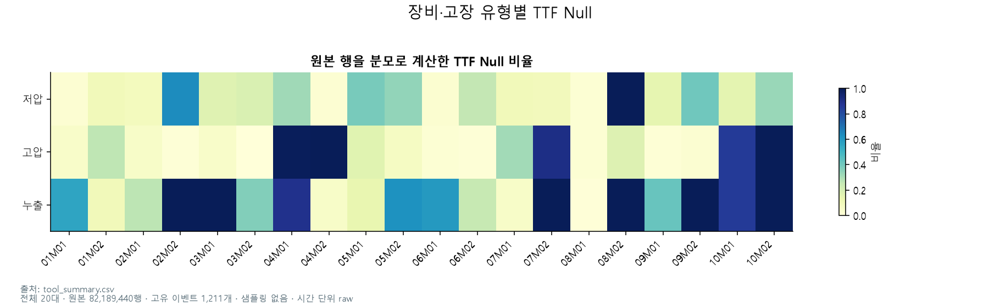

출처: `PHM2018-Project-V3/outputs/figures/tool_overview/ttf_null.png`

전체 20대 · 원본 82,189,440행 · 고유 이벤트 1,211개 · 샘플링 없음 · 시간 단위 raw

<a id="fig-004"></a>

**전체 장비 관측·공백·고장 타임라인**

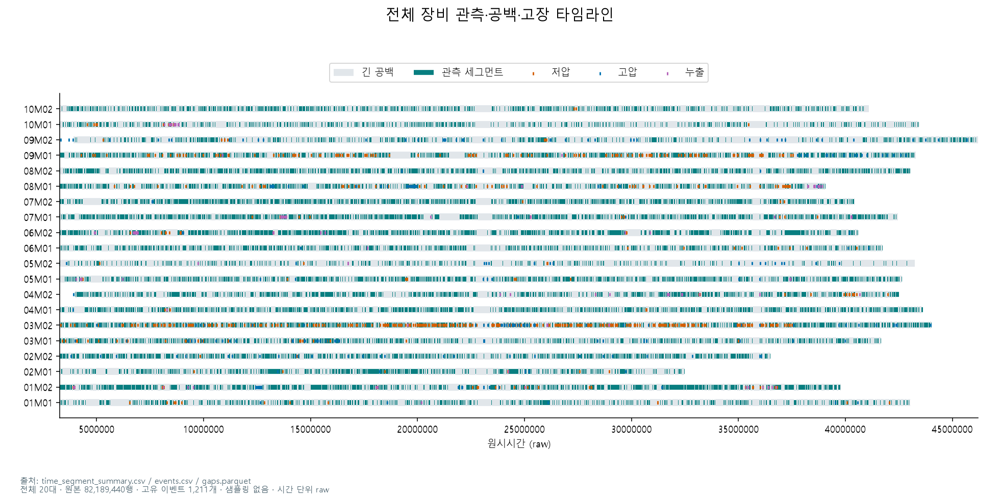

출처: `PHM2018-Project-V3/outputs/figures/timeline/all_tools.png`

전체 20대 · 원본 82,189,440행 · 고유 이벤트 1,211개 · 샘플링 없음 · 시간 단위 raw

<a id="fig-005"></a>

**고정 구간별 관측 밀도**

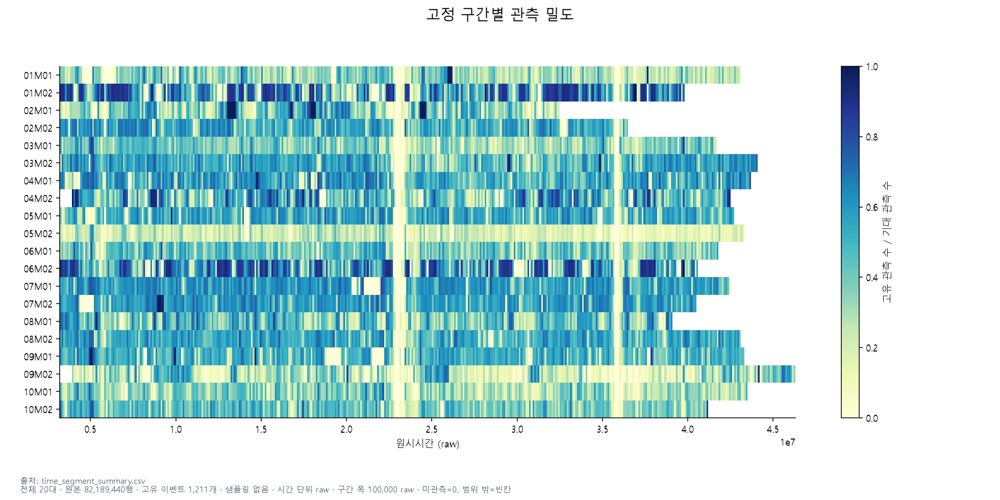

출처: `PHM2018-Project-V3/outputs/figures/timeline/density.png`

전체 20대 · 원본 82,189,440행 · 고유 이벤트 1,211개 · 샘플링 없음 · 시간 단위 raw · 구간 폭 100,000 raw · 미관측=0, 범위 밖=빈칸

<a id="fig-006"></a>

**장비별 공백 길이 Histogram과 누적분포**

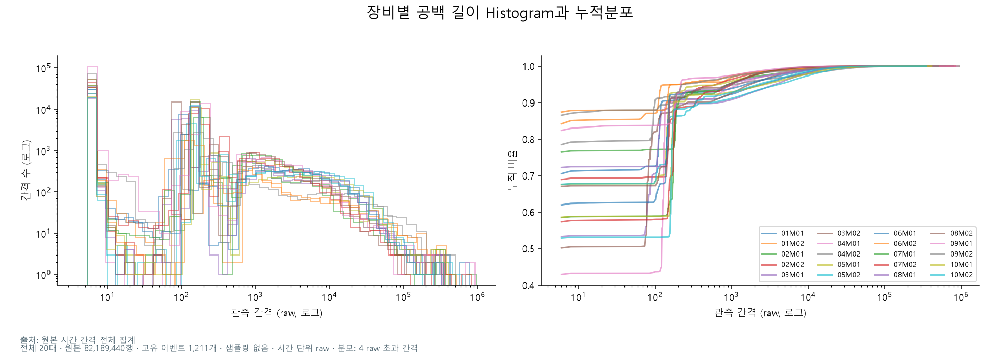

출처: `PHM2018-Project-V3/outputs/figures/timeline/gap_distribution.png`

전체 20대 · 원본 82,189,440행 · 고유 이벤트 1,211개 · 샘플링 없음 · 시간 단위 raw · 분모: 4 raw 초과 간격

<a id="fig-007"></a>

**중복과 공정 충돌 발생 위치**

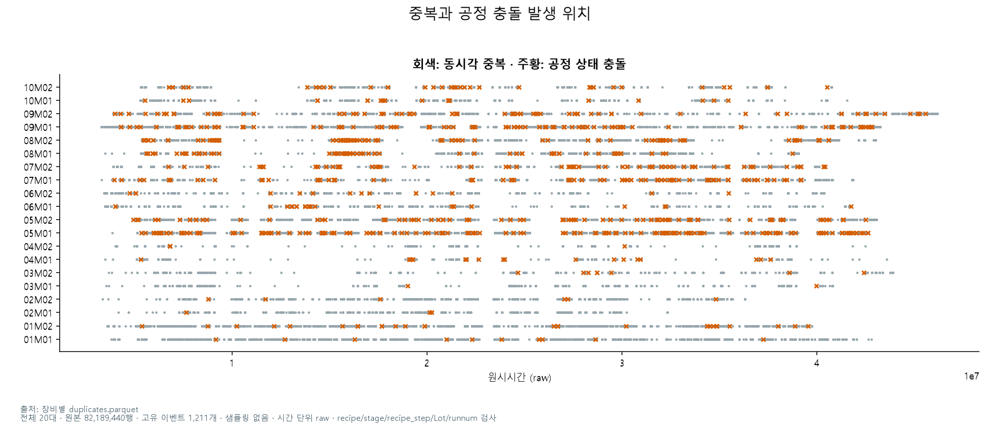

출처: `PHM2018-Project-V3/outputs/figures/timeline/duplicates_conflicts.png`

전체 20대 · 원본 82,189,440행 · 고유 이벤트 1,211개 · 샘플링 없음 · 시간 단위 raw · recipe/stage/recipe_step/Lot/runnum 검사

<a id="section-5"></a>

## 5. 라벨 정책·TTF Null·예측 창

H=300/600/1800 raw, 최소 선행 L=60입니다. d=60은 양성,0≤d<60은 임박 EXCLUDE를 최우선 적용합니다. 보수적/제한 연구용/완전 이력 가정의 세 정책을 비교했으며 기본 학습은 보수적 통합 라벨입니다. TTF Null을 정상으로 바꾸지 않습니다. [NoWaferID] 포함/제외로 다음 고장이 바뀌는 시점은 NA로 격리합니다. 고장 정지 기록은 이상 시작이나 정비 종료를 뜻하지 않습니다.

In [6]:
labels=T('label_status_summary')
z=labels[labels.sample_level.eq('anchor')&labels.fault_type.eq('any')].groupby(['policy','H'])[['positive','negative','NA','excluded','denominator']].sum()
show_frame(z.reset_index())
show('ttf_label_relationship',rows=20)

,policy,H,positive,negative,NA,excluded,denominator
0,conservative,300,4835,4345702,8378962,1205,12730704
1,conservative,600,10781,4342390,8376328,1205,12730704
2,conservative,1800,33311,4329874,8366314,1205,12730704
3,research,300,4835,6179878,6544786,1205,12730704
4,research,600,10781,5443690,7275028,1205,12730704
5,research,1800,33311,4748068,7948120,1205,12730704
6,sensitivity,300,4835,12723961,703,1205,12730704
7,sensitivity,600,10781,12717915,803,1205,12730704
8,sensitivity,1800,33311,12694985,1203,1205,12730704


**ttf_label_relationship** · 전체 480행 × 5열 · 앞 20행 표시, 전체 값은 `T('ttf_label_relationship')`로 조회

,Tool,fault_type,status,TTF_null,anchors
0,01M01,low,0,False,646089
1,01M01,low,0,True,0
2,01M01,low,1,False,117
3,01M01,low,1,True,0
4,01M01,low,2,False,0
5,01M01,low,2,True,16345
6,01M01,low,3,False,19
7,01M01,low,3,True,0
8,01M01,high,0,False,621336
9,01M01,high,0,True,0


<a id="fig-008"></a>

**H=600 · 보수적 통합 라벨**

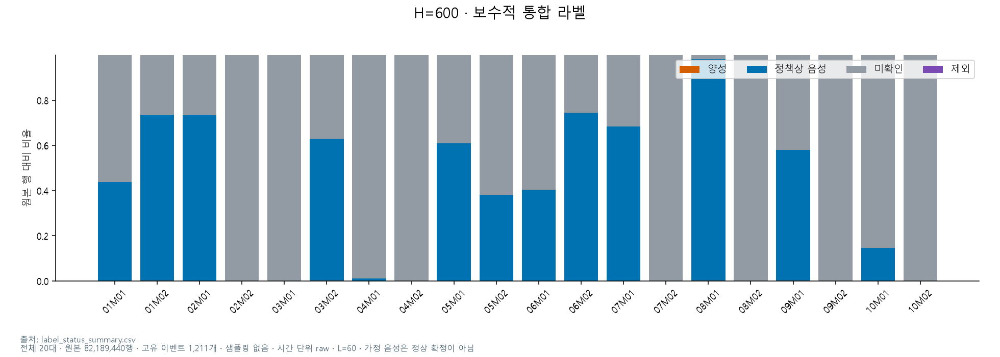

출처: `PHM2018-Project-V3/outputs/figures/label_analysis/conservative.png`

전체 20대 · 원본 82,189,440행 · 고유 이벤트 1,211개 · 샘플링 없음 · 시간 단위 raw · L=60 · 가정 음성은 정상 확정이 아님

<a id="fig-009"></a>

**H=600 · 제한 연구용 통합 라벨**

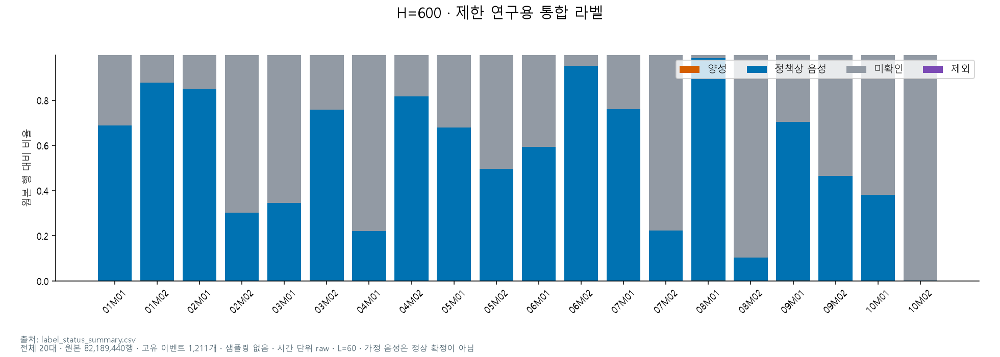

출처: `PHM2018-Project-V3/outputs/figures/label_analysis/research.png`

전체 20대 · 원본 82,189,440행 · 고유 이벤트 1,211개 · 샘플링 없음 · 시간 단위 raw · L=60 · 가정 음성은 정상 확정이 아님

<a id="fig-010"></a>

**H=600 · 완전 이력 가정 통합 라벨**

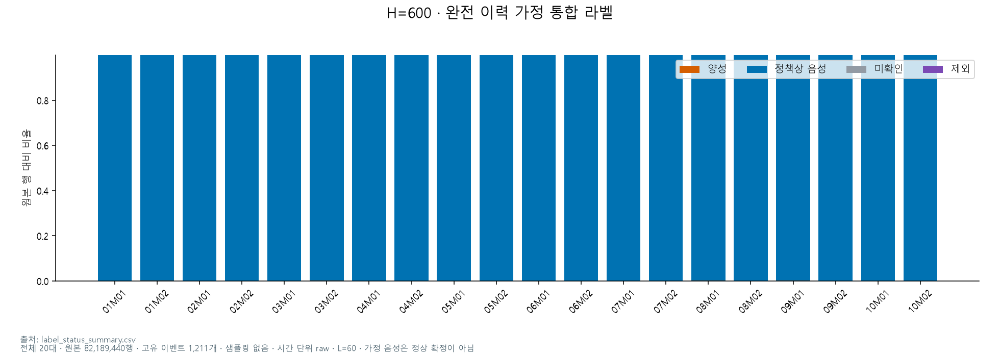

출처: `PHM2018-Project-V3/outputs/figures/label_analysis/sensitivity.png`

전체 20대 · 원본 82,189,440행 · 고유 이벤트 1,211개 · 샘플링 없음 · 시간 단위 raw · L=60 · 가정 음성은 정상 확정이 아님

<a id="fig-011"></a>

**H와 정책에 따른 통합 라벨 변화**

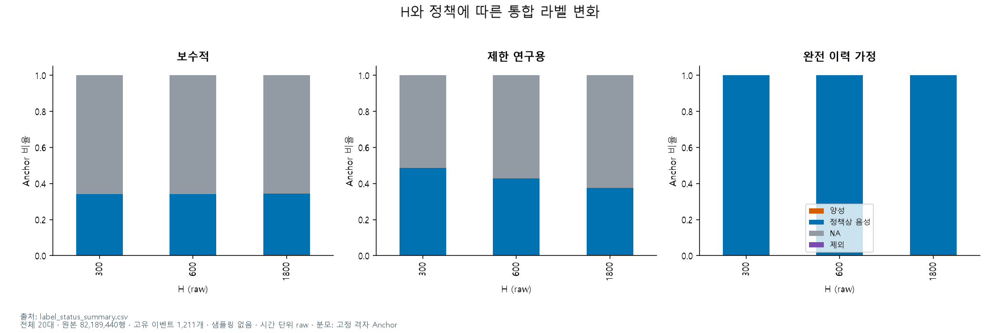

출처: `PHM2018-Project-V3/outputs/figures/label_analysis/horizon_policies.png`

전체 20대 · 원본 82,189,440행 · 고유 이벤트 1,211개 · 샘플링 없음 · 시간 단위 raw · 분모: 고정 격자 Anchor

<a id="fig-012"></a>

**고장 유형별 보수적 라벨 상태**

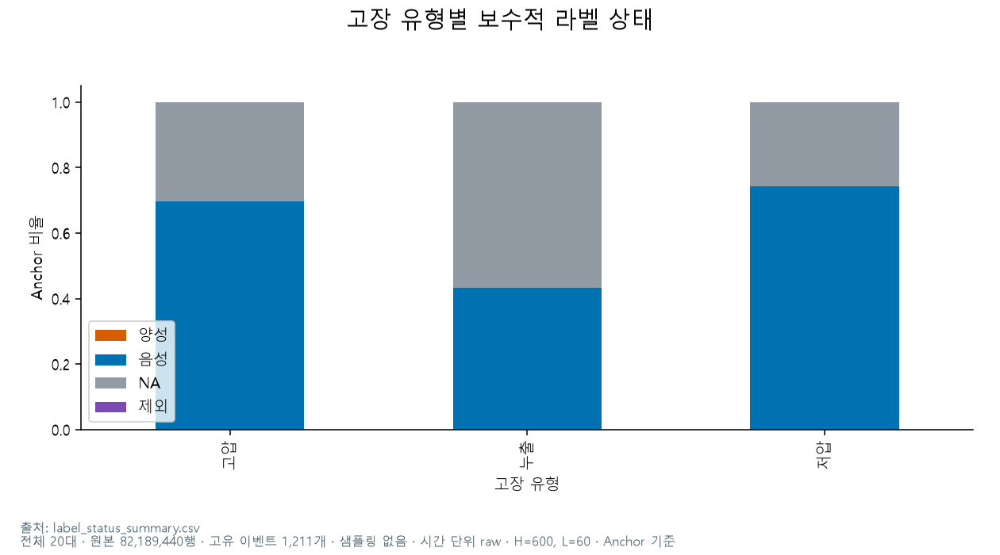

출처: `PHM2018-Project-V3/outputs/figures/label_analysis/fault_types.png`

전체 20대 · 원본 82,189,440행 · 고유 이벤트 1,211개 · 샘플링 없음 · 시간 단위 raw · H=600, L=60 · Anchor 기준

<a id="fig-013"></a>

**TTF Null과 라벨 NA는 같은 개념이 아니다**

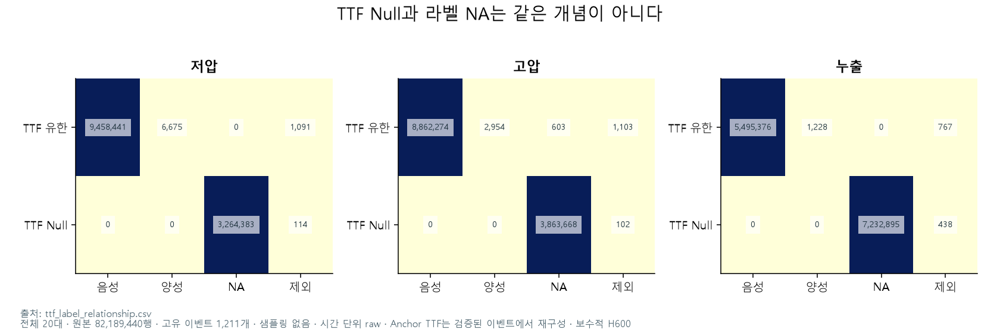

출처: `PHM2018-Project-V3/outputs/figures/label_analysis/ttf_null_relation.png`

전체 20대 · 원본 82,189,440행 · 고유 이벤트 1,211개 · 샘플링 없음 · 시간 단위 raw · Anchor TTF는 검증된 이벤트에서 재구성 · 보수적 H600

<a id="section-6"></a>

## 6. A/B/C 특징 가용성·고장 보존·대표 사례

A8=현재 센서6+recipe/stage, B32=A+과거300 raw 평균/표준편차/최소/최대, C44=B+과거900 raw 기울기/변화량입니다. 특징 창은(t−w,t]이며 같은 세그먼트의90% 이상 관측을 요구합니다. 격자60 raw, 최근 현재값 지연은12 raw 이내입니다. 과거 이력을 늘리면 가용 입력과 고장이 줄어듭니다. 정답 존재와 입력 가용성을 구분하고 입력 없는 고장도 기록 분모에 남겼습니다. 아래에는12개 대표 사례와 상대시간 분석의 기존 그림을 모두 포함했습니다.

In [7]:
f=T('feature_availability_summary');z=f[f.policy.eq('conservative')&f.H.eq(600)&f.fault_type.eq('any')].groupby(['cohort','feature_set'])[['available_anchors','positive_anchors','negative_anchors','NA_anchors','positive_events']].sum().reset_index();show_frame(z)
show('feature_unavailability_reasons')
show('case_catalog',rows=20)
show('case_sensor_changes',rows=12)
show('event_exclusion_reasons',rows=12)

,cohort,feature_set,available_anchors,positive_anchors,negative_anchors,NA_anchors,positive_events
0,common,A,1573310,2093,701466,869527,296
1,common,B,1573310,2093,701466,869527,296
2,common,C,1573310,2093,701466,869527,296
3,maximum,A,5522297,3868,2001307,3516720,503
4,maximum,B,3863970,3243,1454120,2406274,488
5,maximum,C,1573310,2093,701466,869527,296


**feature_unavailability_reasons** · 전체 80행 × 9열 · 앞 30행 표시, 전체 값은 `T('feature_unavailability_reasons')`로 조회

,Tool,feature_set,current_gap,history_gap,initial_history,sensor_or_conflict,other_history,available,total
0,01M01,A,452789,0,0,1,0,209780,662570
1,01M01,B,452789,58950,3,1,0,150827,662570
2,01M01,C,452789,141832,3,1,0,67945,662570
3,01M01,common,452789,141832,3,1,0,67945,662570
4,01M02,A,267571,0,0,1,0,340862,608434
5,01M02,B,267571,28123,5,1,0,312734,608434
6,01M02,C,267571,81491,15,1,0,259356,608434
7,01M02,common,267571,81491,15,1,0,259356,608434
8,02M01,A,294210,0,0,0,0,192644,486854
9,02M01,B,294210,52330,5,0,0,140309,486854


**case_catalog** · 전체 12행 × 7열

,case_id,Tool,category,start,end,event_id,description
0,01M01-01,01M01,긴 센서 공백,6424124.0,6426824.0,,"실제 공백 5631444~6425924 raw, 길이 794480 raw. 그림은 공백 끝 주변을 확대."
1,01M01-02,01M01,동일 시각 공정 충돌,9165668.0,9166268.0,,recipe/stage/recipe_step/Lot/runnum 중 하나 이상이 같은 시각에 다름.
2,01M01-03,01M01,고장 직전 센서 존재,14024892.0,14026812.0,01M01-low-a4b195c2ad63,고장 전 300 raw 관측률이 90% 이상인 실제 이벤트.
3,01M01-04,01M01,고장은 있으나 장기 이력 부족,6531384.0,6533304.0,01M01-low-0fe23ade1e15,A 양성 후보는 있으나 C 양성 후보가 없는 실제 이벤트.
4,01M01-05,01M01,공정 전환과 센서 변화,3283838.0,3284738.0,,실제로 관측된 공정 조건 전환. 값의 변화가 고장 전조인지 별도로 구분.
5,01M01-06,01M01,TTF Null 집중,40872386.0,40874186.0,,동일 시각에 2개 이상 유형의 제공 TTF가 Null. 정상이라는 의미는 아님.
6,03M02-07,03M02,긴 센서 공백,23166678.0,23169378.0,,"실제 공백 22810350~23168478 raw, 길이 358128 raw. 그림은 공백 끝 주변을 확대."
7,03M02-08,03M02,동일 시각 공정 충돌,24656838.0,24657438.0,,recipe/stage/recipe_step/Lot/runnum 중 하나 이상이 같은 시각에 다름.
8,03M02-09,03M02,고장 직전 센서 존재,5126278.0,5128198.0,03M02-high-30905f1e029f,고장 전 300 raw 관측률이 90% 이상인 실제 이벤트.
9,03M02-10,03M02,고장은 있으나 장기 이력 부족,5118800.0,5120720.0,03M02-low-d58f88774e8e,A 양성 후보는 있으나 C 양성 후보가 없는 실제 이벤트.


**case_sensor_changes** · 전체 72행 × 18열 · 앞 12행 표시, 전체 값은 `T('case_sensor_changes')`로 조회

,case_id,Tool,event_id,sensor,start,end,observations,first_time,last_time,first_value,last_value,delta,minimum,maximum,std,max_observed_gap,process_conditions,conflict_observations
0,01M01-01,01M01,,FLOWCOOLPRESSURE,6424124.0,6426824.0,200,6425924.0,6426824.0,-1.218926,0.290886,1.509812,-1.218926,0.334466,0.647549,108.0,6,0
1,01M01-01,01M01,,FLOWCOOLFLOWRATE,6424124.0,6426824.0,200,6425924.0,6426824.0,-1.449477,0.684115,2.133591,-1.449477,0.690783,0.995445,108.0,6,0
2,01M01-01,01M01,,IONGAUGEPRESSURE,6424124.0,6426824.0,200,6425924.0,6426824.0,-1.354313,-1.208421,0.145892,-1.355585,1.286582,1.077751,108.0,6,0
3,01M01-01,01M01,,ETCHBEAMCURRENT,6424124.0,6426824.0,200,6425924.0,6426824.0,-1.151369,-1.151301,0.000068,-1.152450,1.084540,1.082316,108.0,6,0
4,01M01-01,01M01,,ETCHBEAMVOLTAGE,6424124.0,6426824.0,200,6425924.0,6426824.0,-1.128402,0.449517,1.577920,-1.128402,1.086624,1.073392,108.0,6,0
5,01M01-01,01M01,,ETCHSUPPRESSORCURRENT,6424124.0,6426824.0,200,6425924.0,6426824.0,-1.145790,-1.131016,0.014774,-1.145790,1.662917,1.325601,108.0,6,0
6,01M01-02,01M01,,FLOWCOOLPRESSURE,9165668.0,9166268.0,147,9165668.0,9166268.0,-1.218926,0.360926,1.579852,-1.218926,0.362554,0.373763,24.0,14,1
7,01M01-02,01M01,,FLOWCOOLFLOWRATE,9165668.0,9166268.0,147,9165668.0,9166268.0,-1.437270,0.683361,2.120631,-1.449477,0.692168,0.509556,24.0,14,1
8,01M01-02,01M01,,IONGAUGEPRESSURE,9165668.0,9166268.0,147,9165668.0,9166268.0,-1.353826,0.474866,1.828692,-1.354339,1.108311,0.599384,24.0,14,1
9,01M01-02,01M01,,ETCHBEAMCURRENT,9165668.0,9166268.0,147,9165668.0,9166268.0,-1.151571,0.068335,1.219906,-1.152315,0.207447,0.427450,24.0,14,1


**event_exclusion_reasons** · 전체 32,697행 × 17열 · 앞 12행 표시, 전체 값은 `T('event_exclusion_reasons')`로 조회

,event_id,Tool,fault_type,fault_time,policy,H,feature_set,warning_anchors,label_positive_anchors,usable_positive_anchors,current_available,history_60,history_300,history_900,imminent_excluded,preserved,reason
0,01M01-low-0fe23ade1e15,01M01,low,6533184.0,conservative,300,A,4,4,2,2,1,0,0,0,True,보존됨
1,01M01-low-0fe23ade1e15,01M01,low,6533184.0,conservative,300,B,4,4,0,2,1,0,0,0,False,300 raw 이력 부족
2,01M01-low-0fe23ade1e15,01M01,low,6533184.0,conservative,300,C,4,4,0,2,1,0,0,0,False,300 raw 이력 부족
3,01M01-low-0fe23ade1e15,01M01,low,6533184.0,conservative,600,A,9,9,2,2,1,0,0,0,True,보존됨
4,01M01-low-0fe23ade1e15,01M01,low,6533184.0,conservative,600,B,9,9,0,2,1,0,0,0,False,300 raw 이력 부족
5,01M01-low-0fe23ade1e15,01M01,low,6533184.0,conservative,600,C,9,9,0,2,1,0,0,0,False,300 raw 이력 부족
6,01M01-low-0fe23ade1e15,01M01,low,6533184.0,conservative,1800,A,29,29,13,13,11,6,0,0,True,보존됨
7,01M01-low-0fe23ade1e15,01M01,low,6533184.0,conservative,1800,B,29,29,6,13,11,6,0,0,True,보존됨
8,01M01-low-0fe23ade1e15,01M01,low,6533184.0,conservative,1800,C,29,29,0,13,11,6,0,0,False,900 raw 이력 부족
9,01M01-low-0fe23ade1e15,01M01,low,6533184.0,research,300,A,4,4,2,2,1,0,0,0,True,보존됨


<a id="fig-014"></a>

**장비별 A/B/C 특징 가용성**

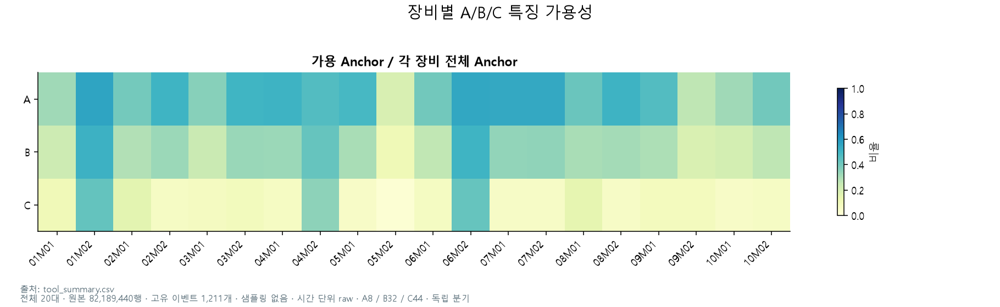

출처: `PHM2018-Project-V3/outputs/figures/feature_availability/tool_heatmap.png`

전체 20대 · 원본 82,189,440행 · 고유 이벤트 1,211개 · 샘플링 없음 · 시간 단위 raw · A8 / B32 / C44 · 독립 분기

<a id="fig-015"></a>

**동일 코호트와 최대 가용 코호트 비교**

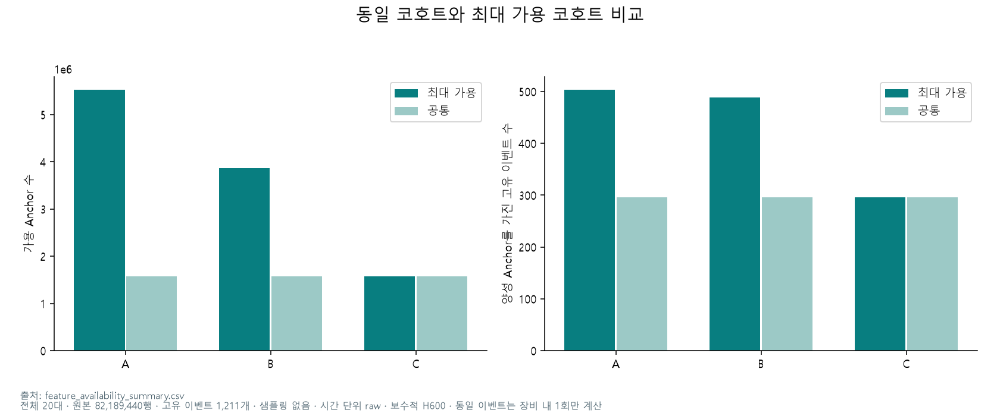

출처: `PHM2018-Project-V3/outputs/figures/feature_availability/cohorts.png`

전체 20대 · 원본 82,189,440행 · 고유 이벤트 1,211개 · 샘플링 없음 · 시간 단위 raw · 보수적 H600 · 동일 이벤트는 장비 내 1회만 계산

<a id="fig-018"></a>

**공정 조건별 특징 가용성 차이**

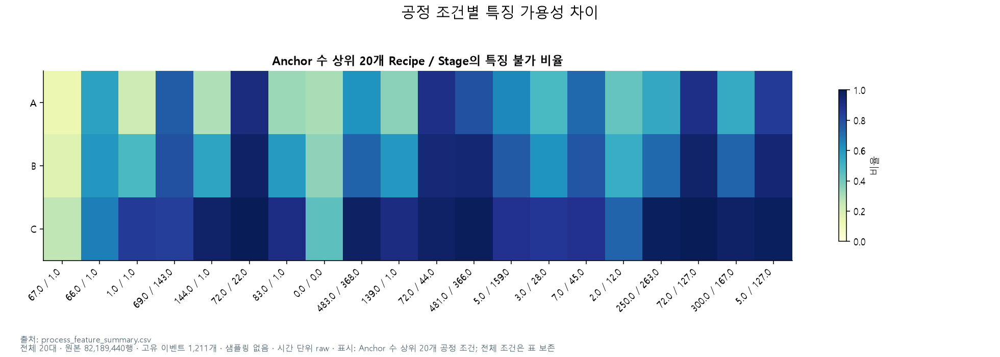

출처: `PHM2018-Project-V3/outputs/figures/feature_availability/process_conditions.png`

전체 20대 · 원본 82,189,440행 · 고유 이벤트 1,211개 · 샘플링 없음 · 시간 단위 raw · 표시: Anchor 수 상위 20개 공정 조건; 전체 조건은 표 보존

<a id="fig-016"></a>

**정책·특징별 고유 이벤트 보존률**

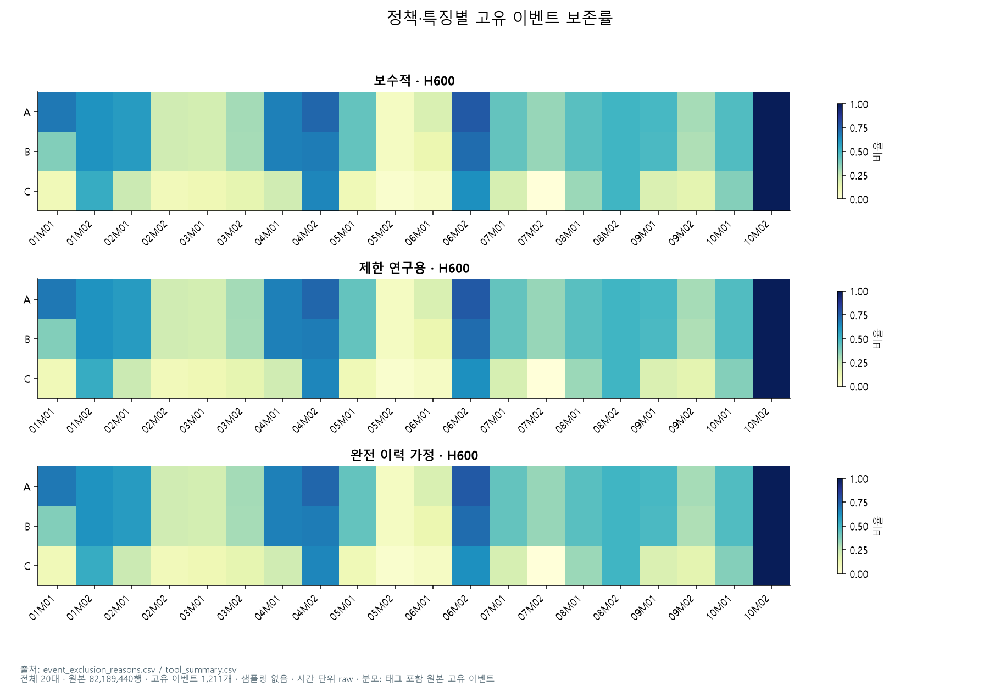

출처: `PHM2018-Project-V3/outputs/figures/event_preservation/tool_policy_heatmap.png`

전체 20대 · 원본 82,189,440행 · 고유 이벤트 1,211개 · 샘플링 없음 · 시간 단위 raw · 분모: 태그 포함 원본 고유 이벤트

<a id="fig-017"></a>

**C 특징에서 이벤트가 제외되는 이유**

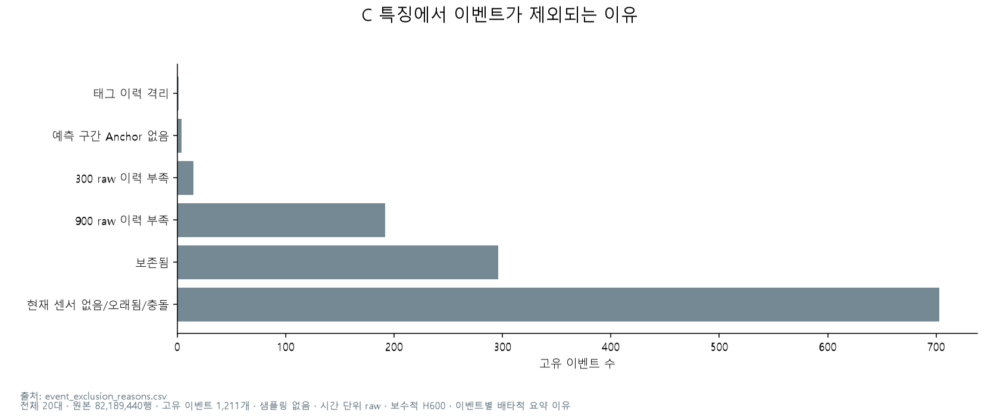

출처: `PHM2018-Project-V3/outputs/figures/event_preservation/exclusion_reasons.png`

전체 20대 · 원본 82,189,440행 · 고유 이벤트 1,211개 · 샘플링 없음 · 시간 단위 raw · 보수적 H600 · 이벤트별 배타적 요약 이유

<a id="fig-019"></a>

**전처리 단계별 행·시각·Anchor 수**

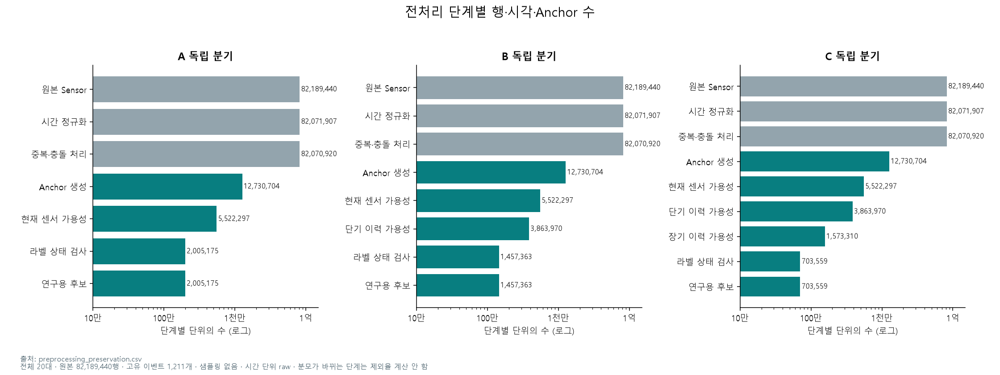

출처: `PHM2018-Project-V3/outputs/figures/event_preservation/stage_rows.png`

전체 20대 · 원본 82,189,440행 · 고유 이벤트 1,211개 · 샘플링 없음 · 시간 단위 raw · 분모가 바뀌는 단계는 제외율 계산 안 함

<a id="fig-020"></a>

**전처리 단계별 고유 이벤트 보존**

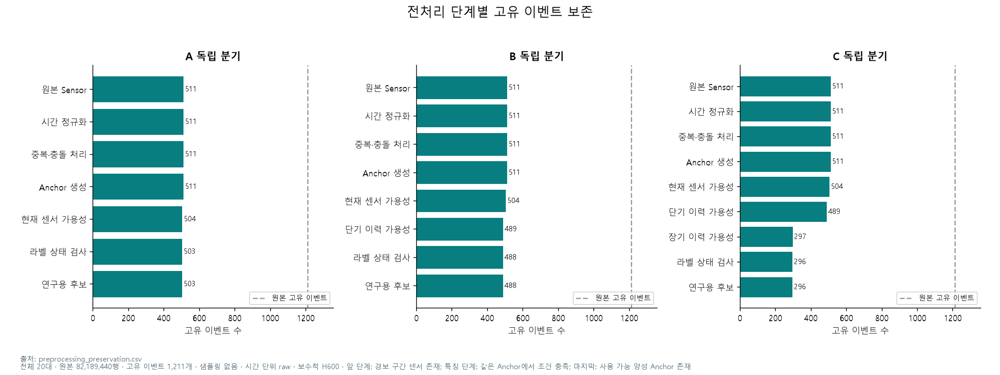

출처: `PHM2018-Project-V3/outputs/figures/event_preservation/stage_events.png`

전체 20대 · 원본 82,189,440행 · 고유 이벤트 1,211개 · 샘플링 없음 · 시간 단위 raw · 보수적 H600 · 앞 단계: 경보 구간 센서 존재; 특징 단계: 같은 Anchor에서 조건 충족; 마지막: 사용 가능 양성 Anchor 존재

<a id="fig-021"></a>

**요구 과거 이력에 따른 이벤트 보존**

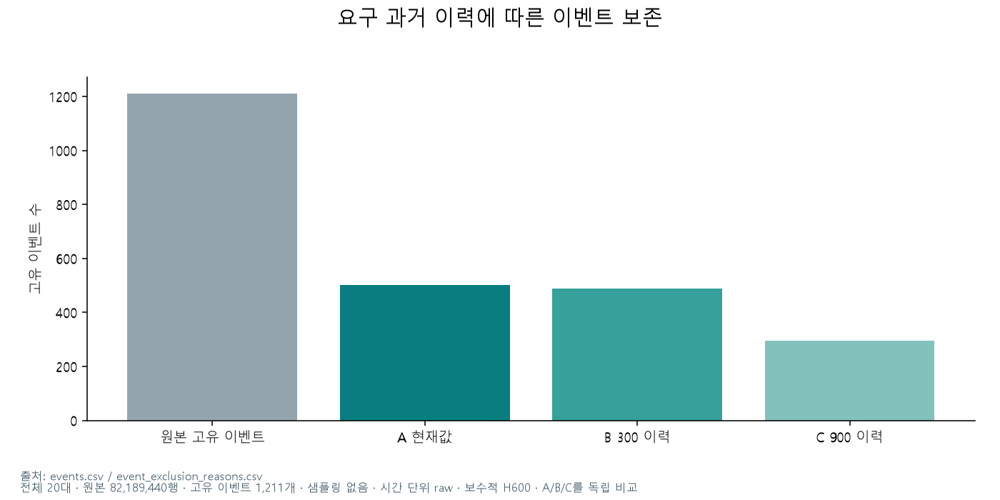

출처: `PHM2018-Project-V3/outputs/figures/event_preservation/history_length.png`

전체 20대 · 원본 82,189,440행 · 고유 이벤트 1,211개 · 샘플링 없음 · 시간 단위 raw · 보수적 H600 · A/B/C를 독립 비교

<a id="fig-022"></a>

**01M01 · 긴 센서 공백**

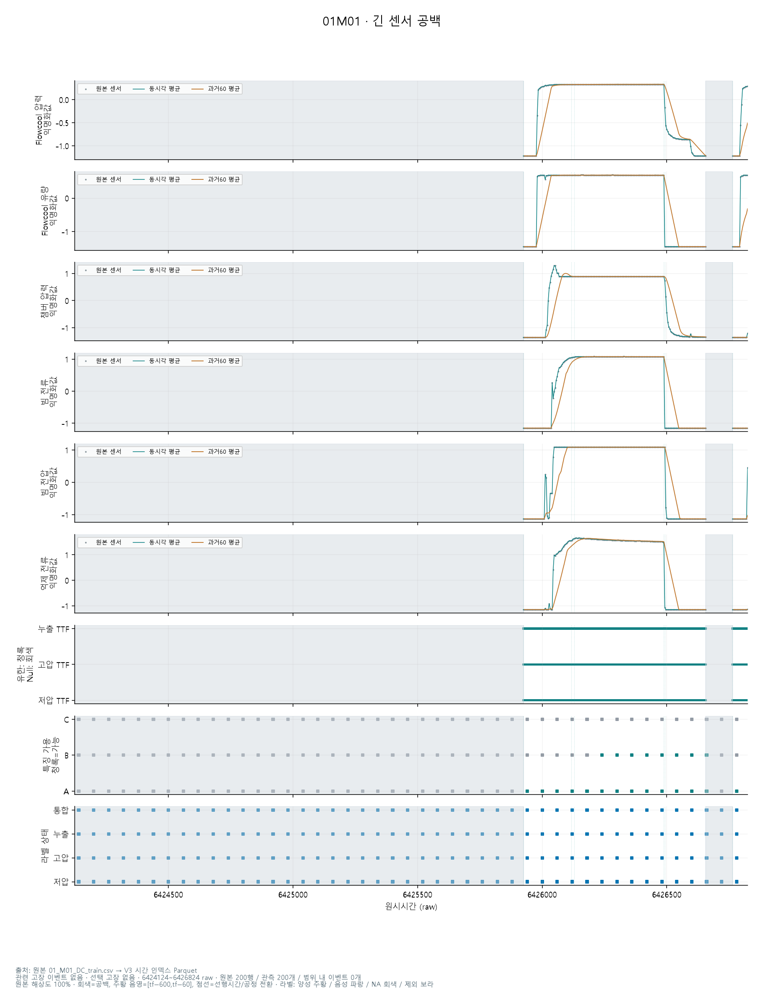

출처: `PHM2018-Project-V3/outputs/figures/fault_events/01M01-01.png`

관련 고장 이벤트 없음 · 선택 고장 없음 · 6424124~6426824 raw · 원본 200행 / 관측 200개 / 범위 내 이벤트 0개
원본 해상도 100% · 회색=공백, 주황 음영=[tf−600,tf−60], 점선=선행시간/공정 전환 · 라벨: 양성 주황 / 음성 파랑 / NA 회색 / 제외 보라

<a id="fig-023"></a>

**01M01 · 동일 시각 공정 충돌**

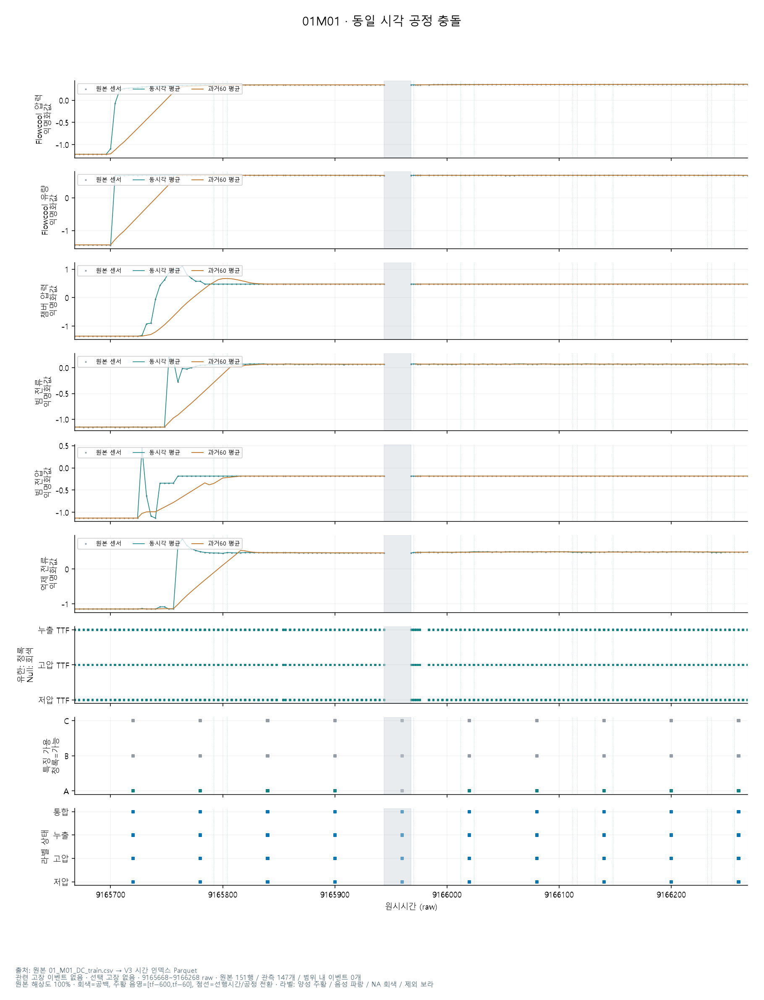

출처: `PHM2018-Project-V3/outputs/figures/fault_events/01M01-02.png`

관련 고장 이벤트 없음 · 선택 고장 없음 · 9165668~9166268 raw · 원본 151행 / 관측 147개 / 범위 내 이벤트 0개
원본 해상도 100% · 회색=공백, 주황 음영=[tf−600,tf−60], 점선=선행시간/공정 전환 · 라벨: 양성 주황 / 음성 파랑 / NA 회색 / 제외 보라

<a id="fig-024"></a>

**01M01 · 고장 직전 센서 존재**

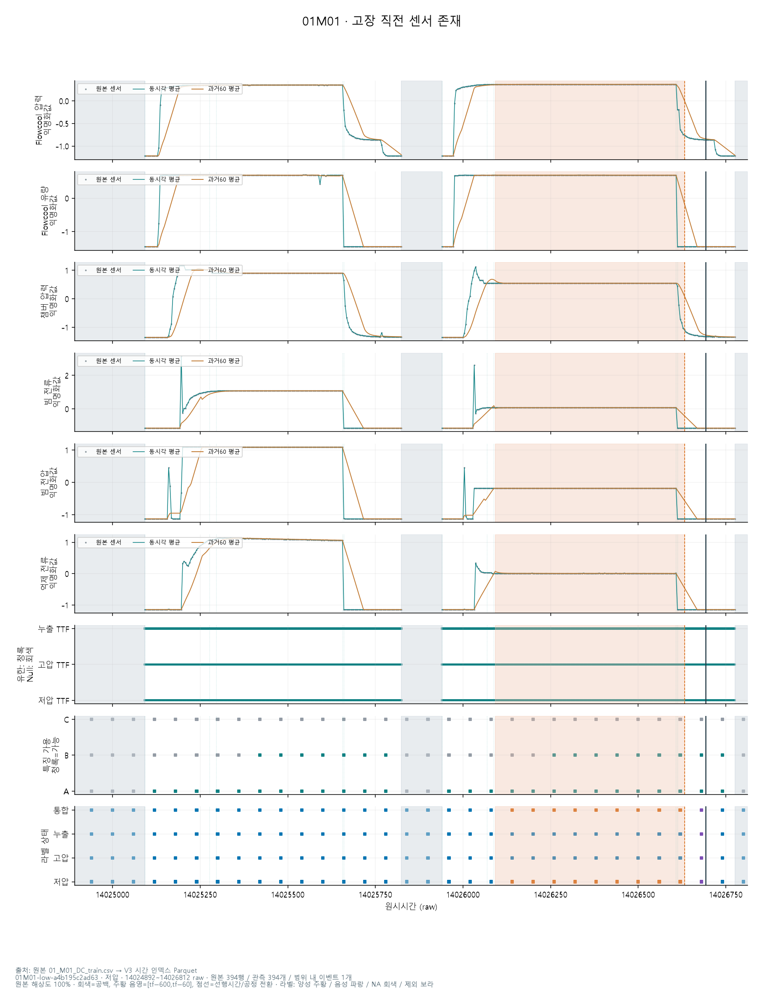

출처: `PHM2018-Project-V3/outputs/figures/fault_events/01M01-03.png`

01M01-low-a4b195c2ad63 · 저압 · 14024892~14026812 raw · 원본 394행 / 관측 394개 / 범위 내 이벤트 1개
원본 해상도 100% · 회색=공백, 주황 음영=[tf−600,tf−60], 점선=선행시간/공정 전환 · 라벨: 양성 주황 / 음성 파랑 / NA 회색 / 제외 보라

<a id="fig-025"></a>

**01M01 · 센서 변화 진단**

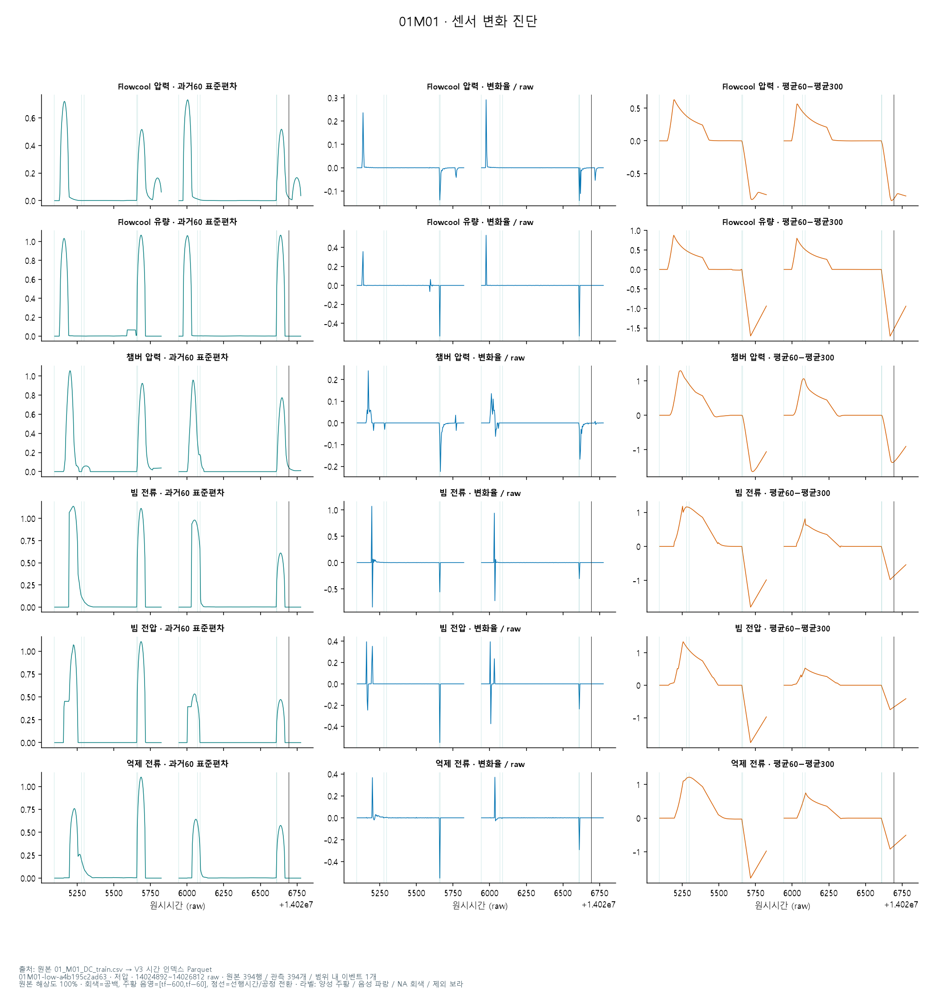

출처: `PHM2018-Project-V3/outputs/figures/fault_events/01M01-03_changes.png`

01M01-low-a4b195c2ad63 · 저압 · 14024892~14026812 raw · 원본 394행 / 관측 394개 / 범위 내 이벤트 1개
원본 해상도 100% · 회색=공백, 주황 음영=[tf−600,tf−60], 점선=선행시간/공정 전환 · 라벨: 양성 주황 / 음성 파랑 / NA 회색 / 제외 보라

<a id="fig-026"></a>

**01M01 · 구간 내 공정 상태별 센서 분포**

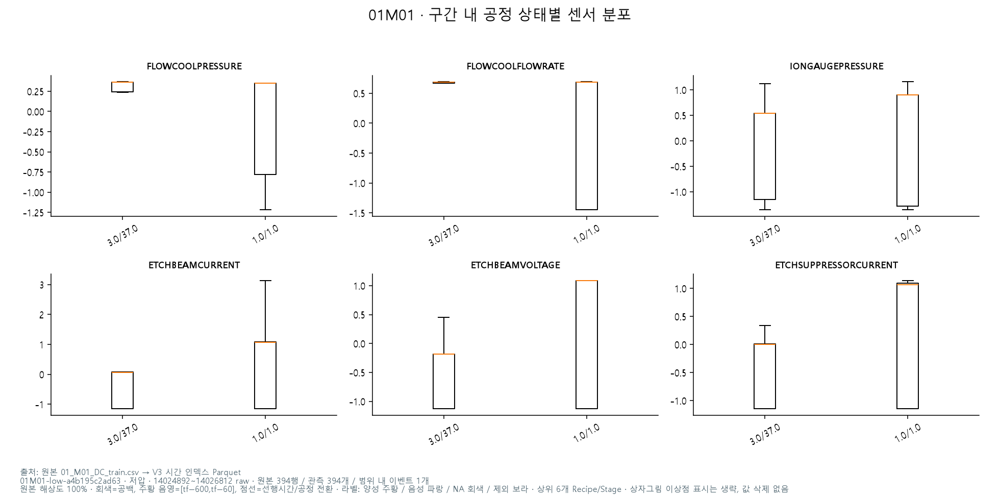

출처: `PHM2018-Project-V3/outputs/figures/fault_events/01M01-03_conditions.png`

01M01-low-a4b195c2ad63 · 저압 · 14024892~14026812 raw · 원본 394행 / 관측 394개 / 범위 내 이벤트 1개
원본 해상도 100% · 회색=공백, 주황 음영=[tf−600,tf−60], 점선=선행시간/공정 전환 · 라벨: 양성 주황 / 음성 파랑 / NA 회색 / 제외 보라 · 상위 6개 Recipe/Stage · 상자그림 이상점 표시는 생략, 값 삭제 없음

<a id="fig-027"></a>

**01M01 · 고장은 있으나 장기 이력 부족**

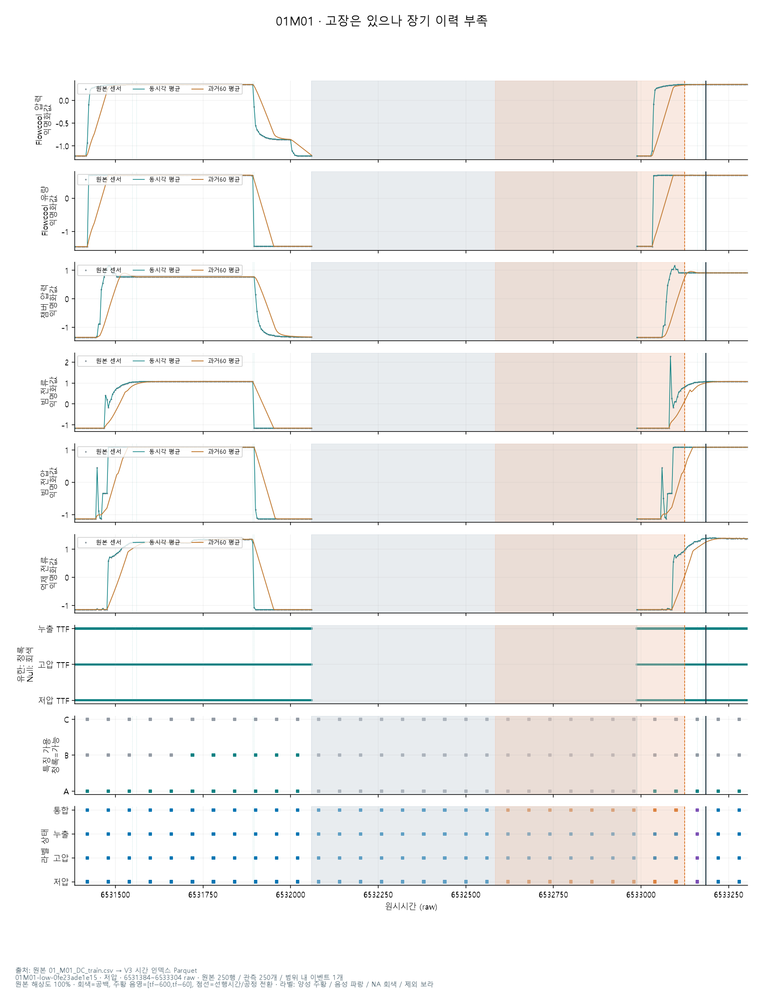

출처: `PHM2018-Project-V3/outputs/figures/fault_events/01M01-04.png`

01M01-low-0fe23ade1e15 · 저압 · 6531384~6533304 raw · 원본 250행 / 관측 250개 / 범위 내 이벤트 1개
원본 해상도 100% · 회색=공백, 주황 음영=[tf−600,tf−60], 점선=선행시간/공정 전환 · 라벨: 양성 주황 / 음성 파랑 / NA 회색 / 제외 보라

<a id="fig-028"></a>

**01M01 · 공정 전환과 센서 변화**

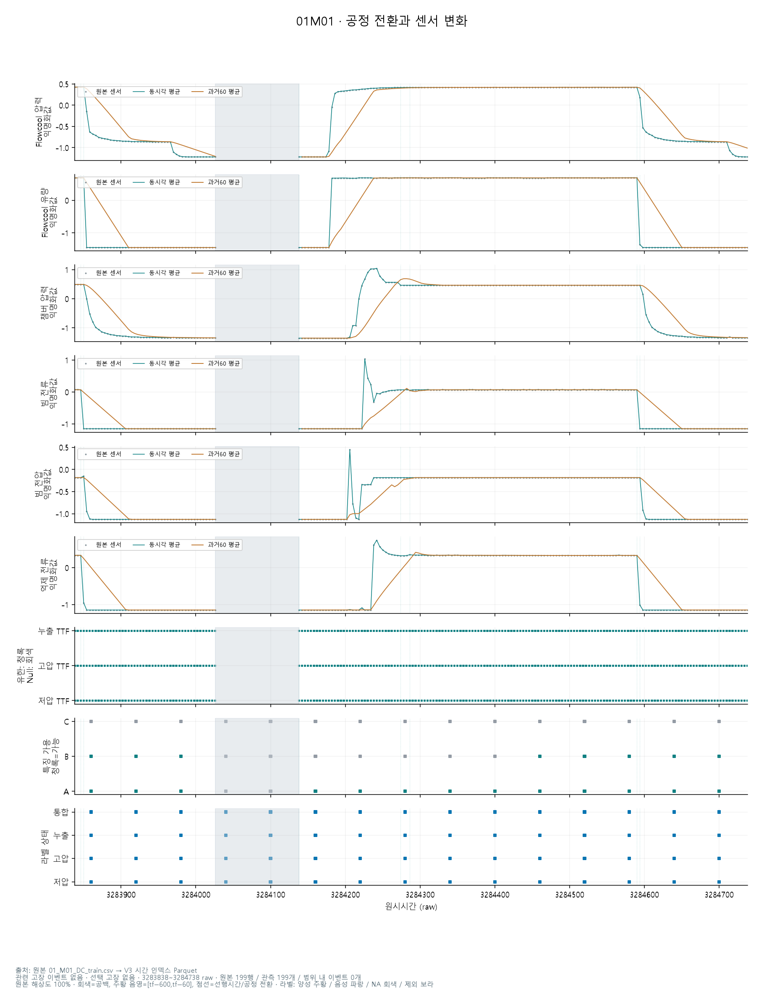

출처: `PHM2018-Project-V3/outputs/figures/fault_events/01M01-05.png`

관련 고장 이벤트 없음 · 선택 고장 없음 · 3283838~3284738 raw · 원본 199행 / 관측 199개 / 범위 내 이벤트 0개
원본 해상도 100% · 회색=공백, 주황 음영=[tf−600,tf−60], 점선=선행시간/공정 전환 · 라벨: 양성 주황 / 음성 파랑 / NA 회색 / 제외 보라

<a id="fig-029"></a>

**01M01 · 센서 변화 진단**

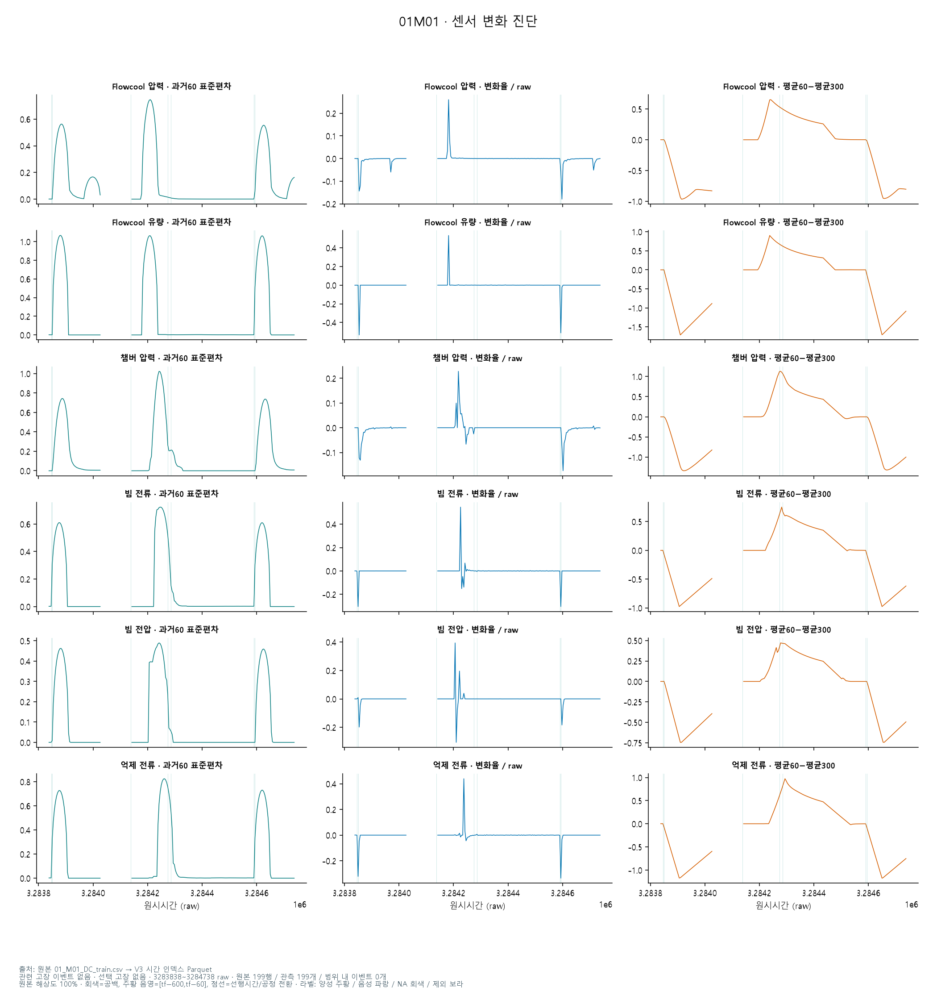

출처: `PHM2018-Project-V3/outputs/figures/fault_events/01M01-05_changes.png`

관련 고장 이벤트 없음 · 선택 고장 없음 · 3283838~3284738 raw · 원본 199행 / 관측 199개 / 범위 내 이벤트 0개
원본 해상도 100% · 회색=공백, 주황 음영=[tf−600,tf−60], 점선=선행시간/공정 전환 · 라벨: 양성 주황 / 음성 파랑 / NA 회색 / 제외 보라

<a id="fig-030"></a>

**01M01 · 구간 내 공정 상태별 센서 분포**

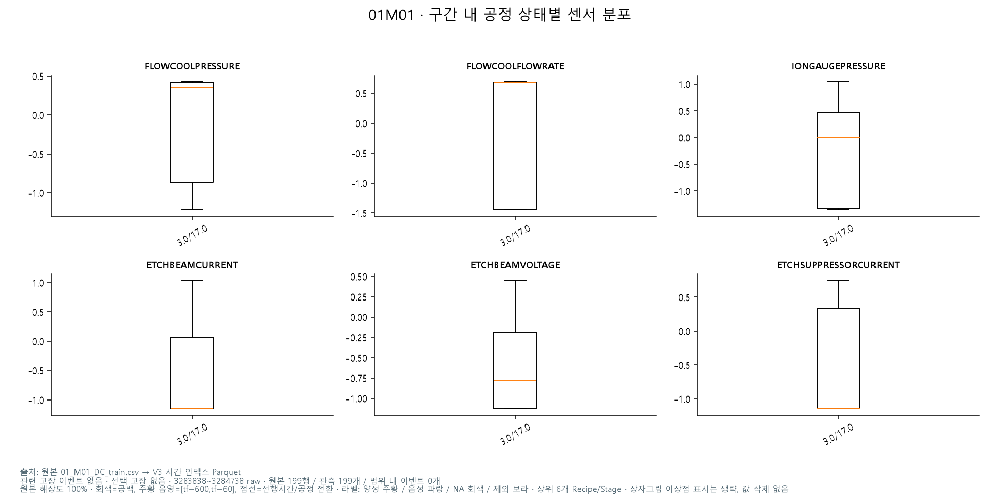

출처: `PHM2018-Project-V3/outputs/figures/fault_events/01M01-05_conditions.png`

관련 고장 이벤트 없음 · 선택 고장 없음 · 3283838~3284738 raw · 원본 199행 / 관측 199개 / 범위 내 이벤트 0개
원본 해상도 100% · 회색=공백, 주황 음영=[tf−600,tf−60], 점선=선행시간/공정 전환 · 라벨: 양성 주황 / 음성 파랑 / NA 회색 / 제외 보라 · 상위 6개 Recipe/Stage · 상자그림 이상점 표시는 생략, 값 삭제 없음

<a id="fig-031"></a>

**01M01 · TTF Null 집중**

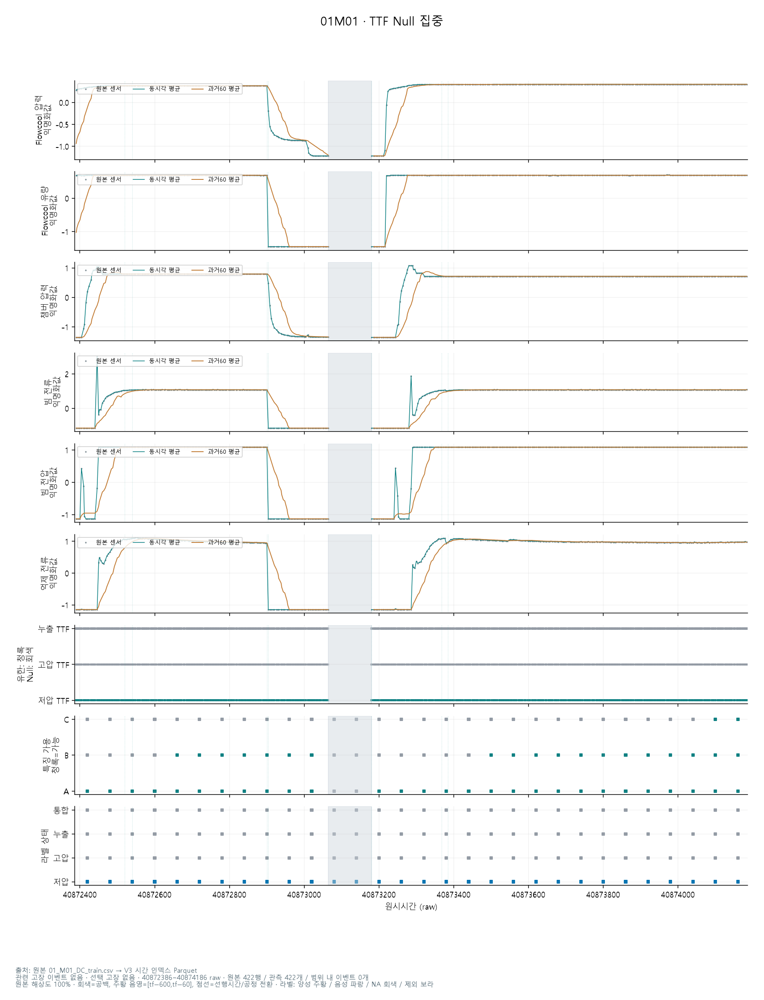

출처: `PHM2018-Project-V3/outputs/figures/fault_events/01M01-06.png`

관련 고장 이벤트 없음 · 선택 고장 없음 · 40872386~40874186 raw · 원본 422행 / 관측 422개 / 범위 내 이벤트 0개
원본 해상도 100% · 회색=공백, 주황 음영=[tf−600,tf−60], 점선=선행시간/공정 전환 · 라벨: 양성 주황 / 음성 파랑 / NA 회색 / 제외 보라

<a id="fig-032"></a>

**03M02 · 긴 센서 공백**

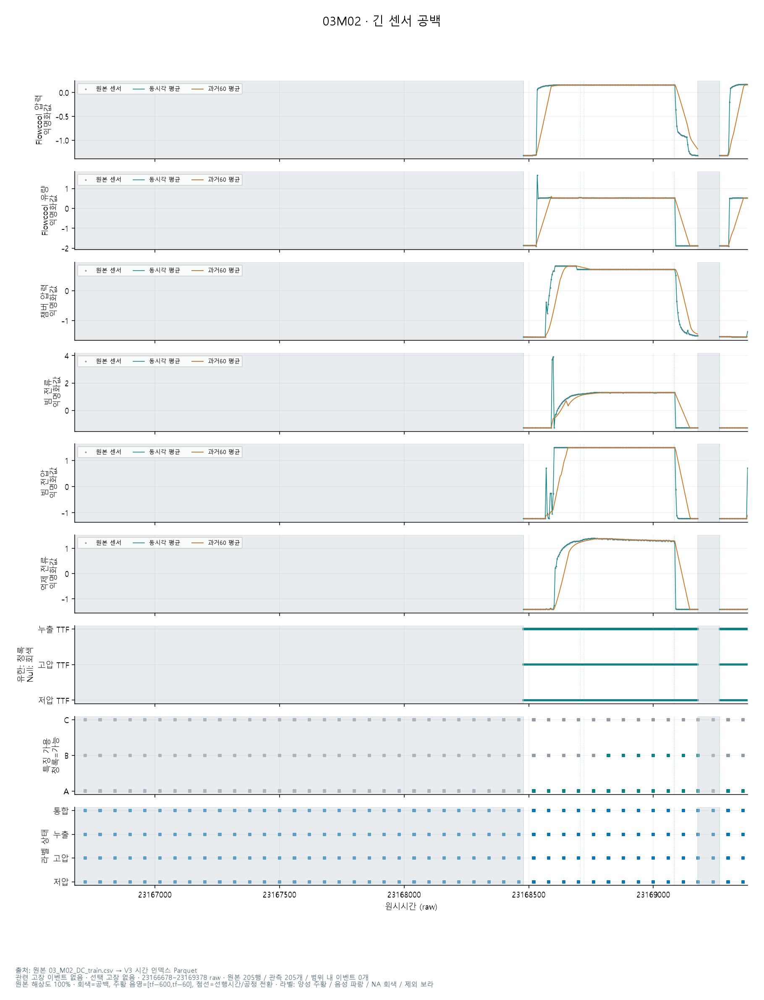

출처: `PHM2018-Project-V3/outputs/figures/fault_events/03M02-07.png`

관련 고장 이벤트 없음 · 선택 고장 없음 · 23166678~23169378 raw · 원본 205행 / 관측 205개 / 범위 내 이벤트 0개
원본 해상도 100% · 회색=공백, 주황 음영=[tf−600,tf−60], 점선=선행시간/공정 전환 · 라벨: 양성 주황 / 음성 파랑 / NA 회색 / 제외 보라

<a id="fig-033"></a>

**03M02 · 동일 시각 공정 충돌**

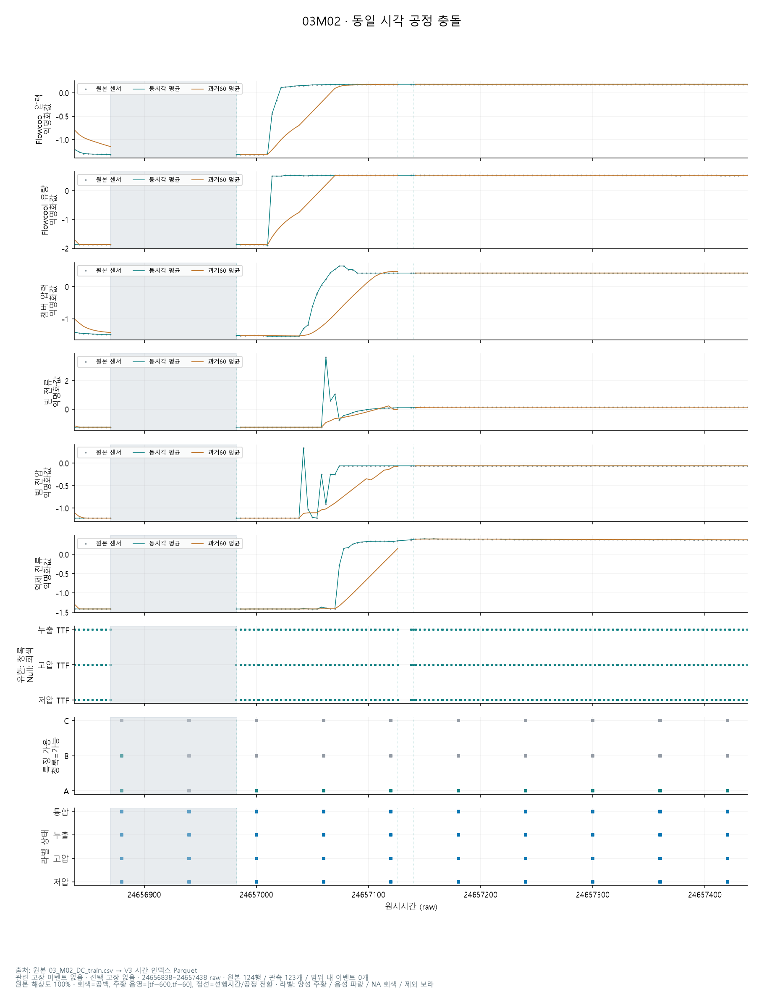

출처: `PHM2018-Project-V3/outputs/figures/fault_events/03M02-08.png`

관련 고장 이벤트 없음 · 선택 고장 없음 · 24656838~24657438 raw · 원본 124행 / 관측 123개 / 범위 내 이벤트 0개
원본 해상도 100% · 회색=공백, 주황 음영=[tf−600,tf−60], 점선=선행시간/공정 전환 · 라벨: 양성 주황 / 음성 파랑 / NA 회색 / 제외 보라

<a id="fig-034"></a>

**03M02 · 고장 직전 센서 존재**

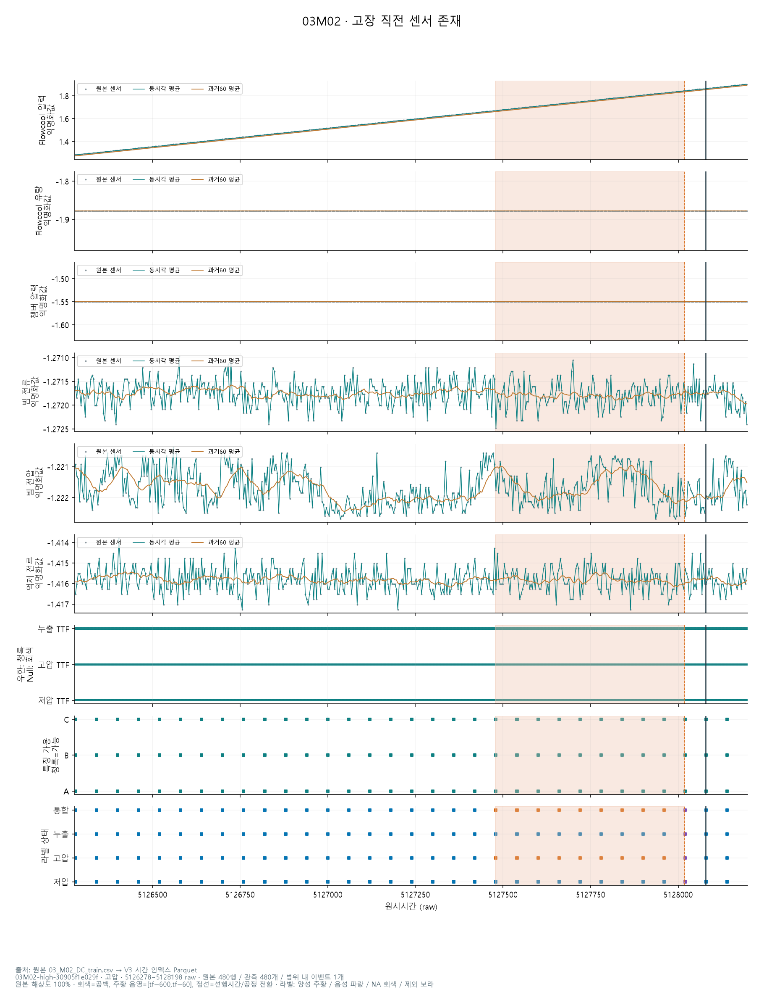

출처: `PHM2018-Project-V3/outputs/figures/fault_events/03M02-09.png`

03M02-high-30905f1e029f · 고압 · 5126278~5128198 raw · 원본 480행 / 관측 480개 / 범위 내 이벤트 1개
원본 해상도 100% · 회색=공백, 주황 음영=[tf−600,tf−60], 점선=선행시간/공정 전환 · 라벨: 양성 주황 / 음성 파랑 / NA 회색 / 제외 보라

<a id="fig-035"></a>

**03M02 · 센서 변화 진단**

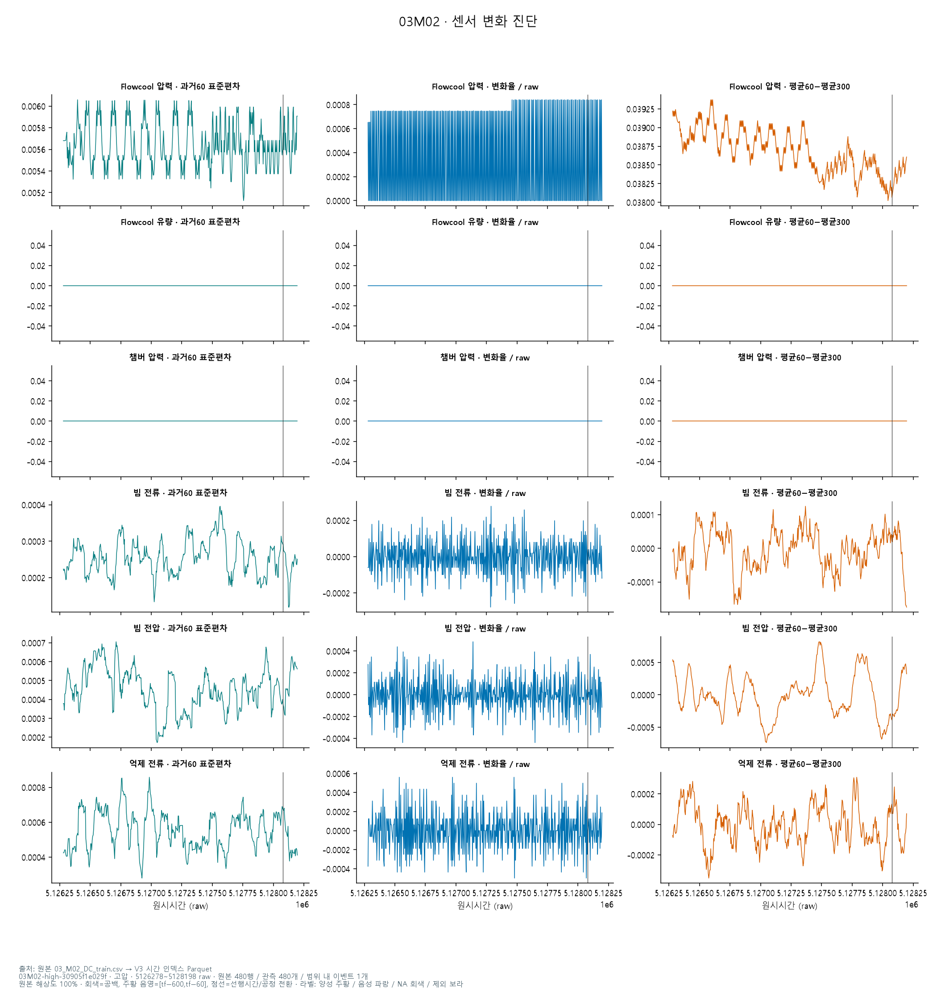

출처: `PHM2018-Project-V3/outputs/figures/fault_events/03M02-09_changes.png`

03M02-high-30905f1e029f · 고압 · 5126278~5128198 raw · 원본 480행 / 관측 480개 / 범위 내 이벤트 1개
원본 해상도 100% · 회색=공백, 주황 음영=[tf−600,tf−60], 점선=선행시간/공정 전환 · 라벨: 양성 주황 / 음성 파랑 / NA 회색 / 제외 보라

<a id="fig-036"></a>

**03M02 · 구간 내 공정 상태별 센서 분포**

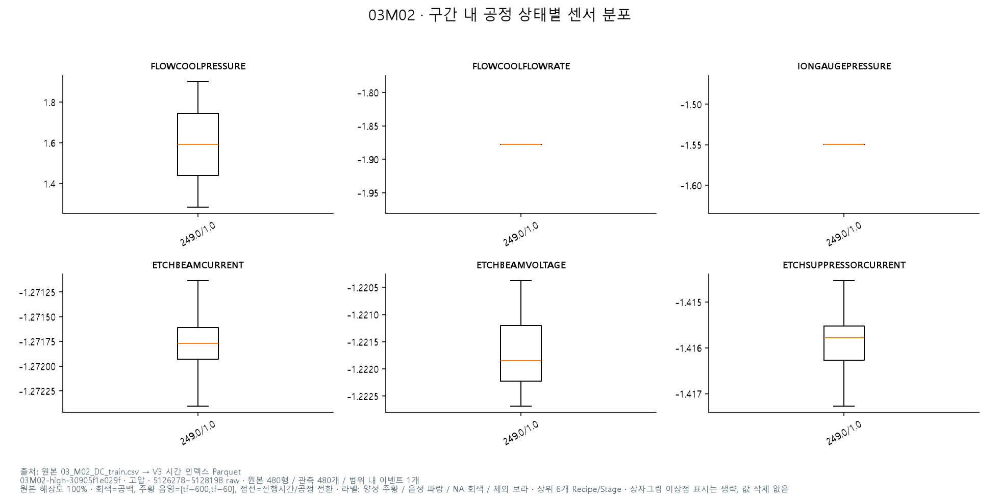

출처: `PHM2018-Project-V3/outputs/figures/fault_events/03M02-09_conditions.png`

03M02-high-30905f1e029f · 고압 · 5126278~5128198 raw · 원본 480행 / 관측 480개 / 범위 내 이벤트 1개
원본 해상도 100% · 회색=공백, 주황 음영=[tf−600,tf−60], 점선=선행시간/공정 전환 · 라벨: 양성 주황 / 음성 파랑 / NA 회색 / 제외 보라 · 상위 6개 Recipe/Stage · 상자그림 이상점 표시는 생략, 값 삭제 없음

<a id="fig-037"></a>

**03M02 · 고장은 있으나 장기 이력 부족**

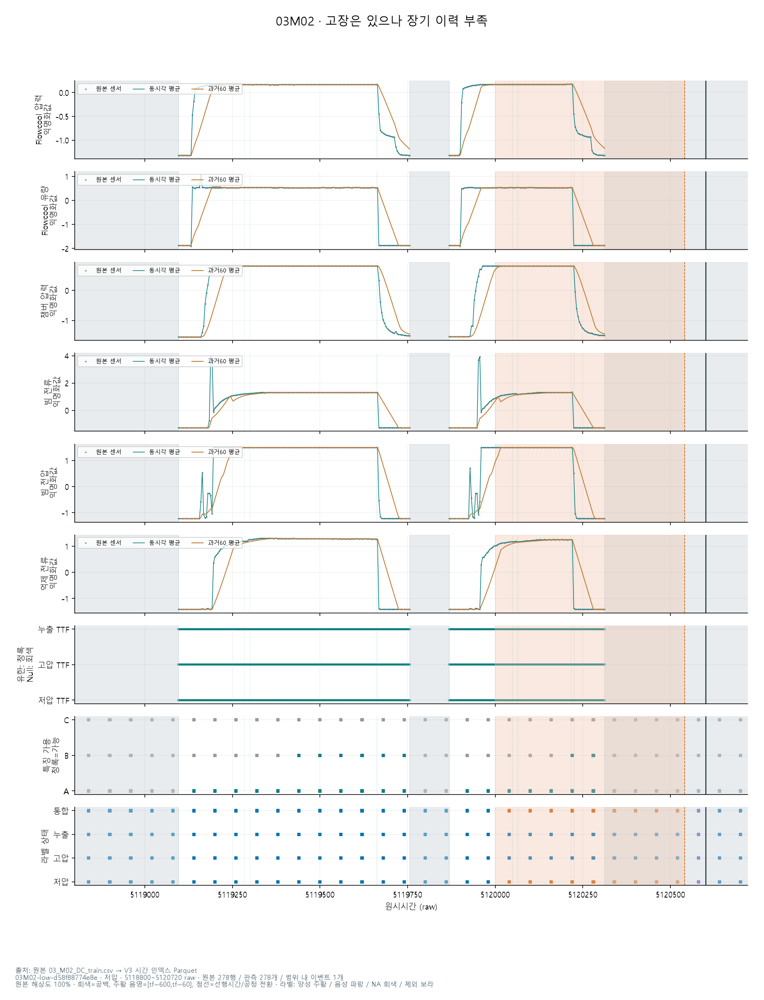

출처: `PHM2018-Project-V3/outputs/figures/fault_events/03M02-10.png`

03M02-low-d58f88774e8e · 저압 · 5118800~5120720 raw · 원본 278행 / 관측 278개 / 범위 내 이벤트 1개
원본 해상도 100% · 회색=공백, 주황 음영=[tf−600,tf−60], 점선=선행시간/공정 전환 · 라벨: 양성 주황 / 음성 파랑 / NA 회색 / 제외 보라

<a id="fig-038"></a>

**03M02 · 공정 전환과 센서 변화**

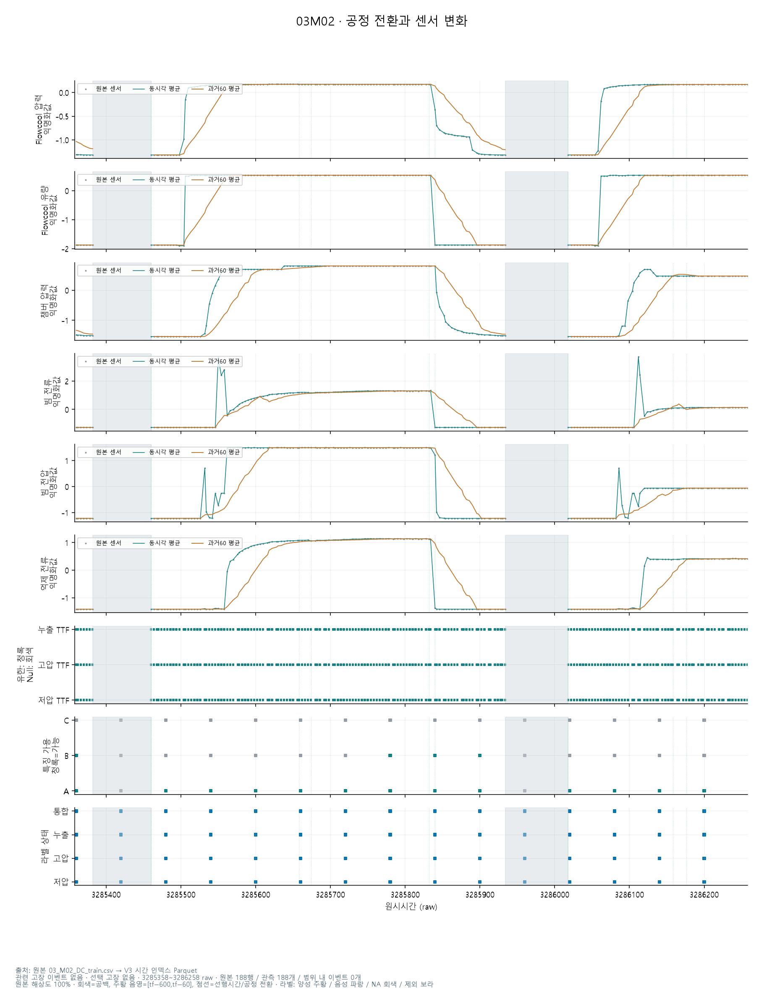

출처: `PHM2018-Project-V3/outputs/figures/fault_events/03M02-11.png`

관련 고장 이벤트 없음 · 선택 고장 없음 · 3285358~3286258 raw · 원본 188행 / 관측 188개 / 범위 내 이벤트 0개
원본 해상도 100% · 회색=공백, 주황 음영=[tf−600,tf−60], 점선=선행시간/공정 전환 · 라벨: 양성 주황 / 음성 파랑 / NA 회색 / 제외 보라

<a id="fig-039"></a>

**03M02 · 센서 변화 진단**

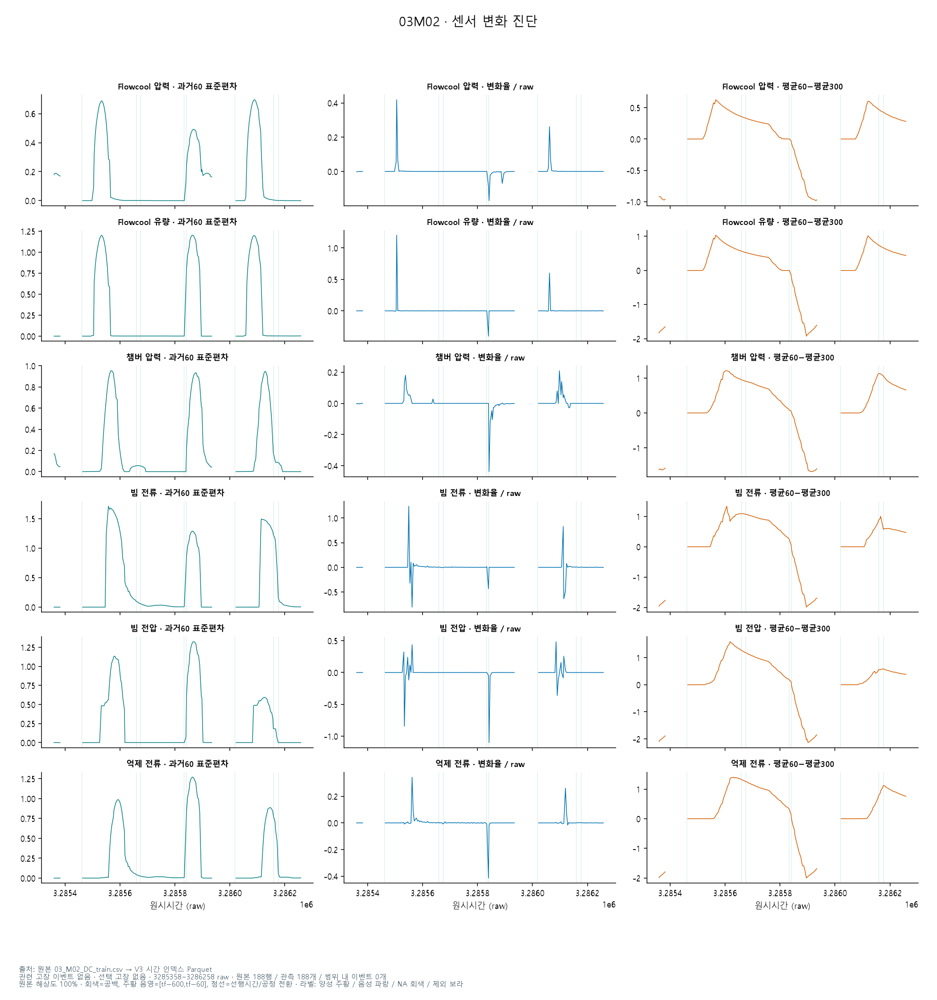

출처: `PHM2018-Project-V3/outputs/figures/fault_events/03M02-11_changes.png`

관련 고장 이벤트 없음 · 선택 고장 없음 · 3285358~3286258 raw · 원본 188행 / 관측 188개 / 범위 내 이벤트 0개
원본 해상도 100% · 회색=공백, 주황 음영=[tf−600,tf−60], 점선=선행시간/공정 전환 · 라벨: 양성 주황 / 음성 파랑 / NA 회색 / 제외 보라

<a id="fig-040"></a>

**03M02 · 구간 내 공정 상태별 센서 분포**

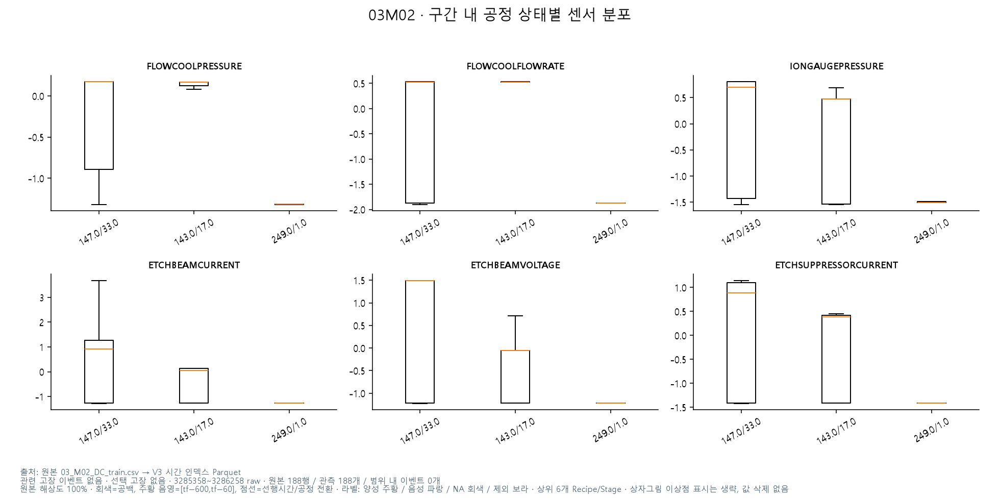

출처: `PHM2018-Project-V3/outputs/figures/fault_events/03M02-11_conditions.png`

관련 고장 이벤트 없음 · 선택 고장 없음 · 3285358~3286258 raw · 원본 188행 / 관측 188개 / 범위 내 이벤트 0개
원본 해상도 100% · 회색=공백, 주황 음영=[tf−600,tf−60], 점선=선행시간/공정 전환 · 라벨: 양성 주황 / 음성 파랑 / NA 회색 / 제외 보라 · 상위 6개 Recipe/Stage · 상자그림 이상점 표시는 생략, 값 삭제 없음

<a id="fig-041"></a>

**03M02 · TTF Null 집중**

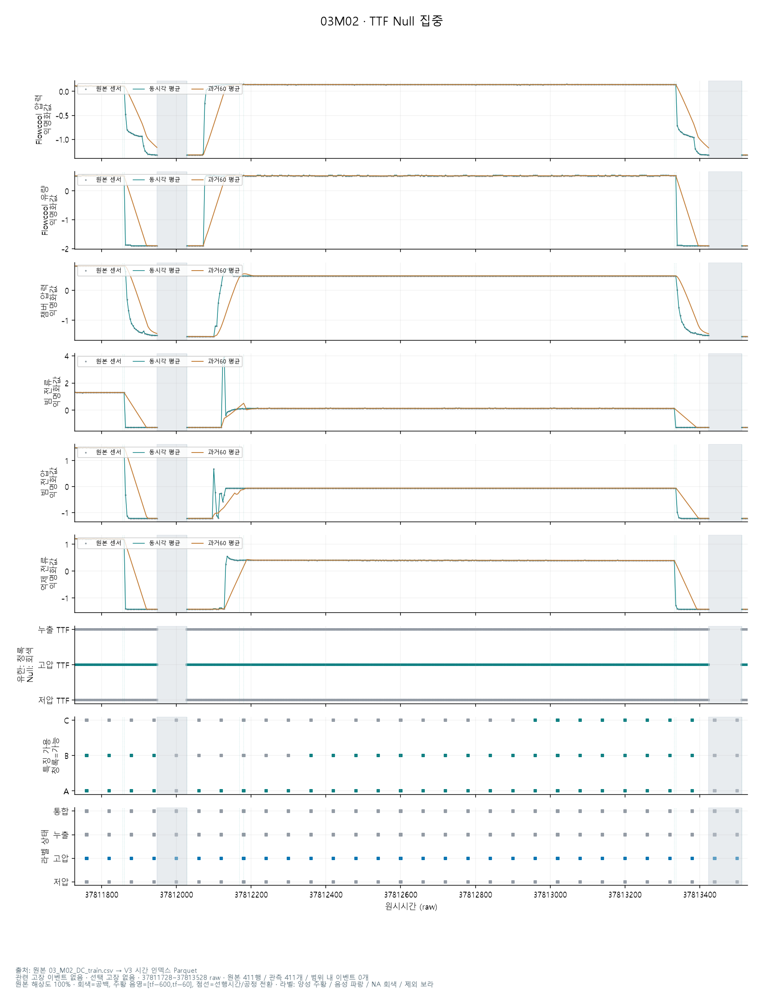

출처: `PHM2018-Project-V3/outputs/figures/fault_events/03M02-12.png`

관련 고장 이벤트 없음 · 선택 고장 없음 · 37811728~37813528 raw · 원본 411행 / 관측 411개 / 범위 내 이벤트 0개
원본 해상도 100% · 회색=공백, 주황 음영=[tf−600,tf−60], 점선=선행시간/공정 전환 · 라벨: 양성 주황 / 음성 파랑 / NA 회색 / 제외 보라

<a id="fig-042"></a>

**01M01 · 저압 · Recipe=1, Stage=1, Step=1 · 이벤트 정렬**

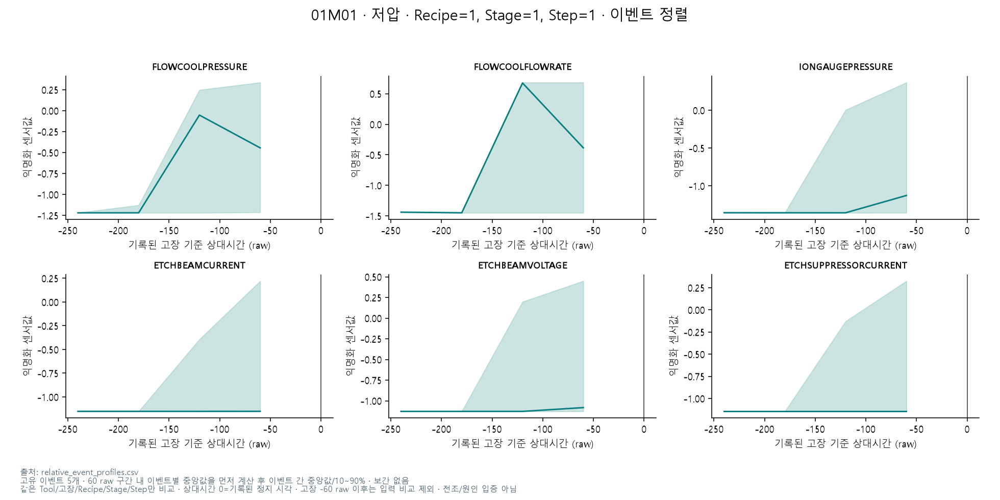

출처: `PHM2018-Project-V3/outputs/figures/fault_events/relative_01M01_low_1_1_1.png`

고유 이벤트 5개 · 60 raw 구간 내 이벤트별 중앙값을 먼저 계산 후 이벤트 간 중앙값/10~90% · 보간 없음
같은 Tool/고장/Recipe/Stage/Step만 비교 · 상대시간 0=기록된 정지 시각 · 고장 -60 raw 이후는 입력 비교 제외 · 전조/원인 입증 아님

<a id="fig-043"></a>

**03M02 · 저압 · Recipe=143, Stage=14, Step=3 · 이벤트 정렬**

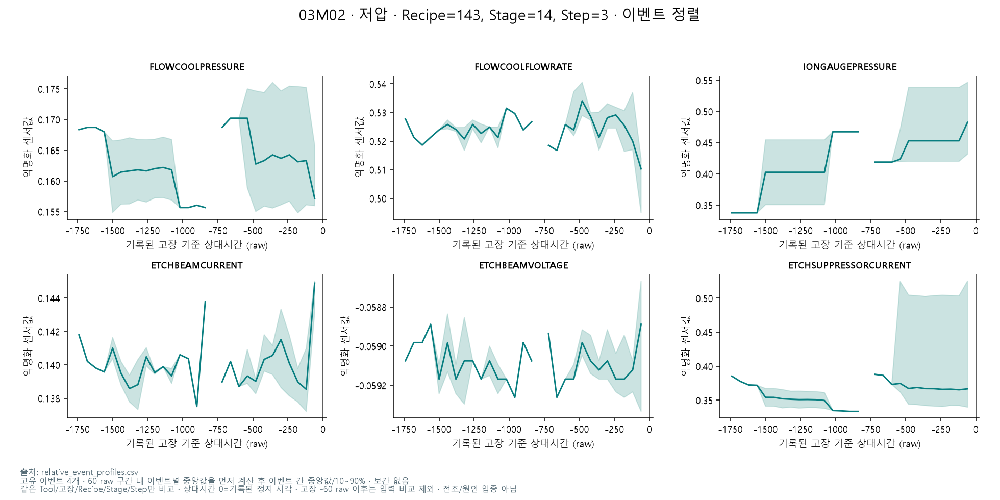

출처: `PHM2018-Project-V3/outputs/figures/fault_events/relative_03M02_low_143_14_3.png`

고유 이벤트 4개 · 60 raw 구간 내 이벤트별 중앙값을 먼저 계산 후 이벤트 간 중앙값/10~90% · 보간 없음
같은 Tool/고장/Recipe/Stage/Step만 비교 · 상대시간 0=기록된 정지 시각 · 고장 -60 raw 이후는 입력 비교 제외 · 전조/원인 입증 아님

<a id="fig-044"></a>

**03M02 · 저압 · Recipe=255, Stage=264, Step=11 · 이벤트 정렬**

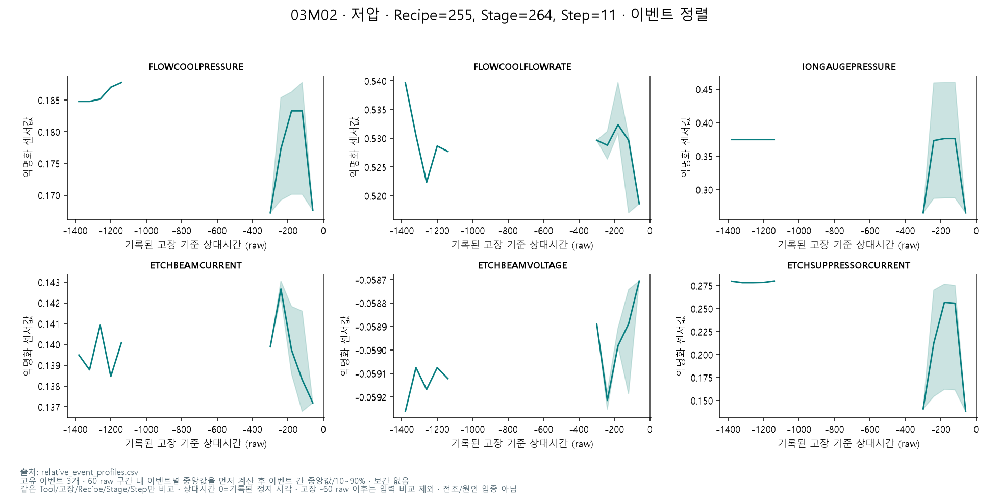

출처: `PHM2018-Project-V3/outputs/figures/fault_events/relative_03M02_low_255_264_11.png`

고유 이벤트 3개 · 60 raw 구간 내 이벤트별 중앙값을 먼저 계산 후 이벤트 간 중앙값/10~90% · 보간 없음
같은 Tool/고장/Recipe/Stage/Step만 비교 · 상대시간 0=기록된 정지 시각 · 고장 -60 raw 이후는 입력 비교 제외 · 전조/원인 입증 아님

<a id="fig-045"></a>

**03M02 · 고압 · Recipe=249, Stage=1, Step=1 · 이벤트 정렬**

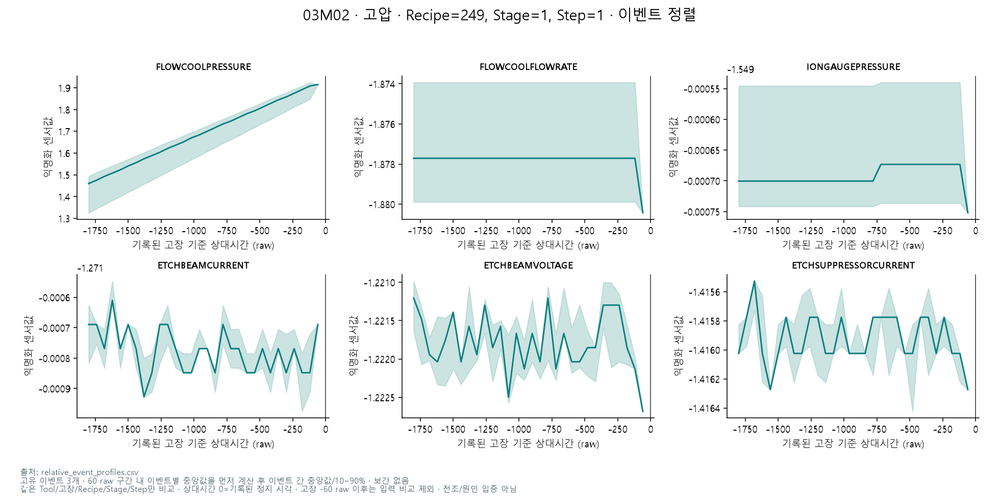

출처: `PHM2018-Project-V3/outputs/figures/fault_events/relative_03M02_high_249_1_1.png`

고유 이벤트 3개 · 60 raw 구간 내 이벤트별 중앙값을 먼저 계산 후 이벤트 간 중앙값/10~90% · 보간 없음
같은 Tool/고장/Recipe/Stage/Step만 비교 · 상대시간 0=기록된 정지 시각 · 고장 -60 raw 이후는 입력 비교 제외 · 전조/원인 입증 아님

<a id="section-7"></a>

## 7. 학습 후보·누수 방지·시간/장비 분할

시간 범위60/20/20%로 분할합니다(행 수 비율 아님). 모든 A/B/C·H에서 t−900≥분할 시작, t+1800<분할 끝을 요구합니다. 다음 동일 유형 고장이 분할 밖이면 음성 근거를 NA로 바꿔 라벨을 재계산했습니다. 입력에는 Tool/시각/TTF/라벨/미래 이력을 넣지 않습니다. 전처리 fit은 train만 사용했습니다. 초기 그룹 후보01–06/07–08/09–10 정의와 실제 단계5 보호 그룹 실험을 구분해야 합니다. 실제 단계5는 앞80% 안에서01–06 학습/07–08 검증만 수행했고09–10 그룹 최종 시험은 하지 않았습니다.

In [8]:
show('pretraining_readiness',rows=24)
show('pretraining_split_boundaries',rows=12)
show('pretraining_unseen_conditions')

**pretraining_readiness** · 전체 108행 × 9열 · 앞 24행 표시, 전체 값은 `T('pretraining_readiness')`로 조회

,scheme,split,H,cohort,feature_set,positive_anchors,negative_anchors,positive_events,both_classes
0,group,holdout,300,common,A,135,40416,37,True
1,group,holdout,300,common,B,135,40416,37,True
2,group,holdout,300,common,C,135,40416,37,True
3,group,holdout,300,maximum,A,363,209416,103,True
4,group,holdout,300,maximum,B,263,134991,80,True
5,group,holdout,300,maximum,C,135,40416,37,True
6,group,holdout,600,common,A,317,40358,51,True
7,group,holdout,600,common,B,317,40358,51,True
8,group,holdout,600,common,C,317,40358,51,True
9,group,holdout,600,maximum,A,819,209277,109,True


**pretraining_split_boundaries** · 전체 80행 × 5열 · 앞 12행 표시, 전체 값은 `T('pretraining_split_boundaries')`로 조회

,Tool,scheme,split,start,end_exclusive
0,01M01,temporal,train,3283106.0,27135644.6
1,01M01,temporal,validation,27135644.6,35086490.8
2,01M01,temporal,holdout,35086490.8,43037337.0
3,01M01,group,train,3283106.0,43037337.0
4,01M02,temporal,train,3283834.0,25187438.2
5,01M02,temporal,validation,25187438.2,32488639.6
6,01M02,temporal,holdout,32488639.6,39789841.0
7,01M02,group,train,3283834.0,39789841.0
8,02M01,temporal,train,3283718.0,20810469.8
9,02M01,temporal,validation,20810469.8,26652720.4


**pretraining_unseen_conditions** · 전체 6행 × 5열

,scheme,split,condition_pairs,unseen_pairs,basis
0,temporal,train,559,0,H600 / A / 정책상 확정 라벨 / 조합 수 기준
1,temporal,validation,127,16,H600 / A / 정책상 확정 라벨 / 조합 수 기준
2,temporal,holdout,55,7,H600 / A / 정책상 확정 라벨 / 조합 수 기준
3,group,train,574,0,H600 / A / 정책상 확정 라벨 / 조합 수 기준
4,group,validation,249,97,H600 / A / 정책상 확정 라벨 / 조합 수 기준
5,group,holdout,208,50,H600 / A / 정책상 확정 라벨 / 조합 수 기준


<a id="section-8"></a>

## 8. 학습 전 경보 평가기 검증

60 raw 간격·동일 세그먼트의 연속 발화를 한 에피소드로 묶습니다. 경보 시작이 고장 전[−600,−60] 안에 있어야 검출하며, 더 일찍 시작해 유지된 경보를 새 검출로 소급하지 않습니다. NA 시작은 미확인 부담으로 남깁니다. 관측 지지길이는 센서 명목4 raw 지지와 점수 유지 구간의 교집합이며 실제 가동시간은 아닙니다. 합성/시험 점수는 평가기 검사에만 사용했고 실제 모델 성능에 섞지 않았습니다.

In [9]:
show('alarm_stage1_overview',rows=20)
show('alarm_stage1_label_states')

**alarm_stage1_overview** · 전체 12행 × 18열

,scheme,feature_set,baseline,recorded_events,scorable_events,available_events,detected_events,alarm_episodes,available_anchors,observed_support_raw,alarms_MATCHED,alarms_KNOWN_NEGATIVE_START,alarms_POSITIVE_UNMATCHED,alarms_UNKNOWN_START,alarms_LATE_OR_EXCLUDED_START,recall_recorded,recall_available,alarm_episodes_per_10000_raw
0,group,A,always_alarm,164,164,73,16,92002,1281388,72980584.0,16,31851,0,60132,3,0.097561,0.219178,12.606367
1,group,A,no_alarm,164,164,73,0,0,1281388,72980584.0,0,0,0,0,0,0.000000,0.000000,0.000000
2,group,B,always_alarm,164,164,73,19,90059,823731,45706136.0,18,31359,0,58680,2,0.115854,0.260274,19.703919
3,group,B,no_alarm,164,164,73,0,0,823731,45706136.0,0,0,0,0,0,0.000000,0.000000,0.000000
4,group,C,always_alarm,164,164,48,16,19605,202586,11305806.0,16,9174,0,10414,1,0.097561,0.333333,17.340648
5,group,C,no_alarm,164,164,48,0,0,202586,11305806.0,0,0,0,0,0,0.000000,0.000000,0.000000
6,temporal,A,always_alarm,232,232,98,25,63590,1061290,60897220.0,26,1551,0,62008,5,0.107759,0.255102,10.442184
7,temporal,A,no_alarm,232,232,98,0,0,1061290,60897220.0,0,0,0,0,0,0.000000,0.000000,0.000000
8,temporal,B,always_alarm,232,232,95,31,62044,745401,42090658.0,31,1494,0,60517,2,0.133621,0.326316,14.740563
9,temporal,B,no_alarm,232,232,95,0,0,745401,42090658.0,0,0,0,0,0,0.000000,0.000000,0.000000


**alarm_stage1_label_states** · 전체 288행 × 5열 · 앞 30행 표시, 전체 값은 `T('alarm_stage1_label_states')`로 조회

,scheme,Tool,feature_set,status,anchors
0,temporal,01M01,A,NEG,0
1,temporal,01M01,A,POS,0
2,temporal,01M01,A,NA,40226
3,temporal,01M01,A,EXCLUDE,0
4,temporal,01M01,B,NEG,0
5,temporal,01M01,B,POS,0
6,temporal,01M01,B,NA,28349
7,temporal,01M01,B,EXCLUDE,0
8,temporal,01M01,C,NEG,0
9,temporal,01M01,C,POS,0


<a id="fig-046"></a>

**학습 전에 확인한 이벤트 관측 커버리지**

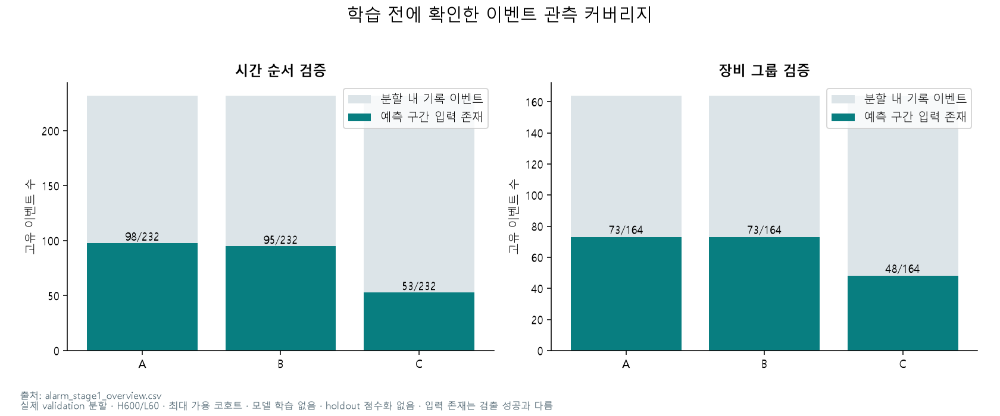

출처: `PHM2018-Project-V3/outputs/figures/alarm_stage1/event_coverage.png`

실제 validation 분할 · H600/L60 · 최대 가용 코호트 · 모델 학습 없음 · holdout 점수화 없음 · 입력 존재는 검출 성공과 다름

<a id="fig-047"></a>

**분류 후보와 전체 점수화 대상의 차이**

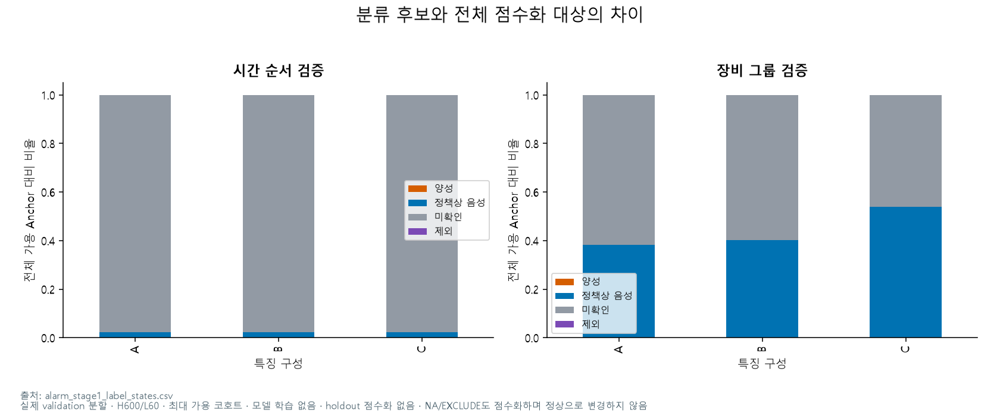

출처: `PHM2018-Project-V3/outputs/figures/alarm_stage1/scoring_population.png`

실제 validation 분할 · H600/L60 · 최대 가용 코호트 · 모델 학습 없음 · holdout 점수화 없음 · NA/EXCLUDE도 점수화하며 정상으로 변경하지 않음

<a id="fig-048"></a>

**고정 기준으로 확인한 경보 집계 동작**

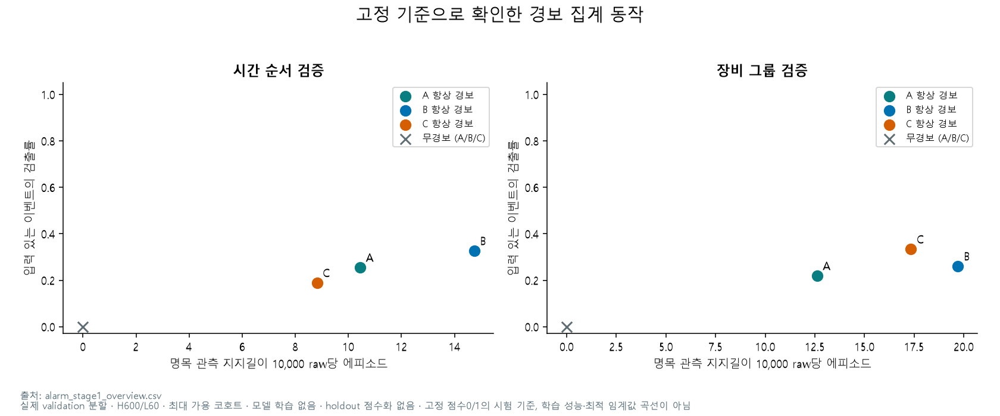

출처: `PHM2018-Project-V3/outputs/figures/alarm_stage1/baseline_checks.png`

실제 validation 분할 · H600/L60 · 최대 가용 코호트 · 모델 학습 없음 · holdout 점수화 없음 · 고정 점수0/1의 시험 기준, 학습 성능·최적 임계값 곡선이 아님

<a id="fig-049"></a>

**항상 경보 기준의 시작 시점별 분류**

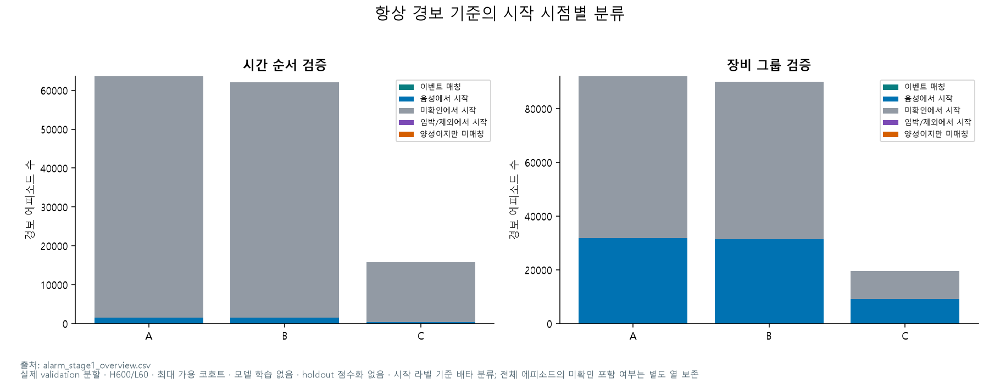

출처: `PHM2018-Project-V3/outputs/figures/alarm_stage1/alarm_categories.png`

실제 validation 분할 · H600/L60 · 최대 가용 코호트 · 모델 학습 없음 · holdout 점수화 없음 · 시작 라벨 기준 배타 분류; 전체 에피소드의 미확인 포함 여부는 별도 열 보존

<a id="fig-050"></a>

**03M02 실제 구간에서 경보 시작 시점 확인**

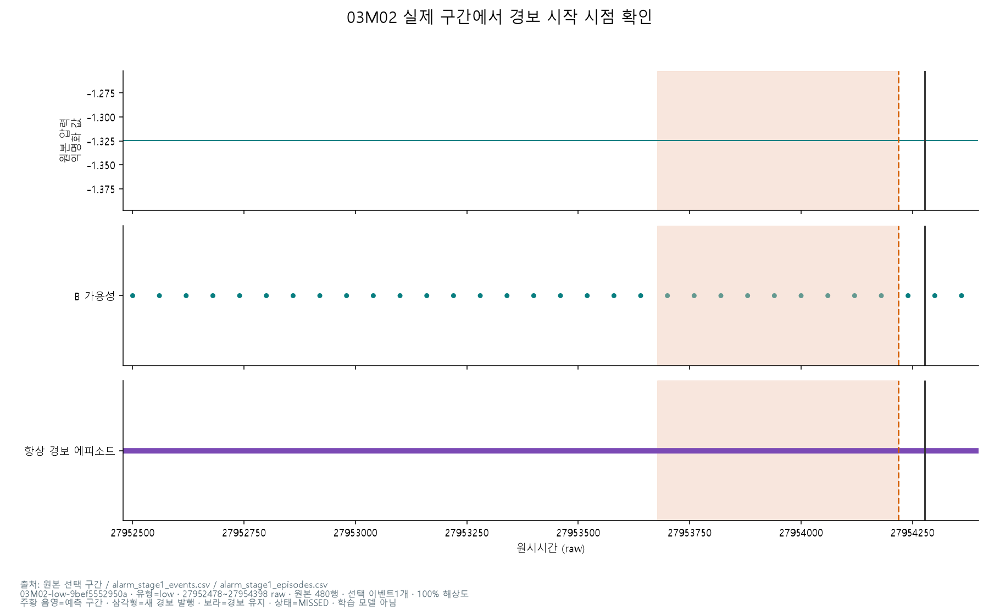

출처: `PHM2018-Project-V3/outputs/figures/alarm_stage1/actual_event.png`

03M02-low-9bef5552950a · 유형=low · 27952478~27954398 raw · 원본 480행 · 선택 이벤트1개 · 100% 해상도
주황 음영=예측 구간 · 삼각형=새 경보 발행 · 보라=경보 유지 · 상태=MISSED · 학습 모델 아님

<a id="section-9"></a>

## 9. 첫 모델 학습: A/B × 로지스틱/CUDA XGBoost

최대가용 코호트의4개 모델을 학습했습니다. 숫자 표준화/범주 인코딩은 train만 fit하고, XGBoost는 CUDA hist로 조기 종료했습니다. A/B 입력 가용성이 달라 이 단계의 차이를 순수 특징 효과로 해석하지 않습니다. AP/AUC는 알려진 라벨만의 보조 지표이며 NA/EXCLUDE까지 포함한 전체 가용 구간에서 경보를 평가했습니다.

In [10]:
show('stage2_training_summary')
show('stage2_operating_points',columns=['run_id','operating_point','threshold','detected_events','available_events','recorded_events','alarm_episodes_per_10000_raw'],rows=20)
show('stage2_uncertainty',rows=12)
show('stage2_tool_event_results',rows=20)

**stage2_training_summary** · 전체 4행 × 16열

,run_id,feature_set,model,device,train_rows,train_positive,validation_all_rows,validation_known_rows,validation_positive,encoded_features,iterations,train_seconds,AP_known,ROC_AUC_known,log_loss_known,artifact_roundtrip_passed
0,A_logistic,A,logistic,cpu,916051,2332,1061290,25266,776,424,94,2.758614,0.058390,0.376102,0.209334,True
1,A_xgboost,A,xgboost,cuda:0,916051,2332,1061290,25266,776,424,27,0.680361,0.170344,0.439372,0.176272,True
2,B_logistic,B,logistic,cpu,664285,1981,745401,17398,627,446,130,5.354463,0.070042,0.394552,0.211608,True
3,B_xgboost,B,xgboost,cuda:0,664285,1981,745401,17398,627,446,2,1.236616,0.067437,0.468656,0.209911,True


**stage2_operating_points** · 전체 12행 × 7열

,run_id,operating_point,threshold,detected_events,available_events,recorded_events,alarm_episodes_per_10000_raw
0,A_logistic,검출최대의50%,0.004036,18.0,98.0,232.0,7.117730
1,A_logistic,검출최대의80%,0.002219,22.0,98.0,232.0,9.653150
2,A_logistic,검출최대의100%,0.000355,27.0,98.0,232.0,11.143037
3,A_xgboost,검출최대의50%,0.001103,25.0,98.0,232.0,10.442184
4,A_xgboost,검출최대의80%,0.003000,34.0,98.0,232.0,17.245122
5,A_xgboost,검출최대의100%,0.003000,34.0,98.0,232.0,17.245122
6,B_logistic,검출최대의50%,0.004429,24.0,95.0,232.0,5.663014
7,B_logistic,검출최대의80%,0.000344,29.0,95.0,232.0,13.879327
8,B_logistic,검출최대의100%,0.000084,31.0,95.0,232.0,14.674753
9,B_xgboost,검출최대의50%,0.003143,26.0,95.0,232.0,7.870393


**stage2_uncertainty** · 전체 24행 × 11열 · 앞 12행 표시, 전체 값은 `T('stage2_uncertainty')`로 조회

,run_id,operating_point,threshold,denominator,recall,ci_low,ci_high,bootstrap_samples,valid_bootstrap_samples,lead_p10,lead_median
0,A_logistic,검출최대의50%,0.004036,available,0.183673,0.090909,0.285714,2000,2000,117.2,366.0
1,A_logistic,검출최대의50%,0.004036,recorded,0.077586,0.043009,0.095238,2000,2000,117.2,366.0
2,A_logistic,검출최대의80%,0.002219,available,0.224490,0.150901,0.278354,2000,2000,126.8,371.0
3,A_logistic,검출최대의80%,0.002219,recorded,0.094828,0.059480,0.145171,2000,2000,126.8,371.0
4,A_logistic,검출최대의100%,0.000355,available,0.275510,0.137920,0.351150,2000,2000,176.0,348.0
5,A_logistic,검출최대의100%,0.000355,recorded,0.116379,0.067300,0.167470,2000,2000,176.0,348.0
6,A_xgboost,검출최대의50%,0.001103,available,0.255102,0.156847,0.320008,2000,2000,159.2,330.0
7,A_xgboost,검출최대의50%,0.001103,recorded,0.107759,0.067853,0.159848,2000,2000,159.2,330.0
8,A_xgboost,검출최대의80%,0.003000,available,0.346939,0.272727,0.417722,2000,2000,173.0,362.0
9,A_xgboost,검출최대의80%,0.003000,recorded,0.146552,0.109285,0.204658,2000,2000,173.0,362.0


**stage2_tool_event_results** · 전체 204행 × 6열 · 앞 20행 표시, 전체 값은 `T('stage2_tool_event_results')`로 조회

,run_id,operating_point,Tool,detected,available,recorded
0,A_logistic,검출최대의50%,01M01,0,0,3
1,A_logistic,검출최대의50%,01M02,1,7,8
2,A_logistic,검출최대의50%,02M01,1,3,9
3,A_logistic,검출최대의50%,02M02,0,1,5
4,A_logistic,검출최대의50%,03M01,0,3,9
5,A_logistic,검출최대의50%,03M02,9,24,91
6,A_logistic,검출최대의50%,04M01,0,0,3
7,A_logistic,검출최대의50%,04M02,2,11,16
8,A_logistic,검출최대의50%,05M01,0,1,1
9,A_logistic,검출최대의50%,05M02,0,0,1


<a id="fig-051"></a>

**분류 점수만으로 경보 모델을 선정할 수 없음**

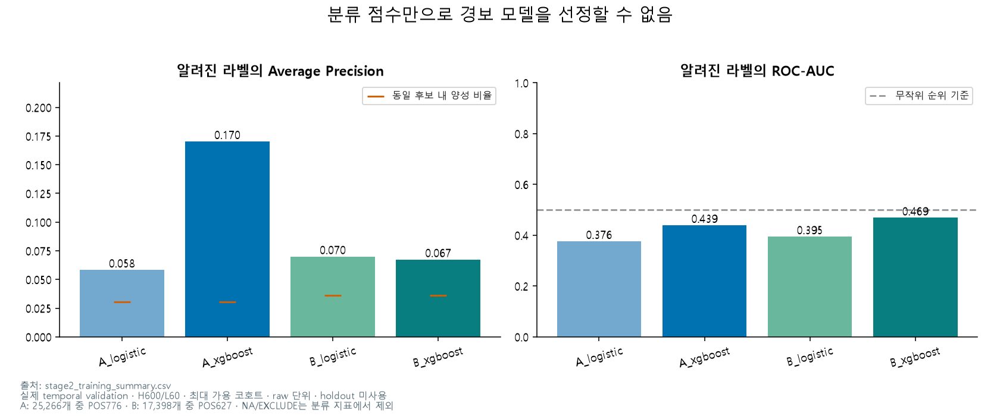

출처: `PHM2018-Project-V3/outputs/figures/stage2/classification.png`

실제 temporal validation · H600/L60 · 최대 가용 코호트 · raw 단위 · holdout 미사용
A: 25,266개 중 POS776 · B: 17,398개 중 POS627 · NA/EXCLUDE는 분류 지표에서 제외

<a id="fig-052"></a>

**검출률과 경보 부담의 동시 비교**

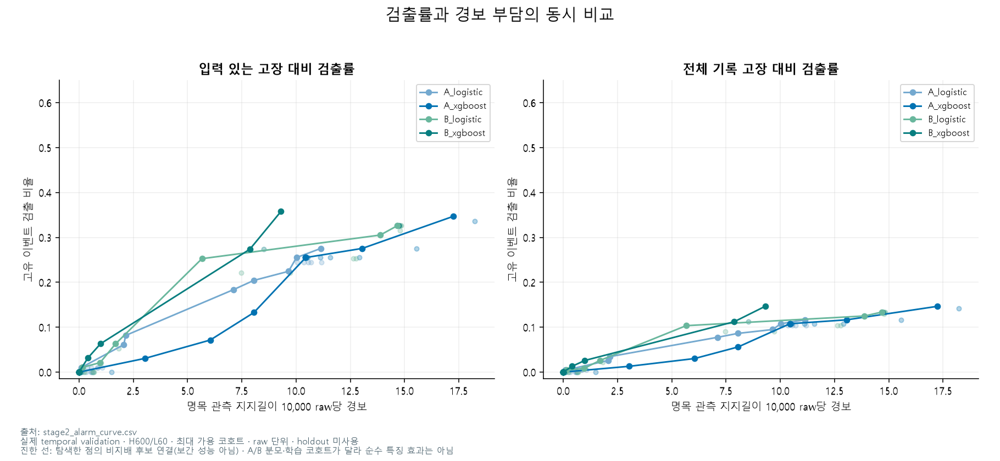

출처: `PHM2018-Project-V3/outputs/figures/stage2/alarm_tradeoff.png`

실제 temporal validation · H600/L60 · 최대 가용 코호트 · raw 단위 · holdout 미사용
진한 선: 탐색한 점의 비지배 후보 연결(보간 성능 아님) · A/B 분모·학습 코호트가 달라 순수 특징 효과는 아님

<a id="fig-053"></a>

**경보 대부분은 정답 미확인 구간에서 시작**

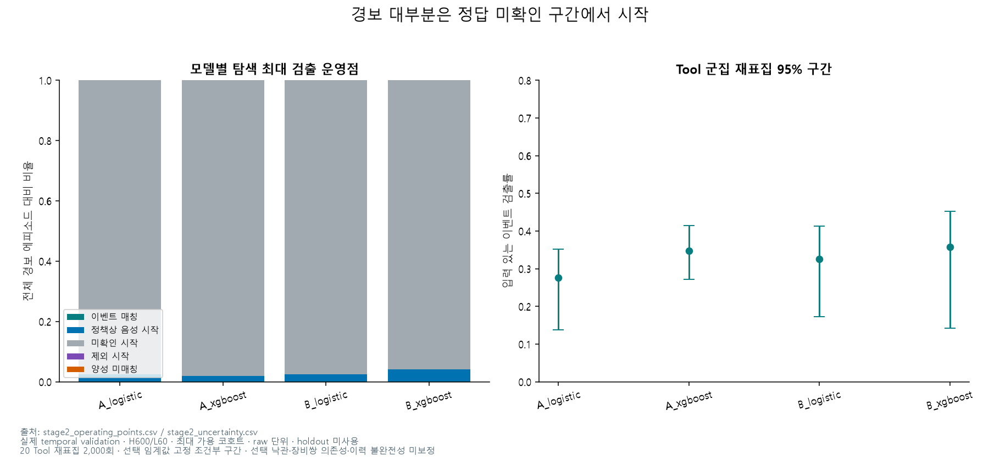

출처: `PHM2018-Project-V3/outputs/figures/stage2/alarm_uncertainty.png`

실제 temporal validation · H600/L60 · 최대 가용 코호트 · raw 단위 · holdout 미사용
20 Tool 재표집 2,000회 · 선택 임계값 고정 조건부 구간 · 선택 낙관·장비쌍 의존성·이력 불완전성 미보정

<a id="fig-054"></a>

**검증 성능 기준 조기 종료 이력**

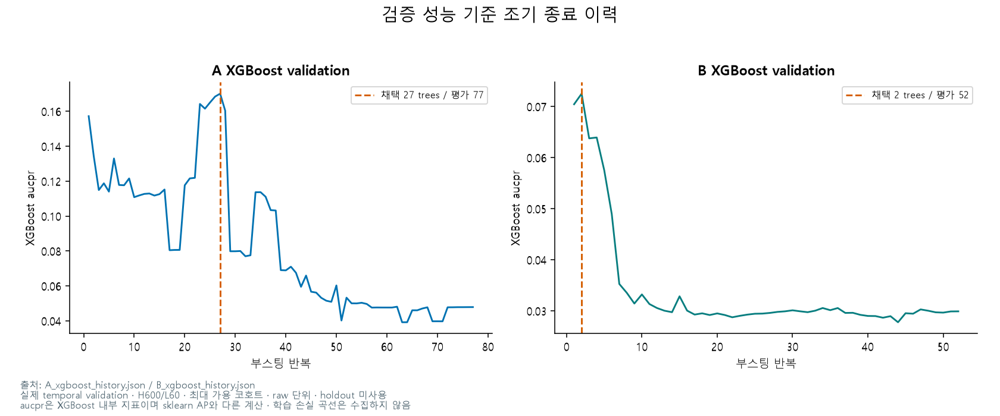

출처: `PHM2018-Project-V3/outputs/figures/stage2/learning_history.png`

실제 temporal validation · H600/L60 · 최대 가용 코호트 · raw 단위 · holdout 미사용
aucpr은 XGBoost 내부 지표이며 sklearn AP와 다른 계산 · 학습 손실 곡선은 수집하지 않음

<a id="fig-055"></a>

**RTX3060 Laptop CUDA 실제 학습과 로컬 자원 사용**

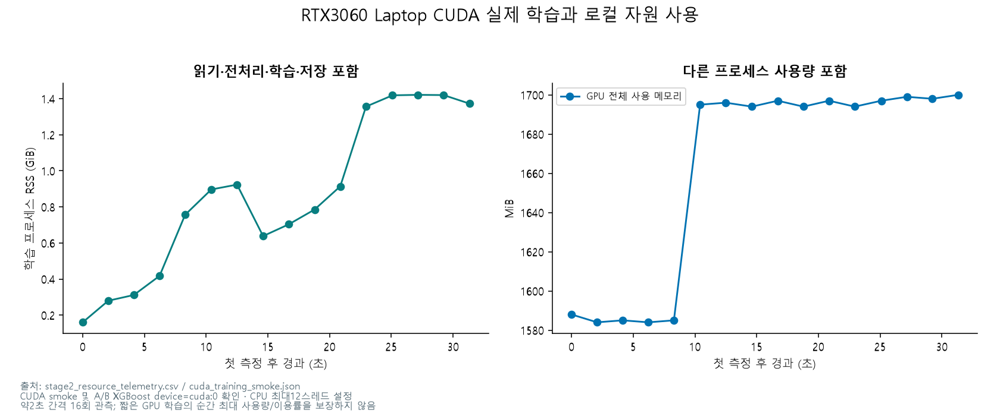

출처: `PHM2018-Project-V3/outputs/figures/stage2/local_resources.png`

CUDA smoke 및 A/B XGBoost device=cuda:0 확인 · CPU 최대12스레드 설정
약2초 간격 16회 관측; 짧은 GPU 학습의 순간 최대 사용량/이용률을 보장하지 않음

<a id="fig-056"></a>

**B XGBoost의 실제 검출·미탐 구간**

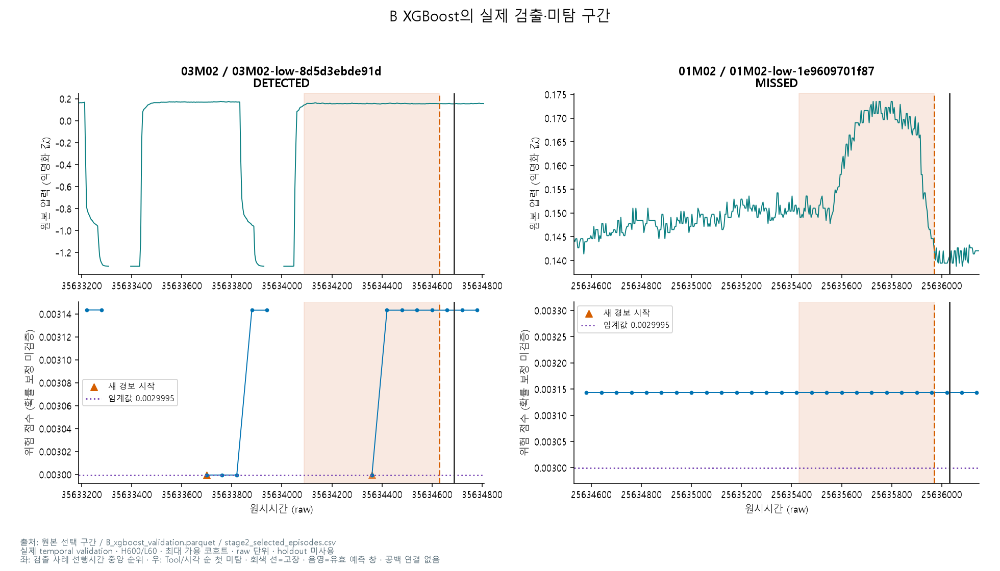

출처: `PHM2018-Project-V3/outputs/figures/stage2/event_examples.png`

실제 temporal validation · H600/L60 · 최대 가용 코호트 · raw 단위 · holdout 미사용
좌: 검출 사례 선행시간 중앙 순위 · 우: Tool/시각 순 첫 미탐 · 회색 선=고장 · 음영=유효 예측 창 · 공백 연결 없음

<a id="section-10"></a>

## 10. 공통 코호트 A/B/C 재학습

C 이력까지 확보된 동일 학습309,273행과 validation309,203행에서6개 모델을 새로 학습했습니다. 입력 가용 고장은53/기록232개입니다. 상한5에서 B XGBoost13개, A9개였고 상한10에서는 A17개/B13개였습니다. C는 매우 낮은 부담의 참조 후보였습니다. 장비쌍10개 군집 부트스트랩은 고정 임계값에 조건부이며 선택 낙관이나 다중 비교를 보정하지 않습니다.

In [11]:
show('stage3_cohort_counts')
show('stage3_training_summary')
show('stage3_budget_points',columns=['run_id','budget_per_10000_raw','threshold','detected_events','available_events','recorded_events','alarm_episodes_per_10000_raw'],rows=30)
show('stage3_paired_deltas',rows=30)
show('stage3_joint_frontier',rows=12)

**stage3_cohort_counts** · 전체 2행 × 6열

,partition,rows,positive,negative,NA,EXCLUDE
0,train_known,309273,1239,308034,0,0
1,validation_all,309203,392,6766,302002,43


**stage3_training_summary** · 전체 6행 × 16열

,run_id,feature_set,model,device,train_rows,train_positive,validation_all_rows,validation_known_rows,validation_positive,encoded_features,iterations,train_seconds,AP_known,ROC_AUC_known,log_loss_known,artifact_roundtrip_passed
0,A_logistic,A,logistic,cpu,309273,1239,309203,7158,392,233,77,0.918014,0.104289,0.268809,0.308452,True
1,A_xgboost,A,xgboost,cuda:0,309273,1239,309203,7158,392,233,53,0.498086,0.245622,0.585560,0.279724,True
2,B_logistic,B,logistic,cpu,309273,1239,309203,7158,392,257,126,2.557342,0.102549,0.283926,0.308509,True
3,B_xgboost,B,xgboost,cuda:0,309273,1239,309203,7158,392,257,36,0.930693,0.206897,0.513422,0.277394,True
4,C_logistic,C,logistic,cpu,309273,1239,309203,7158,392,269,151,3.616388,0.102989,0.297317,0.312445,True
5,C_xgboost,C,xgboost,cuda:0,309273,1239,309203,7158,392,269,14,0.984156,0.195928,0.543356,0.289038,True


**stage3_budget_points** · 전체 18행 × 7열

,run_id,budget_per_10000_raw,threshold,detected_events,available_events,recorded_events,alarm_episodes_per_10000_raw
0,A_logistic,5,0.010031,7.0,53.0,232.0,2.699823
1,A_logistic,10,0.000150,12.0,53.0,232.0,8.827681
2,A_logistic,20,0.000150,12.0,53.0,232.0,8.827681
3,A_xgboost,5,0.010000,9.0,53.0,232.0,3.527821
4,A_xgboost,10,0.006907,17.0,53.0,232.0,6.135707
5,A_xgboost,20,0.004555,19.0,53.0,232.0,11.445658
6,B_logistic,5,0.005429,10.0,53.0,232.0,4.250427
7,B_logistic,10,0.000163,12.0,53.0,232.0,9.062010
8,B_logistic,20,0.000163,12.0,53.0,232.0,9.062010
9,B_xgboost,5,0.006749,13.0,53.0,232.0,4.469620


**stage3_paired_deltas** · 전체 18행 × 11열

,model,budget_per_10000_raw,comparison,detected_before,detected_after,gained_events,lost_events,recall_delta,ci_low,ci_high,valid_bootstrap_samples
0,logistic,5,B-A,7,10,7,4,0.056604,-0.034483,0.160032,2000
1,logistic,5,C-B,10,9,1,2,-0.018868,-0.072738,0.000000,2000
2,logistic,5,C-A,7,9,6,4,0.037736,-0.057185,0.136364,2000
3,logistic,10,B-A,12,12,0,0,0.000000,0.000000,0.000000,2000
4,logistic,10,C-B,12,12,1,1,0.000000,-0.042553,0.069809,2000
5,logistic,10,C-A,12,12,1,1,0.000000,-0.042553,0.069809,2000
6,logistic,20,B-A,12,12,0,0,0.000000,0.000000,0.000000,2000
7,logistic,20,C-B,12,12,1,1,0.000000,-0.042553,0.069809,2000
8,logistic,20,C-A,12,12,1,1,0.000000,-0.042553,0.069809,2000
9,xgboost,5,B-A,9,13,10,6,0.075472,-0.117647,0.190490,2000


**stage3_joint_frontier** · 전체 9행 × 22열

,recorded_events,tagged_events,scorable_events,available_events,detected_events,alarm_episodes,observed_support_raw,alarms_MATCHED,alarms_KNOWN_NEGATIVE_START,alarms_POSITIVE_UNMATCHED,alarms_UNKNOWN_START,alarms_LATE_OR_EXCLUDED_START,run_id,feature_set,threshold,recall_recorded,recall_scorable,recall_available,alarm_episodes_per_10000_raw,median_lead_raw,available_anchors,pareto
0,232.0,0.0,232.0,53.0,1.0,37.0,17838206.0,1.0,0.0,0.0,36.0,0.0,A_xgboost,A,0.040514,0.004310,0.004310,0.018868,0.020742,60.0,309203,True
1,232.0,0.0,232.0,53.0,2.0,177.0,17838206.0,2.0,0.0,0.0,175.0,0.0,C_xgboost,C,0.021731,0.008621,0.008621,0.037736,0.099225,441.0,309203,True
2,232.0,0.0,232.0,53.0,4.0,544.0,17838206.0,5.0,1.0,0.0,537.0,1.0,C_xgboost,C,0.017239,0.017241,0.017241,0.075472,0.304963,459.0,309203,True
3,232.0,0.0,232.0,53.0,5.0,574.0,17838206.0,6.0,1.0,0.0,567.0,0.0,C_xgboost,C,0.014471,0.021552,0.021552,0.094340,0.321781,454.0,309203,True
4,232.0,0.0,232.0,53.0,6.0,2372.0,17838206.0,7.0,33.0,0.0,2332.0,0.0,B_xgboost,B,0.016344,0.025862,0.025862,0.113208,1.329730,320.0,309203,True
5,232.0,0.0,232.0,53.0,10.0,3518.0,17838206.0,11.0,36.0,0.0,3469.0,2.0,B_xgboost,B,0.012544,0.043103,0.043103,0.188679,1.972171,368.0,309203,True
6,232.0,0.0,232.0,53.0,13.0,7973.0,17838206.0,13.0,357.0,0.0,7601.0,2.0,B_xgboost,B,0.006749,0.056034,0.056034,0.245283,4.469620,454.0,309203,True
7,232.0,0.0,232.0,53.0,17.0,10945.0,17838206.0,17.0,316.0,0.0,10610.0,2.0,A_xgboost,A,0.006907,0.073276,0.073276,0.320755,6.135707,310.0,309203,True
8,232.0,0.0,232.0,53.0,19.0,20417.0,17838206.0,19.0,462.0,0.0,19933.0,3.0,A_xgboost,A,0.004555,0.081897,0.081897,0.358491,11.445658,332.0,309203,True


<a id="fig-057"></a>

**공통 코호트로 맞추면서 줄어든 학습량과 이벤트 커버리지**

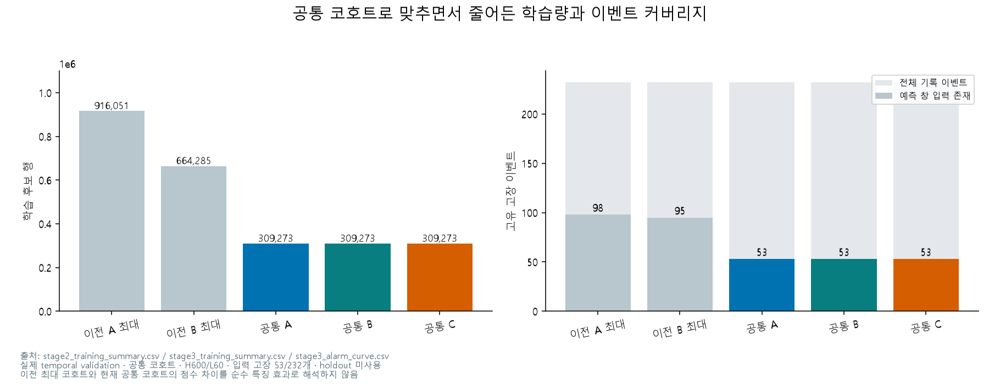

출처: `PHM2018-Project-V3/outputs/figures/stage3/common_cohort.png`

실제 temporal validation · 공통 코호트 · H600/L60 · 입력 고장 53/232개 · holdout 미사용
이전 최대 코호트와 현재 공통 코호트의 점수 차이를 순수 특징 효과로 해석하지 않음

<a id="fig-058"></a>

**같은 정답 후보에서 비교한 분류 보조 지표**

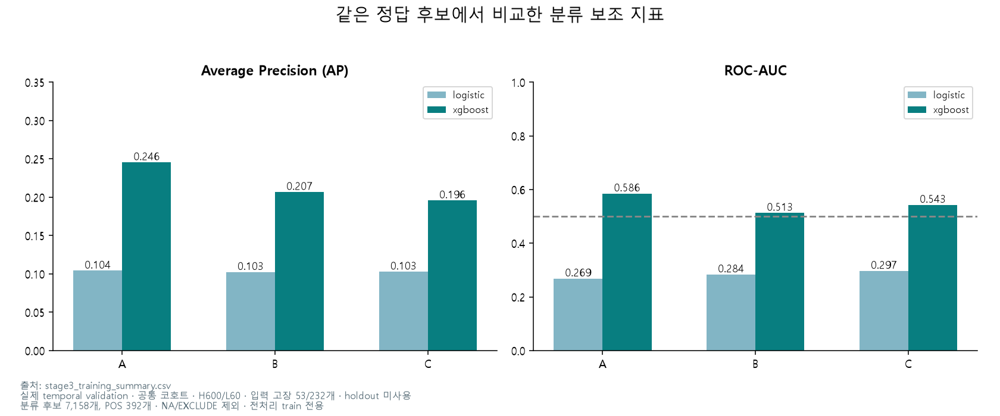

출처: `PHM2018-Project-V3/outputs/figures/stage3/classification.png`

실제 temporal validation · 공통 코호트 · H600/L60 · 입력 고장 53/232개 · holdout 미사용
분류 후보 7,158개, POS 392개 · NA/EXCLUDE 제외 · 전처리 train 전용

<a id="fig-059"></a>

**같은 입력·이벤트·관측 지지길이에서 경보 비교**

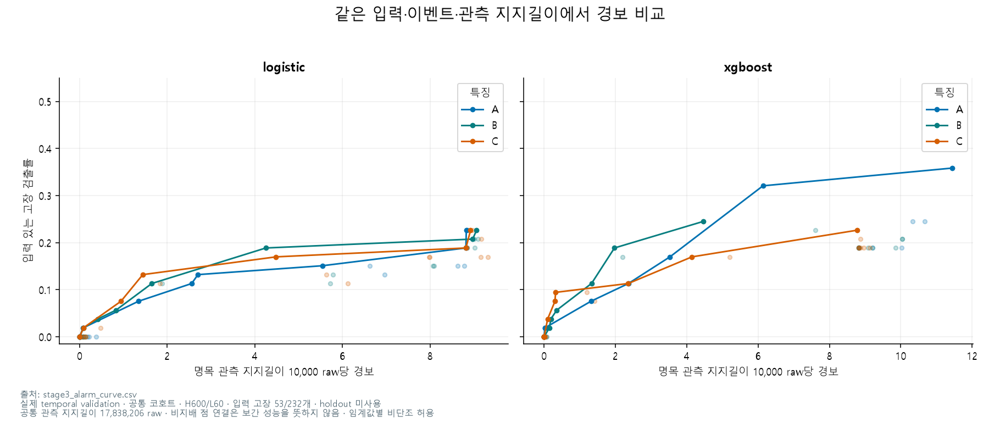

출처: `PHM2018-Project-V3/outputs/figures/stage3/alarm_tradeoff.png`

실제 temporal validation · 공통 코호트 · H600/L60 · 입력 고장 53/232개 · holdout 미사용
공통 관측 지지길이 17,838,206 raw · 비지배 점 연결은 보간 성능을 뜻하지 않음 · 임계값별 비단조 허용

<a id="fig-060"></a>

**A/B/C를 함께 비교하면 남는 경보 운영 후보**

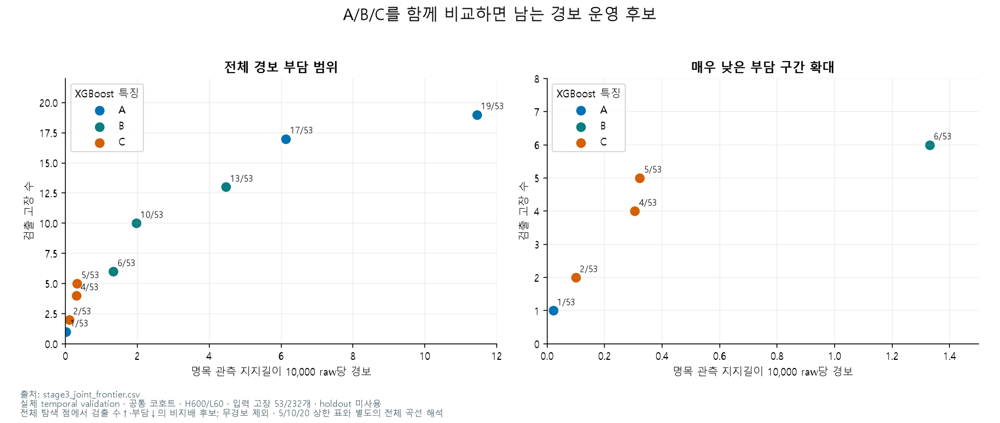

출처: `PHM2018-Project-V3/outputs/figures/stage3/joint_frontier.png`

실제 temporal validation · 공통 코호트 · H600/L60 · 입력 고장 53/232개 · holdout 미사용
전체 탐색 점에서 검출 수↑·부담↓의 비지배 후보; 무경보 제외 · 5/10/20 상한 표와 별도의 전체 곡선 해석

<a id="fig-061"></a>

**같은 경보 부담 상한에서 비교한 검출 수**

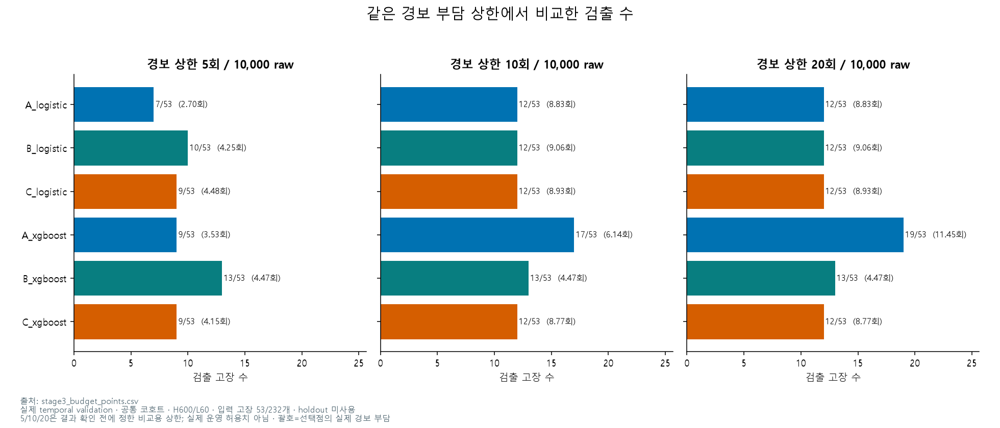

출처: `PHM2018-Project-V3/outputs/figures/stage3/budget_comparison.png`

실제 temporal validation · 공통 코호트 · H600/L60 · 입력 고장 53/232개 · holdout 미사용
5/10/20은 결과 확인 전에 정한 비교용 상한; 실제 운영 허용치 아님 · 괄호=선택점의 실제 경보 부담

<a id="fig-062"></a>

**특징 추가에 따른 대응 검출률 차이와 불확실성**

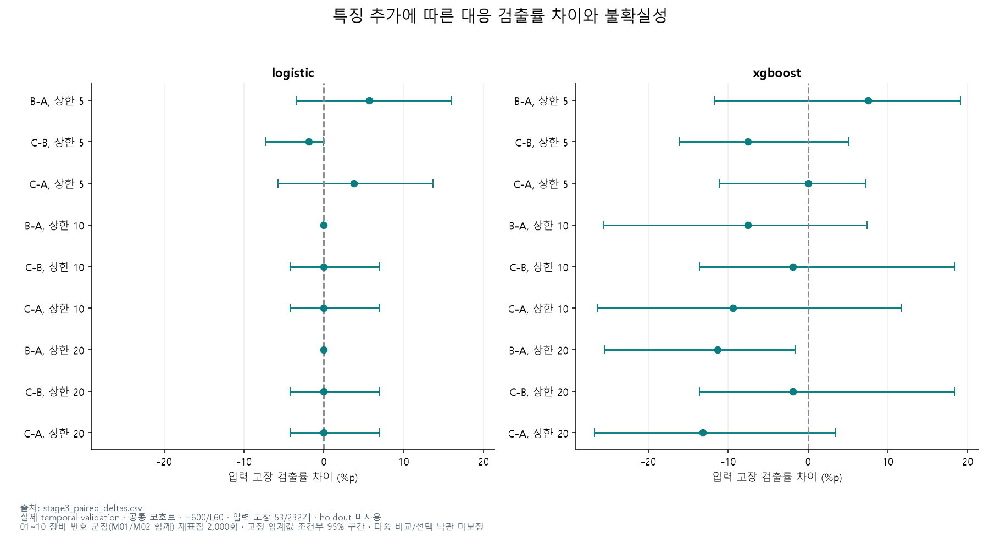

출처: `PHM2018-Project-V3/outputs/figures/stage3/paired_differences.png`

실제 temporal validation · 공통 코호트 · H600/L60 · 입력 고장 53/232개 · holdout 미사용
01~10 장비 번호 군집(M01/M02 함께) 재표집 2,000회 · 고정 임계값 조건부 95% 구간 · 다중 비교/선택 낙관 미보정

<a id="fig-063"></a>

**CUDA 학습 이력과 로컬 메모리 사용**

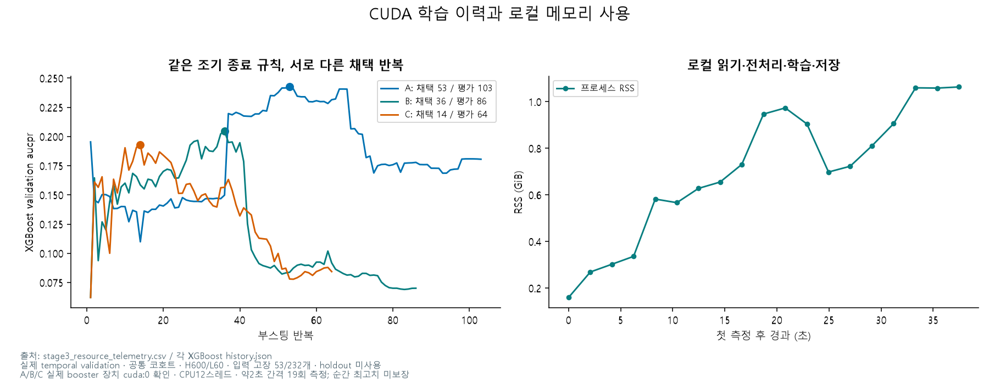

출처: `PHM2018-Project-V3/outputs/figures/stage3/training_resources.png`

실제 temporal validation · 공통 코호트 · H600/L60 · 입력 고장 53/232개 · holdout 미사용
A/B/C 실제 booster 장치 cuda:0 확인 · CPU12스레드 · 약2초 간격 19회 측정; 순간 최고치 미보장

<a id="fig-064"></a>

**같은 고장 이벤트별 검출·미탐 대조**

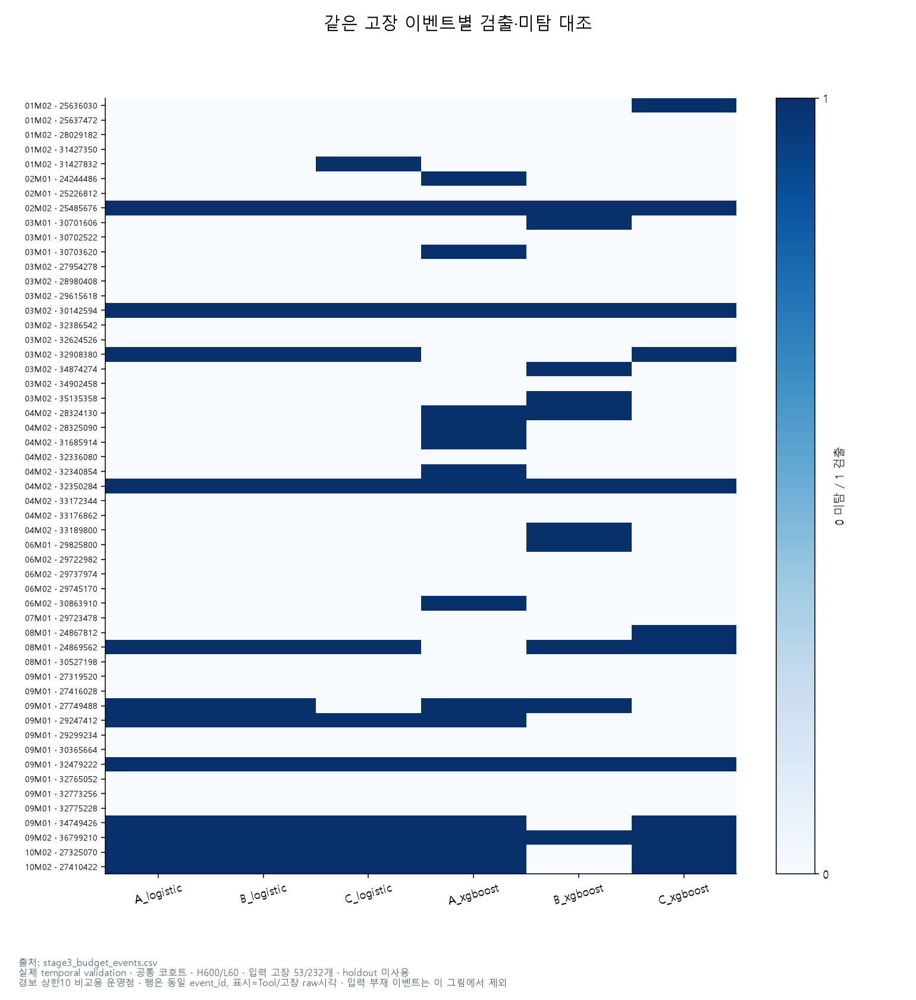

출처: `PHM2018-Project-V3/outputs/figures/stage3/event_matrix.png`

실제 temporal validation · 공통 코호트 · H600/L60 · 입력 고장 53/232개 · holdout 미사용
경보 상한10 비교용 운영점 · 행은 동일 event_id, 표시=Tool/고장 raw시각 · 입력 부재 이벤트는 이 그림에서 제외

<a id="section-11"></a>

## 11. 깊이/양성 가중치와 seed 민감도

seed42에서 A/B 깊이2/3/4×가중1/√(train NEG/POS)의12개 설정을 탐색하고 후보 설정을 고정한 뒤43/44를 확인했습니다. 새 CUDA 학습18개와 기존 기준3개를 재사용한21개 실행 결과입니다. 상한10에서 기존 A 검출17/19/19개, 조정 A21/17/15개로 개선이 seed43/44에 유지되지 않았습니다. seed별 임계값 재선택과 seed42 숫자 임계값 이전을 구분했습니다. B seed43은 일부 고정 임계값에서 경보와 검출이0이었습니다. 좋은 seed로 사후 교체하지 않았습니다.

In [12]:
show('stage4_training_summary',rows=24)
show('stage4_seed_ranges',rows=40)
show('stage4_retuned_points',columns=['config_id','seed','budget_per_10000_raw','detected_events','alarm_episodes_per_10000_raw'],rows=24)
fixed=T('stage4_fixed_points');show_frame(fixed[fixed.exceeds_budget][['config_id','seed','budget_per_10000_raw','detected_events','alarm_episodes_per_10000_raw','exceeds_budget']])

**stage4_training_summary** · 전체 21행 × 23열

,run_id,config_id,feature_set,model,depth,weight_mode,positive_weight,seed,device,reused_stage3,phase,train_rows,train_positive,validation_all_rows,validation_known_rows,validation_positive,encoded_features,iterations,train_seconds,AP_known,ROC_AUC_known,log_loss_known,artifact_roundtrip_passed
0,A_d2_unit_s42,A_d2_unit,A,xgboost,2,unit,1.00000,42,cuda:0,False,grid,309273,1239,309203,7158,392,233,68,0.573747,0.311415,0.549518,0.283162,True
1,A_d2_sqrt_train_neg_pos_s42,A_d2_sqrt_train_neg_pos,A,xgboost,2,sqrt_train_neg_pos,15.76753,42,cuda:0,False,grid,309273,1239,309203,7158,392,233,102,0.499357,0.352697,0.627713,0.207432,True
2,A_d3_unit_s42,A_d3_unit,A,xgboost,3,unit,1.00000,42,cuda:0,True,grid,309273,1239,309203,7158,392,233,53,0.000000,0.245622,0.585560,0.279724,True
3,A_d3_sqrt_train_neg_pos_s42,A_d3_sqrt_train_neg_pos,A,xgboost,3,sqrt_train_neg_pos,15.76753,42,cuda:0,False,grid,309273,1239,309203,7158,392,233,47,0.429397,0.381319,0.726525,0.211383,True
4,A_d4_unit_s42,A_d4_unit,A,xgboost,4,unit,1.00000,42,cuda:0,False,grid,309273,1239,309203,7158,392,233,6,0.314325,0.256085,0.553900,0.296091,True
5,A_d4_sqrt_train_neg_pos_s42,A_d4_sqrt_train_neg_pos,A,xgboost,4,sqrt_train_neg_pos,15.76753,42,cuda:0,False,grid,309273,1239,309203,7158,392,233,1,0.299934,0.259144,0.684313,0.249726,True
6,B_d2_unit_s42,B_d2_unit,B,xgboost,2,unit,1.00000,42,cuda:0,False,grid,309273,1239,309203,7158,392,257,13,0.772590,0.206229,0.488094,0.294763,True
7,B_d2_sqrt_train_neg_pos_s42,B_d2_sqrt_train_neg_pos,B,xgboost,2,sqrt_train_neg_pos,15.76753,42,cuda:0,False,grid,309273,1239,309203,7158,392,257,54,0.697660,0.374046,0.566335,0.208974,True
8,B_d3_unit_s42,B_d3_unit,B,xgboost,3,unit,1.00000,42,cuda:0,True,grid,309273,1239,309203,7158,392,257,36,0.000000,0.206897,0.513422,0.277394,True
9,B_d3_sqrt_train_neg_pos_s42,B_d3_sqrt_train_neg_pos,B,xgboost,3,sqrt_train_neg_pos,15.76753,42,cuda:0,False,grid,309273,1239,309203,7158,392,257,2,0.546984,0.337706,0.533104,0.246161,True


**stage4_seed_ranges** · 전체 32행 × 9열

,mode,config_id,budget_per_10000_raw,detected_min,detected_max,detected_mean,burden_min,burden_max,exceeding_seeds
0,retuned,A_d2_sqrt_train_neg_pos,0.5,1.0,1.0,1.000000,0.001121,0.009530,0
1,retuned,A_d2_sqrt_train_neg_pos,5.0,4.0,10.0,7.666667,2.346088,4.342926,0
2,retuned,A_d2_sqrt_train_neg_pos,10.0,15.0,21.0,17.666667,5.997800,8.854029,0
3,retuned,A_d2_sqrt_train_neg_pos,20.0,17.0,21.0,19.333333,6.604364,10.864321,0
4,retuned,A_d3_unit,0.5,0.0,2.0,1.000000,0.000000,0.361023,0
5,retuned,A_d3_unit,5.0,7.0,10.0,8.666667,2.297316,4.022265,0
6,retuned,A_d3_unit,10.0,17.0,19.0,18.333333,5.928287,6.403110,0
7,retuned,A_d3_unit,20.0,19.0,19.0,19.000000,5.928287,11.445658,0
8,retuned,B_d3_unit,0.5,3.0,8.0,5.000000,0.206859,0.455763,0
9,retuned,B_d3_unit,5.0,8.0,13.0,10.333333,0.455763,4.469620,0


**stage4_retuned_points** · 전체 48행 × 5열 · 앞 24행 표시, 전체 값은 `T('stage4_retuned_points')`로 조회

,config_id,seed,budget_per_10000_raw,detected_events,alarm_episodes_per_10000_raw
0,A_d2_sqrt_train_neg_pos,42,0.5,1.0,0.001121
1,A_d2_sqrt_train_neg_pos,42,5.0,9.0,4.342926
2,A_d2_sqrt_train_neg_pos,42,10.0,21.0,6.604364
3,A_d2_sqrt_train_neg_pos,42,20.0,21.0,6.604364
4,A_d3_unit,42,0.5,1.0,0.020742
5,A_d3_unit,42,5.0,9.0,3.527821
6,A_d3_unit,42,10.0,17.0,6.135707
7,A_d3_unit,42,20.0,19.0,11.445658
8,B_d3_unit,42,0.5,3.0,0.354856
9,B_d3_unit,42,5.0,13.0,4.469620


,config_id,seed,budget_per_10000_raw,detected_events,alarm_episodes_per_10000_raw,exceeds_budget
44,C_d3_unit,44,0.5,5.0,1.491181,True
45,C_d3_unit,44,5.0,14.0,6.852707,True
46,C_d3_unit,44,10.0,13.0,10.225244,True


<a id="fig-065"></a>

**깊이와 양성 가중치의 제한 탐색: seed42**

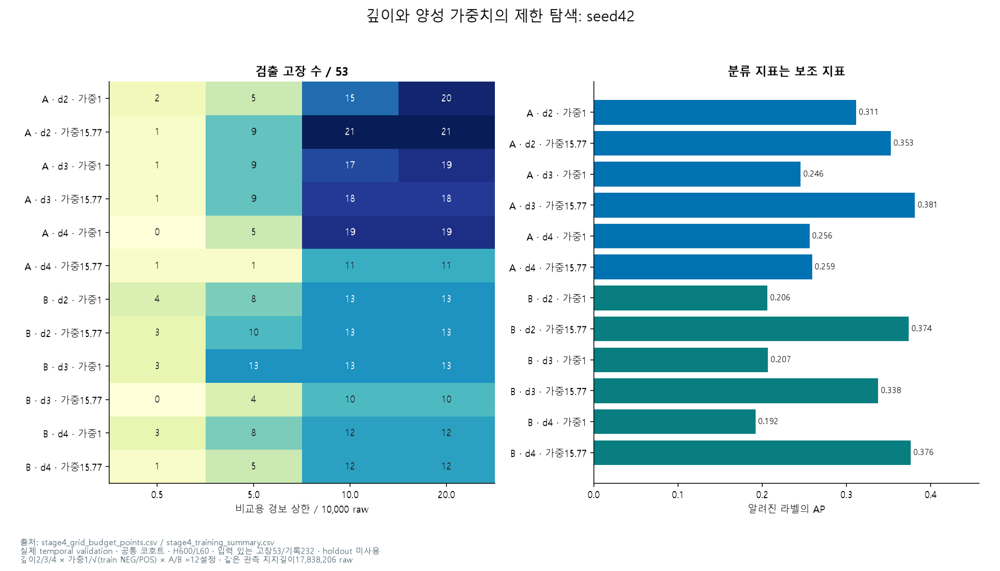

출처: `PHM2018-Project-V3/outputs/figures/stage4/search_grid.png`

실제 temporal validation · 공통 코호트 · H600/L60 · 입력 있는 고장53/기록232 · holdout 미사용
깊이2/3/4 × 가중1/√(train NEG/POS) × A/B =12설정 · 같은 관측 지지길이17,838,206 raw

<a id="fig-066"></a>

**seed를 바꾸면 검출 수가 얼마나 달라지는가**

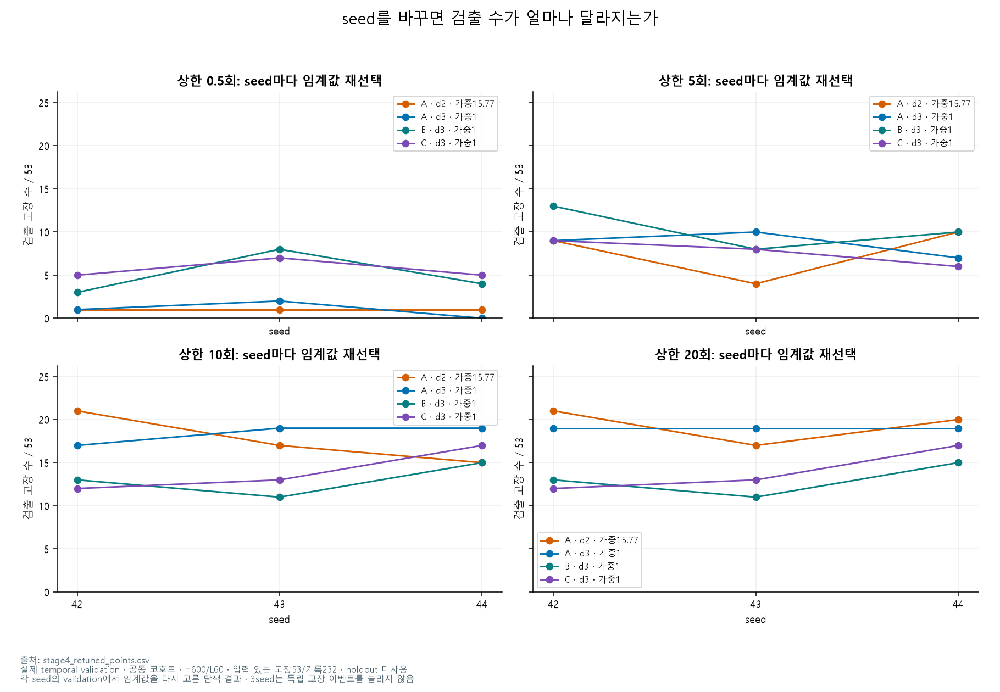

출처: `PHM2018-Project-V3/outputs/figures/stage4/retuned_seed.png`

실제 temporal validation · 공통 코호트 · H600/L60 · 입력 있는 고장53/기록232 · holdout 미사용
각 seed의 validation에서 임계값을 다시 고른 탐색 결과 · 3seed는 독립 고장 이벤트를 늘리지 않음

<a id="fig-067"></a>

**같은 임계값을 다른 seed 모델에 옮겼을 때**

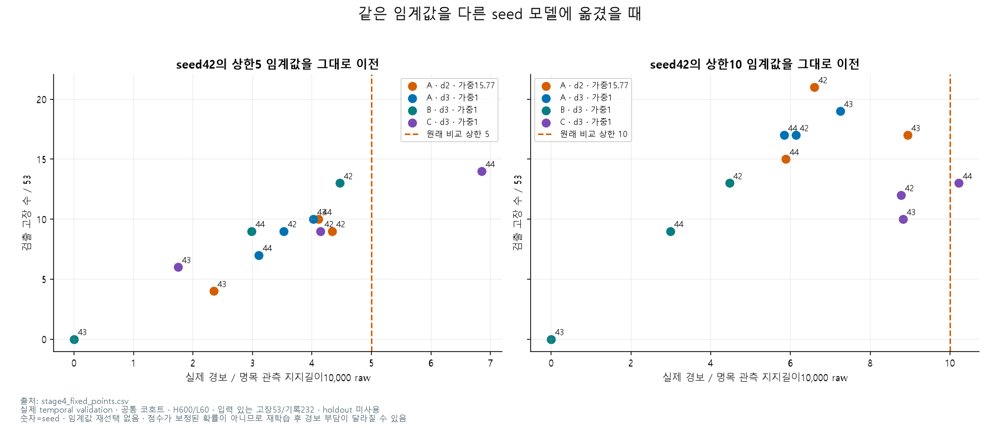

출처: `PHM2018-Project-V3/outputs/figures/stage4/fixed_threshold.png`

실제 temporal validation · 공통 코호트 · H600/L60 · 입력 있는 고장53/기록232 · holdout 미사용
숫자=seed · 임계값 재선택 없음 · 점수가 보정된 확률이 아니므로 재학습 후 경보 부담이 달라질 수 있음

<a id="fig-068"></a>

**선택된 조정의 개선이 다른 seed에서도 유지되는가**

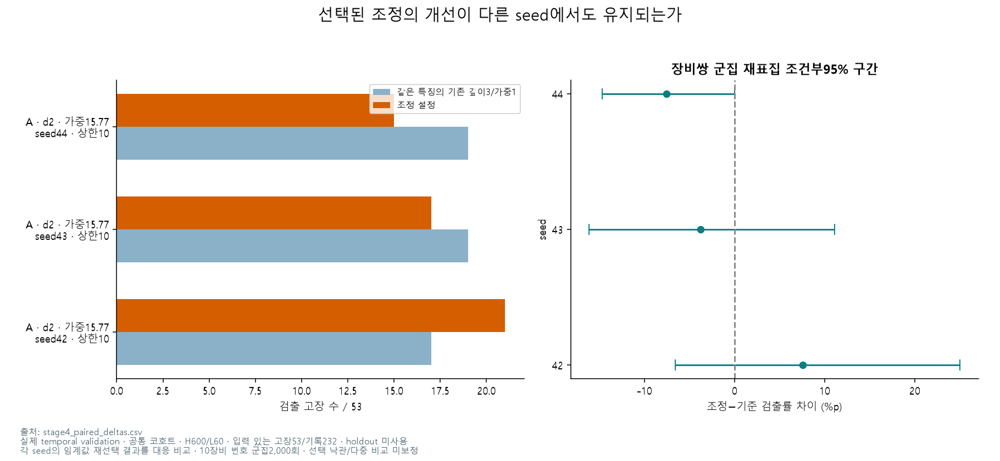

출처: `PHM2018-Project-V3/outputs/figures/stage4/paired_gain.png`

실제 temporal validation · 공통 코호트 · H600/L60 · 입력 있는 고장53/기록232 · holdout 미사용
각 seed의 임계값 재선택 결과를 대응 비교 · 10장비 번호 군집2,000회 · 선택 낙관/다중 비교 미보정

<a id="fig-069"></a>

**A/B 조정과 C 기준을 함께 본 비지배 후보**

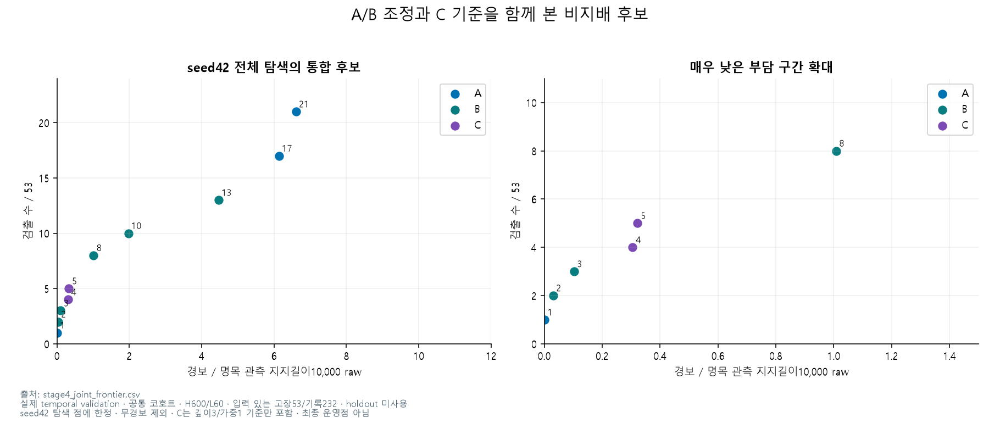

출처: `PHM2018-Project-V3/outputs/figures/stage4/joint_frontier.png`

실제 temporal validation · 공통 코호트 · H600/L60 · 입력 있는 고장53/기록232 · holdout 미사용
seed42 탐색 점에 한정 · 무경보 제외 · C는 깊이3/가중1 기준만 포함 · 최종 운영점 아님

<a id="fig-070"></a>

**튜닝 후에도 미확인 구간의 경보를 분리한다**

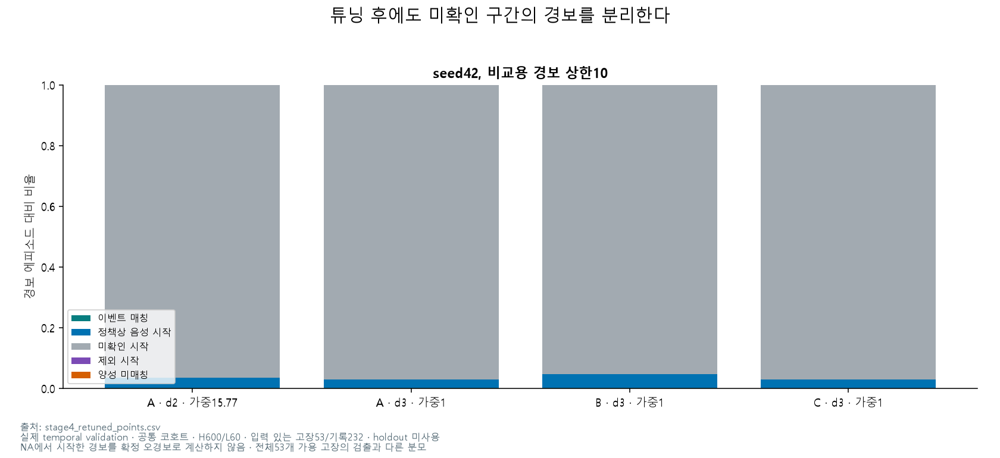

출처: `PHM2018-Project-V3/outputs/figures/stage4/unknown_alarms.png`

실제 temporal validation · 공통 코호트 · H600/L60 · 입력 있는 고장53/기록232 · holdout 미사용
NA에서 시작한 경보를 확정 오경보로 계산하지 않음 · 전체53개 가용 고장의 검출과 다른 분모

<a id="fig-071"></a>

**CUDA 학습과 선택 설정의 조기 종료 변동**

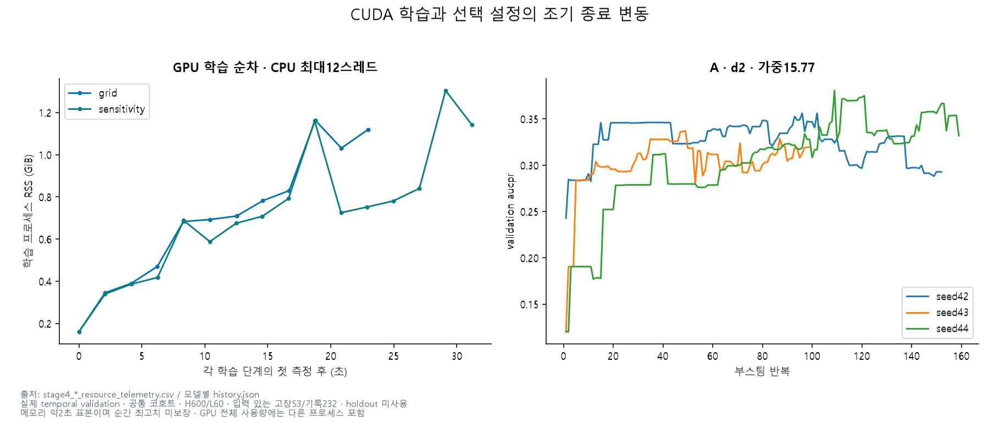

출처: `PHM2018-Project-V3/outputs/figures/stage4/training_resources.png`

실제 temporal validation · 공통 코호트 · H600/L60 · 입력 있는 고장53/기록232 · holdout 미사용
메모리 약2초 표본이며 순간 최고치 미보장 · GPU 전체 사용량에는 다른 프로세스 포함

<a id="fig-072"></a>

**같은 고장53개의 seed별 검출·미탐**

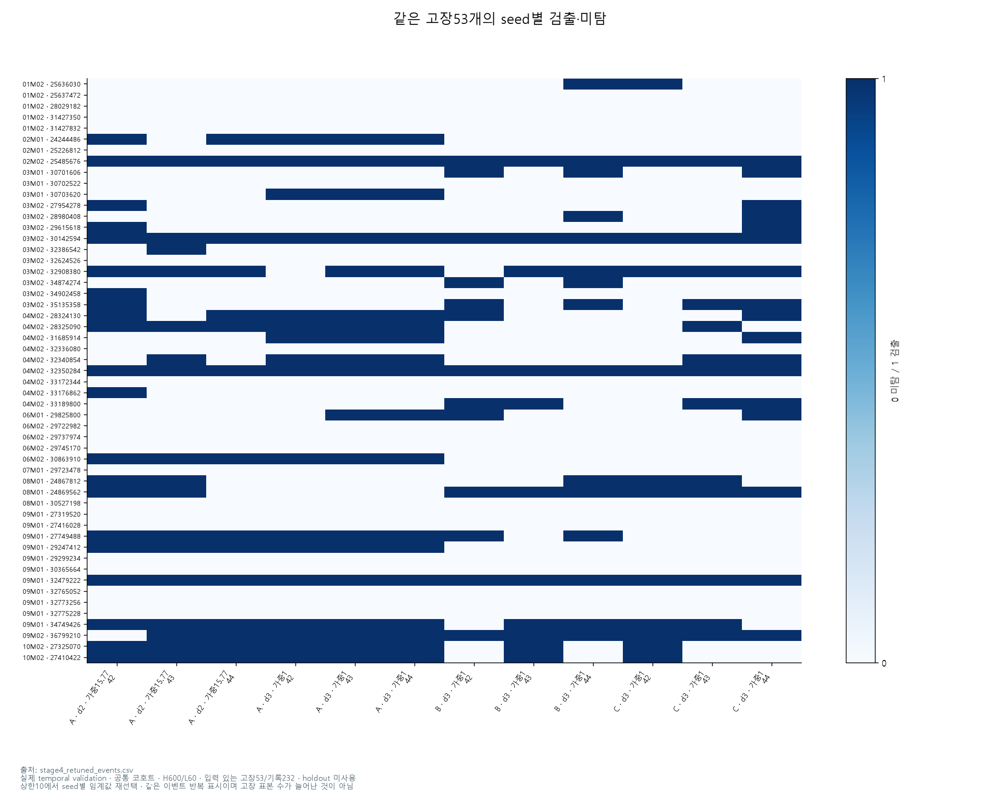

출처: `PHM2018-Project-V3/outputs/figures/stage4/event_matrix.png`

실제 temporal validation · 공통 코호트 · H600/L60 · 입력 있는 고장53/기록232 · holdout 미사용
상한10에서 seed별 임계값 재선택 · 같은 이벤트 반복 표시이며 고장 표본 수가 늘어난 것이 아님

<a id="section-12"></a>

## 12. 최종 시간 구간을 보호한 장비 그룹 검증

앞80%에서01–06의12대만 학습,07–08의4대를 validation으로 사용했습니다. 최대가용 A/B와 공통 A/B/조정A/C의6개 모델을 CUDA 학습했습니다. 최종 시간 뒤20%는 이 실험에서 제외했습니다. 그룹 validation은 조기 종료·임계값 선택에 사용하고 앞선 연구에서 해당 장비를 이미 봤으므로 완전 미사용 외부 장비 시험은 아닙니다. B 최대가용은5/56개(기록121개)를 검출해 일반화가 약했습니다.

In [13]:
show('stage5_training_summary')
g=T('stage5_budget_points');show_frame(g[g.budget_per_10000_raw.isin([5,10])][['run_id','budget_per_10000_raw','detected_events','available_events','recorded_events','alarm_episodes_per_10000_raw']])

**stage5_training_summary** · 전체 6행 × 18열

,run_id,family,cohort,depth,weight_mode,device,positive_weight,train_rows,train_positive,validation_all_rows,validation_known_rows,validation_positive,iterations,encoded_features,train_seconds,AP_known,ROC_AUC_known,log_loss_known
0,A_base_maximum,A,maximum,3,unit,cuda:0,1.000000,588409,2097,1031622,321168,425,10,349,0.661178,0.001622,0.548903,0.012580
1,B_base_maximum,B,maximum,3,unit,cuda:0,1.000000,446724,1807,664295,213592,371,49,371,1.427280,0.005288,0.512233,0.015377
2,A_base_common,A,common,3,unit,cuda:0,1.000000,246923,1185,165040,62704,235,98,185,0.812388,0.094469,0.586055,0.028097
3,B_base_common,B,common,3,unit,cuda:0,1.000000,246923,1185,165040,62704,235,28,209,0.887434,0.041373,0.521478,0.025775
4,A_tuned_common,A,common,2,sqrt_train_neg_pos,cuda:0,14.400481,246923,1185,165040,62704,235,24,185,0.529179,0.013671,0.557121,0.111313
5,C_base_common,C,common,3,unit,cuda:0,1.000000,246923,1185,165040,62704,235,56,221,1.199729,0.041440,0.511810,0.027332


,run_id,budget_per_10000_raw,detected_events,available_events,recorded_events,alarm_episodes_per_10000_raw
1,A_base_common,5.0,1.0,37.0,121.0,3.819120
2,A_base_common,10.0,6.0,37.0,121.0,8.211107
5,A_base_maximum,5.0,0.0,56.0,121.0,0.000000
6,A_base_maximum,10.0,7.0,56.0,121.0,5.264424
9,A_tuned_common,5.0,0.0,37.0,121.0,0.000000
10,A_tuned_common,10.0,5.0,37.0,121.0,8.736236
13,B_base_common,5.0,7.0,37.0,121.0,3.492541
14,B_base_common,10.0,7.0,37.0,121.0,3.492541
17,B_base_maximum,5.0,5.0,56.0,121.0,2.992834
18,B_base_maximum,10.0,5.0,56.0,121.0,2.992834


<a id="fig-073"></a>

**미래 Holdout을 보호한 장비 그룹 검증**

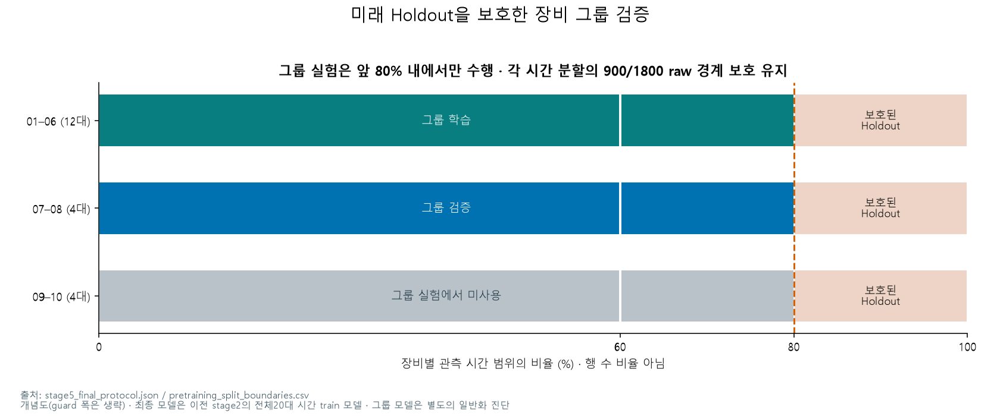

출처: `PHM2018-Project-V3/outputs/figures/final_evaluation/protected_split.png`

개념도(guard 폭은 생략) · 최종 모델은 이전 stage2의 전체20대 시간 train 모델 · 그룹 모델은 별도의 일반화 진단

<a id="fig-074"></a>

**다른 장비에서의 검출력은 여전히 제한적**

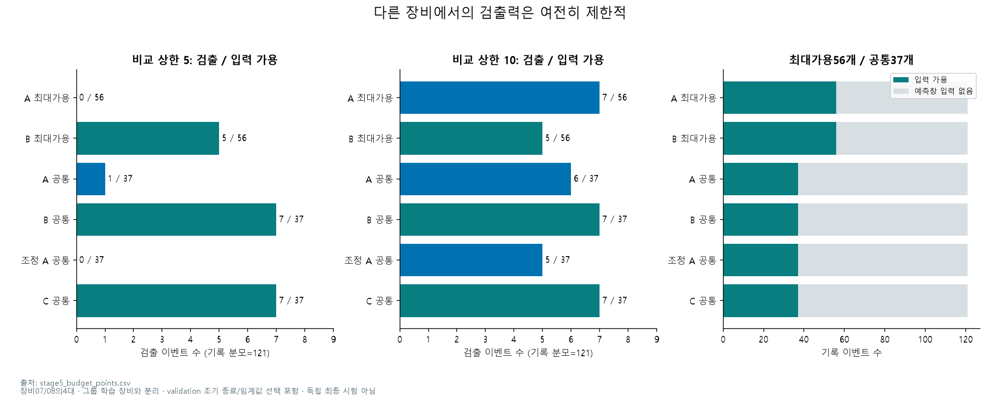

출처: `PHM2018-Project-V3/outputs/figures/final_evaluation/group_results.png`

장비07/08의4대 · 그룹 학습 장비와 분리 · validation 조기 종료/임계값 선택 포함 · 독립 최종 시험 아님

<a id="section-13"></a>

## 13. 모델/임계값 동결과 최종 시간 평가

사전 규칙에 따라 상한5/10에서 시간·그룹 validation 중 낮은 기록 검출률을 평균해 A/B 중 B를 선정했습니다. 최종 모델은20대의 시간 train을 합쳐 학습한 기존 stage2 B 공통 모델(seed42,깊이3,가중1,선택2트리)입니다. train+validation 재학습 없이 모델/전처리와 두 숫자 임계값을 동결한 뒤 뒤20%를 한 번 추론했습니다. 기록194개 중 가용91개, 검출7개/33개입니다. 전체 원본 품질 진단은 이전에 확인했으므로 완전 맹검 외부 시험은 아닙니다. 단계7에서 이미 확인한 후반을 연구에 재사용한 사실도 별도로 표시합니다.

In [14]:
show('stage6_selection_ranking')
show('stage6_selection_evidence')
F=J('PHM2018-Project-V3/outputs/stage6/frozen_manifest.json');A=J('PHM2018-Project-V3/outputs/stage6/holdout_access.json')
from datetime import datetime
assert datetime.fromisoformat(F['frozen_at_utc'])<datetime.fromisoformat(A['opened_at_utc'])
assert A['full_prediction_passes']==1 and not A['threshold_search'] and not A['refit']
show_frame(pd.DataFrame(F['operating_points']))
h=T('stage6_holdout_summary');show_frame(h[['operating_point','threshold','detected_events','recorded_events','available_events','recall_recorded','recall_available','alarm_episodes','alarm_episodes_per_10000_raw','median_lead_raw']])
assert h.detected_events.tolist()==[7.0,33.0] and h.recorded_events.eq(194).all()
for p in F['operating_points']:assert h[h.operating_point.eq(p['operating_point'])].threshold.iloc[0]==p['threshold']
show('stage6_holdout_uncertainty')
show('stage6_holdout_by_tool',rows=40)
display(J('PHM2018-Project-V3/outputs/stage6/holdout_classification.json'))

**stage6_selection_ranking** · 전체 2행 × 4열

,family,mean_worst_recall,mean_recall,mean_burden
0,B,0.033592,0.063765,4.070504
1,A,0.028017,0.031704,4.091356


**stage6_selection_evidence** · 전체 8행 × 8열

,family,budget_per_10000_raw,validation,detected_events,recorded_events,recall_recorded,actual_burden,threshold
0,A,5,temporal_validation,3,232,0.012931,3.044310,0.010000
1,A,5,protected_group_validation,0,121,0.000000,0.000000,1.000000
2,A,10,temporal_validation,13,232,0.056034,8.056690,0.005533
3,A,10,protected_group_validation,7,121,0.057851,5.264424,0.015853
4,B,5,temporal_validation,6,232,0.025862,0.990719,0.003267
5,B,5,protected_group_validation,5,121,0.041322,2.992834,0.023481
6,B,10,temporal_validation,34,232,0.146552,9.305628,0.002999
7,B,10,protected_group_validation,5,121,0.041322,2.992834,0.023481


,operating_point,validation_budget_per_10000_raw,threshold,validation_detected,validation_recorded,validation_available,validation_actual_burden
0,validation_budget_5,5,0.003267,6,232,95,0.990719
1,validation_budget_10,10,0.002999,34,232,95,9.305628


,operating_point,threshold,detected_events,recorded_events,available_events,recall_recorded,recall_available,alarm_episodes,alarm_episodes_per_10000_raw,median_lead_raw
0,validation_budget_5,0.003267,7.0,194.0,91.0,0.036082,0.076923,3389.0,0.814981,284.0
1,validation_budget_10,0.002999,33.0,194.0,91.0,0.170103,0.362637,41162.0,9.898565,362.0


**stage6_holdout_uncertainty** · 전체 4행 × 7열

,operating_point,denominator,ci_low,ci_high,valid_samples,lead_p10,lead_median
0,validation_budget_5,available,0.031238,0.127673,2000,99.6,284.0
1,validation_budget_5,recorded,0.011493,0.060351,2000,99.6,284.0
2,validation_budget_10,available,0.220768,0.484211,2000,158.4,362.0
3,validation_budget_10,recorded,0.075267,0.255340,2000,158.4,362.0


**stage6_holdout_by_tool** · 전체 40행 × 18열

,recorded_events,tagged_events,scorable_events,available_events,detected_events,alarm_episodes,recall_recorded,recall_scorable,recall_available,alarms_MATCHED,alarms_KNOWN_NEGATIVE_START,alarms_POSITIVE_UNMATCHED,alarms_UNKNOWN_START,alarms_LATE_OR_EXCLUDED_START,median_lead_raw,Tool,observed_support_raw,operating_point
0,4,0,4,1,0,0,0.000000,0.000000,0.000000,0,0,0,0,0,NaN,01M01,1353396.0,validation_budget_5
1,20,0,20,19,2,402,0.100000,0.100000,0.105263,2,0,0,399,1,205.0,01M02,4076034.0,validation_budget_5
2,3,0,3,3,0,61,0.000000,0.000000,0.000000,0,0,0,61,0,NaN,02M01,1246390.0,validation_budget_5
3,4,0,4,0,0,67,0.000000,0.000000,NaN,0,0,0,67,0,NaN,02M02,1889554.0,validation_budget_5
4,6,0,6,2,1,185,0.166667,0.166667,0.500000,2,0,0,183,0,206.0,03M01,1775148.0,validation_budget_5
5,27,0,27,3,0,141,0.000000,0.000000,0.000000,0,0,0,141,0,NaN,03M02,2671668.0,validation_budget_5
6,0,0,0,0,0,114,NaN,NaN,NaN,0,0,0,114,0,NaN,04M01,2417356.0,validation_budget_5
7,18,0,18,13,2,114,0.111111,0.111111,0.153846,2,0,0,112,0,283.0,04M02,3089970.0,validation_budget_5
8,5,0,5,1,0,87,0.000000,0.000000,0.000000,0,0,0,86,1,NaN,05M01,2055240.0,validation_budget_5
9,8,0,8,0,0,655,0.000000,0.000000,NaN,0,0,0,655,0,NaN,05M02,489932.0,validation_budget_5


{'all_anchors': 736646,
 'known_anchors': 32645,
 'positive': 635,
 'AP_known': 0.06540965977293078,
 'ROC_AUC_known': 0.5011752970897381,
 'log_loss_known': 0.11481253057718277,
 'label_counts': {'2': 703931, '0': 32010, '1': 635, '3': 70}}

후반 예측736,646행 저장 후 bool 자료형 집계 오류가 발생했으며, 저장 점수의 bool 자료형만 변환해 집계를 복구했습니다. 추가 전체 추론0회, 재학습0회, 임계값 탐색0회입니다. 예측 파일과 동결 파일 해시를 보존했습니다. 아래 접근/복구 기록은 내장된 원문입니다.

In [15]:
display(J('PHM2018-Project-V3/outputs/stage6/holdout_access.json'))
display(J('PHM2018-Project-V3/outputs/stage6/postprocessing_recovery.json'))

{'status': 'complete',
 'opened_at_utc': '2026-11-05T08:27:27.012925+00:00',
 'frozen_manifest_sha256': 'c211518ae97a6dcc93aa0198caf8ea368fef85efac5386cb3eecaced5ee9b3c1',
 'full_prediction_passes': 1,
 'threshold_search': False,
 'refit': False,
 'completed_at_utc': '2026-11-05T08:35:26.554334+00:00',
 'prediction_sha256': 'cc6cb44efcafb6441c677fff2f0abf8cf0348bf6fdd462ee10e04fee79565221',
 'summary_sha256': '28366a4173ec342a6b43ebff47d1375f4055d8137bd89350d2a8af152f3feb82',
 'postprocessing_recovery': 'outputs/stage6/postprocessing_recovery.json',
 'additional_prediction_passes': 0}

{'started_at_utc': '2026-11-05T08:35:22.106962+00:00',
 'reason': '빈 장비 이벤트 표를 concat한 후 tagged가 object bool이 되어 ~ 연산 실패',
 'correction': '집계 이벤트 tagged/available/detected 열을 bool로 명시 변환',
 'postprocessing_only': True,
 'additional_prediction_passes': 0,
 'model_refit': False,
 'threshold_search': False,
 'input_prediction_sha256': 'cc6cb44efcafb6441c677fff2f0abf8cf0348bf6fdd462ee10e04fee79565221',
 'frozen_manifest_sha256': 'c211518ae97a6dcc93aa0198caf8ea368fef85efac5386cb3eecaced5ee9b3c1',
 'original_failure_log_sha256': '0cb7a4413a0cba809dbaf89fe8b87c7002a3b7446885be059e758b9f1d4a4e31',
 'recovery_script_sha256': '4dcdd4fb23b6f94ada90813bae360e03cc95e6f0bb0c7b305a4ac09e0bd8149c',
 'completed_at_utc': '2026-11-05T08:35:26.554334+00:00',
 'prediction_unchanged': True,
 'frozen_files_unchanged': True}

<a id="fig-075"></a>

**Holdout을 열기 전에 선택한 모델과 기준**

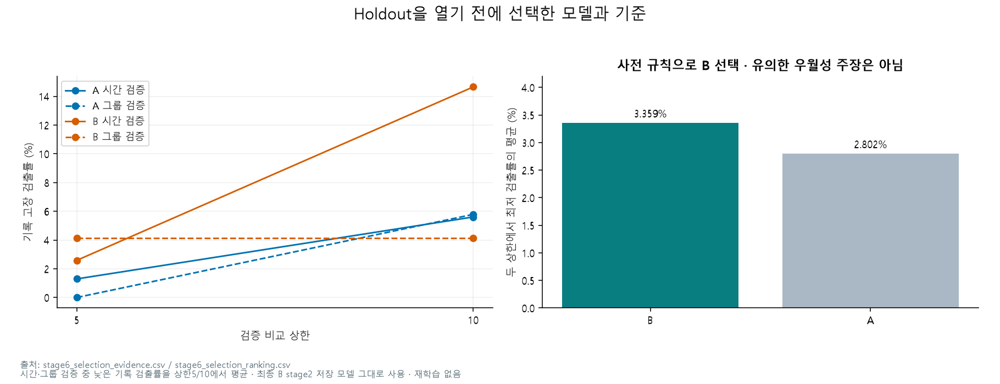

출처: `PHM2018-Project-V3/outputs/figures/final_evaluation/selection.png`

시간·그룹 검증 중 낮은 기록 검출률을 상한5/10에서 평균 · 최종 B stage2 저장 모델 그대로 사용 · 재학습 없음

<a id="fig-076"></a>

**동결한 두 운영점의 최종 시간 Holdout 결과**

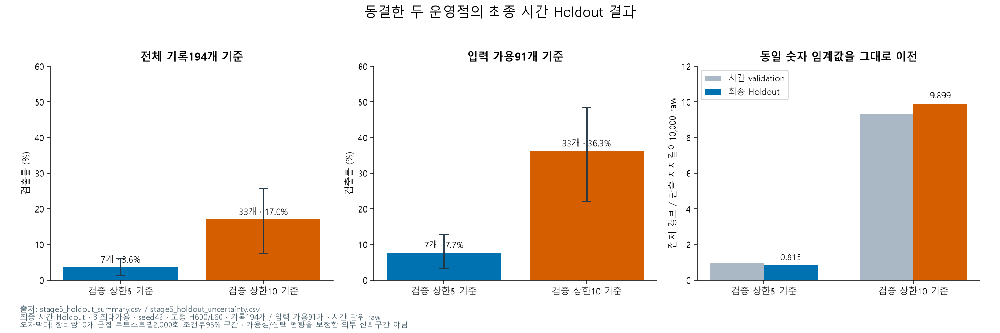

출처: `PHM2018-Project-V3/outputs/figures/final_evaluation/holdout_results.png`

최종 시간 Holdout · B 최대가용 · seed42 · 고정 H600/L60 · 기록194개 / 입력 가용91개 · 시간 단위 raw
오차막대: 장비쌍10개 군집 부트스트랩2,000회 조건부95% 구간 · 가용성/선택 편향을 보정한 외부 신뢰구간 아님

<a id="fig-077"></a>

**경보 부담과 정답 불확실성을 함께 해석해야 한다**

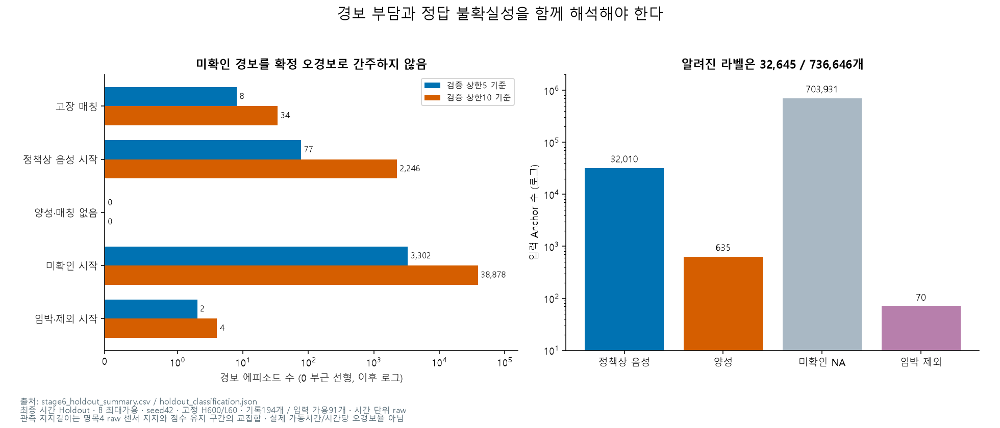

출처: `PHM2018-Project-V3/outputs/figures/final_evaluation/unknown_burden.png`

최종 시간 Holdout · B 최대가용 · seed42 · 고정 H600/L60 · 기록194개 / 입력 가용91개 · 시간 단위 raw
관측 지지길이는 명목4 raw 센서 지지와 점수 유지 구간의 교집합 · 실제 가동시간/시간당 오경보율 아님

<a id="fig-078"></a>

**장비별 검출·미검출·입력 공백**

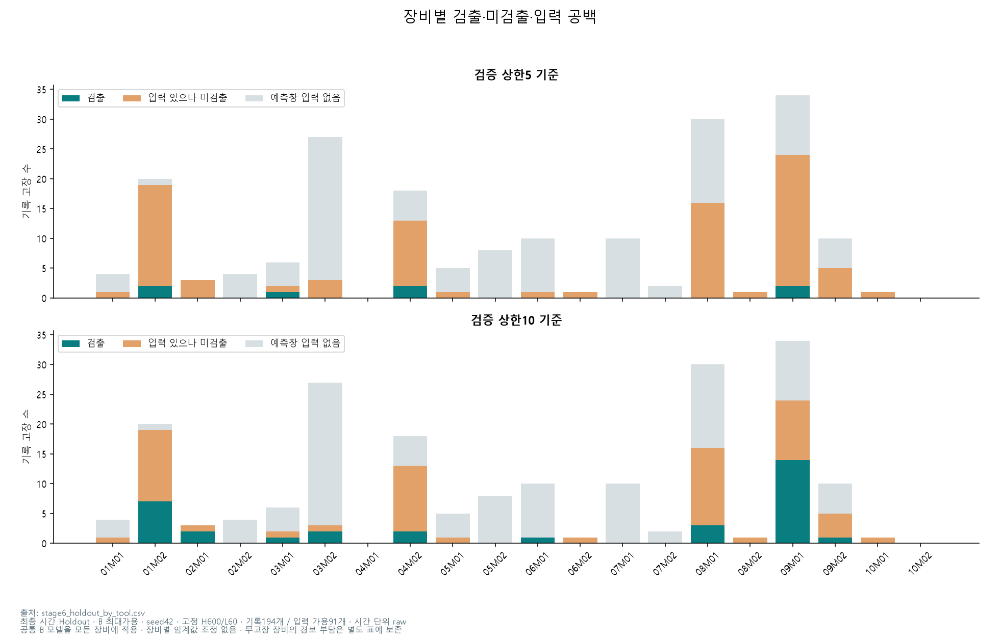

출처: `PHM2018-Project-V3/outputs/figures/final_evaluation/by_tool.png`

최종 시간 Holdout · B 최대가용 · seed42 · 고정 H600/L60 · 기록194개 / 입력 가용91개 · 시간 단위 raw
공통 B 모델을 모든 장비에 적용 · 장비별 임계값 조정 없음 · 무고장 장비의 경보 부담은 별도 표에 보존

<a id="fig-079"></a>

**선행시간과 로컬 CUDA 사용 기록**

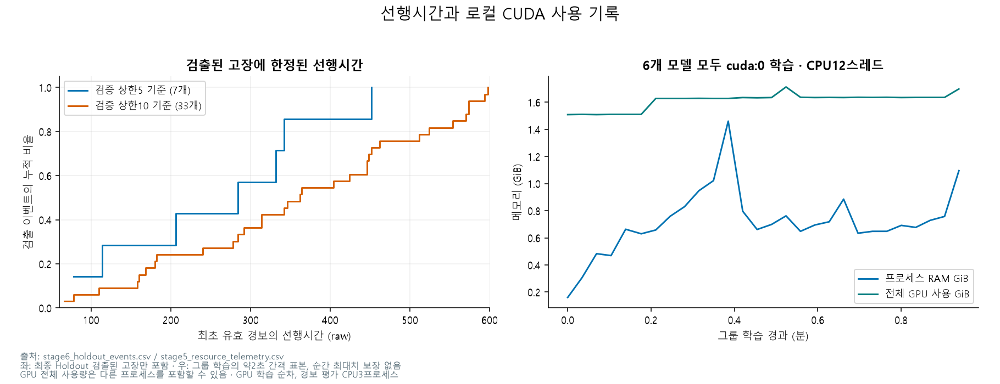

출처: `PHM2018-Project-V3/outputs/figures/final_evaluation/lead_resources.png`

좌: 최종 Holdout 검출된 고장만 포함 · 우: 그룹 학습의 약2초 간격 표본, 순간 최대치 보장 없음
GPU 전체 사용량은 다른 프로세스를 포함할 수 있음 · GPU 학습 순차, 경보 평가 CPU3프로세스

<a id="fig-080"></a>

**실제 센서와 저장 예측으로 확인한 검출·미검출 사례**

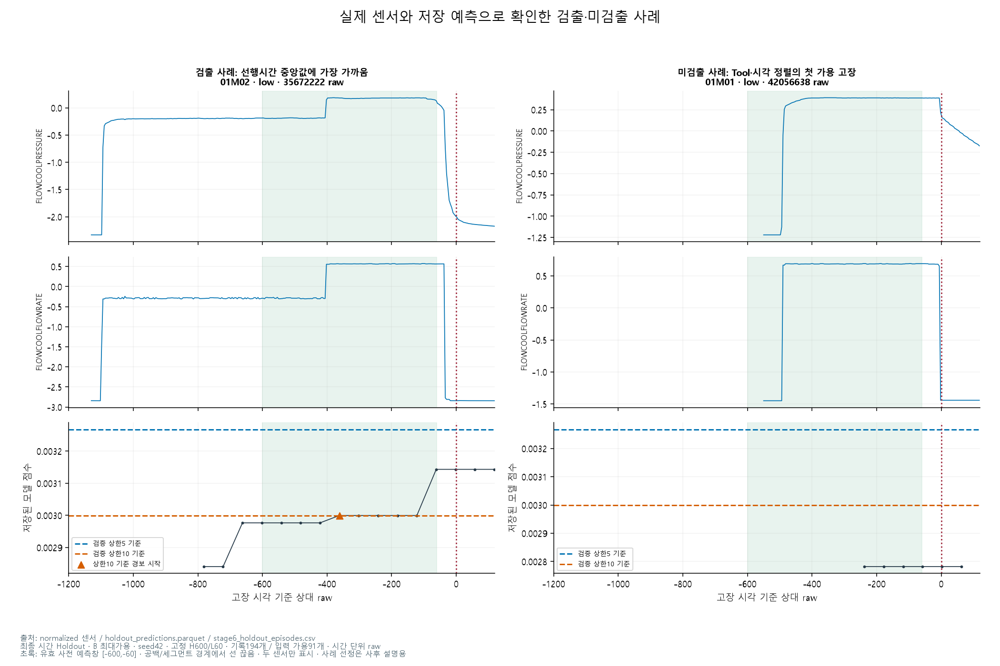

출처: `PHM2018-Project-V3/outputs/figures/final_evaluation/event_cases.png`

최종 시간 Holdout · B 최대가용 · seed42 · 고정 H600/L60 · 기록194개 / 입력 가용91개 · 시간 단위 raw
초록: 유효 사전 예측창 [-600,-60] · 공백/세그먼트 경계에서 선 끊음 · 두 센서만 표시 · 사례 선정은 사후 설명용

<a id="section-14"></a>

## 14. 장비 전용 모델 파일럿: 03M02

최대3대/약20분 범위에서 최소 데이터 기준을 충족한03M02 한 대만 선정했습니다. 학습/검증 고장군집8/3개, 양성100/20행, 음성1,000/1,000행이 기준이었고 결과를 보고 완화하지 않았습니다.03M02 학습123,796행(양성500), validation6,115개 알려진 정답으로 CUDA 전용 모델을 학습했습니다. 기존 공통 모델/장비별 임계값 조정/장비 전용을 같은 입력으로 비교했습니다. **이미 평가한 뒤20%의 후속 연구**이므로 독립 Holdout 성능으로 부르지 않습니다.

In [16]:
show('stage7_eligibility',rows=20)
show('stage7_training_summary')
show('stage7_comparison_display')
show('stage7_paired_events')
show('stage7_later_classification')
s=T('stage7_later_summary');assert s[s.method.eq('specialist')].detected_events.eq(0).all()
display(J('PHM2018-Project-V3/outputs/stage7/evaluation_access.json'))

**stage7_eligibility** · 전체 20행 × 18열

,Tool,train_recorded_events,train_available_events,train_positive_events,train_positive_clusters,train_positive_rows,train_negative_rows,train_all_input_rows,validation_recorded_events,validation_available_events,validation_positive_events,validation_positive_clusters,validation_positive_rows,validation_negative_rows,validation_all_input_rows,eligible,reason,selected
0,01M01,12,6,6,6,37,49023,98447,3,0,0,0,0,0,28349,False,train_positive_clusters=6 < 8; validation_positive_clusters=0 < 3; train_positive_rows...,False
1,01M02,81,41,41,37,338,169404,178892,8,7,7,6,58,0,64845,False,validation_negative_rows=0 < 1000,False
2,02M01,5,4,4,4,20,0,92866,9,3,3,3,21,9805,25241,False,train_positive_clusters=4 < 8; train_positive_rows=20 < 100; train_negative_rows=0 < 1000,False
3,02M02,23,6,6,6,35,0,110194,5,1,1,1,9,0,35341,False,train_positive_clusters=6 < 8; validation_positive_clusters=1 < 3; train_positive_rows...,False
4,03M01,76,14,14,14,90,0,97148,9,3,3,3,28,0,25366,False,train_positive_rows=90 < 100; train_negative_rows=0 < 1000; validation_negative_rows=0...,False
5,03M02,238,83,83,83,500,123296,134198,91,23,23,23,133,5982,41467,True,조건 충족,True
6,04M01,6,6,6,5,38,2490,134367,3,0,0,0,0,0,41601,False,train_positive_clusters=5 < 8; validation_positive_clusters=0 < 3; train_positive_rows...,False
7,04M02,2,2,2,2,18,0,163360,16,10,10,10,87,0,57175,False,train_positive_clusters=2 < 8; train_positive_rows=18 < 100; train_negative_rows=0 < 1...,False
8,05M01,22,10,10,10,52,10555,118175,1,1,1,1,2,0,42060,False,validation_positive_clusters=1 < 3; train_positive_rows=52 < 100; validation_positive_...,False
9,05M02,18,2,2,2,12,28051,50375,1,0,0,0,0,0,12904,False,train_positive_clusters=2 < 8; validation_positive_clusters=0 < 3; train_positive_rows...,False


**stage7_training_summary** · 전체 1행 × 12열

,Tool,device,train_rows,train_positive,validation_all_rows,validation_known_rows,validation_positive,iterations,train_seconds,AP_known,ROC_AUC_known,log_loss_known
0,03M02,cuda:0,123796,500,41467,6115,133,1,0.518429,0.034911,0.548815,0.123639


**stage7_comparison_display** · 전체 6행 × 10열

,장비,방식,검증 비교상한,동결 임계값,검출,기록 고장,입력 가용 고장,전체 경보,경보/10000 raw,미확인 시작 경보
0,03M02,장비 전용,5,0.0043878452852368355,0,27,3,228,0.853399,228
1,03M02,장비 전용,10,0.0042405198328197002,0,27,3,289,1.081721,289
2,03M02,공통·장비별 임계값,5,0.0032673857640475035,0,27,3,141,0.527760,141
3,03M02,공통·장비별 임계값,10,0.0032673857640475035,0,27,3,141,0.527760,141
4,03M02,공통·기존 임계값,5,0.0032673857640475035,0,27,3,141,0.527760,141
5,03M02,공통·기존 임계값,10,0.002999492222443223,2,27,3,5411,20.253265,5409


**stage7_paired_events** · 전체 4행 × 9열

,Tool,budget,control,recorded,available,both_detected,specialist_only,control_only,neither
0,03M02,5,global_frozen,27,3,0,0,0,27
1,03M02,5,global_tool_threshold,27,3,0,0,0,27
2,03M02,10,global_frozen,27,3,0,0,2,25
3,03M02,10,global_tool_threshold,27,3,0,0,0,27


**stage7_later_classification** · 전체 2행 × 7열

,Tool,method,all_rows,known_rows,positive,AP_known,ROC_AUC_known
0,03M02,specialist,48164,21,21,NaN,NaN
1,03M02,global,48164,21,21,NaN,NaN


{'status': 'complete',
 'opened_at_utc': '2026-11-05T09:04:15.599192+00:00',
 'independent_final_test': False,
 'reference_predictions_reused': True,
 'specialist_prediction_passes_per_tool': 1,
 'threshold_search_on_later_partition': False,
 'refit': False,
 'frozen_manifest_sha256': '26953e9a71e8f7c51da8047bf1e33d17e1cdfdbcbd5ea28ef1456ecda2e1d7c7',
 'completed_at_utc': '2026-11-05T09:04:17.012463+00:00',
 'prediction_sha256': {'03M02': '756b210aed82375f33d162043bcfb4d02c286d77aada77cc650004358a8d92ff'},
 'summary_sha256': '9e3ce56732121db9b965792233ed5f1bece3fc8576ec6a6c81b99e6127a867ed'}

전용 모델은0/27개(입력 가용3개 중0개)를 검출했고 경보228/289개를 냈습니다. 공통·장비별 임계값도0개/141경보였습니다. 기존 공통 높은 설정은2개를 검출했지만5,411경보·20.253/10,000 raw로 장비별 비교 상한10을 넘었습니다. 따라서 동일 부담에서의 우월성 비교가 아닙니다. 후반 알려진 정답21행은 모두 양성이므로 AP/ROC-AUC는 미산출입니다. 전용 모델을 공통 모델의 대체로 채택할 근거는 확인되지 않았습니다.

<a id="fig-081"></a>

**20대 중 최소 학습·검증 조건을 충족한 장비는03M02**

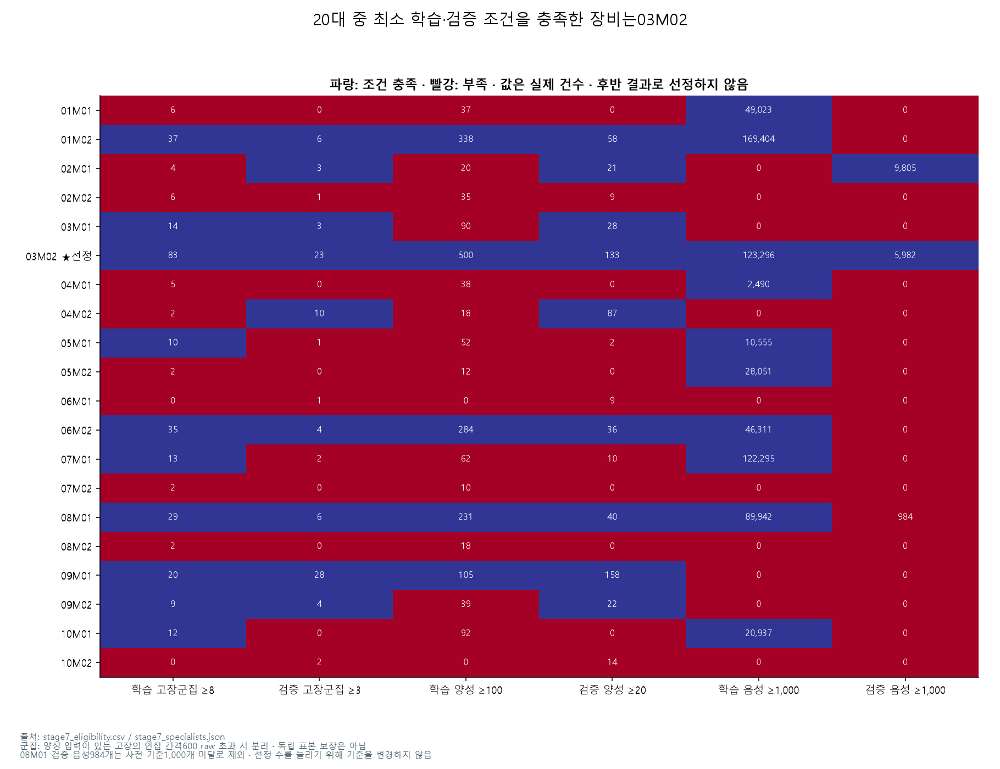

출처: `PHM2018-Project-V3/outputs/figures/stage7/eligibility.png`

군집: 양성 입력이 있는 고장의 인접 간격600 raw 초과 시 분리 · 독립 표본 보장은 아님
08M01 검증 음성984개는 사전 기준1,000개 미달로 제외 · 선정 수를 늘리기 위해 기준을 변경하지 않음

<a id="fig-082"></a>

**학습 데이터가 충분해도 후반 평가 입력은 부족할 수 있다**

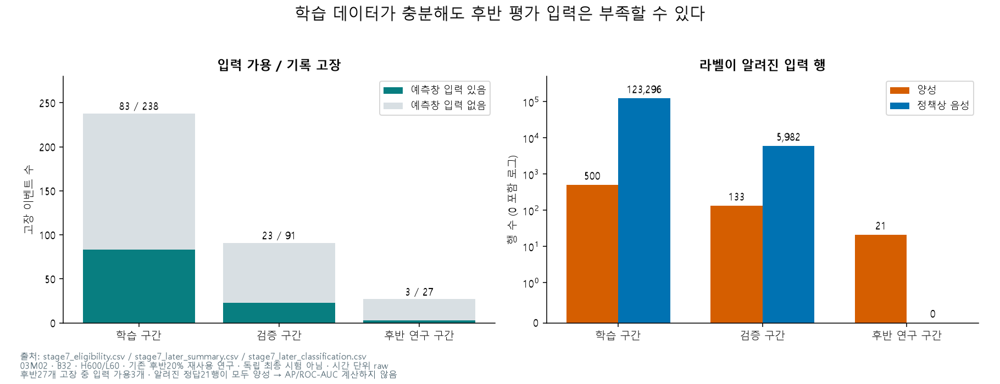

출처: `PHM2018-Project-V3/outputs/figures/stage7/coverage.png`

03M02 · B32 · H600/L60 · 기존 후반20% 재사용 연구 · 독립 최종 시험 아님 · 시간 단위 raw
후반27개 고장 중 입력 가용3개 · 알려진 정답21행이 모두 양성 → AP/ROC-AUC 계산하지 않음

<a id="fig-083"></a>

**전용 모델 학습 효과와 장비별 임계값 조정 효과의 비교**

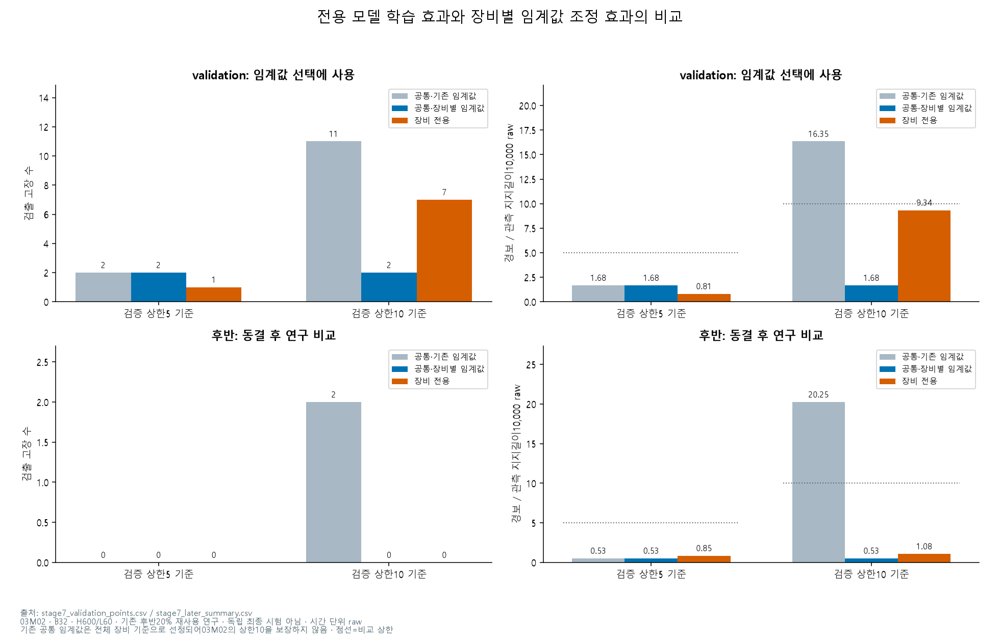

출처: `PHM2018-Project-V3/outputs/figures/stage7/comparison.png`

03M02 · B32 · H600/L60 · 기존 후반20% 재사용 연구 · 독립 최종 시험 아님 · 시간 단위 raw
기존 공통 임계값은 전체 장비 기준으로 선정되어03M02의 상한10을 보장하지 않음 · 점선=비교 상한

<a id="fig-084"></a>

**전용 모델의 조기 종료와 시점별 점수 분포**

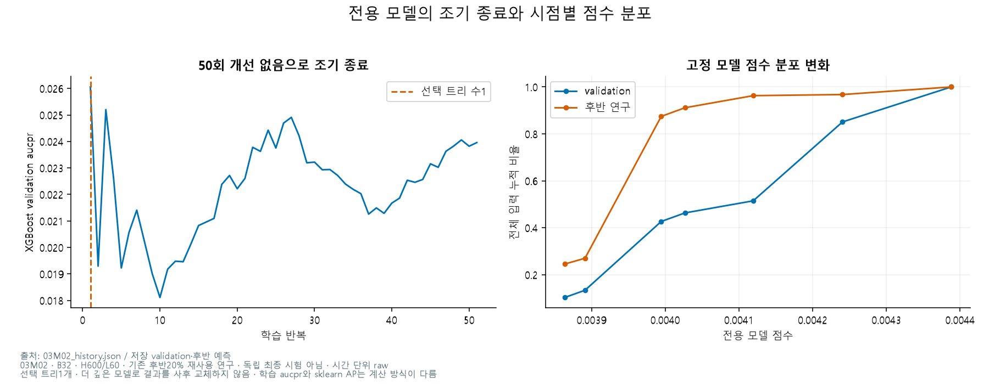

출처: `PHM2018-Project-V3/outputs/figures/stage7/learning.png`

03M02 · B32 · H600/L60 · 기존 후반20% 재사용 연구 · 독립 최종 시험 아님 · 시간 단위 raw
선택 트리1개 · 더 깊은 모델로 결과를 사후 교체하지 않음 · 학습 aucpr와 sklearn AP는 계산 방식이 다름

<a id="fig-085"></a>

**공통 모델의 두 고장 검출에는 높은 미확인 경보 부담이 동반됐다**

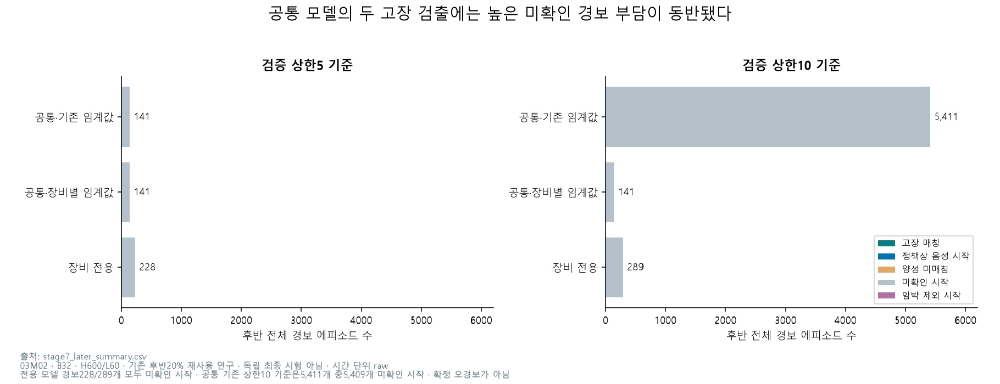

출처: `PHM2018-Project-V3/outputs/figures/stage7/alarm_burden.png`

03M02 · B32 · H600/L60 · 기존 후반20% 재사용 연구 · 독립 최종 시험 아님 · 시간 단위 raw
전용 모델 경보228/289개 모두 미확인 시작 · 공통 기존 상한10 기준은5,411개 중5,409개 미확인 시작 · 확정 오경보가 아님

<a id="fig-086"></a>

**동일 센서 구간에서 공통·전용 모델의 점수 비교**

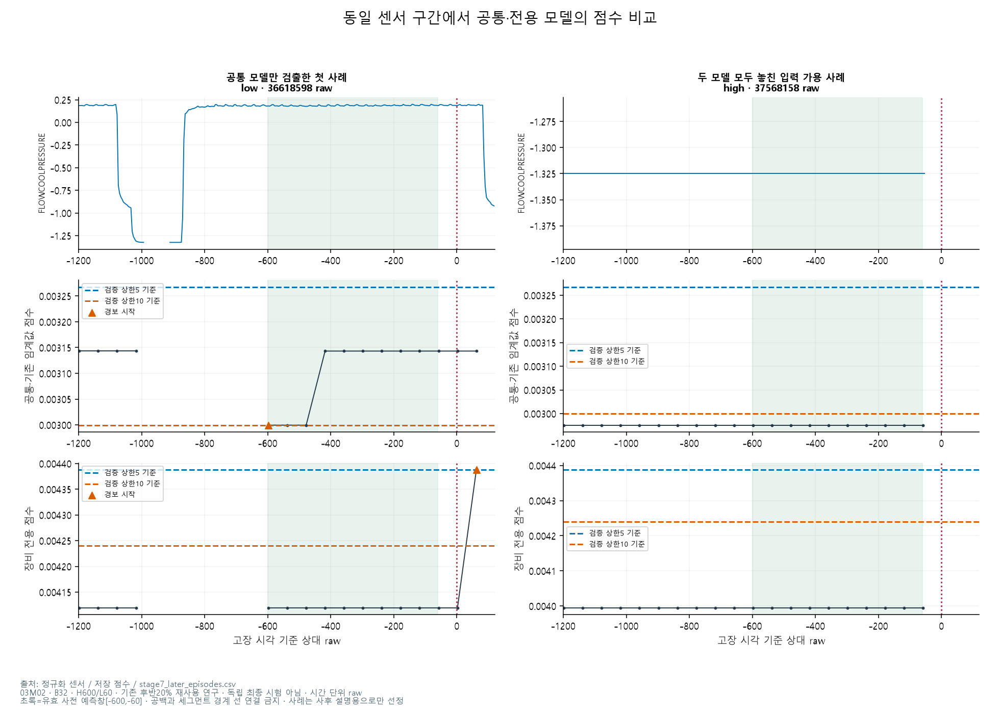

출처: `PHM2018-Project-V3/outputs/figures/stage7/event_cases.png`

03M02 · B32 · H600/L60 · 기존 후반20% 재사용 연구 · 독립 최종 시험 아님 · 시간 단위 raw
초록=유효 사전 예측창[-600,-60] · 공백과 세그먼트 경계 선 연결 금지 · 사례는 사후 설명용으로만 선정

<a id="section-15"></a>

## 15. 로컬 CUDA 자원·검사·재현성

RTX3060 Laptop,CPU Ryzen7 6800H,물리8/논리16코어,RAM 약32GB 환경을 사용했습니다. V3 XGBoost는 실제 cuda:0 학습을 검증했고 모델을 순차 처리했습니다. CPU12스레드/경보 평가3프로세스와 메모리 감시를 활용했습니다. GPU 장치 전체 메모리는 다른 프로세스를 포함할 수 있고2초 표본은 순간 피크를 보장하지 않습니다. 원본 보호는 주로 파일 크기/mtime 검사이며 전체 원본 내용 해시와는 다릅니다. 종합본 생성 시에는 기존 동결 모델·점수·결과의 내용 해시도 대조합니다.

In [17]:
audits=[]
for path,record in DATA['json'].items():
    if not isinstance(record,dict):continue
    cs=record.get('checks')
    if isinstance(cs,list) and cs and all(isinstance(c,dict) and 'passed' in c for c in cs):
        audits.append({'검사 기록':path,'검사 수':len(cs),'통과':sum(bool(c['passed']) for c in cs)})
show_frame(pd.DataFrame(audits))
show_frame(pd.DataFrame(DATA['notebooks']))
for stage in [2,3,5,7]:
    resource=T(f'stage{stage}_resource_telemetry')
    show_frame(pd.DataFrame([{'단계':stage,'RAM 표본 최대 GiB':resource.rss_bytes.max()/2**30,'장치 전체 GPU 표본 최대 MiB':resource.gpu_used_mib.max(),'자원 표본 수':len(resource)}]))

,검사 기록,검사 수,통과
0,PHM2018-Project-V3/outputs/validation/actual_checks.json,83,83
1,PHM2018-Project-V3/outputs/validation/alarm_independent_audit.json,27,27
2,PHM2018-Project-V3/outputs/validation/alarm_stage1_checks.json,72,72
3,PHM2018-Project-V3/outputs/validation/alarm_stage1_output_checks.json,331,331
4,PHM2018-Project-V3/outputs/validation/final_visual_checks.json,8,8
5,PHM2018-Project-V3/outputs/validation/pretraining_checks.json,6,6
6,PHM2018-Project-V3/outputs/validation/stage2_checks.json,474,474
7,PHM2018-Project-V3/outputs/validation/stage2_evaluation.json,4,4
8,PHM2018-Project-V3/outputs/validation/stage2_visual_checks.json,6,6
9,PHM2018-Project-V3/outputs/validation/stage3_checks.json,787,787


,버전,노트북,코드셀,실행셀,저장오류,출처
0,V1,01_data_overview.ipynb,5,5,0,PHM2018-Project/notebooks/01_data_overview.ipynb
1,V1,02_EDA.ipynb,7,7,0,PHM2018-Project/notebooks/02_EDA.ipynb
2,V1,03_fault_analysis.ipynb,9,9,0,PHM2018-Project/notebooks/03_fault_analysis.ipynb
3,V1,04_label_generation.ipynb,5,5,0,PHM2018-Project/notebooks/04_label_generation.ipynb
4,V1,05_feature_engineering.ipynb,6,6,0,PHM2018-Project/notebooks/05_feature_engineering.ipynb
5,V1,06_baseline_models.ipynb,4,4,0,PHM2018-Project/notebooks/06_baseline_models.ipynb
6,V1,07_xgboost_training.ipynb,4,4,0,PHM2018-Project/notebooks/07_xgboost_training.ipynb
7,V1,08_model_comparison.ipynb,6,6,0,PHM2018-Project/notebooks/08_model_comparison.ipynb
8,V1,09_dataset_audit.ipynb,4,4,0,PHM2018-Project/notebooks/09_dataset_audit.ipynb
9,V1,10_group_cross_validation.ipynb,4,4,0,PHM2018-Project/notebooks/10_group_cross_validation.ipynb


,단계,RAM 표본 최대 GiB,장치 전체 GPU 표본 최대 MiB,자원 표본 수
0,2,1.420979,1700.0,16


,단계,RAM 표본 최대 GiB,장치 전체 GPU 표본 최대 MiB,자원 표본 수
0,3,1.063263,1834.0,19


,단계,RAM 표본 최대 GiB,장치 전체 GPU 표본 최대 MiB,자원 표본 수
0,5,1.460514,1754.0,28


,단계,RAM 표본 최대 GiB,장치 전체 GPU 표본 최대 MiB,자원 표본 수
0,7,0.624134,1370.0,5


<a id="section-16"></a>

## 16. 종합 판단과 남은 과제

현재까지의 결과로 현장 자동 적용을 권할 근거는 부족합니다. 분류 지표가 높거나 확인 음성에서 경보가 적더라도 미확인 구간 부담과 입력 없는 고장을 포함한 시스템 성능은 별도입니다. 우선순위는①고장 전 입력 공백 원인②TTF Null/후속 고장 이력의 완전성③정비 종료·상태·시간 단위④공정 변화에 따른 장비 일반화입니다. 이 근거를 확인한 뒤 새로운 외부/미래 자료로 개선 모델을 평가해야 합니다. 이미 확인한 평가 구간을 반복 튜닝 후 독립 Holdout이라고 부르지 않습니다. 이 종합본은 새로운 연구 결과를 추가한 것이 아니라 기존 수행 자료를 통합한 문서입니다.

<a id="section-17"></a>

## 17. 내장 표 전체 목록과 조회 방법

아래 목록의 집계표는 모든 행을 내장했습니다. 본문에서 길게 표시하지 않은 표도 `T("V3/stage6_holdout_events")`처럼 조회할 수 있습니다. 예측 점수는 `T("V3/최종_저장예측")`에 있습니다. CSV 원본이나 모델 바이너리는 내장 대상이 아닙니다. 각 표의 Parquet SHA256을 재계산해 무결성을 검사합니다.

In [18]:
catalog=pd.DataFrame([{'표':k,'행':v['rows'],'열':len(v['columns']),'출처':v['source']} for k,v in DATA['tables'].items()])
show_frame(catalog)
for key,entry in DATA['tables'].items():
    raw=base64.b64decode(entry['data']);assert hashlib.sha256(raw).hexdigest()==entry['sha256'],key
print('내장 표 전체 무결성 검사 통과:',len(catalog),'개')
print('재학습0회 · 모델 재추론0회 · 원본 재처리0회')

,표,행,열,출처
0,V3/alarm_stage1_episodes,343032,15,PHM2018-Project-V3/outputs/tables/alarm_stage1_episodes.parquet
1,V3/alarm_stage1_events,2376,16,PHM2018-Project-V3/outputs/tables/alarm_stage1_events.parquet
2,V3/alarm_stage1_label_states,288,5,PHM2018-Project-V3/outputs/tables/alarm_stage1_label_states.parquet
3,V3/alarm_stage1_matches,118,8,PHM2018-Project-V3/outputs/tables/alarm_stage1_matches.parquet
4,V3/alarm_stage1_overview,12,18,PHM2018-Project-V3/outputs/tables/alarm_stage1_overview.parquet
...,...,...,...,...
99,V1/stage4_5/na_audit,463,8,PHM2018-Project/outputs/stage4_5/na_audit.parquet
100,V1/stage4_5/threshold_metrics,216,27,PHM2018-Project/outputs/stage4_5/threshold_metrics.parquet
101,V1/stage4_5/tool_state_distribution,33,13,PHM2018-Project/outputs/stage4_5/tool_state_distribution.parquet
102,V3/최종_저장예측,736646,7,PHM2018-Project-V3/outputs/stage6/holdout_predictions.parquet


내장 표 전체 무결성 검사 통과: 104 개
재학습0회 · 모델 재추론0회 · 원본 재처리0회


<a id="section-18"></a>

## 18. 원문 보고서 전체 보관

아래에는 V1/V2/V3의 기존 보고서 원문과 재분석 계획 상태를 모두 내장했습니다. 펼침 항목은 작성 당시 문서입니다. 오래된 미학습/미사용/초 단위 해석·당시 다음 단계 문구는 현재 상태를 덮어쓰지 않습니다. 원문 수치나 과거 판단을 현재 결과에 맞춰 수정하지 않았습니다. 그림은 본문 내장 그림으로 연결하고, 외부/모델/데이터 링크는 원래 보관 위치를 가리킵니다.

<details>
<summary>PHM2018-Project/reports/02_EDA_summary.md — 작성 당시 기록</summary>

> 원문 내용 해시: `cca5049af60117832d9bcd37d2ecfae94edf9ed32e0d14f20e94329767877084`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# 2단계 EDA 결과 — PHM 2018 Ion Mill Etching

2026-11-05 / Windows / Conda `phm2018`, Python 3.11.18.

## 실행 범위와 검증

- 기존 `src/inspect_data.py`, 초기 점검 JSON, 실제 65개 파일의 헤더를 확인했다. 유형별 헤더는 전체 파일에서 일치했다.
- 원본 CSV를 읽기 전용으로 열고 필요한 열만 최대 200,000행 단위로 읽었다. 전체 원본을 Pandas에 한 번에 적재하지 않았다.
- 전체 train 20개: 센서 6종·시간·공정 집계. 전체 test 5개: 구조·시간·공정 집계만 수행했다.
- 전체 TTF 20개: 결측, 범위, 동일 유형 다음 fault와의 차이를 검증했다. 상세 분포·상관·고장 전 분석은 사전 고정한 `01M01`에 한정했다.
- Notebook 3개, 코드 셀 총 21개를 실제 phm2018 커널에서 실행했다. 미실행 코드 셀 0개, 오류 0개이며 그래프 10개를 Notebook에 포함했다.
- 경계 라벨·관측 충분성·집계 불변식 검증을 통과했다. 초기 점검과 비교해 원본 65개 파일의 크기·수정 시각이 유지되었다. 전체 파일 내용 해시는 계산하지 않았다.
- 모델 학습, 원본 수정, GitHub push, 원격 업로드, 외부 서비스로 원본 전송은 수행하지 않았다.

## 1. 실제 데이터 구성과 주요 컬럼

`data/raw/`는 없고 원본은 `phm_data_challenge_2018/`에 있다. 총 65개 CSV, 34,191,555,540 bytes다.

| 경로 | 파일 수 | 실제 행 수 | 구성 |
| --- | ---: | ---: | --- |
| train/*.csv | 20 | 82,189,440 | 24컬럼 센서·공정 시계열 |
| test/*.csv | 5 | 7,198,948 | 동일 24컬럼의 후속 시계열 |
| train/train_faults/*.csv | 20 | 1,236 | time, fault_name, Tool |
| train/train_ttf/*.csv | 20 | 82,189,440 | time 및 고장 유형별 TTF 3개 |

센서 식별/공정 컬럼은 `time`, `Tool`, `stage`, `Lot`, `runnum`, `recipe`, `recipe_step`이다. 이번 주요 센서는 `FLOWCOOLPRESSURE`, `FLOWCOOLFLOWRATE`, `IONGAUGEPRESSURE`, `ETCHBEAMCURRENT`, `ETCHBEAMVOLTAGE`, `ETCHSUPPRESSORCURRENT`다. 전체 컬럼은 01 Notebook에 기록했다.

각 train 파일은 별도 Tool 1개로 총 20개 장비다. test는 새로운 장비가 아니라 train에 있는 5개 장비의 후속 기록이며 train 종료와 test 시작은 모두 4 원시시간 단위 차이다. 기존 test를 장비 독립 성능 검증으로 해석하면 안 된다.

Tool별 관측 범위는 절대 날짜가 아닌 원시 시간 좌표다.

| split | Tool | rows | min_time | max_time | duration_raw | mode_dt | duplicate_adjacent_time |
| --- | --- | --- | --- | --- | --- | --- | --- |
| train | 01M01 | 3124704 | 3.28311e+06 | 4.30373e+07 | 3.97542e+07 | 4 | 5273 |
| train | 01M02 | 5110542 | 3.28383e+06 | 3.97898e+07 | 3.6506e+07 | 4 | 7455 |
| train | 02M01 | 2865625 | 3.28372e+06 | 3.2495e+07 | 2.92113e+07 | 4 | 1570 |
| train | 02M02 | 4143973 | 3.2832e+06 | 3.64851e+07 | 3.32019e+07 | 4 | 2258 |
| train | 03M01 | 3432217 | 3.28667e+06 | 4.16581e+07 | 3.83714e+07 | 4 | 1026 |
| train | 03M02 | 5060498 | 3.28471e+06 | 4.40297e+07 | 4.0745e+07 | 4 | 1168 |
| train | 04M01 | 5097901 | 3.28312e+06 | 4.36279e+07 | 4.03448e+07 | 4 | 1638 |
| train | 04M02 | 4450348 | 3.9975e+06 | 4.24992e+07 | 3.85017e+07 | 4 | 1208 |
| train | 05M01 | 4779554 | 3.28086e+06 | 4.26356e+07 | 3.93547e+07 | 4 | 20236 |
| train | 05M02 | 1907102 | 3.28631e+06 | 4.32542e+07 | 3.99679e+07 | 4 | 9473 |
| train | 06M01 | 3812209 | 3.28446e+06 | 4.17515e+07 | 3.8467e+07 | 4 | 2634 |
| train | 06M02 | 5102932 | 3.28278e+06 | 4.05992e+07 | 3.73164e+07 | 4 | 2240 |
| train | 07M01 | 5301166 | 3.28251e+06 | 4.24539e+07 | 3.91714e+07 | 4 | 10884 |
| train | 07M02 | 5029138 | 3.28316e+06 | 4.04203e+07 | 3.71371e+07 | 4 | 9981 |
| train | 08M01 | 3716092 | 3.28316e+06 | 3.90711e+07 | 3.57879e+07 | 4 | 9260 |
| train | 08M02 | 5014057 | 3.28311e+06 | 4.30353e+07 | 3.97522e+07 | 4 | 11773 |
| train | 09M01 | 4565604 | 3.28319e+06 | 4.32921e+07 | 4.00089e+07 | 4 | 7991 |
| train | 09M02 | 2754216 | 3.9242e+06 | 4.62106e+07 | 4.22864e+07 | 4 | 5936 |
| train | 10M01 | 3166038 | 3.28631e+06 | 4.34222e+07 | 4.01359e+07 | 4 | 2605 |
| train | 10M02 | 3755524 | 3.28351e+06 | 4.11036e+07 | 3.78201e+07 | 4 | 2924 |
| test | 01M02 | 1703514 | 3.97898e+07 | 5.34653e+07 | 1.36754e+07 | 4 | 2498 |
| test | 02M02 | 1381325 | 3.64851e+07 | 4.77864e+07 | 1.13013e+07 | 4 | 413 |
| test | 03M01 | 1144072 | 4.16581e+07 | 5.2161e+07 | 1.05029e+07 | 4 | 1417 |
| test | 04M01 | 1699301 | 4.36279e+07 | 5.52623e+07 | 1.16344e+07 | 4 | 1409 |
| test | 06M01 | 1270736 | 4.17515e+07 | 5.36575e+07 | 1.1906e+07 | 4 | 914 |

## 2. 고장 유형별·장비별 발생 횟수와 연결 기준

고장 이력 1,236행 중 동일 `(Tool,time,fault_raw)` 중복이 25행 있어 고유 이벤트는 1,211건이다. 원본을 삭제·수정하지 않고 집계에서만 구분했다. 서로 다른 유형의 동시 이벤트는 합치지 않았다.

| 고장 유형 | 원본 행 수 | 고유 이벤트 수 |
| --- | --- | --- |
| FlowCool Pressure Dropped Below Limit | 756 | 741 |
| Flowcool Pressure Too High Check Flowcool Pump | 341 | 333 |
| Flowcool leak | 139 | 137 |

고압 원문 340행과 `[NoWaferID]` 고압 1행을 3종 기술 집계에서 합쳤다. 고유 고압 이벤트는 태그 포함 333건, 태그 제외 332건이다. TTF 검증에서는 태그 이벤트를 제외한 기준이 일치한다.

| Tool | FlowCool Pressure Dropped Below Limit | Flowcool Pressure Too High Check Flowcool Pump | Flowcool leak |
| --- | --- | --- | --- |
| 01M01 | 13 | 5 | 1 |
| 01M02 | 53 | 40 | 16 |
| 02M01 | 9 | 7 | 1 |
| 02M02 | 5 | 27 | 0 |
| 03M01 | 40 | 51 | 0 |
| 03M02 | 298 | 49 | 9 |
| 04M01 | 7 | 1 | 1 |
| 04M02 | 21 | 1 | 15 |
| 05M01 | 14 | 7 | 7 |
| 05M02 | 5 | 17 | 5 |
| 06M01 | 10 | 3 | 3 |
| 06M02 | 28 | 5 | 26 |
| 07M01 | 15 | 2 | 18 |
| 07M02 | 3 | 3 | 0 |
| 08M01 | 68 | 32 | 17 |
| 08M02 | 0 | 6 | 0 |
| 09M01 | 129 | 19 | 2 |
| 09M02 | 8 | 57 | 0 |
| 10M01 | 13 | 1 | 16 |
| 10M02 | 2 | 0 | 0 |

센서와 fault는 파일 접두어·실제 Tool·시간 좌표를 대조한다. 센서의 `(Tool,time)`은 비고유하므로 원본 행 ID와 이벤트 ID를 별도로 관리해야 한다. 고유 이벤트 중 정확한 센서 시각 일치는 211/1211건이다. 원본 이력 행 기준으로는 215/1,236행이다. 센서 측정 범위 밖 고유 이벤트는 4건이다. 정확 일치만으로 고장 라벨을 붙이면 관측 공백 내 이벤트를 놓치므로 윈도 관측 충분성과 이벤트 시간을 별도로 다룬다.

## 3. 주요 센서의 특징

다음은 전체 학습 82,189,440행의 집계다. 모든 주요 센서가 float64로 파싱되었고 결측·무한대는 0개다. 물리 단위는 미공개이며 음수는 원본의 익명화 수치다.

| sensor | read_dtype | missing_ratio | min | max | mean | std |
| --- | --- | --- | --- | --- | --- | --- |
| FLOWCOOLPRESSURE | float64 | 0 | -4.23058 | 16.6299 | 0.0264922 | 1.07652 |
| FLOWCOOLFLOWRATE | float64 | 0 | -3.48254 | 2.94029 | -0.00760169 | 1.00785 |
| IONGAUGEPRESSURE | float64 | 0 | -1.90791 | 603.663 | -0.00894675 | 1.02854 |
| ETCHBEAMCURRENT | float64 | 0 | -1.51875 | 7.88684 | 0.00135293 | 1.00387 |
| ETCHBEAMVOLTAGE | float64 | 0 | -1.5286 | 3.69622 | 0.00380067 | 1.00562 |
| ETCHSUPPRESSORCURRENT | float64 | 0 | -1.51478 | 32.0955 | 0.0013721 | 1.00692 |

- 대표 01M01의 분포에는 여러 봉우리와 경계값 집중이 있다. Recipe/Stage별 평균이 달라 공정 상태 혼합을 검토해야 한다.
- IONGAUGEPRESSURE의 전체 최대 603.663, ETCHSUPPRESSORCURRENT의 최대 32.096 등 꼬리 값은 점검 후보이며 물리 오류나 고장이라고 단정하지 않는다.
- 대표 장비의 ETCHBEAMCURRENT–ETCHBEAMVOLTAGE Pearson 상관은 0.9650, ETCHBEAMCURRENT–ETCHSUPPRESSORCURRENT는 0.9636다. 공정 동조성이 포함된 상관이며 인과관계가 아니다.
- 대표 장비 전체 히스토그램·시간 bin 평균·상관·공정 조건별 평균을 그렸다. IQR 경계는 히스토그램 보간 분위수로 근사하고, 경계 밖 행 수는 추가 청크 순회로 집계했다. 이상값 삭제·클리핑은 하지 않았다. 상세 결과는 02 Notebook에 있다.

## 4. 고장 이전 센서 변화에서 발견한 사항

01M01의 19개 고유 이벤트를 모두 대상으로 고장 이전 300/600/1800/3600 원시시간 단위의 관측 충분성을 조사했다. 무작위 행 표본은 사용하지 않았다. 충분성은 고유 시각/기대 관측 수 90% 이상, 양 끝 공백 2최빈간격 이하, 내부 공백 3최빈간격 이하로 정의했다.

**시간 단위 제한:** 아래 분은 `time=초`를 가정한 조건부 표기다. 실제 물리 분 단위는 미확정이다.

가장 많은 구간이 충분한 첫 이벤트는 고압 고장 time=26098948이다.

| minutes_assuming_seconds | rows | unique_times | coverage_ratio | max_gap | sufficient |
| --- | --- | --- | --- | --- | --- |
| 5 | 75 | 75 | 1 | 6 | True |
| 10 | 150 | 150 | 1 | 6 | True |
| 30 | 450 | 450 | 1 | 6 | True |
| 60 | 900 | 900 | 1 | 6 | True |

관측 수는 각각 75/150/450/900행이며 네 구간 모두 충분하다. 마지막 관측은 고장 2 원시시간 단위 전이고 고장 시각 자체는 제외했다. 비교 구간도 같은 장비의 과거 구간이며 알려진 고장 주변에서 떨어져 있다.

- 해당 고장 전·비교 구간은 모두 Recipe=0, Stage=0이다. 이를 정상 가동 상태라고 확인할 수 없다.
- FLOWCOOLPRESSURE와 FLOWCOOLFLOWRATE는 고장 전 60분 동안 일정했다. 이 사례에서 고압 고장으로 가는 압력 상승 전조는 확인하지 못했다.
- IONGAUGEPRESSURE의 고장 전 60분 평균은 비교 구간보다 약 0.3263 낮았다. 같은 고장 전 구간 내부의 변화와 구간 간 수준 차이를 구분해야 하며, 이 차이를 예측 신호로 일반화하지 않는다.
- 가동 공정 보조 사례는 누출 time=20174938, Recipe=19, Stage=1이다. 5/10/30분 구간은 각각 75/150/450행으로 충분하지만, 60분은 570/900개 고유 시각(63.3%)으로 부족하다. 부족한 앞부분은 보간하지 않았다.
- 보조 사례의 마지막 5분에도 FlowCool 압력·유량·빔 전압은 앞쪽 관측 평균과 같은 수준이다. 작은 전류/게이지 차이를 고장 전조로 단정하지 않았다.
- 별도 가동 비교 후보는 알려진 고장에 인접하지 않은 과거 900행이며 Recipe=2, Stage=2다. 보조 사례와 공정이 달라 평균 차이를 순수 고장 효과로 볼 수 없다. 알려진 fault가 없다는 이유만으로 정상 정답을 부여하지 않았다.

따라서 현재 두 사례만으로 일관된 고장 예고 패턴을 주장할 근거는 없다. 다른 장비·이벤트와 공정이 일치하는 비교 구간으로 확대 검증해야 한다.

## 5. 데이터 품질 및 결측 문제, TTF 정합성

- 전체 파일에 시간 역전과 시간 결측은 없었다. 양의 시간 간격 최빈값은 모두 4 원시단위다.
- train에서 동시각 인접 행은 117,533개, 최빈간격을 초과하는 간격은 1,090,018개다. 가장 큰 간격은 952548 원시단위다. 4라는 최빈값만으로 연속 시계열을 가정하면 안 된다.
- 센서와 TTF의 전체 시간열은 20개 대응 파일 모두 행 수·순서·중복을 포함한 digest가 동일했다.
- 유한 TTF는 대부분 `다음 동일 유형 fault 시각 - time`과 정확히 같다. 03M02 고압에서 `[NoWaferID]`를 포함하면 3,489행이 어긋나며, 이를 제외하면 불일치가 0행이다. 다른 유형/장비의 불일치는 0행이다.
- 실제 결측 TTF는 모두 제공된 동일 유형의 미래 fault가 없는 구간이다. 남은 fault 이력 밖의 검열과 실제 무고장을 구분할 수 없으므로 결측을 0 또는 정상으로 바꾸지 않는다. 음수 TTF는 0개다.

| column | rows | missing | finite | 결측 비율 (%) |
| --- | --- | --- | --- | --- |
| TTF_FlowCool Pressure Dropped Below Limit | 82189440 | 20165908 | 62023532 | 24.5359 |
| TTF_Flowcool Pressure Too High Check Flowcool Pump | 82189440 | 26188226 | 56001214 | 31.8632 |
| TTF_Flowcool leak | 82189440 | 44066194 | 38123246 | 53.6154 |

공식 설명은 익명화와 단위 미공개, 정비 정지 시각 및 TTF null의 제한을 설명한다. 현지 파일의 fault 세 번째 컬럼은 문서 표의 `stage`와 달리 실제 `Tool`이며, TTF 폴더도 실제 경로를 기준으로 처리했다. [PHM Society 공식 설명](https://phmsociety.org/conference/annual-conference-of-the-phm-society/annual-conference-of-the-prognostics-and-health-management-society-2018-b/phm-data-challenge-6/)

## 6. 모델 학습 전 필요한 전처리

1. time의 물리 단위와 fault 정의, `[NoWaferID]` 포함 정책, 이력 완전성을 확정한다. 고장 정지 시점과 실제 이상 시작 시점을 혼동하지 않는다.
2. `(파일,원본 행 순서)` 등 고유 ID를 보존하고 동시각 공정 차이를 확인한 뒤 집계 정책을 정한다. 긴 공백을 무조건 보간하지 않고 연속 세그먼트/관측 마스크를 만든다.
3. 5/10/30분 타깃 후보는 `0 < 다음 고장까지 시간 <= 300/600/1800` 원시단위다. 분 환산은 조건부다. 고장 시각 자체, TTF 모순, 추적 부족·이력 불완전 구간은 제외 또는 NA로 둔다. 양성은 확인된 미래 이벤트에서 정의할 수 있지만 음성은 전체 예측 구간의 추적·라벨 완전성을 검증한 뒤 부여한다.
4. 장비/Recipe/Stage 조건을 반영해 과거 방향 rolling 특징을 만든다. TTF/fault는 타깃·평가용이며 특징에 넣지 않는다. ACTUALSTEPDURATION은 실제 제공 시점을 확인한다. 스케일러·결측 대치·특징 선택은 학습 분할에만 적합한다.
5. 장비 단위 외부 검증과 시간 순서 내부 검증을 설계한다. 동일 이벤트와 중첩 윈도가 경계를 넘지 않게 예측 구간/윈도에 맞는 간격을 둔다. test로 임계값·특징을 조정하지 않는다.
6. 경보 병합·이벤트 매칭·최소 Lead Time·정상 가동 노출시간을 정의하고 F1-score, Event Recall, False Alarm Rate, Lead Time을 함께 평가한다.

## 7. 생성 파일과 재실행

| 파일 | 용도 |
| --- | --- |
| notebooks/01_data_overview.ipynb | 전체 구조, Tool별 행 수·시간, 센서 품질, Recipe/Stage |
| notebooks/02_EDA.ipynb | 대표 장비 전체 분포·추이·IQR 후보·상관·공정 평균 |
| notebooks/03_fault_analysis.ipynb | 고장 건수, 관측 충분성, 고장 전 비교, TTF/라벨 검토 |
| src/eda_common.py | 읽기 전용 청크 집계, fault/TTF 검증, 메타데이터 캐시 |
| src/eda_detail.py | 대표 분포, 이벤트·비교 구간, 시간 키 검사, 보수적 라벨 함수 |
| src/eda_plots.py | 한국어 제목·축·단위·범례의 공통 그래프 |
| scripts/build_eda_notebooks.py | Notebook 생성 및 phm2018 커널 실행 |
| scripts/validate_eda.py | 집계 불변식·라벨 경계·Notebook·원본 메타데이터 검증 |
| scripts/write_eda_report.py | 검증된 수치로 본 보고서 재생성 |
| requirements-eda.txt | 실제 실행 환경의 직접 의존성 버전 |
| reports/local/eda/ | Git 제외: 집계 JSON, 구간 자료, 그래프, 실행·검증 로그 |

```powershell
conda activate phm2018
python scripts/build_eda_notebooks.py
python scripts/validate_eda.py
python scripts/write_eda_report.py
```

Notebook은 직접 순서대로 열어 실행할 수도 있다. 첫 전체 집계가 없거나 입력/공통 코드가 바뀌면 청크 순회를 수행하고, 일치하는 캐시가 있으면 재사용한다. `overview(force=True)`와 `representative(force=True)`로 강제 재집계할 수 있다. 원본을 담은 구간 자료와 로컬 결과는 `.gitignore`의 `reports/local/` 제외 규칙을 따른다.

## 미실행·미검증 범위

미실행 코드 셀은 없다. 전체 장비의 상세 분포·상관·고장 전 패턴, 나머지 센서의 전체 결측/이상값, 물리 단위, 실제 이상 시작 시점, 고장 이력 완전성, 패턴의 통계적 일반성은 미검증이다. IQR 분위수는 근사이며 실제 모델 학습 및 성능 평가를 하지 않았다.


</details>

<details>
<summary>PHM2018-Project/reports/03_dataset_summary.md — 작성 당시 기록</summary>

> 원문 내용 해시: `cbc975db450efccef68eb424f48543a65b47559ddd9f99fb4aad9ce9fd4b731c`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# 3단계: 머신러닝용 학습 데이터 구축 결과

2026-11-05 / 로컬 Windows, Conda `phm2018`, Python 3.11.18. 모델 학습은 수행하지 않았다.

## 처리 범위와 시간·이벤트 정책

기존 `03_fault_analysis.ipynb`, `src/eda_common.py`, `src/eda_detail.py`, EDA 정합성 결과를 먼저 확인하고 공통 센서/고장 목록·이력 로더·스냅샷 함수를 재사용했다. **기존 코드·Notebook·EDA 결과는 변경하지 않았다.** 새 결과는 `data/processed/ml_v1/`, `reports/local/dataset_v1/`에 분리했다.

- 전체 학습 센서/TTF 20개 장비, 원본 82,189,440행을 200,000행 청크로 대조했다. 물리 메모리에 전체 원본을 적재하지 않았다.
- 공식 문서의 단위 미공개·초 예시와 실제 기록의 간격 4, TTF 차이의 일치를 재확인했다. **실제 물리 초는 확정하지 못했다.** 300/600/1800 원시시간 타깃이며 각각 5/10/30분이라는 해석은 초라는 가정에서만 가능하다. 문서 원본 PDF 재조회는 시간 초과였으며 공식 웹 설명과 기존 확인 결과를 근거로 사용했다.
- [PHM Society 공식 데이터 설명](https://phmsociety.org/conference/annual-conference-of-the-phm-society/annual-conference-of-the-prognostics-and-health-management-society-2018-b/phm-data-challenge-6/)은 고장 기록을 정비를 위한 정지 시점으로 설명한다. 실제 이상 시작 시각은 알 수 없다.
- 동일 Tool·time·원문 유형의 중복 Fault 25행을 집계상 제외하여 1,211개 고유 이벤트로 처리했다. 기본 타깃은 `[NoWaferID]` 1건을 제외한 **1,210건: 저압(f1) 741, 고압(f2) 332, 누출(f3) 137건**이다. 원본은 변경하지 않았다.
- 기본 태그 제외 정책으로 전체 센서/TTF 시각열과 유한/결측 TTF를 다시 대조한 불일치는 0행이다. 태그 포함 기준에서 03M02의 원본 3,489행이 어긋난다는 기존 결과와 일치한다.
- 동시각 센서 행은 동일 시각 배치의 6개 센서 평균으로 집계했다. 중복 117,533행이 합쳐져 **82,071,907개 관측 시각**이다. Recipe/Stage가 서로 다른 동시각은 상태 모순으로 격리했다(총 0개 시각). 시간 간격 12 초과와 상태 모순에서 연속 세그먼트를 끊는다. 실제 현장 적용 시 동시각 배치 도착 순서는 추가 확인이 필요하다.

## 1. 유형별 양성·음성·미확인 수 / 2. 예측 구간별 분포

아래는 **모든 정규화 관측 시각**의 기본 라벨 수다. 이벤트 수와 혼동하지 않는다. h300raw/h600raw/h1800raw는 물리 분으로 검증된 이름이 아니다.

| fault_code | horizon_raw | positive | negative | unknown |
| --- | --- | --- | --- | --- |
| any | 300 | 27104 | 21586913 | 60457890 |
| any | 600 | 49268 | 14377472 | 67645167 |
| any | 1800 | 105747 | 6485450 | 75480710 |
| f1 | 300 | 16611 | 43894566 | 38160730 |
| f1 | 600 | 30026 | 27822831 | 54219050 |
| f1 | 1800 | 62746 | 11639721 | 70369440 |
| f2 | 300 | 5815 | 38866349 | 43199743 |
| f2 | 600 | 10827 | 23882260 | 58178820 |
| f2 | 1800 | 24277 | 9404732 | 72642898 |
| f3 | 300 | 4854 | 28242453 | 53824600 |
| f3 | 600 | 9088 | 19563070 | 62499749 |
| f3 | 1800 | 22410 | 9473153 | 72576344 |

양성은 검증된 유한 TTF가 H 이내이고 확인된 이벤트까지 연속 관측이 유지되는 경우다. 마지막 센서 시각에서 이벤트까지 최대 12 원시단위 허용 간격을 둔다. 음성은 검증된 유한 TTF가 H보다 크고 H 전체가 연속 관측 세그먼트 안에 있는 경우만 부여했다. 이는 제공된 고장/TTF 기록에 대한 음성 근거이며 기록의 절대적 완전성을 증명하지 않는다.

TTF 결측·모순, 추적 종료·공백, 공정 상태 모순, 고장 시각 자체는 NA다. TTF 결측을 0으로 바꾸지 않았다. 통합 any는 하나라도 1이면 1, 세 유형 모두 0일 때만 0, 나머지는 NA다. 개별 유형 9개와 통합 3개로 총 12개 타깃을 보존했다.

### `[NoWaferID]` 정책 영향

| horizon_raw | rows | changed_rows | conflict_rows | include_positive | include_negative | include_unknown | quarantine_extra_unknown |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 300 | 82071907 | 75 | 3482 | 5890 | 38866274 | 43199743 | 3181 |
| 600 | 82071907 | 150 | 3482 | 10977 | 23882110 | 58178820 | 2882 |
| 1800 | 82071907 | 364 | 3482 | 24641 | 9404368 | 72642898 | 2241 |

`changed_rows`는 태그 제외 기본 라벨과 태그 포함·fault 이력 우선 대안이 달라지는 정규화 관측 수다. `conflict_rows`는 제공 TTF와의 충돌 관측 수이며 원본 중복 집계 때문에 3,489 원본 행과 다를 수 있다. `quarantine_extra_unknown`은 충돌 관측을 격리하면 기본의 알려진 라벨 중 추가로 NA가 되는 수다. 대안 `alt_` 컬럼은 비교용이며 훈련 데이터의 타깃 목록에 포함하지 않았다. 태그 포함 학습을 하려면 정답 재정의·TTF 재생성 정책을 별도로 확정해야 한다.

## 3. 장비별 학습 후보 분포

라벨과 무관하게 60 원시시간 단위 bin의 **첫 실제 관측**을 anchor로 선택했다. 총 anchor 5,777,042개 중 충분한 과거 이력을 가진 행은 2,331,977개다. 그중 12개 타깃 중 적어도 하나가 알려진 1,466,770행을 `training/`에 저장했다. 아래 양성·음성·NA는 이 공통 학습 파일에서의 통합 h1800raw 기준이다.

| Tool | split_tool | rows | positive | negative | unknown |
| --- | --- | --- | --- | --- | --- |
| 01M01 | train | 66421 | 61 | 18993 | 47367 |
| 01M02 | train | 233502 | 1356 | 107042 | 125104 |
| 02M01 | train | 73194 | 83 | 22183 | 50928 |
| 02M02 | train | 34046 | 65 | 0 | 33981 |
| 03M01 | train | 47263 | 200 | 0 | 47063 |
| 03M02 | train | 58549 | 523 | 11527 | 46499 |
| 04M01 | train | 32686 | 43 | 754 | 31889 |
| 04M02 | train | 220068 | 550 | 0 | 219518 |
| 05M01 | train | 29462 | 42 | 5644 | 23776 |
| 05M02 | train | 10094 | 30 | 1176 | 8888 |
| 06M01 | train | 45170 | 30 | 7579 | 37561 |
| 06M02 | train | 259462 | 804 | 110371 | 148287 |
| 07M01 | validation | 34970 | 51 | 7080 | 27839 |
| 07M02 | validation | 32916 | 0 | 0 | 32916 |
| 08M01 | validation | 85066 | 645 | 31936 | 52485 |
| 08M02 | validation | 32168 | 58 | 0 | 32110 |
| 09M01 | evaluation | 54820 | 451 | 16442 | 37927 |
| 09M02 | evaluation | 57424 | 122 | 0 | 57302 |
| 10M01 | evaluation | 31540 | 216 | 2988 | 28336 |
| 10M02 | evaluation | 27949 | 0 | 0 | 27949 |

검증/평가에서 클래스 비율을 인위적으로 조정하지 않았다. 전 장비에 같은 라벨 독립 anchor 규칙을 적용했다. 센서 기록 전체와 비교한 시간 해상도는 낮아졌으며, 전체 시각 라벨은 `labels/`에 유지한다. 짧은 이벤트를 놓치는지 Event Recall 평가에서 별도로 확인해야 한다.

## 4. Stage에 따른 데이터 차이

| state_group | fault_code | horizon_raw | positive | negative | unknown |
| --- | --- | --- | --- | --- | --- |
| stage0 | any | 300 | 59 | 36038 | 85970 |
| stage0 | any | 600 | 104 | 32832 | 89131 |
| stage0 | any | 1800 | 233 | 20410 | 101424 |
| stage0 | f1 | 300 | 54 | 100820 | 21193 |
| stage0 | f1 | 600 | 94 | 92362 | 29611 |
| stage0 | f1 | 1800 | 203 | 59162 | 62702 |
| stage0 | f2 | 300 | 5 | 93754 | 28308 |
| stage0 | f2 | 600 | 10 | 86001 | 36056 |
| stage0 | f2 | 1800 | 30 | 55676 | 66361 |
| stage0 | f3 | 300 | 0 | 42721 | 79346 |
| stage0 | f3 | 600 | 0 | 38945 | 83122 |
| stage0 | f3 | 1800 | 0 | 24213 | 97854 |
| stage_positive | any | 300 | 1171 | 660704 | 682828 |
| stage_positive | any | 600 | 2145 | 539842 | 802716 |
| stage_positive | any | 1800 | 5097 | 323305 | 1016301 |
| stage_positive | f1 | 300 | 653 | 1181472 | 162578 |
| stage_positive | f1 | 600 | 1170 | 942775 | 400758 |
| stage_positive | f1 | 1800 | 2791 | 553134 | 788778 |
| stage_positive | f2 | 300 | 272 | 978484 | 365947 |
| stage_positive | f2 | 600 | 520 | 763880 | 580303 |
| stage_positive | f2 | 1800 | 1253 | 442720 | 900730 |
| stage_positive | f3 | 300 | 256 | 940227 | 404220 |
| stage_positive | f3 | 600 | 487 | 785866 | 558350 |
| stage_positive | f3 | 1800 | 1245 | 470140 | 873318 |

아래는 기본 타깃 고유 이벤트의 Stage 분포다. 고장 시각 이하 가장 가까운 센서와 12 원시단위 이내에서만 상태를 붙였고, 공백이 길면 unknown으로 남겼다. 미래 센서로 상태를 채우지 않았다.

| fault_code | stage0 | stage_positive | unknown |
| --- | --- | --- | --- |
| f1 | 12 | 235 | 494 |
| f2 | 1 | 81 | 250 |
| f3 | 0 | 71 | 66 |

Stage=0을 정상 또는 고장으로 임의 해석하지 않았다. 전체 상태 모델은 전체 후보, 가동 상태 모델은 `stage>0` 필터로 같은 분할에서 비교할 수 있다. Recipe별 전체 분포와 시각화는 04 Notebook에 있다.

## 5. 생성 특징

입력 특징은 **83개**로 `feature_columns.json`과 `training_schema.json`에 정확한 목록을 기록했다.

- 센서 6종: FLOWCOOLPRESSURE, FLOWCOOLFLOWRATE, IONGAUGEPRESSURE, ETCHBEAMCURRENT, ETCHBEAMVOLTAGE, ETCHSUPPRESSORCURRENT.
- 센서마다 현재값 1개, w=60/300 원시단위 각각 mean/std/min/max/delta_mean/rate_mean 6개로 센서 특징 78개.
- 현재 recipe/stage 2개와 과거 300 원시단위의 stage_zero_fraction, stage_change_count, recipe_change_count 3개.
- 현재 구간 `(t-w,t]`, 이전 구간 `(t-2w,t-w]`. std는 ddof=0이다. delta_mean은 두 구간 평균 차이이며 rate_mean은 차이/w로 백분율이 아니다.
- 최대 600 원시단위 과거 이력과 각 현재/이전 윈도 관측 수가 기대치의 90% 이상인 행만 feature_ready로 둔다. 이력 부족을 보간·대치하지 않았다.
- `TTF`, Fault, 라벨, next_event 키, 미래 segment_end, split 및 Tool/time/row_id 메타데이터는 입력 특징 화이트리스트에 없다. 전처리 스케일링·대치·클리핑·클래스 재표본화는 아직 하지 않았다.

## 6. 데이터 분할과 누수 검증

장비 독립 분할은 접두어 01~06 학습, 07~08 검증, 09~10 평가다. 같은 번호의 M01/M02도 같은 분할에 배치했다. 성능이나 이벤트 수에 맞춰 분할을 다시 선택하지 않았다.

| split_tool | horizon_raw | positive | negative | unknown |
| --- | --- | --- | --- | --- |
| evaluation | 300 | 192 | 39900 | 131641 |
| evaluation | 600 | 345 | 30125 | 141263 |
| evaluation | 1800 | 789 | 19430 | 151514 |
| train | 300 | 838 | 549711 | 559368 |
| train | 600 | 1541 | 467421 | 640955 |
| train | 1800 | 3787 | 285269 | 820861 |
| validation | 300 | 200 | 107131 | 77789 |
| validation | 600 | 363 | 75128 | 109629 |
| validation | 1800 | 754 | 39016 | 145350 |

별도 시간 순서 분할은 장비별 원시 측정 범위의 60/20/20%다. 최대 과거 이력과 최대 미래 타깃 1800 원시단위가 경계를 넘으면 purged다. 실제 특징 출처 최소 시각이 경계를 넘는지도 추가 확인했다. 두 분할은 서로 다른 평가 실험용으로 섞어 쓰지 않는다.

| split_time | horizon_raw | positive | negative | unknown |
| --- | --- | --- | --- | --- |
| evaluation | 300 | 261 | 14137 | 199116 |
| evaluation | 600 | 475 | 9890 | 203149 |
| evaluation | 1800 | 1171 | 4074 | 208269 |
| purged | 300 | 0 | 87 | 149 |
| purged | 600 | 0 | 67 | 169 |
| purged | 1800 | 0 | 20 | 216 |
| train | 300 | 731 | 584132 | 373025 |
| train | 600 | 1332 | 479035 | 477521 |
| train | 1800 | 3103 | 291648 | 663137 |
| validation | 300 | 238 | 98386 | 196508 |
| validation | 600 | 442 | 83682 | 211008 |
| validation | 1800 | 1056 | 47973 | 246103 |

장비 분할에 배정된 원래 고유 이벤트 수:

| split_tool | fault_code | events |
| --- | --- | --- |
| evaluation | f1 | 152 |
| evaluation | f2 | 77 |
| evaluation | f3 | 18 |
| train | f1 | 503 |
| train | f2 | 212 |
| train | f3 | 84 |
| validation | f1 | 86 |
| validation | f2 | 43 |
| validation | f3 | 35 |

실제 준비된 양성 anchor로 관측된 고유 이벤트 수(공백 때문에 이력의 모든 이벤트가 대표되지는 않음):

| scheme | split | fault_code | horizon_raw | represented_events |
| --- | --- | --- | --- | --- |
| split_time | evaluation | f1 | 300 | 35 |
| split_time | evaluation | f1 | 600 | 35 |
| split_time | evaluation | f1 | 1800 | 35 |
| split_time | evaluation | f2 | 300 | 12 |
| split_time | evaluation | f2 | 600 | 12 |
| split_time | evaluation | f2 | 1800 | 12 |
| split_time | evaluation | f3 | 300 | 9 |
| split_time | evaluation | f3 | 600 | 9 |
| split_time | evaluation | f3 | 1800 | 9 |
| split_time | train | f1 | 300 | 85 |
| split_time | train | f1 | 600 | 85 |
| split_time | train | f1 | 1800 | 85 |
| split_time | train | f2 | 300 | 34 |
| split_time | train | f2 | 600 | 34 |
| split_time | train | f2 | 1800 | 34 |
| split_time | train | f3 | 300 | 38 |
| split_time | train | f3 | 600 | 38 |
| split_time | train | f3 | 1800 | 38 |
| split_time | validation | f1 | 300 | 36 |
| split_time | validation | f1 | 600 | 36 |
| split_time | validation | f1 | 1800 | 36 |
| split_time | validation | f2 | 300 | 13 |
| split_time | validation | f2 | 600 | 13 |
| split_time | validation | f2 | 1800 | 13 |
| split_time | validation | f3 | 300 | 7 |
| split_time | validation | f3 | 600 | 7 |
| split_time | validation | f3 | 1800 | 7 |
| split_tool | evaluation | f1 | 300 | 30 |
| split_tool | evaluation | f1 | 600 | 30 |
| split_tool | evaluation | f1 | 1800 | 30 |
| split_tool | evaluation | f2 | 300 | 11 |
| split_tool | evaluation | f2 | 600 | 11 |
| split_tool | evaluation | f2 | 1800 | 11 |
| split_tool | evaluation | f3 | 300 | 4 |
| split_tool | evaluation | f3 | 600 | 4 |
| split_tool | evaluation | f3 | 1800 | 4 |
| split_tool | train | f1 | 300 | 108 |
| split_tool | train | f1 | 600 | 108 |
| split_tool | train | f1 | 1800 | 108 |
| split_tool | train | f2 | 300 | 30 |
| split_tool | train | f2 | 600 | 30 |
| split_tool | train | f2 | 1800 | 30 |
| split_tool | train | f3 | 300 | 43 |
| split_tool | train | f3 | 600 | 43 |
| split_tool | train | f3 | 1800 | 43 |
| split_tool | validation | f1 | 300 | 18 |
| split_tool | validation | f1 | 600 | 18 |
| split_tool | validation | f1 | 1800 | 18 |
| split_tool | validation | f2 | 300 | 18 |
| split_tool | validation | f2 | 600 | 18 |
| split_tool | validation | f2 | 1800 | 18 |
| split_tool | validation | f3 | 300 | 7 |
| split_tool | validation | f3 | 600 | 7 |
| split_tool | validation | f3 | 1800 | 7 |

검증 결과:

- 전체 센서/TTF 행·시각·이벤트 차이 검증 통과. 기본 정책 불일치 0.
- 라벨 근거와 통합 3값 논리, 키 유일성, 유한 특징, 특징-라벨 시각 연결 검증 통과.
- 미래 관측값을 변경해도 이전 특징이 변하지 않는 테스트, 137행 청크와 일괄 계산의 일치 테스트 통과.
- TTF 입력 거부, 공백/결측/고장 시각/예측 경계 테스트 통과.
- 서로 다른 분할이 공유하는 양성 이벤트 **0건**. 예측 구간 전체를 통틀어서도 공유 없음.
- 시간 분할 간 특징/타깃 관측 범위 중첩 **0건**.
- 초기 점검 대비 원본 65개 파일의 크기·수정 시각 유지. 전체 파일 내용 해시는 계산하지 않았다.
- 공식 test에는 로컬 정답이 없어 학습·검증·내부 평가에 사용하지 않았다. 현재 평가는 내부 장비/시간 분할로 설계했다.

## 7. 실제 학습에 사용 가능한 크기

| fault_code | horizon_raw | positive | negative | unknown | usable |
| --- | --- | --- | --- | --- | --- |
| any | 300 | 1230 | 696742 | 768798 | 697972 |
| any | 600 | 2249 | 572674 | 891847 | 574923 |
| any | 1800 | 5330 | 343715 | 1117725 | 349045 |
| f1 | 300 | 707 | 1282292 | 183771 | 1282999 |
| f1 | 600 | 1264 | 1035137 | 430369 | 1036401 |
| f1 | 1800 | 2994 | 612296 | 851480 | 615290 |
| f2 | 300 | 277 | 1072238 | 394255 | 1072515 |
| f2 | 600 | 530 | 849881 | 616359 | 850411 |
| f2 | 1800 | 1283 | 498396 | 967091 | 499679 |
| f3 | 300 | 256 | 982948 | 483566 | 983204 |
| f3 | 600 | 487 | 824811 | 641472 | 825298 |
| f3 | 1800 | 1245 | 494353 | 971172 | 495598 |

`usable`은 해당 타깃의 positive+negative 수다. 공통 학습 파일의 모든 행이 모든 타깃에 사용 가능한 것은 아니다. 반드시 해당 target의 NA를 제외하고 원하는 split을 선택한다. 시간 평가에서 purged는 제외한다. Stage>0 모델은 같은 분할에서 추가 필터링한다.

| 출력 | bytes | GiB |
| --- | ---: | ---: |
| observations | 1557496108 | 1.451 |
| segments | 4127486 | 0.004 |
| labels | 509209702 | 0.474 |
| features | 2453976054 | 2.285 |
| training | 419098031 | 0.390 |

라벨/특징/학습 파일은 장비별 Parquet이며 별도 파일로 보존한다. 실제 학습 파일은 **1,466,770행, 0.390 GiB**다. 현재 학습 가능한 것은 원시시간 기반 과제이며 검증된 물리적 5/10/30분 예측이라는 주장은 보류한다.

## 8. 남은 데이터 품질 문제

1. 물리 시간 단위가 확정되지 않았다. 단위 확인 시 horizon/window/stride와 전체 파이프라인 설정을 재검토한다.
2. fault 시각은 정지 시점이며 이상 시작은 불명이다. 기록의 절대적 완전성과 Stage>0의 실제 정상 가동 의미는 확인되지 않았다.
3. TTF 결측과 관측 공백·짧은 이력으로 많은 NA/이벤트 제외가 발생했다. 선택 편향과 대표되지 않는 이벤트를 평가 때 공개해야 한다.
4. 동시각 평균은 명시적 초기 정책이다. Recipe/Stage 모순은 격리했지만 현장 도착 순서와 적절한 센서 집계 의미는 추가 검증이 필요하다.
5. `[NoWaferID]` 포함 타깃은 제공 TTF와 다른 정의다. 두 정책을 혼합하지 않는다.
6. 장비·공정·고장 유형의 불균형이 남아 있다. 검증/평가 분포를 유지하고 학습 분할에서만 가중치 등의 처리를 검토한다.
7. 스케일링·대치·통계적 특징 선택·모델 학습·성능 평가는 하지 않았다. 향후 F1-score 외 Event Recall, False Alarm Rate, Lead Time을 평가한다.

## 파일 및 재실행

- notebooks/04_label_generation.ipynb
- notebooks/05_feature_engineering.ipynb
- src/build_labels.py, src/build_features.py, src/validate_dataset.py
- src/dataset_common.py
- src/dataset_loader.py: 명시적 특징 목록과 하나의 알려진 타깃만 반환하는 배치 로더
- scripts/build_ml_dataset.py, scripts/build_dataset_notebooks.py, scripts/write_dataset_report.py
- tests/test_dataset_pipeline.py
- data/processed/ml_v1/: observations, segments, labels, features, training, 정책/스키마 manifest
- reports/local/dataset_v1/: 실제 집계·검증·실행 기록과 그래프 (Git 제외)

```powershell
conda activate phm2018
python -m unittest discover -s tests -v
python scripts/build_ml_dataset.py
python src/validate_dataset.py
python scripts/build_dataset_notebooks.py
python scripts/write_dataset_report.py
```

첫 실행에서는 대표 장비를 먼저 구축해야 하므로 새 환경에서는 아래를 먼저 실행한 뒤 테스트한다.

```powershell
python src/build_labels.py --tools 01M01
python src/build_features.py --tools 01M01
```

완료 마커가 있는 장비는 재사용한다. 원본 또는 정책·코드가 바뀌면 기존 파생 경로를 재사용하지 않고 새 버전 경로에서 구축해야 한다. 원본과 기존 EDA 파일은 수정하지 않는다. 외부 업로드·GitHub push·모델 학습은 수행하지 않았다.

Notebook 실제 실행 상태:

| notebook | code_cells | executed | errors | elapsed_seconds | python |
| --- | --- | --- | --- | --- | --- |
| 04_label_generation.ipynb | 5 | 5 | 0 | 4.547 | C:\Users\fl27\anaconda3\envs\phm2018\python.exe |
| 05_feature_engineering.ipynb | 6 | 6 | 0 | 5.094 | C:\Users\fl27\anaconda3\envs\phm2018\python.exe |


</details>

<details>
<summary>PHM2018-Project/reports/04_5_hardware_benchmark.md — 작성 당시 기록</summary>

> 원문 내용 해시: `6db3c3b022136e13267a07a0d6a67fdeb704c788c46d125a5efc31400254e44f`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# 4.5단계 로컬 하드웨어 벤치마크

분석 실행 파일은 `C:\Users\fl27\anaconda3\envs\phm2018\python.exe`이며 Python 3.11, Conda `phm2018`이다. 로컬 Windows 프로세스·파일과 NVIDIA 장치를 직접 사용했다. Codex 화면의 Local 선택 상태 자체는 API로 확인하지 않았으므로 UI 표시까지 검증했다고 주장하지 않는다. 실제 계산은 로컬이다.

- CPU: AMD Ryzen 7 6800H with Radeon Graphics, 물리 8코어 / 논리 16스레드.
- RAM: 31.19GiB, 최초 가용 19.81GiB.
- GPU: NVIDIA GeForce RTX 3060 Laptop GPU, VRAM 6144MiB, Driver 546.92, nvidia-smi CUDA 12.3.
- XGBoost 3.2.0, CUDA 지원 빌드 12.9. `device="cuda", tree_method="hist"` 실제 성공. Booster `cuda:0`, CUDA 경고 없음.
- 같은 150,000행·83개 float32 특징, 100 boosting round, depth=4, max_bin=128, 4 CPU 스레드, seed=42. 5회 워밍업 트리 이후 각 장치 3회, Early Stopping 없음. 데이터 로딩은 시간에서 제외하고 fit의 호스트→GPU 전송은 포함한다. CPU 먼저 실행한 순서 및 열 상태 영향은 남는다.

| device | repeat | seconds | peak_process_rss_gib |
| --- | --- | --- | --- |
| cpu | 0 | 1.01382 | 1.78790 |
| cpu | 1 | 0.94889 | 1.78850 |
| cpu | 2 | 1.36398 | 1.78917 |
| cuda | 0 | 0.74931 | 1.82445 |
| cuda | 1 | 0.71944 | 1.82589 |
| cuda | 2 | 0.70971 | 1.82632 |

중앙값 CPU 1.0138초, GPU 0.7194초. CPU/GPU 시간 비율 1.409배다. 따라서 이번 학습은 GPU를 선택했다. 작은 단일 벤치마크이므로 모든 작업의 동일 배속을 보장하지 않는다. CPU/GPU 예측 성능의 동등성을 시험한 결과가 아니다.

교차검증 16개 모두 실제 학습 장치: ['cuda:0']. CUDA 실패 후 CPU 전환 0건. 최대 프로세스 RSS 2.12GiB. 실행 중 전체 GPU 메모리 최대 1306MiB이며 다른 데스크톱 앱 사용량도 포함된다. 가용 RAM 최저 17.34GiB. 자원 감시는 0.5~1초 주기로 샘플링하므로 순간 피크를 놓칠 수 있다.

NumPy 호스트 행렬의 추론은 CPU로 명시하여 반복 전송·디바이스 불일치 경고를 피했다. 학습 장치는 저장된 Booster 설정으로 별도 검증했다. 모델별 fit 시간/RSS, 전체 작업 경과시간, GPU 사용률·온도는 `outputs/stage4_5/` JSON에 있다. 모델은 순차 실행하고 DuckDB/XGBoost 스레드는 4개로 제한했다. 데이터 캐시 생성과 지표 계산 시간이 순수 모델 학습보다 크다.

Jupyter는 작업 폴더 전용 커널 사양에서 같은 절대 Python 경로를 사용한다. 기본 등록된 python3 커널의 argv는 `python`이므로 기본 이름만으로 환경을 단정하지 않았다. 드라이버·Conda 패키지는 업데이트하지 않았다.

버전 표기가 달라도 CUDA 12 계열의 minor compatibility가 가능한 조건이 있다. 실제 실행이 성공했으므로 버전 차이만으로 비호환이라고 진단하지 않는다. [NVIDIA 호환성 설명](https://docs.nvidia.com/deploy/cuda-compatibility/610/minor-version-compatibility.html), [CUDA 12.9 릴리스 노트](https://docs.nvidia.com/cuda/archive/12.9.1/pdf/CUDA_Toolkit_Release_Notes.pdf). 처음 CPU 이름을 읽는 하위 프로세스에서 문자 디코딩 오류가 있었으나 CUDA 학습과는 무관하며 레지스트리 조회로 보완했다.


</details>

<details>
<summary>PHM2018-Project/reports/04_5_model_improvement_summary.md — 작성 당시 기록</summary>

> 원문 내용 해시: `4e8db6a005944d64d3208899a3f78954870034630dc964b18cbe92791ed955fc`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# 4.5단계 데이터 신뢰성·장비 일반화·경보 개선 결과

## 실행 범위와 결론

로컬 phm2018에서 CUDA 파일럿 1개와 본 실험 XGBoost 16개(4-Fold × A/B/C/C_regularized)를 실행했다. 각 본 모델에서 F1 최대화와 Event Recall/FAR 제약의 두 경보 정책을 비교했다. 기존 4단계 모델·데이터·Notebook은 보존했고 AGENTS.md만 요청된 실행 정책을 추가했다. LSTM, SHAP, 패키지·드라이버 업데이트, 외부 업로드는 하지 않았다.

**미확인 라벨을 정상으로 바꾸는 개선은 수행하지 않았다. 일반화 성능의 확실한 개선을 입증하지 못했으며 현장 배포와 LSTM 확대를 권고하지 않는다.** 이번 결과는 기존 개발 장비의 후향적 그룹 교차검증이다. 이미 수행한 시간 분할 평가와 장비 일부가 겹치므로 완전히 새로운 미관측 데이터 성능이 아니다. 기존 장비 평가 09/10 계열은 새 모델 학습·튜닝·선택에서 제외했다.

## 1. 하드웨어 및 실행 효율

AMD Ryzen 7 6800H with Radeon Graphics, 8코어/16스레드, RAM 31.19GiB, RTX 3060 Laptop 6GB. 실제 CUDA 학습 성공 및 Booster cuda:0 확인. 동일 조건 CPU 1.0138초 / GPU 0.7194초, 약 1.41배. 속도 비교와 예측 성능 비교는 별개다. 상세는 `04_5_hardware_benchmark.md`에 있다.

## 2. NA 원인 및 라벨 정책

전체 정규화 시각 82,071,907행을 DuckDB의 필요한 컬럼 집계로 다시 확인했다. 아래 NA 사유는 우선순위로 배타적 분류했으므로 후속 이벤트 부재와 공백이 동시에 있는 경우 전자를 우선한다. 유형별 상세 `na_audit.parquet`에는 공백 전 고장(gap_before_event), 전체 horizon 미확보(incomplete_horizon), 후속 유형 이벤트 부재 등이 분리되어 있다.

| reason | rows | unknown |
| --- | --- | --- |
| at_fault_timestamp | 211 | 211 |
| gap_or_unverified | 15408270 | 15408270 |
| known | 14426740 | 0 |
| one_or_more_type_history_ended | 52236686 | 52236686 |

| fault_code | rows | positive | negative | unknown | na_rate |
| --- | --- | --- | --- | --- | --- |
| any | 82071907 | 49268 | 14377472 | 67645167 | 0.82422 |
| f1 | 82071907 | 30026 | 27822831 | 54219050 | 0.66063 |
| f2 | 82071907 | 10827 | 23882260 | 58178820 | 0.70888 |
| f3 | 82071907 | 9088 | 19563070 | 62499749 | 0.76152 |

| state | rows | positive | negative | unknown | na_rate |
| --- | --- | --- | --- | --- | --- |
| Stage=0 | 2531264 | 1951 | 589313 | 1940000 | 0.76642 |
| Stage>0 | 79540643 | 47317 | 13788159 | 65705167 | 0.82606 |

| Tool | rows | positive | negative | unknown | na_rate |
| --- | --- | --- | --- | --- | --- |
| 01M01 | 3119431 | 861 | 631732 | 2486838 | 0.79721 |
| 01M02 | 5103087 | 9207 | 3133672 | 1960208 | 0.38412 |
| 02M01 | 2864055 | 1162 | 1053282 | 1809611 | 0.63184 |
| 02M02 | 4141715 | 663 | 0 | 4141052 | 0.99984 |
| 03M01 | 3431191 | 1932 | 0 | 3429259 | 0.99944 |
| 03M02 | 5059330 | 6925 | 1046680 | 4005725 | 0.79175 |
| 04M01 | 5096263 | 838 | 23008 | 5072417 | 0.99532 |
| 04M02 | 4449140 | 3349 | 0 | 4445791 | 0.99925 |
| 05M01 | 4759318 | 960 | 751147 | 4007211 | 0.84197 |
| 05M02 | 1897629 | 285 | 166295 | 1731049 | 0.91222 |
| 06M01 | 3809575 | 298 | 521625 | 3287652 | 0.86300 |
| 06M02 | 5100692 | 5138 | 3202216 | 1893338 | 0.37119 |
| 07M01 | 5290282 | 896 | 987387 | 4301999 | 0.81319 |
| 07M02 | 5019157 | 7 | 0 | 5019150 | 1.00000 |
| 08M01 | 3706832 | 6182 | 1860238 | 1840412 | 0.49649 |
| 08M02 | 5002284 | 450 | 0 | 5001834 | 0.99991 |
| 09M01 | 4557613 | 6263 | 832017 | 3719333 | 0.81607 |
| 09M02 | 2748280 | 1974 | 0 | 2746306 | 0.99928 |
| 10M01 | 3163433 | 1854 | 168173 | 2993406 | 0.94625 |
| 10M02 | 3752600 | 24 | 0 | 3752576 | 0.99999 |

TTF Null은 제공된 기록 안에서 이후 같은 유형의 이벤트가 없다는 사실과 부합한다. 장비별 처음/마지막 최대 4096 시각을 별도로 대조한 불일치는 0건이며 전체 원본 대조는 기존 3단계 검증을 재사용했다. 이것이 미래에 고장이 없다는 증명은 아니다. `[NoWaferID]` 제외, 중복 이벤트 제거, 고장 시각 NA, 공백을 넘는 라벨 보류를 유지했다. 기존 ml_v1 라벨 변경 0행, ml_v2 미생성. 라벨을 완화할 외부 완전성 근거가 없어 새 버전 생성이 불필요했다.

개선한 것은 **평가 범위의 투명성**이다. 12개 타깃 중 하나가 알려졌다는 기존 training 파일 포함 조건을 추론에서는 제거하고, 모든 feature_ready 2,331,977개 anchor를 float32 Parquet 캐시로 보존했다. NA도 경보량에는 포함하고 학습과 샘플 성능에는 제외했다. 알려진 타깃은 기존과 동일하며 표본의 시간 순서를 유지했다. 고장 공백을 해소하거나 새로운 정상 정답을 확보한 것은 아니다.

| Tool | rows | positive | negative | unknown |
| --- | --- | --- | --- | --- |
| 01M01 | 95813 | 23 | 25603 | 70187 |
| 01M02 | 284516 | 537 | 171276 | 112703 |
| 02M01 | 96418 | 43 | 43586 | 52789 |
| 02M02 | 85672 | 30 | 0 | 85642 |
| 03M01 | 82739 | 88 | 0 | 82651 |
| 03M02 | 113367 | 246 | 22821 | 90300 |
| 04M01 | 106061 | 23 | 929 | 105109 |
| 04M02 | 247652 | 209 | 0 | 247443 |
| 05M01 | 84257 | 22 | 10929 | 73306 |
| 05M02 | 27384 | 10 | 2553 | 24821 |
| 06M01 | 84308 | 10 | 13456 | 70842 |
| 06M02 | 287389 | 300 | 176268 | 110821 |
| 07M01 | 97646 | 24 | 12633 | 84989 |
| 07M02 | 91803 | 0 | 0 | 91803 |
| 08M01 | 126290 | 309 | 62495 | 63486 |
| 08M02 | 85538 | 30 | 0 | 85508 |
| 09M01 | 94070 | 182 | 25269 | 68619 |
| 09M02 | 87491 | 62 | 0 | 87429 |
| 10M01 | 70566 | 101 | 4856 | 65609 |
| 10M02 | 82997 | 0 | 0 | 82997 |

확인 음성이 없는 장비 7대: 02M02, 03M01, 04M02, 07M02, 08M02, 09M02, 10M02. 분할별 클래스 비율과 장비 정체성이 얽혀 있다. TTF가 없는 후반부·공백 주변은 평가에서 과소대표되어 낮은 FAR를 전체 운영 FAR로 해석할 수 없다.

## 3. 그룹 교차검증 설계와 분할

01~06 계열 12대만 사용, 장비명으로 사전 고정한 4-Fold이며 각 외부 평가에 3대씩 한 번 등장한다. 나머지 9대 중 5대 학습, 2대 Early Stopping, 2대 임계값 보정으로 구분한다. A/B/C와 정규화 강화 C를 사전 지정하여 모두 보고하며 외부 Fold 성능으로 모델을 다시 튜닝하지 않았다. Fold 상세 장비 목록은 `fold_plan.json`이다. 장비 그룹이 완전히 분리되어 동일 이벤트, 과거 특징 구간, 중첩 윈도가 역할을 넘지 않는다. 대치·스케일링·오버샘플링 없음. 원본 특징의 source_max_time≤time를 검사하고 83개 허용 컬럼만 입력한다.

| fold | role | rows | positive | negative | unknown | f1 | f2 | f3 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | calibration | 199039 | 276 | 22821 | 175942 | 25 | 10 | 2 |
| 0 | early_stop | 380934 | 580 | 214862 | 165492 | 46 | 8 | 12 |
| 0 | evaluation | 262809 | 133 | 36532 | 226144 | 8 | 7 | 2 |
| 0 | train | 752794 | 552 | 193206 | 559036 | 29 | 5 | 27 |
| 1 | calibration | 353713 | 232 | 929 | 352552 | 16 | 1 | 9 |
| 1 | early_stop | 168411 | 118 | 0 | 168293 | 5 | 9 | 0 |
| 1 | evaluation | 425267 | 793 | 196650 | 227824 | 68 | 13 | 14 |
| 1 | train | 648185 | 398 | 269842 | 377945 | 19 | 7 | 20 |
| 2 | calibration | 111641 | 32 | 13482 | 98127 | 2 | 1 | 1 |
| 2 | early_stop | 361019 | 455 | 22821 | 337743 | 39 | 7 | 10 |
| 2 | evaluation | 286787 | 76 | 57971 | 228740 | 6 | 4 | 1 |
| 2 | train | 836129 | 978 | 373147 | 462004 | 61 | 18 | 31 |
| 3 | calibration | 180121 | 33 | 39059 | 141029 | 2 | 1 | 1 |
| 3 | early_stop | 111641 | 32 | 13482 | 98127 | 2 | 1 | 1 |
| 3 | evaluation | 620713 | 539 | 176268 | 443906 | 26 | 6 | 26 |
| 3 | train | 683101 | 937 | 238612 | 443552 | 78 | 22 | 15 |

고장 수 f1/f2/f3은 해당 유형의 검증된 양성 anchor를 가진 고유 이벤트 수다. 고장 표에 기록된 전체 수와 다르다. Fold별 희소 이벤트와 음성 부족은 재분할로 숨기지 않았다. 이 단일 고정 4-Fold는 반복 그룹 CV나 완전한 nested 하이퍼파라미터 탐색이 아니다.

## 4. 특징 및 모델 설정

A 현재 센서·공정 8개, B 과거 센서 통계 포함 80개, C 공정 이력 포함 83개. C_regularized는 같은 83개에 depth 3, min_child_weight 30, reg_lambda 20을 적용한 사전 지정 후보다. 기본 후보는 기존 depth 4, min_child_weight 10, lambda 5를 유지했다. 500회 상한, Early Stopping 30, learning_rate .05, 학습 음성/양성 비율 scale_pos_weight, seed 42, hist/max_bin 128. 학습과 CPU 호스트 행렬 추론 장치를 구분했다. 모든 실험별 입력 컬럼·설정·학습시간·경고·Booster 설정을 저장했다.

입력 구성 전체:

```json
{
  "A": [
    "recipe",
    "stage",
    "FLOWCOOLPRESSURE__current",
    "FLOWCOOLFLOWRATE__current",
    "IONGAUGEPRESSURE__current",
    "ETCHBEAMCURRENT__current",
    "ETCHBEAMVOLTAGE__current",
    "ETCHSUPPRESSORCURRENT__current"
  ],
  "B": [
    "recipe",
    "stage",
    "FLOWCOOLPRESSURE__current",
    "FLOWCOOLPRESSURE__mean_60raw",
    "FLOWCOOLPRESSURE__std_60raw",
    "FLOWCOOLPRESSURE__min_60raw",
    "FLOWCOOLPRESSURE__max_60raw",
    "FLOWCOOLPRESSURE__delta_mean_60raw",
    "FLOWCOOLPRESSURE__rate_mean_60raw",
    "FLOWCOOLPRESSURE__mean_300raw",
    "FLOWCOOLPRESSURE__std_300raw",
    "FLOWCOOLPRESSURE__min_300raw",
    "FLOWCOOLPRESSURE__max_300raw",
    "FLOWCOOLPRESSURE__delta_mean_300raw",
    "FLOWCOOLPRESSURE__rate_mean_300raw",
    "FLOWCOOLFLOWRATE__current",
    "FLOWCOOLFLOWRATE__mean_60raw",
    "FLOWCOOLFLOWRATE__std_60raw",
    "FLOWCOOLFLOWRATE__min_60raw",
    "FLOWCOOLFLOWRATE__max_60raw",
    "FLOWCOOLFLOWRATE__delta_mean_60raw",
    "FLOWCOOLFLOWRATE__rate_mean_60raw",
    "FLOWCOOLFLOWRATE__mean_300raw",
    "FLOWCOOLFLOWRATE__std_300raw",
    "FLOWCOOLFLOWRATE__min_300raw",
    "FLOWCOOLFLOWRATE__max_300raw",
    "FLOWCOOLFLOWRATE__delta_mean_300raw",
    "FLOWCOOLFLOWRATE__rate_mean_300raw",
    "IONGAUGEPRESSURE__current",
    "IONGAUGEPRESSURE__mean_60raw",
    "IONGAUGEPRESSURE__std_60raw",
    "IONGAUGEPRESSURE__min_60raw",
    "IONGAUGEPRESSURE__max_60raw",
    "IONGAUGEPRESSURE__delta_mean_60raw",
    "IONGAUGEPRESSURE__rate_mean_60raw",
    "IONGAUGEPRESSURE__mean_300raw",
    "IONGAUGEPRESSURE__std_300raw",
    "IONGAUGEPRESSURE__min_300raw",
    "IONGAUGEPRESSURE__max_300raw",
    "IONGAUGEPRESSURE__delta_mean_300raw",
    "IONGAUGEPRESSURE__rate_mean_300raw",
    "ETCHBEAMCURRENT__current",
    "ETCHBEAMCURRENT__mean_60raw",
    "ETCHBEAMCURRENT__std_60raw",
    "ETCHBEAMCURRENT__min_60raw",
    "ETCHBEAMCURRENT__max_60raw",
    "ETCHBEAMCURRENT__delta_mean_60raw",
    "ETCHBEAMCURRENT__rate_mean_60raw",
    "ETCHBEAMCURRENT__mean_300raw",
    "ETCHBEAMCURRENT__std_300raw",
    "ETCHBEAMCURRENT__min_300raw",
    "ETCHBEAMCURRENT__max_300raw",
    "ETCHBEAMCURRENT__delta_mean_300raw",
    "ETCHBEAMCURRENT__rate_mean_300raw",
    "ETCHBEAMVOLTAGE__current",
    "ETCHBEAMVOLTAGE__mean_60raw",
    "ETCHBEAMVOLTAGE__std_60raw",
    "ETCHBEAMVOLTAGE__min_60raw",
    "ETCHBEAMVOLTAGE__max_60raw",
    "ETCHBEAMVOLTAGE__delta_mean_60raw",
    "ETCHBEAMVOLTAGE__rate_mean_60raw",
    "ETCHBEAMVOLTAGE__mean_300raw",
    "ETCHBEAMVOLTAGE__std_300raw",
    "ETCHBEAMVOLTAGE__min_300raw",
    "ETCHBEAMVOLTAGE__max_300raw",
    "ETCHBEAMVOLTAGE__delta_mean_300raw",
    "ETCHBEAMVOLTAGE__rate_mean_300raw",
    "ETCHSUPPRESSORCURRENT__current",
    "ETCHSUPPRESSORCURRENT__mean_60raw",
    "ETCHSUPPRESSORCURRENT__std_60raw",
    "ETCHSUPPRESSORCURRENT__min_60raw",
    "ETCHSUPPRESSORCURRENT__max_60raw",
    "ETCHSUPPRESSORCURRENT__delta_mean_60raw",
    "ETCHSUPPRESSORCURRENT__rate_mean_60raw",
    "ETCHSUPPRESSORCURRENT__mean_300raw",
    "ETCHSUPPRESSORCURRENT__std_300raw",
    "ETCHSUPPRESSORCURRENT__min_300raw",
    "ETCHSUPPRESSORCURRENT__max_300raw",
    "ETCHSUPPRESSORCURRENT__delta_mean_300raw",
    "ETCHSUPPRESSORCURRENT__rate_mean_300raw"
  ],
  "C": [
    "recipe",
    "stage",
    "FLOWCOOLPRESSURE__current",
    "FLOWCOOLPRESSURE__mean_60raw",
    "FLOWCOOLPRESSURE__std_60raw",
    "FLOWCOOLPRESSURE__min_60raw",
    "FLOWCOOLPRESSURE__max_60raw",
    "FLOWCOOLPRESSURE__delta_mean_60raw",
    "FLOWCOOLPRESSURE__rate_mean_60raw",
    "FLOWCOOLPRESSURE__mean_300raw",
    "FLOWCOOLPRESSURE__std_300raw",
    "FLOWCOOLPRESSURE__min_300raw",
    "FLOWCOOLPRESSURE__max_300raw",
    "FLOWCOOLPRESSURE__delta_mean_300raw",
    "FLOWCOOLPRESSURE__rate_mean_300raw",
    "FLOWCOOLFLOWRATE__current",
    "FLOWCOOLFLOWRATE__mean_60raw",
    "FLOWCOOLFLOWRATE__std_60raw",
    "FLOWCOOLFLOWRATE__min_60raw",
    "FLOWCOOLFLOWRATE__max_60raw",
    "FLOWCOOLFLOWRATE__delta_mean_60raw",
    "FLOWCOOLFLOWRATE__rate_mean_60raw",
    "FLOWCOOLFLOWRATE__mean_300raw",
    "FLOWCOOLFLOWRATE__std_300raw",
    "FLOWCOOLFLOWRATE__min_300raw",
    "FLOWCOOLFLOWRATE__max_300raw",
    "FLOWCOOLFLOWRATE__delta_mean_300raw",
    "FLOWCOOLFLOWRATE__rate_mean_300raw",
    "IONGAUGEPRESSURE__current",
    "IONGAUGEPRESSURE__mean_60raw",
    "IONGAUGEPRESSURE__std_60raw",
    "IONGAUGEPRESSURE__min_60raw",
    "IONGAUGEPRESSURE__max_60raw",
    "IONGAUGEPRESSURE__delta_mean_60raw",
    "IONGAUGEPRESSURE__rate_mean_60raw",
    "IONGAUGEPRESSURE__mean_300raw",
    "IONGAUGEPRESSURE__std_300raw",
    "IONGAUGEPRESSURE__min_300raw",
    "IONGAUGEPRESSURE__max_300raw",
    "IONGAUGEPRESSURE__delta_mean_300raw",
    "IONGAUGEPRESSURE__rate_mean_300raw",
    "ETCHBEAMCURRENT__current",
    "ETCHBEAMCURRENT__mean_60raw",
    "ETCHBEAMCURRENT__std_60raw",
    "ETCHBEAMCURRENT__min_60raw",
    "ETCHBEAMCURRENT__max_60raw",
    "ETCHBEAMCURRENT__delta_mean_60raw",
    "ETCHBEAMCURRENT__rate_mean_60raw",
    "ETCHBEAMCURRENT__mean_300raw",
    "ETCHBEAMCURRENT__std_300raw",
    "ETCHBEAMCURRENT__min_300raw",
    "ETCHBEAMCURRENT__max_300raw",
    "ETCHBEAMCURRENT__delta_mean_300raw",
    "ETCHBEAMCURRENT__rate_mean_300raw",
    "ETCHBEAMVOLTAGE__current",
    "ETCHBEAMVOLTAGE__mean_60raw",
    "ETCHBEAMVOLTAGE__std_60raw",
    "ETCHBEAMVOLTAGE__min_60raw",
    "ETCHBEAMVOLTAGE__max_60raw",
    "ETCHBEAMVOLTAGE__delta_mean_60raw",
    "ETCHBEAMVOLTAGE__rate_mean_60raw",
    "ETCHBEAMVOLTAGE__mean_300raw",
    "ETCHBEAMVOLTAGE__std_300raw",
    "ETCHBEAMVOLTAGE__min_300raw",
    "ETCHBEAMVOLTAGE__max_300raw",
    "ETCHBEAMVOLTAGE__delta_mean_300raw",
    "ETCHBEAMVOLTAGE__rate_mean_300raw",
    "ETCHSUPPRESSORCURRENT__current",
    "ETCHSUPPRESSORCURRENT__mean_60raw",
    "ETCHSUPPRESSORCURRENT__std_60raw",
    "ETCHSUPPRESSORCURRENT__min_60raw",
    "ETCHSUPPRESSORCURRENT__max_60raw",
    "ETCHSUPPRESSORCURRENT__delta_mean_60raw",
    "ETCHSUPPRESSORCURRENT__rate_mean_60raw",
    "ETCHSUPPRESSORCURRENT__mean_300raw",
    "ETCHSUPPRESSORCURRENT__std_300raw",
    "ETCHSUPPRESSORCURRENT__min_300raw",
    "ETCHSUPPRESSORCURRENT__max_300raw",
    "ETCHSUPPRESSORCURRENT__delta_mean_300raw",
    "ETCHSUPPRESSORCURRENT__rate_mean_300raw",
    "stage_zero_fraction_300raw",
    "stage_change_count_300raw",
    "recipe_change_count_300raw"
  ]
}
```

TTF/라벨/next_event/Tool/time/Lot/사용량은 입력에서 제외한다. 추론 캐시에 포함된 정답 메타데이터는 평가에만 쓴다. 센서 물리 단위는 익명화 상태이고 time의 초 해석은 4단계 근거를 유지한다.

## 5. Fold별 성능 및 변동성

F1 정책은 보정 장비의 F1 최대화다. event_far 정책은 보정 장비에서 확인된 가동 음성 구간 FAR≤0.1/h를 만족하는 후보 중 Event Recall 최대화, 동률 시 미확인 경보가 적고 Precision/임계값이 큰 순서다. 0.1/h는 사전 지정한 실험 제약이며 사용자가 확정한 운영 허용치가 아니다. 이 제약은 외부 장비의 FAR를 보장하지 않는다.

| model | policy | precision_mean | precision_std | recall_mean | recall_std | f1_mean | f1_std | pr_auc_ap_mean | pr_auc_ap_std | event_recall_mean | event_recall_std | false_alarms_per_active_hour_mean | false_alarms_per_active_hour_std |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| A | event_far | 0.08400 | 0.14376 | 0.06517 | 0.12700 | 0.00346 | 0.00467 | 0.01226 | 0.01482 | 0.07879 | 0.14389 | 0.79933 | 1.59670 |
| A | f1 | 0.00247 | 0.00356 | 0.22047 | 0.26999 | 0.00488 | 0.00701 | 0.01226 | 0.01482 | 0.26718 | 0.34224 | 1.48756 | 1.75074 |
| B | event_far | 0.02900 | 0.03868 | 0.02362 | 0.03789 | 0.01723 | 0.03250 | 0.00933 | 0.00710 | 0.08839 | 0.14033 | 0.14321 | 0.19391 |
| B | f1 | 0.01692 | 0.02631 | 0.31779 | 0.45840 | 0.02192 | 0.02944 | 0.00933 | 0.00710 | 0.40701 | 0.37338 | 1.61766 | 2.57093 |
| C | event_far | 0.02929 | 0.03826 | 0.02362 | 0.03789 | 0.01746 | 0.03237 | 0.00949 | 0.00746 | 0.08839 | 0.14033 | 0.14257 | 0.19274 |
| C | f1 | 0.01715 | 0.02641 | 0.29430 | 0.47238 | 0.02220 | 0.02997 | 0.00949 | 0.00746 | 0.35487 | 0.41373 | 1.53921 | 2.61873 |
| C_regularized | event_far | 0.02593 | 0.03278 | 0.09146 | 0.10562 | 0.02077 | 0.03801 | 0.00586 | 0.00525 | 0.17461 | 0.22205 | 0.75685 | 1.32625 |
| C_regularized | f1 | 0.01050 | 0.01708 | 0.38188 | 0.41229 | 0.01810 | 0.02841 | 0.00586 | 0.00525 | 0.45714 | 0.34941 | 2.99319 | 1.98729 |

표는 4개 Fold의 단순 평균과 표본 표준편차다. 정의 불가능한 Precision 등은 NA를 유지하며 평균에서 제외한다. 원자료 `cv_metrics.parquet`에서 Fold별 유효 지표 수를 확인할 수 있다. PR-AUC는 average precision이다.

| model | policy | precision | recall | f1 | pr_auc_ap | event_recall | false_alarms_per_active_hour | lead_time_median_raw |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| A | event_far | 3 | 4 | 4 | 4 | 4 | 4 | 2 |
| A | f1 | 4 | 4 | 4 | 4 | 4 | 4 | 2 |
| B | event_far | 2 | 4 | 4 | 4 | 4 | 4 | 2 |
| B | f1 | 4 | 4 | 4 | 4 | 4 | 4 | 4 |
| C | event_far | 2 | 4 | 4 | 4 | 4 | 4 | 2 |
| C | f1 | 4 | 4 | 4 | 4 | 4 | 4 | 3 |
| C_regularized | event_far | 2 | 4 | 4 | 4 | 4 | 4 | 2 |
| C_regularized | f1 | 4 | 4 | 4 | 4 | 4 | 4 | 4 |

| fold | model | policy | n | positive | negative | precision | recall | f1 | pr_auc_ap | eligible_events | detected_events | event_recall | false_alarms_per_active_hour | lead_time_median_raw | unknown_episodes |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | A | f1 | 36665 | 133 | 36532 | 0.00234 | 0.33083 | 0.00464 | 0.00293 | 17 | 6 | 0.35294 | 3.39833 | 499.00000 | 24687 |
| 0 | A | event_far | 36665 | 133 | 36532 | 0.00200 | 0.25564 | 0.00397 | 0.00293 | 17 | 5 | 0.29412 | 3.19438 | 452.00000 | 18355 |
| 0 | B | f1 | 36665 | 133 | 36532 | 0.00547 | 0.16541 | 0.01058 | 0.00688 | 17 | 5 | 0.29412 | 0.70108 | 120.00000 | 33680 |
| 0 | B | event_far | 36665 | 133 | 36532 | 0.00165 | 0.01504 | 0.00298 | 0.00688 | 17 | 1 | 0.05882 | 0.41045 | 72.00000 | 25471 |
| 0 | C | f1 | 36665 | 133 | 36532 | 0.00919 | 0.09774 | 0.01680 | 0.00759 | 17 | 3 | 0.17647 | 0.51753 | 120.00000 | 27619 |
| 0 | C | event_far | 36665 | 133 | 36532 | 0.00224 | 0.01504 | 0.00389 | 0.00759 | 17 | 1 | 0.05882 | 0.40790 | 72.00000 | 25191 |
| 0 | C_regularized | f1 | 36665 | 133 | 36532 | 0.00246 | 0.18045 | 0.00486 | 0.00360 | 17 | 4 | 0.23529 | 2.66156 | 343.00000 | 34409 |
| 0 | C_regularized | event_far | 36665 | 133 | 36532 | 0.00275 | 0.18045 | 0.00542 | 0.00360 | 17 | 4 | 0.23529 | 2.73549 | 343.00000 | 33715 |
| 1 | A | f1 | 197443 | 793 | 196650 | 0.00754 | 0.55107 | 0.01488 | 0.01167 | 95 | 68 | 0.71579 | 2.54912 | 452.00000 | 21842 |
| 1 | A | event_far | 197443 | 793 | 196650 | 0.25000 | 0.00504 | 0.00989 | 0.01167 | 95 | 2 | 0.02105 | 0.00258 | 320.00000 | 21 |
| 1 | B | f1 | 197443 | 793 | 196650 | 0.05635 | 0.07945 | 0.06593 | 0.01987 | 95 | 28 | 0.29474 | 0.16238 | 73.00000 | 10244 |
| 1 | B | event_far | 197443 | 793 | 196650 | 0.05635 | 0.07945 | 0.06593 | 0.01987 | 95 | 28 | 0.29474 | 0.16238 | 73.00000 | 10244 |
| 1 | C | f1 | 197443 | 793 | 196650 | 0.05635 | 0.07945 | 0.06593 | 0.01987 | 95 | 28 | 0.29474 | 0.16238 | 73.00000 | 10244 |
| 1 | C | event_far | 197443 | 793 | 196650 | 0.05635 | 0.07945 | 0.06593 | 0.01987 | 95 | 28 | 0.29474 | 0.16238 | 73.00000 | 10244 |
| 1 | C_regularized | f1 | 197443 | 793 | 196650 | 0.03607 | 0.18916 | 0.06058 | 0.01323 | 95 | 44 | 0.46316 | 0.62246 | 138.00000 | 17372 |
| 1 | C_regularized | event_far | 197443 | 793 | 196650 | 0.04911 | 0.18537 | 0.07765 | 0.01323 | 95 | 44 | 0.46316 | 0.29190 | 135.00000 | 16384 |
| 2 | A | f1 | 58047 | 76 | 57971 | 0.00000 | 0.00000 | 0.00000 | 0.00106 | 11 | 0 | 0.00000 | 0.00246 | NA | 738 |
| 2 | A | event_far | 58047 | 76 | 57971 | NA | 0.00000 | 0.00000 | 0.00106 | 11 | 0 | 0.00000 | 0.00000 | NA | 0 |
| 2 | B | f1 | 58047 | 76 | 57971 | 0.00282 | 0.02632 | 0.00510 | 0.00444 | 11 | 1 | 0.09091 | 0.15236 | 106.00000 | 15712 |
| 2 | B | event_far | 58047 | 76 | 57971 | NA | 0.00000 | 0.00000 | 0.00444 | 11 | 0 | 0.00000 | 0.00000 | NA | 0 |
| 2 | C | f1 | 58047 | 76 | 57971 | 0.00000 | 0.00000 | 0.00000 | 0.00210 | 11 | 0 | 0.00000 | 0.02212 | NA | 19952 |
| 2 | C | event_far | 58047 | 76 | 57971 | NA | 0.00000 | 0.00000 | 0.00210 | 11 | 0 | 0.00000 | 0.00000 | NA | 0 |
| 2 | C_regularized | f1 | 58047 | 76 | 57971 | 0.00044 | 0.15789 | 0.00087 | 0.00105 | 11 | 2 | 0.18182 | 3.23388 | 352.00000 | 37731 |
| 2 | C_regularized | event_far | 58047 | 76 | 57971 | NA | 0.00000 | 0.00000 | 0.00105 | 11 | 0 | 0.00000 | 0.00000 | NA | 0 |
| 3 | A | f1 | 176807 | 539 | 176268 | 0.00000 | 0.00000 | 0.00000 | 0.03337 | 58 | 0 | 0.00000 | 0.00035 | NA | 1 |
| 3 | A | event_far | 176807 | 539 | 176268 | 0.00000 | 0.00000 | 0.00000 | 0.03337 | 58 | 0 | 0.00000 | 0.00035 | NA | 1 |
| 3 | B | f1 | 176807 | 539 | 176268 | 0.00305 | 1.00000 | 0.00608 | 0.00612 | 58 | 55 | 0.94828 | 5.45484 | 568.00000 | 60790 |
| 3 | B | event_far | 176807 | 539 | 176268 | NA | 0.00000 | 0.00000 | 0.00612 | 58 | 0 | 0.00000 | 0.00000 | NA | 0 |
| 3 | C | f1 | 176807 | 539 | 176268 | 0.00305 | 1.00000 | 0.00608 | 0.00841 | 58 | 55 | 0.94828 | 5.45484 | 568.00000 | 60790 |
| 3 | C | event_far | 176807 | 539 | 176268 | NA | 0.00000 | 0.00000 | 0.00841 | 58 | 0 | 0.00000 | 0.00000 | NA | 0 |
| 3 | C_regularized | f1 | 176807 | 539 | 176268 | 0.00305 | 1.00000 | 0.00608 | 0.00557 | 58 | 55 | 0.94828 | 5.45484 | 568.00000 | 60790 |
| 3 | C_regularized | event_far | 176807 | 539 | 176268 | NA | 0.00000 | 0.00000 | 0.00557 | 58 | 0 | 0.00000 | 0.00000 | NA | 0 |

유형별 이벤트 탐지:

| model | policy | fault_code | eligible | detected |
| --- | --- | --- | --- | --- |
| A | event_far | f1 | 108 | 4 |
| A | event_far | f2 | 30 | 1 |
| A | event_far | f3 | 43 | 2 |
| A | f1 | f1 | 108 | 56 |
| A | f1 | f2 | 30 | 4 |
| A | f1 | f3 | 43 | 14 |
| B | event_far | f1 | 108 | 20 |
| B | event_far | f2 | 30 | 2 |
| B | event_far | f3 | 43 | 7 |
| B | f1 | f1 | 108 | 47 |
| B | f1 | f2 | 30 | 8 |
| B | f1 | f3 | 43 | 34 |
| C | event_far | f1 | 108 | 20 |
| C | event_far | f2 | 30 | 2 |
| C | event_far | f3 | 43 | 7 |
| C | f1 | f1 | 108 | 45 |
| C | f1 | f2 | 30 | 8 |
| C | f1 | f3 | 43 | 33 |
| C_regularized | event_far | f1 | 108 | 34 |
| C_regularized | event_far | f2 | 30 | 4 |
| C_regularized | event_far | f3 | 43 | 10 |
| C_regularized | f1 | f1 | 108 | 59 |
| C_regularized | f1 | f2 | 30 | 9 |
| C_regularized | f1 | f3 | 43 | 37 |

연속 경보는 같은 장비·관측 세그먼트·가동 상태에서 합치며, 72초 초과 공백·음성 예측·상태 변화 때 끊고 600초마다 재발행한다. 한 경보는 가장 이른 미래 이벤트 시각에만 매칭한다. 같은 시각의 다중 유형은 함께 기록하고 순차 이벤트 중복 공로를 막는다. 정답을 예측 특징에 사용하지 않고 점수 생성 후 매칭한다. Lead Time은 탐지 이벤트에만 정의한다. NA가 포함된 미매칭 경보는 false로 세지 않고 unknown으로 분리한다. FAR 분모는 같은 세그먼트의 인접 확인 음성 anchor(간격≤72)의 Stage>0 시간이다. **전체 운영 시간당 실제 FAR가 아니다.**

## 6. A/B/C 차이와 과적합

기존 4단계의 검증·평가 AP:

| scheme | features | validation_ap | evaluation_ap |
| --- | --- | --- | --- |
| split_tool | A | 0.01179 | 0.08518 |
| split_tool | B | 0.00968 | 0.01721 |
| split_tool | C | 0.00904 | 0.01537 |
| split_time | A | 0.03569 | 0.31511 |
| split_time | B | 0.04561 | 0.29251 |
| split_time | C | 0.05087 | 0.27880 |

시간 분할에서 A의 평가 AP가 더 높았지만 당시 선택 기준은 검증 AP였으므로 C 선택 자체가 오류는 아니다. 검증/평가의 장비·시간·공정 분포 및 클래스 비율이 달라 순위가 뒤바뀐 관찰이다. 원인을 하나로 확정할 수 없다. 이번 장비 분리 CV에서 B−A는 과거 센서 특징의 효과, C−B는 공정 이력 3개의 추가 효과를 같은 Fold에서 비교한다. 모델별 학습 AP와 외부 AP 차이, Fold 변동성이 크면 과적합/분포 이동 가능성을 함께 본다. 단일 seed와 서로 다른 구성의 early stopping 결과이므로 인과적 특징 효과로 단정하지 않는다.

실제 평균 AP는 A 0.01226, B 0.00933, C 0.00949로 과거 특징 추가가 AP를 높이지 못했다. 반면 F1 정책의 평균 F1은 A 0.00488에서 B 0.02193, C 0.02220으로 달라져 순위 지표와 경보 지표의 목적이 다름을 확인했다. 학습 AP는 A 0.16776/B 0.17396/C 0.20082로 외부 AP보다 훨씬 높다. 정규화 강화 C도 AP 0.00586으로 일반화를 개선하지 못했다.

| metric | comparison | mean_difference | std_difference | positive_difference_folds |
| --- | --- | --- | --- | --- |
| pr_auc_ap | B - A | -0.00293 | 0.01636 | 3 |
| pr_auc_ap | C - B | 0.00016 | 0.00193 | 2 |
| pr_auc_ap | C_regularized - C | -0.00363 | 0.00234 | 0 |
| f1 | B - A | 0.01704 | 0.02268 | 4 |
| f1 | C - B | 0.00028 | 0.00463 | 1 |
| f1 | C_regularized - C | -0.00410 | 0.00590 | 1 |
| event_recall | B - A | 0.13983 | 0.58024 | 2 |
| event_recall | C - B | -0.05214 | 0.06119 | 0 |
| event_recall | C_regularized - C | 0.10227 | 0.08766 | 3 |
| false_alarms_per_active_hour | B - A | 0.13010 | 3.77173 | 2 |
| false_alarms_per_active_hour | C - B | -0.07845 | 0.09316 | 0 |
| false_alarms_per_active_hour | C_regularized - C | 1.45397 | 1.49085 | 3 |

C의 공정 이력 특징 gain 비율(모델 내 상대값, 인과 중요도 아님):

| fold | feature | gain_fraction |
| --- | --- | --- |
| 0 | stage_zero_fraction_300raw | 0.00000 |
| 0 | stage_change_count_300raw | 0.00000 |
| 0 | recipe_change_count_300raw | 0.00000 |
| 1 | stage_zero_fraction_300raw | 0.00000 |
| 1 | stage_change_count_300raw | 0.00000 |
| 1 | recipe_change_count_300raw | 0.00000 |
| 2 | stage_zero_fraction_300raw | 0.00000 |
| 2 | stage_change_count_300raw | 0.00000 |
| 2 | recipe_change_count_300raw | 0.00000 |
| 3 | stage_zero_fraction_300raw | 0.00000 |
| 3 | stage_change_count_300raw | 0.00000 |
| 3 | recipe_change_count_300raw | 0.00000 |

| fold | model | train_ap | pr_auc_ap | best_iteration | fit_seconds | peak_rss_gib |
| --- | --- | --- | --- | --- | --- | --- |
| 0 | A | 0.43400 | 0.00293 | 73 | 0.63534 | 1.92860 |
| 0 | B | 0.48107 | 0.00688 | 31 | 1.38481 | 1.76930 |
| 0 | C | 0.48133 | 0.00759 | 31 | 1.27314 | 1.76226 |
| 0 | C_regularized | 0.64373 | 0.00360 | 206 | 1.89537 | 1.77269 |
| 1 | A | 0.00955 | 0.01167 | 0 | 0.49175 | 1.89891 |
| 1 | B | 0.01669 | 0.01987 | 0 | 1.08061 | 1.64473 |
| 1 | C | 0.01669 | 0.01987 | 0 | 1.26119 | 1.64227 |
| 1 | C_regularized | 0.00950 | 0.01323 | 0 | 1.29536 | 1.65133 |
| 2 | A | 0.14089 | 0.00106 | 44 | 0.72400 | 2.02938 |
| 2 | B | 0.08607 | 0.00444 | 18 | 1.68714 | 1.80804 |
| 2 | C | 0.16821 | 0.00210 | 46 | 1.87467 | 1.80785 |
| 2 | C_regularized | 0.01782 | 0.00105 | 1 | 1.57198 | 1.80989 |
| 3 | A | 0.08660 | 0.03337 | 7 | 0.52538 | 2.12398 |
| 3 | B | 0.11202 | 0.00612 | 12 | 1.20805 | 1.77355 |
| 3 | C | 0.13704 | 0.00841 | 17 | 1.26034 | 1.78201 |
| 3 | C_regularized | 0.06709 | 0.00557 | 7 | 1.25109 | 1.79023 |

Stage=0에서도 고장이 존재하므로 제거하지 않았다. `tool_state_distribution.parquet`은 장비·Stage별 클래스와 센서 중앙값을, `fault_sensor_contrasts.parquet`은 유형별 양성/음성 센서 중앙값 및 IQR 대비 차이를 제공한다. 이는 물리 단위 복원이나 공정 교란 제거가 아닌 기술 통계다. 장비·공정 중앙값 차이 그림은 분포 이동을 보여주지만 고장의 원인이라고 단정하지 않는다. 모델별 gain 중요도는 result.json에 저장했고 SHAP 상세 분석은 수행하지 않았다.

개발 12대의 유형별 `(양성 중앙값 - 음성 중앙값)/음성 IQR`을 장비 간 중앙값으로 집계하면 f1은 ETCHBEAMVOLTAGE 약 +0.492, ETCHBEAMCURRENT +0.451, f2는 FLOWCOOLFLOWRATE -0.503, f3는 IONGAUGEPRESSURE -0.839가 상대적으로 컸다. 장비에 두 클래스가 없거나 음성 IQR이 0이면 제외하므로 유효 장비 수를 함께 제시한다. 특히 f1의 FLOWCOOLPRESSURE 차이는 -0.011로 작았지만 이것만으로 전조 부재를 결론짓지 않는다. Recipe/Stage 구성과 센서 상호작용을 통제하지 않았기 때문이다.

| fault_code | sensor | median | count |
| --- | --- | --- | --- |
| f1 | ETCHBEAMCURRENT__current | 0.45123 | 10 |
| f1 | ETCHBEAMVOLTAGE__current | 0.49161 | 10 |
| f1 | ETCHSUPPRESSORCURRENT__current | 0.23067 | 10 |
| f1 | FLOWCOOLFLOWRATE__current | 0.00082 | 10 |
| f1 | FLOWCOOLPRESSURE__current | -0.01080 | 10 |
| f1 | IONGAUGEPRESSURE__current | 0.03801 | 10 |
| f2 | ETCHBEAMCURRENT__current | -0.01115 | 9 |
| f2 | ETCHBEAMVOLTAGE__current | -0.01553 | 9 |
| f2 | ETCHSUPPRESSORCURRENT__current | -0.15943 | 9 |
| f2 | FLOWCOOLFLOWRATE__current | -0.50286 | 8 |
| f2 | FLOWCOOLPRESSURE__current | 0.09680 | 9 |
| f2 | IONGAUGEPRESSURE__current | -0.00401 | 9 |
| f3 | ETCHBEAMCURRENT__current | 0.00312 | 7 |
| f3 | ETCHBEAMVOLTAGE__current | 0.00015 | 7 |
| f3 | ETCHSUPPRESSORCURRENT__current | -0.00745 | 7 |
| f3 | FLOWCOOLFLOWRATE__current | -0.00576 | 7 |
| f3 | FLOWCOOLPRESSURE__current | -0.09470 | 7 |
| f3 | IONGAUGEPRESSURE__current | -0.83935 | 7 |

## 7. 압력 저하 30건 미탐지 및 임계값 진단

| fault_code | rows | events | score_q50 | score_q95 | score_max | threshold | alarm_rows |
| --- | --- | --- | --- | --- | --- | --- | --- |
| f1 | 242 | 30 | 0.38209 | 0.57165 | 0.62040 | 0.65273 | 0 |
| f2 | 71 | 11 | 0.49066 | 0.68455 | 0.68455 | 0.65273 | 24 |
| f3 | 35 | 4 | 0.57165 | 0.57409 | 0.57409 | 0.65273 | 0 |

기존 XGB_A의 f1 양성 242개 시점/30개 이벤트에서 최대 점수는 0.62040이고 검증 임계값은 0.65273이므로 경보가 0개였다. 누출 f3 역시 임계값 아래다. 이는 직접 확인한 임계값 미통과 원인이며, 센서에 전조가 없다는 증명은 아니다. 기존 평가 점수에 맞춰 임계값을 낮추거나 재평가하여 개선 성능으로 제시하지 않았다. 기존 검증 장비 07/08 계열의 임계값별 Precision/Recall/F1/AP/Event Recall/FAR/Lead Time/unknown 경보는 `old_validation_threshold_grid.json`에만 기록했다. 새 Fold별 보정 결과는 `threshold_metrics.parquet`에 있다.

## 8. 기존 대비 개선 여부 및 다음 단계

기존 장비 XGB AP 0.08518/F1 0.13008/이벤트 4/45, 시간 XGB AP 0.27880/F1 0.26476/17/56은 그대로 보존했다. 새 그룹 CV는 장비·학습량·분할이 다르므로 수치의 직접 증감을 독립 평가 개선으로 주장하지 않는다. 완료한 개선은 CUDA 속도 검증, NA 범위 공개, 별도 Early Stopping/보정 장비, 전체 준비 anchor의 미확인 경보 추적, 재개 가능한 캐시와 자원 기록이다. 확실한 예측 성능 향상은 아직 미입증이다.

우선 고장 이력 완전성·관측 공백·TTF 종료의 외부 근거를 확보하고 장비별 검증 음성 부족을 해결해야 한다. 그다음 공정 상태별 보정 및 유형별 목표, 운영 FAR/Lead Time 요구사항을 사전 합의하고 새로운 장비/기간에서 고정 모델을 평가하는 순서가 적절하다. **현재는 LSTM 학습을 권고하지 않는다.** 라벨 범위 문제와 장비 일반화 불안정성을 먼저 해결해야 하며 복잡한 시계열 모델이 불완전한 정답을 보완하지 못한다.

## 9. 재현·실행 상태

`python -m src.hardware_benchmark`, `python -m src.dataset_audit45`, `python -m src.ttf_audit45`, `python -m src.group_validation45 --pilot`, `python scripts/run_improvement45.py`, `python -m src.improvement_diagnostics`, `python -m src.improvement_report`, `python scripts/build_improvement_notebooks.py` 순서로 같은 phm2018 절대 실행 파일을 사용한다. 캐시/완료 실험은 재사용한다. 새 정책·코드로 변경할 경우 기존 경로 대신 새 버전 디렉터리를 사용해야 한다.

생성 Notebook은 09_dataset_audit, 10_group_cross_validation, 11_threshold_analysis이며 학습 재실행 대신 저장된 실제 결과를 읽어 표·그림·한국어 해석을 재현한다. Notebook 실행 상태와 보존·테스트 검증은 `delivery_checks.json`에 기록한다. 반복 seed·완전 nested 탐색·새 독립 평가·LSTM은 미실행이다.


</details>

<details>
<summary>PHM2018-Project/reports/04_model_training_summary.md — 작성 당시 기록</summary>

> 원문 내용 해시: `2ee0ccb5a64b11924255a1c864b756436f419a9ba80b86c718ebad277c0df4b8`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# 4단계 머신러닝 모델 구축·비교 결과

2026-11-05 / 로컬 Conda `phm2018`, Python 3.11.18.

## 실행 결과와 핵심 판단

Dummy·압력 임계값·Random Forest·XGBoost를 실제 학습하고 비교했다. 600 본 실험 16개를 먼저 확인한 뒤 고정 설정으로 300/1800의 32개 확장 실험을 수행했다. Tool/time/Lot/사용량 진단 XGBoost 10개를 추가하여 **58개 실험**을 완료했다. LSTM과 SHAP 상세 분석은 하지 않았다.

기존 원본·코드·Notebook·보고서는 변경하지 않았다. 이전 파일 24개의 내용 해시와 원본 65개 파일의 크기·수정 시각 유지 검사를 통과했다. 새 산출물은 `outputs/stage4/`와 06~08 Notebook, 본 보고서에 분리했다. 외부 업로드·GitHub push는 하지 않았다.

**현재 결과는 현장 적용 근거로 충분하지 않다.** 장비 분할과 시간 분할의 성능 차이가 크고, 더 많은 과거 특징이 일관되게 좋아지지 않는다. 정답/관측이 충분한 구간에 한정한 성능이며, 정답 미확인 구간까지 예측하면 대량의 판정 보류 경보가 발생한다. 낮은 조건부 오경보율을 전체 현장 FAR로 해석하지 않는다.

## 1. 시간 단위 검증

- [PHM Society 공식 설명](https://phmsociety.org/conference/annual-conference-of-the-phm-society/annual-conference-of-the-prognostics-and-health-management-society-2018-b/phm-data-challenge-6/)은 fault time의 초 예시와 수치 단위 익명화를 제시한다.
- 동일 데이터에 관한 [Huang 등(2018), Remaining Useful Life Estimation for Systems with Abrupt Failures, 5.3절](https://papers.phmsociety.org/index.php/phmconf/article/download/590/phmc_18_590)은 장비 가동 중 대략 4초 기록 간격을 설명한다.
- train 원본 20개 각각 첫 10,000행에서 센서/TTF 시각열을 다시 대조했다. 모두 양의 간격 최빈값이 4다. 동일 다음 이벤트를 가리키는 모든 유한 TTF 인접 쌍에서 TTF 감소량과 실제 time 차분이 일치했다. 전체 기간의 최빈값 4는 기존 전체 청크 집계와도 일치한다.
- 이 근거를 종합하여 **초 단위 해석이 지지된다**고 판단했다. 300/600/1800은 각각 약 5/10/30분으로 해석할 수 있다. 외부 기준 시계 보정은 미검증이고, 기존 raw 컬럼명·3단계 정책 파일은 변경하지 않았다. 본 보고서도 h600raw 등 기존 명칭을 유지한다.
- 센서값의 물리 단위는 복원하지 않았다. 고장 시각은 실제 이상 시작이 아니라 정비를 위한 장비 정지 기록이다.

실제 시간 대조 상세는 `outputs/stage4/preflight.json`의 time_evidence에 있다. 모델 학습 전까지는 300/600/1800을 원시시간 단위로 취급했다.

## 2. 학습 후보 선정과 대표성

전체 82,071,907개 정규화 시각 → 라벨 독립 60 원시단위 bin의 첫 실제 시각 5,777,042개 → 충분한 과거 600 이력·관측 밀도·유한 특징을 갖춘 2,331,977개 → 12개 타깃 중 하나라도 알려진 1,466,770개다. 한 구간의 마지막 값을 과거 시점에 되돌려 붙이지 않았다. 시간 순서와 원본 공백은 보존했고 무작위 행 추출은 하지 않았다. 다만 필터 후 모델 표본은 연속 전체 기록이 아니다.

통합 h600raw에서 양성·음성 보존율:

| class | all_known_observations | retained_candidates | retention |
| --- | --- | --- | --- |
| positive | 49268 | 2249 | 0.045648 |
| negative | 14377472 | 572674 | 0.039831 |

클래스별 의도적 과/소표본화는 없지만, 이력·미래 관측 지속성·TTF 정책의 필터 때문에 보존율이 같지 않다. 따라서 전체 고장률을 대표하는 무편향 표본이 아니다. 라벨 생성의 미래 정보는 입력 특징에 들어가지 않았으나 **표본 포함 여부를 조건화하는 선택 편향**은 남는다. 정답을 임의로 완화하거나 NA를 정상으로 바꾸지 않고, 별도 전향적 추론으로 이 한계를 드러냈다.

양성은 검증된 유한 TTF·이벤트와 예측 구간 내 연속 관측 근거가 있는 경우, 음성은 유한 TTF>H 및 H 전체 추적이 가능한 경우다. 결측·모순·공백·종료·고장 시각은 NA이며 학습 타깃에서 제외했다. 25개 중복 고장과 `[NoWaferID]` 제외 정책은 유지했다.

실제 h600raw 분할 크기:

| scheme | split | positive | negative | unknown |
| --- | --- | --- | --- | --- |
| split_tool | evaluation | 345 | 30125 | 141263 |
| split_tool | validation | 363 | 75128 | 109629 |
| split_tool | train | 1541 | 467421 | 640955 |
| split_time | evaluation | 475 | 9890 | 203149 |
| split_time | validation | 442 | 83682 | 211008 |
| split_time | train | 1332 | 479035 | 477521 |

위 unknown은 공통 후보 파일에 있지만 해당 실험에서는 제외한 수다. 주 실험은 확인된 positive+negative 전체를 사용했다. 최대 학습 행렬은 해당 타깃 약 48만 행×83 float32로 만들었으며 원본 82백만 행을 메모리에 올리지 않았다. 원본 보조 변수 조사도 필요한 열을 200,000행 청크로 읽었다.

공정 상태별 h600raw 공통 후보 분포:

| state_group | positive | negative | unknown |
| --- | --- | --- | --- |
| stage0 | 104 | 32832 | 89131 |
| stage_positive | 2145 | 539842 | 802716 |

Stage=0을 정상이라고 간주하지 않았다. 이번 주 비교는 전체 상태를 포함한다. Stage>0 전용 모델 재학습은 아직 미실행이며, 가동 시간 노출 지표는 별도로 계산했다.

## 3. 입력 구성과 실제 선택 특징

| 구성 | 수 | 정의 |
| --- | ---: | --- |
| A | 8 | 현재 센서 6개 + 현재 recipe/stage |
| B | 80 | A + 센서별 과거 60/300 구간 mean/std/min/max/delta_mean/rate_mean |
| C | 83 | B + 과거 Stage=0 비율, Stage 전환 수, Recipe 전환 수 |

전체 후보 83개 중 통계적 특징 선택을 수행한 것은 아니다. 사전 정의한 8/80/83개 입력 구성을 비교했다. 정확한 컬럼명은 각 `result.json`의 details.columns, `preflight.json`의 feature_configs와 06 Notebook에 있다. 현재 및 과거 기록으로만 계산 가능하지만 현장 수집 지연은 별도 검증이 필요하다.

검증으로 선정한 대표 모델의 학습 내장 중요도 상위 5개:

| scheme | model | rank | feature | importance |
| --- | --- | --- | --- | --- |
| split_tool | RF_A | 1 | FLOWCOOLPRESSURE__current | 0.17396 |
| split_tool | RF_A | 2 | IONGAUGEPRESSURE__current | 0.13971 |
| split_tool | RF_A | 3 | FLOWCOOLFLOWRATE__current | 0.1393 |
| split_tool | RF_A | 4 | ETCHSUPPRESSORCURRENT__current | 0.13824 |
| split_tool | RF_A | 5 | recipe | 0.13056 |
| split_tool | XGB_A | 1 | recipe | 0.18227 |
| split_tool | XGB_A | 2 | FLOWCOOLFLOWRATE__current | 0.18076 |
| split_tool | XGB_A | 3 | ETCHBEAMCURRENT__current | 0.16727 |
| split_tool | XGB_A | 4 | ETCHSUPPRESSORCURRENT__current | 0.12636 |
| split_tool | XGB_A | 5 | FLOWCOOLPRESSURE__current | 0.10626 |
| split_time | RF_B | 1 | recipe | 0.034556 |
| split_time | RF_B | 2 | FLOWCOOLPRESSURE__min_300raw | 0.030285 |
| split_time | RF_B | 3 | FLOWCOOLFLOWRATE__min_300raw | 0.03013 |
| split_time | RF_B | 4 | FLOWCOOLFLOWRATE__mean_60raw | 0.025189 |
| split_time | RF_B | 5 | FLOWCOOLPRESSURE__mean_60raw | 0.024281 |
| split_time | XGB_C | 1 | FLOWCOOLFLOWRATE__min_300raw | 0.050191 |
| split_time | XGB_C | 2 | FLOWCOOLFLOWRATE__mean_60raw | 0.042065 |
| split_time | XGB_C | 3 | FLOWCOOLFLOWRATE__min_60raw | 0.037977 |
| split_time | XGB_C | 4 | ETCHBEAMCURRENT__mean_300raw | 0.02991 |
| split_time | XGB_C | 5 | ETCHBEAMCURRENT__max_300raw | 0.02645 |

RF 불순도 감소와 XGBoost gain은 다른 척도이며, 높은 중요도가 고장 원인이나 안정적인 장비 일반화를 뜻하지 않는다.

TTF·Fault label·next_event·미래 sensor·미래 segment_end·Tool/Lot·절대 time·사용량은 주 입력에 없다. 대치·스케일링은 하지 않았다. 유한 특징을 그대로 트리에 입력했으며 recipe/stage ID를 숫자 코드로 다룬 한계가 있다. 원본 익명화/정규화의 적합 범위는 공개 정보만으로 검증할 수 없으며 이번 코드가 새로 전체 데이터 스케일러를 적합하지는 않았다.

## 4. 분할과 이벤트 수·누수 검사

장비 실험은 접두어 01~06 학습(12개), 07~08 검증(4개), 09~10 평가(4개)다. 같은 번호의 M01/M02를 같은 쪽에 두었다. 시간 실험은 장비별 원시 측정 범위의 60/20/20%이며 과거 이력과 최대 1800 미래 타깃 구간이 경계를 넘으면 purged다. 두 실험을 독립 실행했고 행을 섞지 않았다.

양성 anchor가 자기 next_event 키를 가리키는 유형별 평가 가능 이벤트 수:

| scheme | split | fault_code | events |
| --- | --- | --- | --- |
| split_time | evaluation | f1 | 35 |
| split_time | evaluation | f2 | 12 |
| split_time | evaluation | f3 | 9 |
| split_time | train | f1 | 85 |
| split_time | train | f2 | 34 |
| split_time | train | f3 | 38 |
| split_time | validation | f1 | 36 |
| split_time | validation | f2 | 13 |
| split_time | validation | f3 | 7 |
| split_tool | evaluation | f1 | 30 |
| split_tool | evaluation | f2 | 11 |
| split_tool | evaluation | f3 | 4 |
| split_tool | train | f1 | 108 |
| split_tool | train | f2 | 30 |
| split_tool | train | f3 | 43 |
| split_tool | validation | f1 | 18 |
| split_tool | validation | f2 | 18 |
| split_tool | validation | f3 | 7 |

장비 평가의 누출은 4건에 불과하여 통계적 불확실성이 크다. 평가 결과를 높이기 위해 분할을 재선정하지 않았다. 향후 장비 그룹 교차검증과 이벤트별 신뢰구간을 확대할 수 있으나 이번에는 고정 홀드아웃을 유지했다.

검사 범위에서 동일 이벤트 분할 공유 0건, 특징 이력/최대 타깃 구간의 시간 범위 중첩 0건이다. 입력 화이트리스트로 미래·정답 컬럼을 차단했다. 임계값·조기 종료는 검증에서만 결정했고 평가에서 바꾸지 않았다. 원본 전처리의 생성 방식과 라벨 이력의 절대적 완전성까지 증명한 것은 아니다.

## 5. 모델 설정

- Dummy: 학습 양성 비율을 출력하는 prior 전략, 고정 임계값 0.5.
- 압력 임계값: 학습 AP로 높은/낮은 방향 선택, 학습 경험적 CDF 점수, 검증 F1 최대 임계값. CDF 점수는 보정 확률이 아니다.
- RF: 64개 트리, 깊이 10, min_samples_leaf=20, max_features=sqrt, max_samples=0.5, balanced_subsample, 시드 42, CPU 4개. 내부 bootstrap만 학습에서 사용했다.
- XGBoost: hist, max_depth=4, learning_rate=0.05, 최대 500회, min_child_weight=10, subsample/colsample=0.8, L1=0.1, L2=5, max_bin=128, 시드 42, CPU 4개. scale_pos_weight=학습 음성/양성. 검증 aucpr에서 30회 Early Stopping, 검증 F1 최대 임계값.
- 광범위한 하이퍼파라미터 탐색·확률 보정은 하지 않았다. 동률 F1에서는 더 높은 임계값을 골랐다. 학습/검증/평가의 클래스 비율을 재표본화하지 않았다.
- 조기 종료·임계값·구성 비교에 같은 검증 세트를 반복 사용한 과적합 가능성이 남는다. 평가 세트는 이 결정에 사용하지 않았다.

소규모 검증은 학습 장비 01M01/01M02의 197,439행(양성 560)에서 RF 8개 트리·XGBoost 10회 실행만 확인했고 평가 데이터는 사용하지 않았다. 이후 위 전체 학습 크기로 확장했다.

## 6. 실제 모델 성능 — 600 구간

PR-AUC는 sklearn Average Precision(AP)로 정의했다. XGBoost 학습 곡선의 aucpr와 계산이 완전히 같지는 않다. Accuracy는 보조 지표로 파일에 저장했다. 정의 불가능한 지표는 NA다.

| scheme | name | threshold | precision | recall | f1 | pr_auc_ap | roc_auc | tn | fp | fn | tp |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| split_time | Dummy | 0.5 | NA | 0 | 0 | 0.045827 | 0.5 | 9890 | 0 | 475 | 0 |
| split_time | Pressure | 1 | NA | 0 | 0 | 0.20057 | 0.56791 | 9890 | 0 | 475 | 0 |
| split_time | RF_A | 0.73806 | 0.94737 | 0.11368 | 0.20301 | 0.26708 | 0.71451 | 9887 | 3 | 421 | 54 |
| split_time | RF_B | 0.61235 | 0.41566 | 0.14526 | 0.21529 | 0.19118 | 0.63671 | 9793 | 97 | 406 | 69 |
| split_time | RF_C | 0.64315 | 0.64384 | 0.098947 | 0.17153 | 0.17933 | 0.63604 | 9864 | 26 | 428 | 47 |
| split_time | XGB_A | 0.54057 | 0.9918 | 0.25474 | 0.40536 | 0.31511 | 0.70591 | 9889 | 1 | 354 | 121 |
| split_time | XGB_B | 0.72025 | 0.8018 | 0.18737 | 0.30375 | 0.29251 | 0.66746 | 9868 | 22 | 386 | 89 |
| split_time | XGB_C | 0.76078 | 0.88095 | 0.15579 | 0.26476 | 0.2788 | 0.64369 | 9880 | 10 | 401 | 74 |
| split_tool | Dummy | 0.5 | NA | 0 | 0 | 0.011323 | 0.5 | 30125 | 0 | 345 | 0 |
| split_tool | Pressure | 0.92666 | 0.014155 | 0.36232 | 0.027245 | 0.013591 | 0.51865 | 21419 | 8706 | 220 | 125 |
| split_tool | RF_A | 0.40857 | 0.17021 | 0.069565 | 0.098765 | 0.047113 | 0.58382 | 30008 | 117 | 321 | 24 |
| split_tool | RF_B | 0.643 | NA | 0 | 0 | 0.017619 | 0.59718 | 30125 | 0 | 345 | 0 |
| split_tool | RF_C | 0.53225 | 0.4 | 0.028986 | 0.054054 | 0.044049 | 0.51216 | 30110 | 15 | 335 | 10 |
| split_tool | XGB_A | 0.65273 | 1 | 0.069565 | 0.13008 | 0.085175 | 0.45738 | 30125 | 0 | 321 | 24 |
| split_tool | XGB_B | 0.65409 | 0.021429 | 0.034783 | 0.026519 | 0.017211 | 0.56401 | 29577 | 548 | 333 | 12 |
| split_tool | XGB_C | 0.60106 | 0.027309 | 0.15942 | 0.04663 | 0.015373 | 0.50623 | 28166 | 1959 | 290 | 55 |

RF와 XGBoost의 대표 비교는 **각 계열 내 검증 AP 최대 구성**이다. 평가 F1이 가장 높은 구성을 사후 선택하지 않았다.

| scheme | selected_by_validation_AP | validation_AP | precision | recall | f1 | pr_auc_ap | roc_auc | tn | fp | fn | tp |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| split_tool | RF_A | 0.013677 | 0.17021 | 0.069565 | 0.098765 | 0.047113 | 0.58382 | 30008 | 117 | 321 | 24 |
| split_tool | XGB_A | 0.011794 | 1 | 0.069565 | 0.13008 | 0.085175 | 0.45738 | 30125 | 0 | 321 | 24 |
| split_time | RF_B | 0.028168 | 0.41566 | 0.14526 | 0.21529 | 0.19118 | 0.63671 | 9793 | 97 | 406 | 69 |
| split_time | XGB_C | 0.050873 | 0.88095 | 0.15579 | 0.26476 | 0.2788 | 0.64369 | 9880 | 10 | 401 | 74 |

현재값 중심 A가 평가에서 더 나은 경우가 있지만, 이를 보고 평가 최적 구성을 확정하지 않았다. 학습 대비 검증/평가 AP 하락과 분할 간 차이는 과적합·분포 이동 가능성을 보여준다. 83개 특징을 모두 쓰는 것이 개선을 보장하지 않았다.

학습·검증·평가 AP 비교:

| scheme | name | evaluation | train | validation |
| --- | --- | --- | --- | --- |
| split_time | RF_A | 0.26708 | 0.22409 | 0.014738 |
| split_time | RF_B | 0.19118 | 0.41302 | 0.028168 |
| split_time | RF_C | 0.17933 | 0.40087 | 0.024293 |
| split_time | XGB_A | 0.31511 | 0.0663 | 0.035687 |
| split_time | XGB_B | 0.29251 | 0.061416 | 0.045612 |
| split_time | XGB_C | 0.2788 | 0.086625 | 0.050873 |
| split_tool | RF_A | 0.047113 | 0.34338 | 0.013677 |
| split_tool | RF_B | 0.017619 | 0.45289 | 0.0090961 |
| split_tool | RF_C | 0.044049 | 0.44539 | 0.0088418 |
| split_tool | XGB_A | 0.085175 | 0.07517 | 0.011794 |
| split_tool | XGB_B | 0.017211 | 0.14064 | 0.00968 |
| split_tool | XGB_C | 0.015373 | 0.11465 | 0.0090372 |

## 7. 고장 이벤트·오경보·Lead Time

한 이벤트는 Tool·시각·유형으로 정의한다. 자기 next_event와 일치하는 양성 anchor가 있어야 평가 가능 이벤트다. 동일 Tool·관측 세그먼트·Stage=0/>0 상태의 연속 양성 경보를 병합하고, 음성·72 초과 간격·상태 변경에서 끊으며 H마다 재발행한다.

한 경보는 H 이내 가장 이른 미래 이벤트 시각에만 대응한다. 동시각의 여러 유형은 함께 기록할 수 있지만 가까운 서로 다른 시각의 고장을 한 경보로 중복 탐지하지 않는다. 같은 이벤트의 여러 경보는 Recall에서 한 번만 센다. 이 규칙을 모든 저장된 점수에 재적용했으며 점수·모델·임계값은 바꾸지 않았다.

오경보는 미매칭 에피소드의 모든 관측이 확인된 음성일 때만 센다. NA가 있으면 미확인 경보다. 정상 노출은 같은 세그먼트의 인접한 확인 음성 anchor 사이 중 72 이하 간격만 합산한다. Stage>0인 양 끝점의 노출로 가동 시간당 비율을 계산한다. 초 해석에 따른 시간 환산이며 전체 운전 시간의 무편향 FAR가 아니다. Lead Time은 탐지된 이벤트에 대한 가장 이른 유효 경보에서 정지 시각까지의 차이다.

| scheme | model | events | detected | event_recall | Wilson95_low | Wilson95_high | active_negative_hours | false_alarm_episodes | false_per_active_hour | median_lead_raw |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| split_tool | RF_A | 45 | 4 | 0.088889 | 0.035111 | 0.20734 | 378.77 | 17 | 0.044882 | 344 |
| split_tool | XGB_A | 45 | 4 | 0.088889 | 0.035111 | 0.20734 | 378.77 | 0 | 0 | 344 |
| split_time | RF_B | 56 | 10 | 0.17857 | 0.099999 | 0.29841 | 151.67 | 88 | 0.58022 | 552 |
| split_time | XGB_C | 56 | 17 | 0.30357 | 0.199 | 0.43336 | 151.67 | 8 | 0.052747 | 298 |

Wilson 구간은 단순 이항 근사이며 장비 내 이벤트 상관을 충분히 반영하지 않는다. 아래 유형별 작은 분모도 함께 확인해야 한다.

| scheme | model | type | events | detected | recall |
| --- | --- | --- | --- | --- | --- |
| split_tool | RF_A | f1 | 30 | 0 | 0 |
| split_tool | RF_A | f2 | 11 | 4 | 0.36364 |
| split_tool | RF_A | f3 | 4 | 0 | 0 |
| split_tool | XGB_A | f1 | 30 | 0 | 0 |
| split_tool | XGB_A | f2 | 11 | 4 | 0.36364 |
| split_tool | XGB_A | f3 | 4 | 0 | 0 |
| split_time | RF_B | f1 | 35 | 3 | 0.085714 |
| split_time | RF_B | f2 | 12 | 3 | 0.25 |
| split_time | RF_B | f3 | 9 | 4 | 0.44444 |
| split_time | XGB_C | f1 | 35 | 10 | 0.28571 |
| split_time | XGB_C | f2 | 12 | 3 | 0.25 |
| split_time | XGB_C | f3 | 9 | 4 | 0.44444 |

## 8. 정답 미확인 구간과 실제 시계열 사례

RF/XGBoost A/B/C 6개 중 검증 AP 최대 모델을 골라, 평가 분할의 모든 feature_ready 행에 추론했다. 미래 정답을 알 수 없어 학습 후보에서 빠진 행도 예측하되 NA를 정상으로 바꾸지 않았다.

| scheme | selected_RF_XGB | all_feature_ready_rows | unknown_label_rows | unknown_row_alarm_fraction | recorded_events | evaluable_events | event_coverage | recorded_events_hit | recorded_recall_with_observation_limit | unknown_alarm_episodes | false_alarm_episodes |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| split_time | XGB_C | 442840 | 432475 | 0.12816 | 194 | 56 | 0.28866 | 26 | 0.13402 | 31440 | 8 |
| split_tool | RF_A | 335124 | 304654 | 0.26086 | 244 | 45 | 0.18443 | 8 | 0.032787 | 23747 | 17 |

미확인 구간의 경보 비율과 에피소드 수가 크다. 이들은 정답이 없어 오경보인지 확정할 수 없다. 전체 기록 대비 도달률에는 센서 공백·이력 부족도 포함되므로 조건부 Event Recall과 분리했다. 현재 결과로 현장 경보 부담이 작다고 주장할 수 없다.

고장 전 예측 그래프는 충분한 관측을 갖춘 **시간상 첫 이벤트**를 선택했다. 정상 오경보 그래프도 시간상 첫 확인 가능 오경보를 골랐다. 탐지 성공률이나 최고 점수로 사례를 고르지 않았다. 특정 사례의 상승/하락을 전체 고장 전조로 일반화하지 않는다. 실제 곡선은 08 Notebook 및 아래 파일에 있다.

| scheme | model | threshold | event_Tool | event_code | event_time | points | score_min | score_max | score_first | score_last | last_horizon_max | threshold_crossed_last_horizon | false_alarm_Tool | false_alarm_start | false_alarm_score_max |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| split_time | XGB_C | 0.76078 | 02M01 | f1 | 2.7575e+07 | 17 | 0.21007 | 0.69678 | 0.21007 | 0.25292 | 0.2711 | False | 08M01 | 3.2084e+07 | 0.76754 |
| split_tool | RF_A | 0.40857 | 09M01 | f1 | 4.2796e+06 | 30 | 0.042912 | 0.042912 | 0.042912 | 0.042912 | 0.042912 | False | 09M01 | 5.0833e+06 | 0.43213 |

실제 첫 장비 평가 사례에서는 RF A의 점수가 낮은 수준으로 일정하여 임계값을 넘지 못했다. 시간 평가 첫 사례에서는 앞쪽 구간에서 점수가 일시적으로 높아졌으나 임계값보다 낮았고, 고장에 가까운 마지막 600 구간에서도 경보가 발생하지 않았다. 이 두 사례에서 고장 직전의 일관된 점수 상승 패턴은 확인되지 않았다. 전체 탐지된 이벤트의 Lead Time과 이 미탐 사례를 함께 해석해야 한다.

- `outputs/stage4/figures/split_tool_pre_fault_scores.png`
- `outputs/stage4/figures/split_time_pre_fault_scores.png`
- `outputs/stage4/figures/split_tool_false_alarm_case.png`
- `outputs/stage4/figures/split_time_false_alarm_case.png`

## 9. 식별자 영향 진단

C에 Tool, 절대 time, Lot, 사용량(runnum/ETCHSOURCEUSAGE/ETCHAUXSOURCETIMER/ETCHAUX2SOURCETIMER), 전체를 각각 추가했다. 현재 시각의 원본 보조 값만 청크로 연결했고 동시각 Lot 모순은 결측으로 두었다. 식별자 인코더는 학습에만 적합했고 새 범주는 -1이다. 수치 결측은 XGBoost가 처리했다. 주 실험의 선정 대상에서는 제외했다.

| scheme | name | precision | recall | f1 | pr_auc_ap | roc_auc | event_recall |
| --- | --- | --- | --- | --- | --- | --- | --- |
| split_time | XGB_C_ID_All | 0.2 | 0.12211 | 0.15163 | 0.15695 | 0.62762 | 0.19643 |
| split_time | XGB_C_ID_Lot | 0.6383 | 0.12632 | 0.2109 | 0.24077 | 0.64106 | 0.30357 |
| split_time | XGB_C_ID_Time | 0.81905 | 0.18105 | 0.29655 | 0.19936 | 0.57334 | 0.25 |
| split_time | XGB_C_ID_Tool | 0.69231 | 0.15158 | 0.2487 | 0.24146 | 0.63979 | 0.30357 |
| split_time | XGB_C_ID_Usage | 0.20238 | 0.071579 | 0.10575 | 0.12245 | 0.59756 | 0.125 |
| split_tool | XGB_C_ID_All | 1 | 0.0028986 | 0.0057803 | 0.37691 | 0.67201 | 0.022222 |
| split_tool | XGB_C_ID_Lot | 0.028462 | 0.21449 | 0.050255 | 0.019537 | 0.56181 | 0.33333 |
| split_tool | XGB_C_ID_Time | 1 | 0.04058 | 0.077994 | 0.35051 | 0.73761 | 0.11111 |
| split_tool | XGB_C_ID_Tool | 0.29268 | 0.034783 | 0.062176 | 0.040296 | 0.67906 | 0.066667 |
| split_tool | XGB_C_ID_Usage | 0.015138 | 0.14783 | 0.027464 | 0.012282 | 0.43012 | 0.33333 |

랭킹 AP가 좋아져도 고정 검증 임계값의 F1은 매우 낮아질 수 있다. 식별자·생산 순서·시간 위치 기억과 확률 분포 이동 가능성을 구분해야 한다. 장비 홀드아웃의 Tool은 새 범주다. 단일 시드 재적합 변동도 있어 식별자 추가 효과를 인과적으로 단정하지 않는다. 이 결과를 보고 평가 임계값이나 주 특징을 바꾸지 않았다.

## 10. 확장 실험과 다음 단계

600 구간의 실행·분할·양성 존재 검사를 통과한 뒤 같은 설정으로 300/1800을 실행했다. 각 구간의 학습 클래스 비율과 검증 임계값·조기 종료만 다시 계산했다.

| scheme | horizon | name | precision | recall | f1 | pr_auc_ap | roc_auc | event_recall |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| split_time | 300 | Dummy | NA | 0 | 0 | 0.018128 | 0.5 | 0 |
| split_time | 300 | Pressure | NA | 0 | 0 | 0.16069 | 0.56587 | 0 |
| split_time | 300 | RF_A | 1 | 0.084291 | 0.15548 | 0.24381 | 0.677 | 0.10714 |
| split_time | 300 | RF_B | 0.50633 | 0.15326 | 0.23529 | 0.17449 | 0.61383 | 0.19643 |
| split_time | 300 | RF_C | 0.43478 | 0.15326 | 0.22663 | 0.16403 | 0.62917 | 0.21429 |
| split_time | 300 | XGB_A | 1 | 0.076628 | 0.14235 | 0.23086 | 0.6163 | 0.071429 |
| split_time | 300 | XGB_B | 0.48352 | 0.16858 | 0.25 | 0.16525 | 0.53265 | 0.375 |
| split_time | 300 | XGB_C | 0.53165 | 0.16092 | 0.24706 | 0.17989 | 0.61584 | 0.32143 |
| split_tool | 300 | Dummy | NA | 0 | 0 | 0.004789 | 0.5 | 0 |
| split_tool | 300 | Pressure | 0.0074374 | 0.35417 | 0.014569 | 0.0066841 | 0.53568 | 0.37778 |
| split_tool | 300 | RF_A | 0.10227 | 0.046875 | 0.064286 | 0.025463 | 0.59918 | 0.044444 |
| split_tool | 300 | RF_B | 0 | 0 | 0 | 0.0076521 | 0.55966 | 0 |
| split_tool | 300 | RF_C | 0 | 0 | 0 | 0.015842 | 0.62247 | 0 |
| split_tool | 300 | XGB_A | 0.013292 | 0.26562 | 0.025316 | 0.040934 | 0.63157 | 0.28889 |
| split_tool | 300 | XGB_B | 0.0096154 | 0.0052083 | 0.0067568 | 0.0054109 | 0.48717 | 0.022222 |
| split_tool | 300 | XGB_C | 0.08 | 0.010417 | 0.018433 | 0.013176 | 0.65677 | 0.044444 |
| split_time | 1800 | Dummy | NA | 0 | 0 | 0.22326 | 0.5 | 0 |
| split_time | 1800 | Pressure | 0.28721 | 0.23399 | 0.25788 | 0.38339 | 0.53875 | 0.35714 |
| split_time | 1800 | RF_A | 0.75168 | 0.095645 | 0.1697 | 0.51954 | 0.75119 | 0.25 |
| split_time | 1800 | RF_B | 0.52907 | 0.077711 | 0.13552 | 0.35214 | 0.68028 | 0.375 |
| split_time | 1800 | RF_C | 0.75309 | 0.10418 | 0.18305 | 0.41585 | 0.68755 | 0.33929 |
| split_time | 1800 | XGB_A | 1 | 0.10418 | 0.18871 | 0.53155 | 0.71636 | 0.14286 |
| split_time | 1800 | XGB_B | 0.91273 | 0.21435 | 0.34716 | 0.48458 | 0.67554 | 0.48214 |
| split_time | 1800 | XGB_C | 0.93671 | 0.25278 | 0.39812 | 0.51016 | 0.67842 | 0.5 |
| split_tool | 1800 | Dummy | NA | 0 | 0 | 0.039023 | 0.5 | 0 |
| split_tool | 1800 | Pressure | 0.036094 | 0.54246 | 0.067684 | 0.047123 | 0.53209 | 0.46667 |
| split_tool | 1800 | RF_A | 0.046763 | 0.032953 | 0.038662 | 0.086584 | 0.53641 | 0.11111 |
| split_tool | 1800 | RF_B | 0.11795 | 0.20152 | 0.14881 | 0.084068 | 0.49898 | 0.4 |
| split_tool | 1800 | RF_C | 0.11461 | 0.15209 | 0.13072 | 0.1065 | 0.56303 | 0.33333 |
| split_tool | 1800 | XGB_A | 0.089888 | 0.030418 | 0.045455 | 0.054261 | 0.44361 | 0.11111 |
| split_tool | 1800 | XGB_B | 0.36364 | 0.015209 | 0.029197 | 0.13296 | 0.55221 | 0.11111 |
| split_tool | 1800 | XGB_C | 0.32051 | 0.031686 | 0.05767 | 0.054397 | 0.49534 | 0.17778 |

다음 단계 권장 작업:

1. NA 구간·관측 공백·정비/정지 상태의 정답과 노출 시간을 확보해 전향적 성능을 검증한다. 결측을 정상으로 치환하지 않는다.
2. 장비 그룹 교차검증으로 소수 고장 이벤트의 불확실성을 평가한다. 현재 홀드아웃의 결과를 재선정 기준으로 쓰지 않는다.
3. 학습 내부 검증과 임계값/확률 보정용 검증을 분리하고 이벤트 기준 비용·경보 예산을 함께 최적화한다. 보정·기준은 평가에서 조정하지 않는다.
4. Stage/Recipe의 현장 의미와 수집 지연을 확인하고 공정 조건별 분포 이동·학습에서 보지 못한 상태를 점검한다.
5. 현재값 중심 모델을 강한 비교 기준으로 유지하고, 과거 특징의 이득을 장비별로 반복 검증한다. 식별자·절대 시각·사용량은 별도 진단에 유지한다.
6. 모델이 관측 불가 이벤트를 탐지할 수 없다는 상한을 함께 보고하고, 조건부 F1 외 Event Recall·FAR·Lead Time을 지속 평가한다.

LSTM, SHAP 상세 분석, 현장 확률 보정, Stage>0 전용 모델 재학습, 장비 그룹 교차검증은 미실행이다. 성능 수치는 실행된 저장 점수에서만 생성했다.

## 파일·재실행·Notebook 검증

- `notebooks/06_baseline_models.ipynb`, `07_xgboost_training.ipynb`, `08_model_comparison.ipynb`
- `src/train_baseline.py`, `src/train_xgboost.py`, `src/evaluate_models.py`
- `src/model_common.py`, `model_audit.py`, `model_plots.py`, `model_summary.py`
- `scripts/run_model_experiments.py`, `refresh_model_metrics.py`, `build_model_notebooks.py`, `write_model_report.py`
- `tests/test_models_phase4.py`: 임계값·정의 불가 지표·경보 병합/재발행·연속 이벤트 중복 방지·특징 금지 목록 5개 검사
- `outputs/stage4/experiments/`: 모델 joblib/ubj, 검증·평가 예측 Parquet, 학습 설정·중요도·지표
- `outputs/stage4/figures/`: 요청한 7종 그래프를 장비/시간 분할별로 생성
- `outputs/stage4/prospective/`, `identity_aux/`, `preflight.json`, `metrics.parquet`, `final_checks.json`

```powershell
conda activate phm2018
python scripts/run_model_experiments.py
python scripts/run_model_experiments.py --extensions
python -c "from src.model_audit import identity_experiments, prospective_evaluation; identity_experiments(); prospective_evaluation()"
python scripts/refresh_model_metrics.py
python -c "from src.model_summary import final_checks; final_checks()"
python scripts/build_model_notebooks.py
python scripts/write_model_report.py
```

완료된 실험 결과는 캐시로 재사용한다. 설정·입력·코드 변경 시 같은 결과를 조용히 재사용하지 않도록 새 출력 버전 경로에서 수행해야 한다. 새 모델과 예측값은 outputs 하위 Git 제외 규칙으로 보호했다.

Notebook 실제 실행 상태:

| notebook | code_cells | executed | errors | elapsed_seconds | python |
| --- | --- | --- | --- | --- | --- |
| 06_baseline_models.ipynb | 4 | 4 | 0 | 7.531 | C:\Users\fl27\anaconda3\envs\phm2018\python.exe |
| 07_xgboost_training.ipynb | 4 | 4 | 0 | 7.109 | C:\Users\fl27\anaconda3\envs\phm2018\python.exe |
| 08_model_comparison.ipynb | 6 | 6 | 0 | 29.812 | C:\Users\fl27\anaconda3\envs\phm2018\python.exe |

실행 환경의 패키지 버전은 `preflight.json`에 기록했다. 초기 결과는 원시시간 명칭으로 유지하고, 시간 해석 보강은 이번 새 보고서에만 반영했다.


</details>

<details>
<summary>PHM2018-Project/reports/data_inventory.md — 작성 당시 기록</summary>

> 원문 내용 해시: `6e2d1548f47f0a3dfda072aa17f153076eb707b209f447fcdefb767bd67cf2ec`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# 로컬 데이터 파일 목록

2026-11-05 점검. 파일 내용 전체를 읽지 않고 파일시스템 메타데이터로 집계했다.

원본 루트: phm_data_challenge_2018/ (data/raw/는 없음). 크기는 bytes와 MiB(2**20 bytes) 기준이다.

| 상대 경로 | 형식 | bytes | MiB | 용도 |
| --- | --- | ---: | ---: | --- |
| test/01_M02_DC_test.csv | .csv | 612811738 | 584.423 | sensor_test |
| test/02_M02_DC_test.csv | .csv | 496104815 | 473.122 | sensor_test |
| test/03_M01_DC_test.csv | .csv | 405758865 | 386.962 | sensor_test |
| test/04_M01_DC_test.csv | .csv | 601247123 | 573.394 | sensor_test |
| test/06_M01_DC_test.csv | .csv | 451894228 | 430.96 | sensor_test |
| train/01_M01_DC_train.csv | .csv | 1107918027 | 1056.593 | sensor_train |
| train/01_M02_DC_train.csv | .csv | 1834454670 | 1749.472 | sensor_train |
| train/02_M01_DC_train.csv | .csv | 1012645089 | 965.734 | sensor_train |
| train/02_M02_DC_train.csv | .csv | 1487585817 | 1418.672 | sensor_train |
| train/03_M01_DC_train.csv | .csv | 1210432632 | 1154.359 | sensor_train |
| train/03_M02_DC_train.csv | .csv | 1805953355 | 1722.291 | sensor_train |
| train/04_M01_DC_train.csv | .csv | 1799780895 | 1716.405 | sensor_train |
| train/04_M02_DC_train.csv | .csv | 1590098143 | 1516.436 | sensor_train |
| train/05_M01_DC_train.csv | .csv | 1709211881 | 1630.031 | sensor_train |
| train/05_M02_DC_train.csv | .csv | 680662513 | 649.13 | sensor_train |
| train/06_M01_DC_train.csv | .csv | 1357815302 | 1294.914 | sensor_train |
| train/06_M02_DC_train.csv | .csv | 1817138050 | 1732.958 | sensor_train |
| train/07_M01_DC_train.csv | .csv | 1872457925 | 1785.715 | sensor_train |
| train/07_M02_DC_train.csv | .csv | 1799051413 | 1715.709 | sensor_train |
| train/08_M01_DC_train.csv | .csv | 1332300485 | 1270.581 | sensor_train |
| train/08_M02_DC_train.csv | .csv | 1796850928 | 1713.611 | sensor_train |
| train/09_M01_DC_train.csv | .csv | 1615745448 | 1540.895 | sensor_train |
| train/09_M02_DC_train.csv | .csv | 970614936 | 925.651 | sensor_train |
| train/10_M01_DC_train.csv | .csv | 1128599570 | 1076.316 | sensor_train |
| train/10_M02_DC_train.csv | .csv | 1332680366 | 1270.943 | sensor_train |
| train/train_faults/01_M01_train_fault_data.csv | .csv | 1044 | 0.001 | fault |
| train/train_faults/01_M02_train_fault_data.csv | .csv | 5748 | 0.005 | fault |
| train/train_faults/02_M01_train_fault_data.csv | .csv | 960 | 0.001 | fault |
| train/train_faults/02_M02_train_fault_data.csv | .csv | 2014 | 0.002 | fault |
| train/train_faults/03_M01_train_fault_data.csv | .csv | 5375 | 0.005 | fault |
| train/train_faults/03_M02_train_fault_data.csv | .csv | 19366 | 0.018 | fault |
| train/train_faults/04_M01_train_fault_data.csv | .csv | 477 | 0.0 | fault |
| train/train_faults/04_M02_train_fault_data.csv | .csv | 1630 | 0.002 | fault |
| train/train_faults/05_M01_train_fault_data.csv | .csv | 1390 | 0.001 | fault |
| train/train_faults/05_M02_train_fault_data.csv | .csv | 1534 | 0.001 | fault |
| train/train_faults/06_M01_train_fault_data.csv | .csv | 824 | 0.001 | fault |
| train/train_faults/06_M02_train_fault_data.csv | .csv | 2585 | 0.002 | fault |
| train/train_faults/07_M01_train_fault_data.csv | .csv | 1462 | 0.001 | fault |
| train/train_faults/07_M02_train_fault_data.csv | .csv | 363 | 0.0 | fault |
| train/train_faults/08_M01_train_fault_data.csv | .csv | 6097 | 0.006 | fault |
| train/train_faults/08_M02_train_fault_data.csv | .csv | 393 | 0.0 | fault |
| train/train_faults/09_M01_train_fault_data.csv | .csv | 8234 | 0.008 | fault |
| train/train_faults/09_M02_train_fault_data.csv | .csv | 4324 | 0.004 | fault |
| train/train_faults/10_M01_train_fault_data.csv | .csv | 1467 | 0.001 | fault |
| train/train_faults/10_M02_train_fault_data.csv | .csv | 127 | 0.0 | fault |
| train/train_ttf/01_M01_DC_train.csv | .csv | 103340393 | 98.553 | ttf |
| train/train_ttf/01_M02_DC_train.csv | .csv | 173837858 | 165.785 | ttf |
| train/train_ttf/02_M01_DC_train.csv | .csv | 100217241 | 95.575 | ttf |
| train/train_ttf/02_M02_DC_train.csv | .csv | 96459019 | 91.99 | ttf |
| train/train_ttf/03_M01_DC_train.csv | .csv | 92642912 | 88.351 | ttf |
| train/train_ttf/03_M02_DC_train.csv | .csv | 161695393 | 154.205 | ttf |
| train/train_ttf/04_M01_DC_train.csv | .csv | 98515587 | 93.952 | ttf |
| train/train_ttf/04_M02_DC_train.csv | .csv | 131165327 | 125.089 | ttf |
| train/train_ttf/05_M01_DC_train.csv | .csv | 156993904 | 149.721 | ttf |
| train/train_ttf/05_M02_DC_train.csv | .csv | 55753903 | 53.171 | ttf |
| train/train_ttf/06_M01_DC_train.csv | .csv | 128541508 | 122.587 | ttf |
| train/train_ttf/06_M02_DC_train.csv | .csv | 176828689 | 168.637 | ttf |
| train/train_ttf/07_M01_DC_train.csv | .csv | 183148620 | 174.664 | ttf |
| train/train_ttf/07_M02_DC_train.csv | .csv | 106390751 | 101.462 | ttf |
| train/train_ttf/08_M01_DC_train.csv | .csv | 139530057 | 133.066 | ttf |
| train/train_ttf/08_M02_DC_train.csv | .csv | 97089417 | 92.592 | ttf |
| train/train_ttf/09_M01_DC_train.csv | .csv | 150798038 | 143.812 | ttf |
| train/train_ttf/09_M02_DC_train.csv | .csv | 69837686 | 66.602 | ttf |
| train/train_ttf/10_M01_DC_train.csv | .csv | 70499383 | 67.233 | ttf |
| train/train_ttf/10_M02_DC_train.csv | .csv | 68390226 | 65.222 | ttf |

| 용도 | 개수 | bytes | GiB |
| --- | ---: | ---: | ---: |
| sensor_test | 5 | 2567816769 | 2.391 |
| sensor_train | 20 | 29261997445 | 27.252 |
| fault | 20 | 65414 | 0.000 |
| ttf | 20 | 2361675912 | 2.199 |

총 65개, 34191555540 bytes, 31.843 GiB.


</details>

<details>
<summary>PHM2018-Project-V2/reports/00_preprocessing_spec.md — 작성 당시 기록</summary>

> 원문 내용 해시: `2b692273feeec2e8ca0f61bb2ca1148c277ed11b7459e1d754d06041928ca57c`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# V2 전처리 명세 — 2026-11-05

## 목표와 현재 승인 상태
목표는 기록된 FlowCool 정지까지 60~600초의 통합 이진 예측이며 300/1800초도 보존한다. 모델 학습은 수행하지 않는다.
**현재 상태: DIAGNOSTIC_COMPLETE_RELEASE_BLOCKED. 확정 학습 데이터 0행.**
대표 장비 01M01(기본 사례), 03M02(태그/TTF 충돌 사례)를 진단용으로 처리한다. 20대는 원본 감사만 수행하며 전체 특징·확정 라벨 생성을 중단한다.

## 원본 및 환경
요청한 V1/data/raw는 존재하지 않는다. 설정 파일의 raw_root는 실재하는 `C:/Users/fl27/Documents/ChatGPT/PHM2018-Project/phm_data_challenge_2018`이다. 원본을 복사하거나 링크하지 않았다.
V1의 ml_v1 파일은 데이터 입력으로 사용하지 않는다. V1의 코드/보고서 정책만 참고하고, 수치는 원본에서 다시 계산한다.
`phm2018` Conda의 절대 실행 경로, Windows 로컬, Polars 4스레드, 장비 순차 처리, 최대 RSS 12GiB/가용 RAM 최소 4GiB 정책이다.
GPU는 감시만 한다. XGBoost 학습·CUDA 벤치마크는 수행하지 않는다. 이후 학습에서 CUDA 검증 후 더 빠를 때 hist/cuda를 선택한다.

## 단위 및 정답 근거
[공식 PHM Society 설명](https://phmsociety.org/conference/annual-conference-of-the-phm-society/annual-conference-of-the-prognostics-and-health-management-society-2018-b/phm-data-challenge-6/)을 2026-11-05 확인했다. 익명화로 단위가 공개되지 않았으며 time의 초 표기는 예시다.
고장 기록은 작업자가 정비를 위해 정지한 시각이고 실제 이상 시작은 미제공이다. TTF Null의 특정 horizon 값과 정비 종료 시각은 미제공이다.
따라서 현 결과의 60/300/600/900/1800은 **원시시간 단위**다. 초/분 성능을 주장하지 않는다.
물리 초 변환, Fault 유효 이력 범위, 정비 종료를 검증해야 요청한 학습 데이터가 된다.

## 후보 라벨 정책
- 개별 유형: 다음 고장과 전체 원본 TTF가 일치하는 이력에서 60≤d≤H는 1, d>H는 0, 미래 이력이 없으면 NA.
- 통합: 유형 중 하나라도 1이면 1, 세 유형 모두 0이면 0, 나머지는 NA. 단 어떤 고장이든 d<60이면 별도 제외가 우선한다.
- 고장 시점 d=0도 제외한다. 고장 후 정비 종료는 확정할 수 없어 maintenance_status에 남기고 **전역 배포 차단**한다. 정비 구간 제거가 완료되었다고 주장하지 않는다.
- Fault 중복은 Tool/time/원문 유형 기준 집계에서만 제거하며 원문 이벤트와 원본 행 수를 보존한다.
- [NoWaferID]는 포함/제외 두 이력이 달라지는 범위를 NA로 격리한다. 태그 제외가 정답이라고 확정하지 않는다.
- TTF Null은 자동으로 0/NA로 확정하지 않는다. 보수적 진단에서는 근거 부족으로 NA, 별도 민감도 분석에서는 센서 종료까지 Fault 이력이 완전하다는 가설을 적용한 결과를 나란히 기록한다.
- 입력의 공백/이력 부족과 정답 관측 가능성을 분리한다. 미래 이벤트가 알려져 있으면 센서 공백 때문에 그 이벤트 자체를 지우지 않는다.
- raw 분포는 원본 행 가중, pilot 분포는 고정 격자 Anchor 기준으로 서로 분모가 다르다.

## 특징 및 Anchor
동시각 센서는 진단용 평균/동시각 원본 행 수를 남기며 상태 상충은 표시한다. 센서가 다른 중복이 있어 평균의 물리적 타당성은 배포 전 검증해야 한다.
과거 직전 관측과 같은 세그먼트에서 Stage/Recipe 변화 여부를 표시한다. Stage0/비0/관측된 공정 전환/미관측은 구분하되 가동·정지·정비의 물리적 의미는 확정하지 않는다.
공백>12 원시단위, 상태 상충에서 세그먼트를 끊는다. 12는 확인된 물리 임계값이 아니라 기존 정책과 비교하는 진단 설정이다.
A=8개 현재 센서6+recipe/stage, B=32개(과거300 평균/모표준편차/최소/최대 추가), C=44개(과거900 OLS기울기/관측 처음-마지막 변화량 추가).
기울기 단위는 센서값/원시시간이며 변화율은 백분율이 아니다. 창은 (t-w,t], 유효 관측만 사용한다. 보간·미래값·밀도 필터에 의한 삭제는 없다.
현재값은 grid 시점 이전 최신 센서로 연결하고 지연>12이면 결측 처리한다. Rolling은 **Anchor 다운샘플링 전 전체 원본 관측**을 사용해 정확한 grid 창에서 계산한다.
600000 원시단위 블록에 900 과거 단위와 직전 관측을 겹쳐 메모리를 제한한다. 배치/일괄 동등성 테스트를 수행한다.
Anchor는 0 원점의 60 간격 고정 격자이며 고장/라벨에 의존하지 않는다. 공백의 Anchor도 삭제하지 않고 current_observed=false를 남긴다.
관측 수, 각 창 출처 최소/최대 시각, 세그먼트 시작, 이력 길이, 상태/공백 사유를 메타데이터에 남긴다. 이력 길이900 충족은 센서값의 밀도/완전성 보장이 아니다.
학습 입력은 feature_schema.json의 A/B/C 화이트리스트만 허용한다. Tool/Lot/절대시간/TTF/Fault/라벨/미래 메타데이터는 입력에서 제외한다.

## 분할
5개 장비 그룹: 번호01~02,03~04,05~06,07~08,09~10. 같은 번호의 M01/M02는 항상 함께 배치한다.
각 Fold는 평가1그룹, 임계값1그룹, Early Stopping1그룹, 학습2그룹이다. outputs/split_plan.json에 20대 배치가 있다.
별도 시간 분할은 장비 시간 범위 50/20/15/15%; t-900~t+1800 전체가 역할 내부에 있을 때만 사용하고 경계는 purged로 보존한다.
평가/검증의 언더샘플링은 없다. V1에서 이미 본 장비·기간을 미사용 독립 평가로 주장하지 않는다.

## 캐시·재현·차단
원본 감사 캐시는 코드/설정 SHA256 및 원본 크기/mtime로 무효화한다. 최초 감사의 원본 SHA256은 장비별 JSON에 남긴다.
메타데이터가 동일한 내용 변조까지 감지하려면 캐시를 재사용하지 않고 다시 감사해야 한다. 이는 보안 검증이 아니다.
특징은 원본에서 재생성하고 임시 파일 완성 후 Parquet를 원자적으로 교체한다. 장비별 manifest를 남긴다.
정식 배포 명령은 항상 차단한다. config의 bool만 바꾸어 승인할 수 없고 단위 변환/정비표/완전성 입력과 검증 구현이 필요하다.


</details>

<details>
<summary>PHM2018-Project-V2/reports/01_raw_data_audit.md — 작성 당시 기록</summary>

> 원문 내용 해시: `4f55f197ecc0ad88332e1ed4a13cd43161415afb6965b50dd368a9d071c0042e`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# 원본 데이터 감사

## 범위·무결성
학습 장비20대 Sensor/Fault/TTF **60개 파일**을 원본에서 전수 감사했다. 공식 test 5개 파일은 정답 없는 평가용이므로 이번 내용 감사에 포함하지 않았다.
센서 82,189,440행, 고유 시각 82,071,907개, 중복 추가 행 117,533개다. 시간 역전 0건이다.
센서/TTF의 행 수·원래 시각열이 장비별로 일치했다. 행순서만 가정한 병합은 하지 않았다.
전체 24개 열의 Null 수, 대상6센서 비유한 수, Stage/Recipe 분포, 간격 빈도 및 상위20개 공백은 outputs/audit/에 저장했다.
원본을 임의 삭제하지 않았다. 실제 단위 미확정으로 표의 범위/공백은 원시시간이다. 모든 장비의 양수 간격 중앙값은 [4.0]이다.
원본60파일의 SHA256을 저장했다. 실행 전후 V1 기존 파일 2,139개의 크기/mtime 변화는 0개다. 기존 V1 전체를 전후 내용 해시로 비교한 검사는 아니다.
감사 후 원본 내용 SHA256 재검사 파일 수는 60개이며 결과는 PASS이다. 상세는 outputs/final_integrity.json에 있다.

| 장비 | 센서행 | 시간범위(raw) | 중복추가행 | 중복센서/상태상충 시각 | 공백>12 | 전체열 Null 합 |
| --- | --- | --- | --- | --- | --- | --- |
| 01M01 | 3,124,704 | 3283106~43037336 | 5273 | 4217 | 12057 | 7 |
| 01M02 | 5,110,542 | 3283834~39789840 | 7455 | 7040 | 5779 | 7 |
| 02M01 | 2,865,625 | 3283718~32494970 | 1570 | 1439 | 10530 | 1 |
| 02M02 | 4,143,973 | 3283198~36485084 | 2258 | 1988 | 20056 | 3 |
| 03M01 | 3,432,217 | 3286668~41658086 | 1026 | 918 | 15474 | 0 |
| 03M02 | 5,060,498 | 3284714~44029722 | 1168 | 1021 | 23542 | 0 |
| 04M01 | 5,097,901 | 3283122~43627882 | 1638 | 1493 | 24832 | 0 |
| 04M02 | 4,450,348 | 3997500~42499202 | 1208 | 1106 | 4981 | 0 |
| 05M01 | 4,779,554 | 3280856~42635582 | 20236 | 19230 | 24748 | 281 |
| 05M02 | 1,907,102 | 3286308~43254162 | 9473 | 9220 | 11219 | 209 |
| 06M01 | 3,812,209 | 3284462~41751462 | 2634 | 2326 | 18265 | 15 |
| 06M02 | 5,102,932 | 3282782~40599206 | 2240 | 2138 | 5298 | 0 |
| 07M01 | 5,301,166 | 3282508~42453882 | 10884 | 10523 | 26521 | 0 |
| 07M02 | 5,029,138 | 3283164~40420260 | 9981 | 9499 | 25204 | 0 |
| 08M01 | 3,716,092 | 3283162~39071100 | 9260 | 8508 | 13805 | 0 |
| 08M02 | 5,014,057 | 3283114~43035344 | 11773 | 8797 | 26401 | 125 |
| 09M01 | 4,565,604 | 3283190~43292080 | 7991 | 7435 | 22561 | 2 |
| 09M02 | 2,754,216 | 3924196~46210572 | 5936 | 5400 | 10672 | 0 |
| 10M01 | 3,166,038 | 3286310~43422200 | 2605 | 2546 | 14532 | 1132 |
| 10M02 | 3,755,524 | 3283510~41103576 | 2924 | 2848 | 17248 | 0 |


## 이벤트와 TTF
Fault 원본 1,236행 → 원문 기준 고유 1,211건, 중복 25행이다. 태그 이벤트는 1건이다.
태그 제외 유형별 고유 이벤트는 {'f1': 741, 'f2': 332, 'f3': 137}이다.
태그 제외 기준 TTF의 값 및 Null 위치와 다음 동종 이벤트까지 차이의 불일치 합계는 0행이다.
태그 포함 기준 불일치는 3,489행이다. 이 차이가 태그 제외의 물리적 정당성을 보장하지는 않는다.
동시각 센서값이 다른 경우가 107,692시각, Stage/Recipe 상충은 0시각이다. 평균 집계는 진단 가정이며 원본 센서 파형과 동시각 기록의 의미 확인이 필요하다.

## V1 축소 원인
V1 reports/03_dataset_summary.md는 82,189,440 원본행→82,071,907 시각→5,777,042 Anchor→이력충족2,331,977행→타깃 하나 이상 알려진1,466,770행을 보고했다.
이는 중복 집계, 비어 있는 bin이 없는 관측 기반 Anchor, 긴 공백을 끊는 Rolling, 과거이력/밀도 제한, 유한 TTF와 연속 미래 관측을 동시에 요구한 라벨 정책이 누적된 결과다.
V2는 관측/특징 준비 상태와 후보 라벨을 분리하고 원본행 가중 감사 및 빈 격자를 포함한 진단 Anchor를 보존한다. 클래스 균형이 좋아진다는 이유로 미검증 음성 정책을 채택하지 않았다.


</details>

<details>
<summary>PHM2018-Project-V2/reports/02_label_validation.md — 작성 당시 기록</summary>

> 원문 내용 해시: `f3d1f6a2007e74268e0a3dcb819ea7bea9ed203c03be5e9abd9325e118d1d550`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# 라벨 검증 — 확정 라벨 배포 중단

## 결론과 경계
시간 단위·이력 완전성·정비 종료가 미확정이므로 최종 60초~10분 라벨은 승인하지 않는다. 아래는 **원시시간 단위 후보**다.
60≤d≤H를 양성, d>H와 유형별 유한 TTF/Fault 정합 근거가 있는 경우를 음성 후보로 계산했다. Null만으로 음성을 만들지 않았다.
d=0 및 0<d<60은 별도 제외다. 통합에서는 어떤 고장이든 60 미만이면 다른 유형의 양성보다 제외가 우선한다.
태그 포함/제외 차이 구간은 NA로 격리한다. 정비 후 구간은 아직 판정할 수 없으므로 이 표에 포함된 후보 전부 학습 승인이 없다.

## 20대 원본 행 기준 분포
각 행의 양성+음성+NA+제외 합계는 82,189,440이다. 진단 Anchor 분포와 혼동하지 않는다.

| 유형_범위(raw) | 양성후보 | 음성후보 | NA | 60미만제외 |
| --- | --- | --- | --- | --- |
| f1_h300 | 15,768 | 62,004,004 | 20,165,908 | 3,760 |
| f1_h600 | 37,468 | 61,982,304 | 20,165,908 | 3,760 |
| f1_h1800 | 135,788 | 61,883,984 | 20,165,908 | 3,760 |
| f2_h300 | 5,100 | 55,991,405 | 26,191,715 | 1,220 |
| f2_h600 | 11,225 | 55,985,280 | 26,191,715 | 1,220 |
| f2_h1800 | 35,023 | 55,961,482 | 26,191,715 | 1,220 |
| f3_h300 | 4,138 | 38,118,071 | 44,066,194 | 1,037 |
| f3_h600 | 9,444 | 38,112,765 | 44,066,194 | 1,037 |
| f3_h1800 | 31,003 | 38,091,206 | 44,066,194 | 1,037 |
| any_h300 | 24,842 | 29,840,709 | 52,317,885 | 6,004 |
| any_h600 | 57,472 | 29,821,378 | 52,304,586 | 6,004 |
| any_h1800 | 196,374 | 29,736,228 | 52,250,834 | 6,004 |


## 음성 없었던 7대
V1의 음성0은 선택된 학습 후보의 h1800 통합 기준이었다. 아래 V1정책 재계산은 **전체 원본행** 기준이므로 같은 분모의 재현 수치가 아니다.
유형별 미래 이벤트 또는 유한 TTF가 소진되면 세 유형 모두 음성이라는 기존 통합 조건이 성립하지 않는다. 따라서 음성0을 실제 정상 운전 부재로 해석할 수 없다.
센서 기록이 존재한다는 사실만으로 그 기간의 모든 고장 기록이 완전하다고 입증할 수 없어, 미검증 음성을 학습용으로 추가하지 않았다.
오른쪽 대안은 **센서 종료까지 Fault 이력이 완전하다는 가정**에서만 성립한다. 이 가정은 TTF Null의 미공개 검열 horizon으로부터 도출할 수 없다.

| 장비 | 이벤트 f1/f2/f3 | TTF Null f1/f2/f3 | V1정책 h1800 음성(raw) | 보수적 h600 음성(raw) | 완전이력 가정 h600 음성(raw) |
| --- | --- | --- | --- | --- | --- |
| 02M02 | 5/27/0 | 63.3%/1.0%/100.0% | 0 | 0 | 4142897 |
| 03M01 | 40/51/0 | 17.0%/4.9%/100.0% | 0 | 0 | 3429497 |
| 04M02 | 21/1/15 | 2.0%/100.0%/5.1% | 0 | 0 | 4446484 |
| 07M02 | 3/3/0 | 9.2%/90.3%/100.0% | 0 | 0 | 5028766 |
| 08M02 | 0/6/0 | 100.0%/17.8%/100.0% | 0 | 0 | 5013495 |
| 09M02 | 8/57/0 | 40.6%/2.5%/100.0% | 0 | 0 | 2751667 |
| 10M02 | 2/0/0 | 33.0%/100.0%/100.0% | 0 | 0 | 3755144 |


개별 원인은 다음과 같다. 02M02·03M01·07M02·09M02는 f3 이벤트가 없고 f3 TTF가 전부 Null이다.
08M02는 f1/f3 이벤트가 모두 없으며 두 유형 TTF가 전부 Null이다. 10M02는 f2/f3 이벤트가 없고 두 유형 TTF가 전부 Null이다.
04M02의 f2 이벤트 1건은 time=3,926,292로, 센서 시작 3,997,500보다 이르다. 따라서 센서 기록 구간의 미래 f2가 없고 f2 TTF가 전부 Null이다.
고장 미기록이 정상 운전의 검증인지 관측 범위 밖/검열인지 외부 이력 없이 확정할 수 없다는 점은 7대 모두 동일하다.

## V1 대비 정책 변화
동일 원본행에서 V1 정책을 다시 계산한 h600 통합은 양성 49,334, 음성 14,397,806, NA 67,742,300이다.
V2 보수적 후보와 달라진 원본행은 15,449,236개다. 미래 센서 공백을 라벨의 필요조건에서 분리하고, 60미만 별도 제외와 태그 충돌 격리를 추가했기 때문이다.
이는 ml_v1 데이터를 로딩한 표본별 비교가 아니라 원본에서 정책을 재계산한 비교다. V1의 feature_ready/학습표본 필터까지 재현한 비교는 수행하지 않았다.
TTF/Fault가 서로 일치해도 고장 기록이 누락 없이 완전하다는 외부 검증은 아니다.

## 해제에 필요한 근거
1. 실제 시간 단위 또는 변환계수.
2. 장비별/유형별 Fault 로깅의 유효 시작·종료 범위와 미발생/검열/미관측의 구분.
3. 정비 시작~종료/재가동 이력. Stage=0만으로 정비 구간을 추정하지 않는다.
4. [NoWaferID] 이벤트와 동시각 다중 센서값의 의미 및 최종 집계 정책.

근거: [PHM Society 공식 설명](https://phmsociety.org/conference/annual-conference-of-the-phm-society/annual-conference-of-the-prognostics-and-health-management-society-2018-b/phm-data-challenge-6/). 원문은 TTF Null의 특정 horizon 수치를 제공하지 않는다.


</details>

<details>
<summary>PHM2018-Project-V2/reports/03_dataset_validation.md — 작성 당시 기록</summary>

> 원문 내용 해시: `69f9a00e1d62f09c7440aec2b8023ead565b1d05c4bbf9508fc2a26916543fbb`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# 데이터셋 검증과 최종 판단

## 최종 판단: 모델 학습 시작 불가
V2는 V1과 별도 폴더에 구성했고 V1 기존 파일 변경 감지는 0개다. 모델 학습은 0회다.
시간 단위·이력 유효범위·정비 종료의 심각한 라벨 불확실성 때문에 전체20대 특징/확정 라벨 생성을 중단했다.
20대 원본 감사와 2대 진단 Parquet만 생성했다. **승인된 학습 데이터 규모는 0행**이다.
진단 Parquet는 data/processed/diagnostic_pilot/이며 candidate_*와 approved_for_training=false를 갖고 학습 target 컬럼은 없다.
미완료 산출물은 전체20대 확정 특징/라벨과 그에 대한 전체 Fold 검사다. 진단 코드 통과가 요청 전체 데이터셋 완성을 뜻하지 않는다.

## 대표2대 보존
| 장비 | 원본행 | 정규화시각 | 고정격자Anchor | 60~600 창에 원본있는 이벤트 | 양성후보Anchor있는 이벤트 | 고유이벤트(태그포함) |
| --- | --- | --- | --- | --- | --- | --- |
| 01M01 | 3,124,704 | 3,119,431 | 662,570 | 13 | 19 | 19 |
| 03M02 | 5,060,498 | 5,059,330 | 679,083 | 113 | 355 | 356 |


원본은 전부 유지하며 정규화 원본행 합계가 원본 수와 일치한다. 시간 격자 Anchor는 공백도 포함하여 관측 기반 V1 Anchor와 분모가 다르다.
고유 이벤트는 원문 유형·시각 기준으로 유지한다. 이벤트별 원본 창 관측/격자 수/센서 가용격자/양성후보/900이력 양성 수는 *_event_preservation.parquet에 보존한다.
양성 Anchor가 있는 비율은 위 표의 해당 수/고유이벤트 수다. 동일 이벤트의 900 이력 충족률도 파일에서 확인할 수 있다. 관측 없는 이벤트를 임의 삭제하지 않는다.
미래 고장 이력이 알려진 빈 격자에도 후보 라벨은 있을 수 있다. 사용 가능한 센서·과거 창 확보와 양성 라벨 보존은 별도 지표다.

| 장비 | 원본60~600창 관측 이벤트 | 센서가용 격자 이벤트 | 900이력 양성 격자 이벤트 |
| --- | --- | --- | --- |
| 01M01 | 13/19 (68.4%) | 13/19 (68.4%) | 2/19 (10.5%) |
| 03M02 | 113/356 (31.7%) | 111/356 (31.2%) | 52/356 (14.6%) |


## 특징·누수·재현 검증
A/B/C 특징은 8/32/44개다. 정확한 화이트리스트는 feature_schema.json에 있다. 센서/상태만 입력이고 Tool/Lot/절대시간/TTF/Fault/미래 메타데이터는 제외한다.
경계 라벨, 미래값 변경 불변성, 정확한 시간 창, 공백 초기화, Stage=0 보존, 동시각 상충, 배치/일괄 동등성, 입력 화이트리스트, 그룹 분할, purge, 배포 차단의 unittest 9개를 통과했다.
동일 원본·설정·코드로 대표2대 전체 후보를 재생성한 Parquet SHA256 동일 여부: True. outputs/reproducibility.json에 전후 해시가 있다.
Notebook 실행 오류 합계: 0. 별도 배포 차단 검증 결과는 outputs/release_gate_test.json에서 확인한다.
실제2대에서 Anchor 고유성/고정격자, 출처 시각≤예측시점, 창 출처>(t-w), 공백 횡단0, 시간 지지 구간 중첩0, 동일 고장 이벤트 시간분할 중복0을 확인했다.
전체20대 장비 배치표는 서로 배타적인 역할을 갖도록 고정했으며 양성/음성/이벤트 수에 맞춰 재선택하지 않았다.
실제 전체20대 Anchor의 Fold 클래스·이벤트 검증은 아직 수행하지 않았다. 아래는 **2대 진단 표본에만** 해당하므로 0인 역할이 있다.

| Fold | 역할 | 진단Anchor | 양성후보 h600 | 음성후보 h600 | Null(제외포함) | 유형별 양성고유이벤트 합 |
| --- | --- | --- | --- | --- | --- | --- |
| 0 | train | 0 | 0 | 0 | 0 | 0 |
| 0 | early_stopping | 0 | 0 | 0 | 0 | 0 |
| 0 | threshold_selection | 679083 | 3199 | 424565 | 251319 | 355 |
| 0 | evaluation | 662570 | 171 | 281420 | 380979 | 19 |
| 1 | train | 662570 | 171 | 281420 | 380979 | 19 |
| 1 | early_stopping | 0 | 0 | 0 | 0 | 0 |
| 1 | threshold_selection | 0 | 0 | 0 | 0 | 0 |
| 1 | evaluation | 679083 | 3199 | 424565 | 251319 | 355 |
| 2 | train | 1341653 | 3370 | 705985 | 632298 | 374 |
| 2 | early_stopping | 0 | 0 | 0 | 0 | 0 |
| 2 | threshold_selection | 0 | 0 | 0 | 0 | 0 |
| 2 | evaluation | 0 | 0 | 0 | 0 | 0 |
| 3 | train | 679083 | 3199 | 424565 | 251319 | 355 |
| 3 | early_stopping | 662570 | 171 | 281420 | 380979 | 19 |
| 3 | threshold_selection | 0 | 0 | 0 | 0 | 0 |
| 3 | evaluation | 0 | 0 | 0 | 0 | 0 |
| 4 | train | 0 | 0 | 0 | 0 | 0 |
| 4 | early_stopping | 679083 | 3199 | 424565 | 251319 | 355 |
| 4 | threshold_selection | 662570 | 171 | 281420 | 380979 | 19 |
| 4 | evaluation | 0 | 0 | 0 | 0 | 0 |


## 환경과 자원
실제 실행 Python: `C:\Users\fl27\anaconda3\envs\phm2018\python.exe`, Python 3.11.18.
CPU: AMD Ryzen 7 6800H with Radeon Graphics         , 물리8/논리16코어, RAM 31.19GiB.
GPU: NVIDIA GeForce RTX 3060 Laptop GPU, 546.92, 6144 MiB. XGBoost 3.2.0 설치를 메타데이터로 확인했으며 CUDA 학습/속도는 이번에 검증하지 않았다.
Polars 2.1.0 / PyArrow 26.0.1 / DuckDB 2.0.0, 실제 Polars 4스레드다. DuckDB는 설치 확인만 했고 실행 엔진은 Polars다.
최초 일괄 진단은 RSS 12.63GiB로 내부12GiB 한계를 넘어 다음 단계를 차단했다. 이후 블록 계산으로 수정했다.
최종 실행 샘플링 RSS 최대 1.88GiB, 가용 RAM 최소 18.06GiB. 자원 경고: None.
VRAM/사용률은 outputs/resources.json에 기록했다. GPU 전처리·학습은 하지 않았다. 2초 샘플링은 순간 피크를 놓칠 수 있다.

## 재현 명령
V2 루트에서 README의 절대 Conda Python으로 unittest → python -m src.run_pipeline → python -m src.report를 실행한다.
원본 감사는 코드/설정/원본 메타데이터가 같은 장비만 재사용한다. 후보 특징은 원본에서 다시 만든다. 모든 출력은 V2 안에 저장한다.
Notebook4개는 저장된 감사/후보 결과를 읽는 한국어 설명·그래프이며 원본 전체 재처리를 자동 실행하지 않는다.


</details>

<details>
<summary>PHM2018-Project-V3/reports/00_preprocessing_spec.md — 작성 당시 기록</summary>

> 원문 내용 해시: `f2aa1e788f318ae5eeb9de318e3d9846f0ce66ac93caeb68b60662b3cbc63968`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# V3 시각화 진단 명세

사용자가 별도 V3 기반 정의가 없음을 확인하여 이 문서와 config/preprocessing.json에 기준을 명시했다. V2의 A/B/C 개념을 참고했으며 기존 파생 데이터는 입력으로 사용하지 않았다. 모든 수치는 실제 원본 CSV에서 다시 생성했다. 모델 학습은 수행하지 않았다.

## 시간과 정답

- 시간은 raw이며 초/분 변환을 하지 않는다. 고장은 기록된 정비 정지 시각이다. 이상 시작·정비 종료·로그 완전성은 미확정이다.
- H=300/600/1800, L=60. 명시된 [tf-H,tf-L]을 적용해 d=60은 양성, 0≤d<60은 모든 유형과 통합에서 EXCLUDE를 최우선 적용한다. 요청의 “60 이내” 표현과 닫힌 구간의 경계 차이는 이 규약으로 해소했다.
- 고장 원문과 원본 위치를 보존하고 Tool/시각/원문 유형 중복만 합친다. event_id는 장비·시각·원문·원본 파일/행 목록의 SHA256에서 안정적으로 생성한다.
- [NoWaferID] 포함/제외 시 다음 고장이 달라지는 유형 라벨은 NA로 격리한다. 태그 이벤트도 원본 이벤트 분모와 임박 제외 검사에 포함한다.
- 보수적: 검증된 다음 동일 유형 이벤트가 60≤d≤H이면 POS, d>H이면 기록상 NEG. 후속 유형 이벤트가 없으면 NA. 입력 센서 공백을 이유로 알려진 정답을 삭제하지 않는다.
- 제한 연구용: 보수적 근거를 우선 사용한다. 그 외 첫~마지막 비태그 고장 사이이고 미래 H가 동일 연속 센서 구간에 포함된 시점에 한해 해당 유형 무기록을 NEG로 가정한다. 고장 로그 완전성이 입증된 것은 아니다.
- 완전 이력 가정: 센서 종료까지 고장 이력이 완전하다고 가정하여, t+H≤센서 종료이고 H 안에 해당 유형이 없으면 추가 NEG. 가정 음성은 검증 정상으로 표시하지 않는다.
- 통합: EXCLUDE 최우선, 하나라도 POS이면 POS, 모두 NEG이면 NEG, 나머지는 NA. 동시 발생 서로 다른 유형을 합쳐 하나의 이벤트로 만들지 않는다.

## 시간 정규화와 입력

- 원본 float64 센서값, 원본 행 번호, TTF와 공정 코드를 Parquet에 보존한다. 같은 시각 센서는 평균 집계하고 raw/normalized를 별도로 조회한다. 물리적으로 평균이 타당하다고 입증한 것은 아니다.
- recipe/stage/recipe_step/Lot/runnum의 동시각 불일치를 공정 충돌로 표시한다. Recipe/Stage만 검사한 과거 결과와 정의가 다르다. 단순 센서값 차이는 별도 sensor_disagreement다.
- dt>12 raw 또는 공정 충돌에서 세그먼트를 끊는다. 12는 진단 설정이며 검증된 물리 임계값이 아니다. 긴 공백은 보간하지 않고 그래프 선을 끊는다.
- 고정 구간 폭은 100,000 raw. 최빈 간격 4와 장비 범위 약 3천만~4천만 raw를 고려해 장비당 약 300~430개 구간을 표시한다. 연속 세그먼트도 별도 저장한다. OBSERVED/SPARSE/GAP/CONFLICT/FAULT_NEAR/UNKNOWN은 복수 플래그다.
- Anchor는 원점 0, 간격 60 raw의 고정 격자. 공백 중 Anchor도 남기며 가용성=false로 표시한다. 현재값은 t 이하 최근 관측, 최대 지연 12 raw만 허용한다.
- A: 센서 현재값6+recipe/stage=8. B: A+300 raw 평균/모표준편차/최소/최대=32. C: B+900 raw OLS기울기/처음-마지막 변화량=44.
- 모든 과거 창은 (t-w,t], Anchor 다운샘플링 전 전체 관측을 사용한다. 같은 연속 구간의 이력 길이와 각 센서 관측률≥90%를 요구한다. 과거60은 진단용으로 별도 계산한다. 미래 센서는 사용하지 않는다.
- A/B/C는 독립된 가용성 마스크와 최대 코호트로 집계한다. 공통 코호트는 세 가용성 마스크의 교집합이다. C가 B 특징을 포함하는 것은 특징 정의이며 A→B→C 데이터 처리 순서를 뜻하지 않는다.
- 전처리 통계/라벨에는 미래 정보가 존재하지만 특징 화이트리스트에는 TTF/Fault/절대시간/Tool/이벤트/미래 구간 끝이 없다. 후보는 연구 진단용이며 정비 종료를 확인한 정상 운전 데이터로 배포하지 않는다.

## 재현성과 조회

- 200,000행 청크, 명시적 dtype, 장비 순차 처리, Arrow 4스레드. 원본 전체를 메모리나 브라우저에 올리지 않는다.
- 원본 메타데이터·환경·설정·코드 해시·단계 진행률을 outputs에 기록한다. 원본 전체 내용 해시는 계산하지 않았고 크기/mtime를 비교했다.
- 상세 조회는 최대20,000 raw. 필요한 파일과 25,000행 row group만 읽고 행 필터를 적용한다. 이동 통계 계산에 필요한 과거900 raw는 의도적으로 추가 읽는다. 실제 읽기 범위를 대시보드에 표시한다.
- 센서 상세 그래프는 원본 해상도100%. 전체 그래프는 정확한 집계. 상대시간 비교는 60 raw bin의 이벤트별 중앙값을 먼저 구하고 동일 Tool/고장/Recipe/Stage/Step에서 이벤트 간 분위수를 계산한다. 미관측 bin은 보간하지 않는다.
- 공식 test는 정답이 없으므로 이 20대 학습 원본 진단의 분모에서 제외한다. 테스트 데이터로 설정을 선택하지 않았다.

공식 자료: [PHM Society](https://phmsociety.org/conference/annual-conference-of-the-phm-society/annual-conference-of-the-prognostics-and-health-management-society-2018-b/phm-data-challenge-6/). 로컬 조회 구현은 [Arrow Parquet 문서](https://arrow.apache.org/docs/python/generated/pyarrow.parquet.read_table.html), 차트는 [Plotly API](https://plotly.com/javascript/plotlyjs-function-reference/)를 참고했다.


</details>

<details>
<summary>PHM2018-Project-V3/reports/09_visual_diagnostics.md — 작성 당시 기록</summary>

> 원문 내용 해시: `1113da376de1daaeb16c367730c6855ff1d54571a69ed490ca8ef369b6c23e79`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# 09 시각화 중심 전처리 진단

원본 82,189,440행, 장비 20대, 고유 고장 1,211개, 고정 격자 Anchor 12,730,704개를 처리했다. 원본 1,236 고장 행의 중복25행을 합쳤으며 태그 이벤트1개는 원본 분모에 남겼다.

| 장비 | 원본 행 | 시작 raw | 종료 raw | 고유 고장 | 중복 행 | 충돌 시각 | 긴 공백 | 저압 Null 비율 | 고압 Null 비율 | 누출 Null 비율 | 보수적 H600 C 이벤트 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 01M01 | 3,124,704 | 3,283,106 | 43,037,336 | 19 | 5,273 | 10 | 12,057 | 0.0230 | 0.0507 | 0.5616 | 2 |
| 01M02 | 5,110,542 | 3,283,834 | 39,789,840 | 109 | 7,455 | 30 | 5,779 | 0.0951 | 0.2639 | 0.0959 | 58 |
| 02M01 | 2,865,625 | 3,283,718 | 32,494,970 | 17 | 1,570 | 3 | 10,530 | 0.0823 | 0.0541 | 0.2656 | 4 |
| 02M02 | 4,143,973 | 3,283,198 | 36,485,084 | 32 | 2,258 | 6 | 20,056 | 0.6328 | 0.0099 | 1 | 3 |
| 03M01 | 3,432,217 | 3,286,668 | 41,658,086 | 91 | 1,026 | 2 | 15,474 | 0.1701 | 0.0495 | 1 | 10 |
| 03M02 | 5,060,498 | 3,284,714 | 44,029,722 | 356 | 1,168 | 8 | 23,542 | 0.1891 | 0.0013 | 0.3700 | 52 |
| 04M01 | 5,097,901 | 3,283,122 | 43,627,882 | 9 | 1,638 | 19 | 24,832 | 0.3181 | 0.9894 | 0.8873 | 2 |
| 04M02 | 4,450,348 | 3,997,500 | 42,499,202 | 37 | 1,208 | 4 | 4,981 | 0.0202 | 1 | 0.0511 | 24 |
| 05M01 | 4,779,554 | 3,280,856 | 42,635,582 | 28 | 20,236 | 179 | 24,748 | 0.3897 | 0.1672 | 0.1389 | 3 |
| 05M02 | 1,907,102 | 3,286,308 | 43,254,162 | 27 | 9,473 | 88 | 11,219 | 0.3436 | 0.0702 | 0.6188 | 1 |
| 06M01 | 3,812,209 | 3,284,462 | 41,751,462 | 16 | 2,634 | 25 | 18,265 | 0.0296 | 0.0187 | 0.5962 | 1 |
| 06M02 | 5,102,932 | 3,282,782 | 40,599,206 | 59 | 2,240 | 16 | 5,298 | 0.2547 | 0.0117 | 0.2466 | 37 |
| 07M01 | 5,301,166 | 3,282,508 | 42,453,882 | 35 | 10,884 | 96 | 26,521 | 0.0960 | 0.3149 | 0.0546 | 7 |
| 07M02 | 5,029,138 | 3,283,164 | 40,420,260 | 6 | 9,981 | 89 | 25,204 | 0.0917 | 0.9033 | 1 | 0 |
| 08M01 | 3,716,092 | 3,283,162 | 39,071,100 | 117 | 9,260 | 73 | 13,805 | 0.0172 | 0.0172 | 0.0067 | 38 |
| 08M02 | 5,014,057 | 3,283,114 | 43,035,344 | 6 | 11,773 | 92 | 26,401 | 1 | 0.1782 | 1 | 3 |
| 09M01 | 4,565,604 | 3,283,190 | 43,292,080 | 150 | 7,991 | 112 | 22,561 | 0.1461 | 0.0122 | 0.4199 | 28 |
| 09M02 | 2,754,216 | 3,924,196 | 46,210,572 | 65 | 5,936 | 78 | 10,672 | 0.4062 | 0.0247 | 1 | 10 |
| 10M01 | 3,166,038 | 3,286,310 | 43,422,200 | 30 | 2,605 | 20 | 14,532 | 0.1561 | 0.8531 | 0.8531 | 11 |
| 10M02 | 3,755,524 | 3,283,510 | 41,103,576 | 2 | 2,924 | 37 | 17,248 | 0.3299 | 1 | 1 | 2 |

[그림: 원본 규모는 장비별로 다르다. 행 수가 많아도 예측 가능한 이벤트가 많다는 뜻은 아니다.](#fig-001)

원본 규모는 장비별로 다르다. 행 수가 많아도 예측 가능한 이벤트가 많다는 뜻은 아니다.

[그림: TTF Null이 장비와 유형에 따라 집중된다. Null은 정상0으로 변환하지 않는다.](#fig-003)

TTF Null이 장비와 유형에 따라 집중된다. Null은 정상0으로 변환하지 않는다.


## 라벨 정책 비교

H=600, L=60, 고정 격자 Anchor 기준이다. 정책 간 차이는 데이터 복구가 아니라 정답 가정의 차이다.

| policy | positive | negative | NA | excluded | denominator | NA_ratio |
| --- | --- | --- | --- | --- | --- | --- |
| conservative | 10,781 | 4,342,390 | 8,376,328 | 1,205 | 12,730,704 | 0.6580 |
| research | 10,781 | 5,443,690 | 7,275,028 | 1,205 | 12,730,704 | 0.5715 |
| sensitivity | 10,781 | 12,717,915 | 803 | 1,205 | 12,730,704 | 0.0001 |

[그림: 예측 구간이 달라지면 라벨 분포도 달라진다. 연구용·민감도 음성은 확정 정상이 아니다.](#fig-011)

예측 구간이 달라지면 라벨 분포도 달라진다. 연구용·민감도 음성은 확정 정상이 아니다.

[그림: 임박 고장의 EXCLUDE 우선 규칙과 통합 논리 때문에 TTF Null과 라벨 NA를 같은 값으로 취급하면 안 된다.](#fig-013)

임박 고장의 EXCLUDE 우선 규칙과 통합 논리 때문에 TTF Null과 라벨 NA를 같은 값으로 취급하면 안 된다.


## 특징 가용성

| cohort | feature_set | available_anchors | positive_anchors | negative_anchors | positive_events | current_gap_anchors | history_gap_anchors |
| --- | --- | --- | --- | --- | --- | --- | --- |
| common | A | 1,573,310 | 2,093 | 701,466 | 296 | 7,208,355 | 3,948,770 |
| common | B | 1,573,310 | 2,093 | 701,466 | 296 | 7,208,355 | 3,948,770 |
| common | C | 1,573,310 | 2,093 | 701,466 | 296 | 7,208,355 | 3,948,770 |
| maximum | A | 5,522,297 | 3,868 | 2,001,307 | 503 | 7,208,355 | 0 |
| maximum | B | 3,863,970 | 3,243 | 1,454,120 | 488 | 7,208,355 | 1,658,237 |
| maximum | C | 1,573,310 | 2,093 | 701,466 | 296 | 7,208,355 | 3,948,770 |

[그림: 현재값만 필요한 A와 과거 이력이 필요한 B/C의 가용 코호트가 다르다. 공통 코호트에서는 특징 효과를 비교할 수 있지만 이번 작업은 모델을 학습하지 않았다.](#fig-015)

현재값만 필요한 A와 과거 이력이 필요한 B/C의 가용 코호트가 다르다. 공통 코호트에서는 특징 효과를 비교할 수 있지만 이번 작업은 모델을 학습하지 않았다.


정확한 규칙은 [전처리 명세](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/reports/00_preprocessing_spec.md), 세부 수치는 outputs/tables의 CSV/Parquet, 차트 출처와 분모는 outputs/figure_manifest.json에 있다.


</details>

<details>
<summary>PHM2018-Project-V3/reports/10_event_level_analysis.md — 작성 당시 기록</summary>

> 원문 내용 해시: `0cae0f344c8a542838f3d0625c86929fe2149e05080c5eb99ac26e7d55ac43cb`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# 10 이벤트별 센서·정답 근거 분석

원본에 존재하는 이벤트만 사용했다. 고장 이후는 참고 표시이며 해당 이벤트의 예측 입력에 포함하지 않는다. 아래 사례는 대표 01M01/03M02의 규칙 기반 선택이며 전체 고장 유형의 일반적인 전조를 증명하지 않는다.

## 01M01-01 — 긴 센서 공백

장비 `01M01`, 범위 `6424124~6426824 raw`, event_id `해당 없음`. 실제 공백 5631444~6425924 raw, 길이 794480 raw. 그림은 공백 끝 주변을 확대.

관측 사실: 원본 200행, 고유 관측 200개, 범위 내 이벤트 0개, 긴 공백 2개, 동시각 중복 0시각. 판단: 연결된 고장 이벤트 없음. Anchor별 입력/라벨 근거로 검토.

[그림: 회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.](#fig-022)

회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.
센서 변화 요약은 선택 구간 `6424124~6426824 raw`의 실제 관측을 사용한다. Flowcool 압력은 첫 관측 -1.21893에서 마지막 0.290886로 차이 +1.50981이며, 구간 내 최솟값 -1.21893, 최댓값 0.334466다. 공정 조건 조합은 6개다. 첫/끝 차이는 공백과 공정 전환의 영향을 포함할 수 있어 일정한 추세나 고장 전조로 판정하지 않는다.

| 센서 | 관측 수 | 첫 raw | 끝 raw | 첫 값 | 끝 값 | 차이 | 최소 | 최대 | 표준편차 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| FLOWCOOLPRESSURE | 200 | 6,425,924 | 6,426,824 | -1.2189 | 0.2909 | 1.5098 | -1.2189 | 0.3345 | 0.6475 |
| FLOWCOOLFLOWRATE | 200 | 6,425,924 | 6,426,824 | -1.4495 | 0.6841 | 2.1336 | -1.4495 | 0.6908 | 0.9954 |
| IONGAUGEPRESSURE | 200 | 6,425,924 | 6,426,824 | -1.3543 | -1.2084 | 0.1459 | -1.3556 | 1.2866 | 1.0778 |
| ETCHBEAMCURRENT | 200 | 6,425,924 | 6,426,824 | -1.1514 | -1.1513 | 0.0001 | -1.1524 | 1.0845 | 1.0823 |
| ETCHBEAMVOLTAGE | 200 | 6,425,924 | 6,426,824 | -1.1284 | 0.4495 | 1.5779 | -1.1284 | 1.0866 | 1.0734 |
| ETCHSUPPRESSORCURRENT | 200 | 6,425,924 | 6,426,824 | -1.1458 | -1.1310 | 0.0148 | -1.1458 | 1.6629 | 1.3256 |

| time | current_lag | n_60 | n_300 | n_900 | A_available | B_available | C_available | low | high | leak | any | candidate_reason |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 6,424,140 | 792,696 | 0 | 0 | 0 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 6,424,200 | 792,756 | 0 | 0 | 0 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 6,424,260 | 792,816 | 0 | 0 | 0 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 6,424,320 | 792,876 | 0 | 0 | 0 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 6,424,380 | 792,936 | 0 | 0 | 0 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 6,424,440 | 792,996 | 0 | 0 | 0 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 6,424,500 | 793,056 | 0 | 0 | 0 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 6,424,560 | 793,116 | 0 | 0 | 0 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |

표는 앞8개 Anchor만 표시. 전체 구간 상태·근거 표는 해당 [사례 폴더](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/cases/01M01-01/anchor_evidence.csv)에 보존했다.

이 상세 범위를 포함하는 100,000 raw 고정 구간의 상태다. 아래 구간 분모는 확대 센서 그림의 분모보다 크며, 복수 상태를 함께 유지한다.

| start | end | sensor_observations | max_gap | process_changes | fault_count | ttf_null_ratio_low | ttf_null_ratio_high | ttf_null_ratio_leak | states |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 6,400,000 | 6,499,999 | 3,347 | 794,480 | 73 | 0 | 0 | 0 | 0 | OBSERVED / SPARSE / GAP |

| Tool | start | end | gap_raw | long_gap |
| --- | --- | --- | --- | --- |
| 01M01 | 5,631,444 | 6,425,924 | 794,480 | 예 |
| 01M01 | 6,426,656 | 6,426,764 | 108 | 예 |

## 01M01-02 — 동일 시각 공정 충돌

장비 `01M01`, 범위 `9165668~9166268 raw`, event_id `해당 없음`. recipe/stage/recipe_step/Lot/runnum 중 하나 이상이 같은 시각에 다름.

관측 사실: 원본 151행, 고유 관측 147개, 범위 내 이벤트 0개, 긴 공백 1개, 동시각 중복 4시각. 판단: 연결된 고장 이벤트 없음. Anchor별 입력/라벨 근거로 검토.

[그림: 회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.](#fig-023)

회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.
센서 변화 요약은 선택 구간 `9165668~9166268 raw`의 실제 관측을 사용한다. Flowcool 압력은 첫 관측 -1.21893에서 마지막 0.360926로 차이 +1.57985이며, 구간 내 최솟값 -1.21893, 최댓값 0.362554다. 공정 조건 조합은 14개다. 첫/끝 차이는 공백과 공정 전환의 영향을 포함할 수 있어 일정한 추세나 고장 전조로 판정하지 않는다.

| 센서 | 관측 수 | 첫 raw | 끝 raw | 첫 값 | 끝 값 | 차이 | 최소 | 최대 | 표준편차 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| FLOWCOOLPRESSURE | 147 | 9,165,668 | 9,166,268 | -1.2189 | 0.3609 | 1.5799 | -1.2189 | 0.3626 | 0.3738 |
| FLOWCOOLFLOWRATE | 147 | 9,165,668 | 9,166,268 | -1.4373 | 0.6834 | 2.1206 | -1.4495 | 0.6922 | 0.5096 |
| IONGAUGEPRESSURE | 147 | 9,165,668 | 9,166,268 | -1.3538 | 0.4749 | 1.8287 | -1.3543 | 1.1083 | 0.5994 |
| ETCHBEAMCURRENT | 147 | 9,165,668 | 9,166,268 | -1.1516 | 0.0683 | 1.2199 | -1.1523 | 0.2074 | 0.4274 |
| ETCHBEAMVOLTAGE | 147 | 9,165,668 | 9,166,268 | -1.1284 | -0.1849 | 0.9435 | -1.1284 | 0.4483 | 0.3077 |
| ETCHSUPPRESSORCURRENT | 147 | 9,165,668 | 9,166,268 | -1.1458 | 0.4931 | 1.6389 | -1.1458 | 0.8658 | 0.5931 |

| time | current_lag | n_60 | n_300 | n_900 | A_available | B_available | C_available | low | high | leak | any | candidate_reason |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 9,165,720 | 0 | 15 | 17 | 17 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 9,165,780 | 0 | 15 | 32 | 32 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 9,165,840 | 0 | 15 | 47 | 47 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 9,165,900 | 0 | 15 | 62 | 62 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 9,165,960 | 16 | 11 | 71 | 73 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 9,166,020 | 0 | 14 | 14 | 14 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 9,166,080 | 0 | 15 | 29 | 29 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 9,166,140 | 0 | 15 | 44 | 44 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |

표는 앞8개 Anchor만 표시. 전체 구간 상태·근거 표는 해당 [사례 폴더](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/cases/01M01-02/anchor_evidence.csv)에 보존했다.

이 상세 범위를 포함하는 100,000 raw 고정 구간의 상태다. 아래 구간 분모는 확대 센서 그림의 분모보다 크며, 복수 상태를 함께 유지한다.

| start | end | sensor_observations | max_gap | process_changes | fault_count | ttf_null_ratio_low | ttf_null_ratio_high | ttf_null_ratio_leak | states |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 9,100,000 | 9,199,999 | 17,718 | 2,754 | 296 | 0 | 0 | 0 | 0 | OBSERVED / SPARSE / GAP / CONFLICT |

| Tool | start | end | gap_raw | long_gap |
| --- | --- | --- | --- | --- |
| 01M01 | 9,165,944 | 9,165,968 | 24 | 예 |

| Tool | time | duplicate_n | state_conflict | sensor_disagreement | raw_row_first |
| --- | --- | --- | --- | --- | --- |
| 01M01 | 9,165,968 | 2 | 예 | 예 | 444,824 |
| 01M01 | 9,165,974 | 2 | 아니오 | 예 | 444,828 |
| 01M01 | 9,165,976 | 2 | 아니오 | 예 | 444,830 |
| 01M01 | 9,165,984 | 2 | 아니오 | 예 | 444,832 |

## 01M01-03 — 고장 직전 센서 존재

장비 `01M01`, 범위 `14024892~14026812 raw`, event_id `01M01-low-a4b195c2ad63`. 고장 전 300 raw 관측률이 90% 이상인 실제 이벤트.

관측 사실: 원본 394행, 고유 관측 394개, 범위 내 이벤트 1개, 긴 공백 3개, 동시각 중복 0시각. 판단: 900 raw 이력 부족

[그림: 회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.](#fig-024)

회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.
센서 변화 요약은 선택 구간과 예측 구간의 교집합 `14026092~14026632 raw`의 실제 관측을 사용한다. Flowcool 압력은 첫 관측 0.362968에서 마지막 -0.760537로 차이 -1.1235이며, 구간 내 최솟값 -0.760537, 최댓값 0.367852다. 공정 조건 조합은 3개다. 첫/끝 차이는 공백과 공정 전환의 영향을 포함할 수 있어 일정한 추세나 고장 전조로 판정하지 않는다.

| 센서 | 관측 수 | 첫 raw | 끝 raw | 첫 값 | 끝 값 | 차이 | 최소 | 최대 | 표준편차 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| FLOWCOOLPRESSURE | 136 | 14,026,092 | 14,026,632 | 0.3630 | -0.7605 | -1.1235 | -0.7605 | 0.3679 | 0.1923 |
| FLOWCOOLFLOWRATE | 136 | 14,026,092 | 14,026,632 | 0.6915 | -1.4495 | -2.1410 | -1.4495 | 0.6915 | 0.4388 |
| IONGAUGEPRESSURE | 136 | 14,026,092 | 14,026,632 | 0.5447 | -1.0934 | -1.6382 | -1.0934 | 0.5447 | 0.2567 |
| ETCHBEAMCURRENT | 136 | 14,026,092 | 14,026,632 | 0.0648 | -1.1520 | -1.2169 | -1.1522 | 0.0763 | 0.2509 |
| ETCHBEAMVOLTAGE | 136 | 14,026,092 | 14,026,632 | -0.1849 | -1.1284 | -0.9435 | -1.1284 | -0.1844 | 0.1937 |
| ETCHSUPPRESSORCURRENT | 136 | 14,026,092 | 14,026,632 | 0.0079 | -1.1458 | -1.1537 | -1.1458 | 0.0207 | 0.2365 |

[그림: 과거60 표준편차·raw당 변화율·평균60−평균300이다. 각 연속 구간 안에서만 계산하여 공백을 가로지르는 급변을 만들지 않았다. 공정 전환 표식과 동시에 변하는 센서는 공정 조건별로 분리해 검토한다.](#fig-025)

과거60 표준편차·raw당 변화율·평균60−평균300이다. 각 연속 구간 안에서만 계산하여 공백을 가로지르는 급변을 만들지 않았다. 공정 전환 표식과 동시에 변하는 센서는 공정 조건별로 분리해 검토한다.
[그림: 선택 구간에서 관측 수 상위6개 Recipe/Stage별 센서 분포다. 이상점 표시만 생략했고 관측값을 삭제하지 않았다. 조건 간 분포 차이를 고장 전조로 오인하지 않도록 모델 입력의 공정 조건 처리를 검토한다.](#fig-026)

선택 구간에서 관측 수 상위6개 Recipe/Stage별 센서 분포다. 이상점 표시만 생략했고 관측값을 삭제하지 않았다. 조건 간 분포 차이를 고장 전조로 오인하지 않도록 모델 입력의 공정 조건 처리를 검토한다.
| time | current_lag | n_60 | n_300 | n_900 | A_available | B_available | C_available | low | high | leak | any | candidate_reason |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 14,024,940 | 6,216 | 0 | 0 | 0 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 14,025,000 | 6,276 | 0 | 0 | 0 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 14,025,060 | 6,336 | 0 | 0 | 0 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 14,025,120 | 0 | 8 | 8 | 8 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 14,025,180 | 0 | 15 | 23 | 23 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 14,025,240 | 0 | 15 | 38 | 38 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 14,025,300 | 0 | 15 | 53 | 53 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 14,025,360 | 0 | 15 | 68 | 68 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |

표는 앞8개 Anchor만 표시. 전체 구간 상태·근거 표는 해당 [사례 폴더](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/cases/01M01-03/anchor_evidence.csv)에 보존했다.

이 상세 범위를 포함하는 100,000 raw 고정 구간의 상태다. 아래 구간 분모는 확대 센서 그림의 분모보다 크며, 복수 상태를 함께 유지한다.

| start | end | sensor_observations | max_gap | process_changes | fault_count | ttf_null_ratio_low | ttf_null_ratio_high | ttf_null_ratio_leak | states |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 14,000,000 | 14,099,999 | 14,111 | 10,384 | 206 | 1 | 0 | 0 | 0 | OBSERVED / SPARSE / GAP / FAULT_NEAR |

| Tool | start | end | gap_raw | long_gap |
| --- | --- | --- | --- | --- |
| 01M01 | 14,018,724 | 14,025,092 | 6,368 | 예 |
| 01M01 | 14,025,824 | 14,025,940 | 116 | 예 |
| 01M01 | 14,026,776 | 14,026,896 | 120 | 예 |

## 01M01-04 — 고장은 있으나 장기 이력 부족

장비 `01M01`, 범위 `6531384~6533304 raw`, event_id `01M01-low-0fe23ade1e15`. A 양성 후보는 있으나 C 양성 후보가 없는 실제 이벤트.

관측 사실: 원본 250행, 고유 관측 250개, 범위 내 이벤트 1개, 긴 공백 1개, 동시각 중복 0시각. 판단: 300 raw 이력 부족

[그림: 회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.](#fig-027)

회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.
센서 변화 요약은 선택 구간과 예측 구간의 교집합 `6532584~6533124 raw`의 실제 관측을 사용한다. Flowcool 압력은 첫 관측 -1.21893에서 마지막 0.347089로 차이 +1.56601이며, 구간 내 최솟값 -1.21893, 최댓값 0.347089다. 공정 조건 조합은 1개다. 첫/끝 차이는 공백과 공정 전환의 영향을 포함할 수 있어 일정한 추세나 고장 전조로 판정하지 않는다.

| 센서 | 관측 수 | 첫 raw | 끝 raw | 첫 값 | 끝 값 | 차이 | 최소 | 최대 | 표준편차 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| FLOWCOOLPRESSURE | 35 | 6,532,988 | 6,533,124 | -1.2189 | 0.3471 | 1.5660 | -1.2189 | 0.3471 | 0.7203 |
| FLOWCOOLFLOWRATE | 35 | 6,532,988 | 6,533,124 | -1.4389 | 0.6866 | 2.1255 | -1.4495 | 0.6883 | 1.0084 |
| IONGAUGEPRESSURE | 35 | 6,532,988 | 6,533,124 | -1.3551 | 0.9104 | 2.2656 | -1.3557 | 1.1624 | 1.0791 |
| ETCHBEAMCURRENT | 35 | 6,532,988 | 6,533,124 | -1.1519 | 0.8090 | 1.9609 | -1.1520 | 2.2707 | 0.8773 |
| ETCHBEAMVOLTAGE | 35 | 6,532,988 | 6,533,124 | -1.1284 | 1.0856 | 2.2140 | -1.1284 | 1.0865 | 0.9433 |
| ETCHSUPPRESSORCURRENT | 35 | 6,532,988 | 6,533,124 | -1.1458 | 0.9551 | 2.1009 | -1.1458 | 0.9551 | 0.8500 |

| time | current_lag | n_60 | n_300 | n_900 | A_available | B_available | C_available | low | high | leak | any | candidate_reason |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 6,531,420 | 0 | 10 | 10 | 10 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 6,531,480 | 0 | 15 | 25 | 25 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 6,531,540 | 0 | 15 | 40 | 40 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 6,531,600 | 0 | 15 | 55 | 55 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 6,531,660 | 0 | 15 | 70 | 70 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 6,531,720 | 0 | 15 | 75 | 85 | 예 | 예 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 6,531,780 | 0 | 15 | 75 | 100 | 예 | 예 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 6,531,840 | 0 | 15 | 75 | 115 | 예 | 예 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |

표는 앞8개 Anchor만 표시. 전체 구간 상태·근거 표는 해당 [사례 폴더](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/cases/01M01-04/anchor_evidence.csv)에 보존했다.

이 상세 범위를 포함하는 100,000 raw 고정 구간의 상태다. 아래 구간 분모는 확대 센서 그림의 분모보다 크며, 복수 상태를 함께 유지한다.

| start | end | sensor_observations | max_gap | process_changes | fault_count | ttf_null_ratio_low | ttf_null_ratio_high | ttf_null_ratio_leak | states |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 6,500,000 | 6,599,999 | 11,217 | 12,296 | 333 | 1 | 0 | 0 | 0 | OBSERVED / SPARSE / GAP / FAULT_NEAR |

| Tool | start | end | gap_raw | long_gap |
| --- | --- | --- | --- | --- |
| 01M01 | 6,532,060 | 6,532,988 | 928 | 예 |

## 01M01-05 — 공정 전환과 센서 변화

장비 `01M01`, 범위 `3283838~3284738 raw`, event_id `해당 없음`. 실제로 관측된 공정 조건 전환. 값의 변화가 고장 전조인지 별도로 구분.

관측 사실: 원본 199행, 고유 관측 199개, 범위 내 이벤트 0개, 긴 공백 1개, 동시각 중복 0시각. 판단: 연결된 고장 이벤트 없음. Anchor별 입력/라벨 근거로 검토.

[그림: 회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.](#fig-028)

회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.
센서 변화 요약은 선택 구간 `3283838~3284738 raw`의 실제 관측을 사용한다. Flowcool 압력은 첫 관측 0.426497에서 마지막 -1.21893로 차이 -1.64542이며, 구간 내 최솟값 -1.21893, 최댓값 0.426497다. 공정 조건 조합은 8개다. 첫/끝 차이는 공백과 공정 전환의 영향을 포함할 수 있어 일정한 추세나 고장 전조로 판정하지 않는다.

| 센서 | 관측 수 | 첫 raw | 끝 raw | 첫 값 | 끝 값 | 차이 | 최소 | 최대 | 표준편차 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| FLOWCOOLPRESSURE | 199 | 3,283,838 | 3,284,738 | 0.4265 | -1.2189 | -1.6454 | -1.2189 | 0.4265 | 0.6913 |
| FLOWCOOLFLOWRATE | 199 | 3,283,838 | 3,284,738 | 0.6866 | -1.4495 | -2.1361 | -1.4495 | 0.6930 | 1.0646 |
| IONGAUGEPRESSURE | 199 | 3,283,838 | 3,284,738 | 0.4914 | -1.3471 | -1.8386 | -1.3543 | 1.0439 | 0.8899 |
| ETCHBEAMCURRENT | 199 | 3,283,838 | 3,284,738 | 0.0710 | -1.1523 | -1.2233 | -1.1524 | 1.0335 | 0.6185 |
| ETCHBEAMVOLTAGE | 199 | 3,283,838 | 3,284,738 | -0.1848 | -1.1284 | -0.9436 | -1.1284 | 0.4488 | 0.4717 |
| ETCHSUPPRESSORCURRENT | 199 | 3,283,838 | 3,284,738 | 0.3323 | -1.1458 | -1.4781 | -1.1458 | 0.7440 | 0.7430 |

[그림: 과거60 표준편차·raw당 변화율·평균60−평균300이다. 각 연속 구간 안에서만 계산하여 공백을 가로지르는 급변을 만들지 않았다. 공정 전환 표식과 동시에 변하는 센서는 공정 조건별로 분리해 검토한다.](#fig-029)

과거60 표준편차·raw당 변화율·평균60−평균300이다. 각 연속 구간 안에서만 계산하여 공백을 가로지르는 급변을 만들지 않았다. 공정 전환 표식과 동시에 변하는 센서는 공정 조건별로 분리해 검토한다.
[그림: 선택 구간에서 관측 수 상위6개 Recipe/Stage별 센서 분포다. 이상점 표시만 생략했고 관측값을 삭제하지 않았다. 조건 간 분포 차이를 고장 전조로 오인하지 않도록 모델 입력의 공정 조건 처리를 검토한다.](#fig-030)

선택 구간에서 관측 수 상위6개 Recipe/Stage별 센서 분포다. 이상점 표시만 생략했고 관측값을 삭제하지 않았다. 조건 간 분포 차이를 고장 전조로 오인하지 않도록 모델 입력의 공정 조건 처리를 검토한다.
| time | current_lag | n_60 | n_300 | n_900 | A_available | B_available | C_available | low | high | leak | any | candidate_reason |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 3,283,860 | 2 | 15 | 75 | 117 | 예 | 예 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 3,283,920 | 2 | 15 | 75 | 132 | 예 | 예 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 3,283,980 | 2 | 15 | 75 | 147 | 예 | 예 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 3,284,040 | 14 | 12 | 72 | 159 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 3,284,100 | 74 | 0 | 57 | 159 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 3,284,160 | 2 | 6 | 6 | 6 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 3,284,220 | 2 | 15 | 21 | 21 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 3,284,280 | 2 | 15 | 36 | 36 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |

표는 앞8개 Anchor만 표시. 전체 구간 상태·근거 표는 해당 [사례 폴더](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/cases/01M01-05/anchor_evidence.csv)에 보존했다.

이 상세 범위를 포함하는 100,000 raw 고정 구간의 상태다. 아래 구간 분모는 확대 센서 그림의 분모보다 크며, 복수 상태를 함께 유지한다.

| start | end | sensor_observations | max_gap | process_changes | fault_count | ttf_null_ratio_low | ttf_null_ratio_high | ttf_null_ratio_leak | states |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 3,283,106 | 3,299,999 | 1,579 | 2,188 | 45 | 0 | 0 | 0 | 0 | OBSERVED / SPARSE / GAP |

| Tool | start | end | gap_raw | long_gap |
| --- | --- | --- | --- | --- |
| 01M01 | 3,284,026 | 3,284,138 | 112 | 예 |

## 01M01-06 — TTF Null 집중

장비 `01M01`, 범위 `40872386~40874186 raw`, event_id `해당 없음`. 동일 시각에 2개 이상 유형의 제공 TTF가 Null. 정상이라는 의미는 아님.

관측 사실: 원본 422행, 고유 관측 422개, 범위 내 이벤트 0개, 긴 공백 1개, 동시각 중복 0시각. 판단: 연결된 고장 이벤트 없음. Anchor별 입력/라벨 근거로 검토.

[그림: 회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.](#fig-031)

회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.
센서 변화 요약은 선택 구간 `40872386~40874186 raw`의 실제 관측을 사용한다. Flowcool 압력은 첫 관측 0.277049에서 마지막 0.414688로 차이 +0.137639이며, 구간 내 최솟값 -1.21893, 최댓값 0.414688다. 공정 조건 조합은 8개다. 첫/끝 차이는 공백과 공정 전환의 영향을 포함할 수 있어 일정한 추세나 고장 전조로 판정하지 않는다.

| 센서 | 관측 수 | 첫 raw | 끝 raw | 첫 값 | 끝 값 | 차이 | 최소 | 최대 | 표준편차 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| FLOWCOOLPRESSURE | 422 | 40,872,390 | 40,874,184 | 0.2770 | 0.4147 | 0.1376 | -1.2189 | 0.4147 | 0.4606 |
| FLOWCOOLFLOWRATE | 422 | 40,872,390 | 40,874,184 | 0.6802 | 0.6850 | 0.0048 | -1.4495 | 0.6954 | 0.6964 |
| IONGAUGEPRESSURE | 422 | 40,872,390 | 40,874,184 | -1.3544 | 0.7154 | 2.0697 | -1.3544 | 1.0738 | 0.7379 |
| ETCHBEAMCURRENT | 422 | 40,872,390 | 40,874,184 | -1.1518 | 1.0811 | 2.2329 | -1.1529 | 3.0139 | 0.8873 |
| ETCHBEAMVOLTAGE | 422 | 40,872,390 | 40,874,184 | -1.1284 | 1.0850 | 2.2134 | -1.1284 | 1.0865 | 0.8576 |
| ETCHSUPPRESSORCURRENT | 422 | 40,872,390 | 40,874,184 | -1.1458 | 0.9784 | 2.1242 | -1.1458 | 1.1074 | 0.8489 |

| time | current_lag | n_60 | n_300 | n_900 | A_available | B_available | C_available | low | high | leak | any | candidate_reason |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 40,872,420 | 0 | 15 | 26 | 26 | 예 | 아니오 | 아니오 | NEG | — | — | — | 요구 이력·관측률·유한 특징 부족 |
| 40,872,480 | 0 | 15 | 41 | 41 | 예 | 아니오 | 아니오 | NEG | — | — | — | 요구 이력·관측률·유한 특징 부족 |
| 40,872,540 | 0 | 15 | 56 | 56 | 예 | 아니오 | 아니오 | NEG | — | — | — | 요구 이력·관측률·유한 특징 부족 |
| 40,872,600 | 0 | 15 | 71 | 71 | 예 | 아니오 | 아니오 | NEG | — | — | — | 요구 이력·관측률·유한 특징 부족 |
| 40,872,660 | 0 | 15 | 75 | 86 | 예 | 예 | 아니오 | NEG | — | — | — | 요구 이력·관측률·유한 특징 부족 |
| 40,872,720 | 0 | 15 | 75 | 101 | 예 | 예 | 아니오 | NEG | — | — | — | 요구 이력·관측률·유한 특징 부족 |
| 40,872,780 | 0 | 15 | 75 | 116 | 예 | 예 | 아니오 | NEG | — | — | — | 요구 이력·관측률·유한 특징 부족 |
| 40,872,840 | 0 | 15 | 75 | 131 | 예 | 예 | 아니오 | NEG | — | — | — | 요구 이력·관측률·유한 특징 부족 |

표는 앞8개 Anchor만 표시. 전체 구간 상태·근거 표는 해당 [사례 폴더](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/cases/01M01-06/anchor_evidence.csv)에 보존했다.

이 상세 범위를 포함하는 100,000 raw 고정 구간의 상태다. 아래 구간 분모는 확대 센서 그림의 분모보다 크며, 복수 상태를 함께 유지한다.

| start | end | sensor_observations | max_gap | process_changes | fault_count | ttf_null_ratio_low | ttf_null_ratio_high | ttf_null_ratio_leak | states |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 40,800,000 | 40,899,999 | 7,176 | 25,712 | 154 | 0 | 0 | 1 | 1 | OBSERVED / SPARSE / GAP |

| Tool | start | end | gap_raw | long_gap |
| --- | --- | --- | --- | --- |
| 01M01 | 40,873,064 | 40,873,180 | 116 | 예 |

## 03M02-07 — 긴 센서 공백

장비 `03M02`, 범위 `23166678~23169378 raw`, event_id `해당 없음`. 실제 공백 22810350~23168478 raw, 길이 358128 raw. 그림은 공백 끝 주변을 확대.

관측 사실: 원본 205행, 고유 관측 205개, 범위 내 이벤트 0개, 긴 공백 2개, 동시각 중복 0시각. 판단: 연결된 고장 이벤트 없음. Anchor별 입력/라벨 근거로 검토.

[그림: 회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.](#fig-032)

회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.
센서 변화 요약은 선택 구간 `23166678~23169378 raw`의 실제 관측을 사용한다. Flowcool 압력은 첫 관측 -1.31777에서 마지막 0.172089로 차이 +1.48986이며, 구간 내 최솟값 -1.31777, 최댓값 0.172834다. 공정 조건 조합은 6개다. 첫/끝 차이는 공백과 공정 전환의 영향을 포함할 수 있어 일정한 추세나 고장 전조로 판정하지 않는다.

| 센서 | 관측 수 | 첫 raw | 끝 raw | 첫 값 | 끝 값 | 차이 | 최소 | 최대 | 표준편차 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| FLOWCOOLPRESSURE | 205 | 23,168,478 | 23,169,378 | -1.3178 | 0.1721 | 1.4899 | -1.3178 | 0.1728 | 0.5720 |
| FLOWCOOLFLOWRATE | 205 | 23,168,478 | 23,169,378 | -1.8693 | 0.5341 | 2.4033 | -1.9009 | 1.6746 | 1.0166 |
| IONGAUGEPRESSURE | 205 | 23,168,478 | 23,169,378 | -1.5439 | -1.3693 | 0.1746 | -1.5485 | 0.8326 | 1.0574 |
| ETCHBEAMCURRENT | 205 | 23,168,478 | 23,169,378 | -1.2724 | -1.2712 | 0.0012 | -1.2728 | 3.9292 | 1.2708 |
| ETCHBEAMVOLTAGE | 205 | 23,168,478 | 23,169,378 | -1.2212 | 0.7166 | 1.9378 | -1.2232 | 1.4978 | 1.3049 |
| ETCHSUPPRESSORCURRENT | 205 | 23,168,478 | 23,169,378 | -1.4165 | -1.3991 | 0.0174 | -1.4175 | 1.4011 | 1.3303 |

| time | current_lag | n_60 | n_300 | n_900 | A_available | B_available | C_available | low | high | leak | any | candidate_reason |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 23,166,720 | 356,370 | 0 | 0 | 0 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 23,166,780 | 356,430 | 0 | 0 | 0 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 23,166,840 | 356,490 | 0 | 0 | 0 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 23,166,900 | 356,550 | 0 | 0 | 0 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 23,166,960 | 356,610 | 0 | 0 | 0 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 23,167,020 | 356,670 | 0 | 0 | 0 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 23,167,080 | 356,730 | 0 | 0 | 0 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 23,167,140 | 356,790 | 0 | 0 | 0 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |

표는 앞8개 Anchor만 표시. 전체 구간 상태·근거 표는 해당 [사례 폴더](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/cases/03M02-07/anchor_evidence.csv)에 보존했다.

이 상세 범위를 포함하는 100,000 raw 고정 구간의 상태다. 아래 구간 분모는 확대 센서 그림의 분모보다 크며, 복수 상태를 함께 유지한다.

| start | end | sensor_observations | max_gap | process_changes | fault_count | ttf_null_ratio_low | ttf_null_ratio_high | ttf_null_ratio_leak | states |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 23,100,000 | 23,199,999 | 306 | 358,128 | 10 | 0 | 0 | 0 | 0 | OBSERVED / SPARSE / GAP / FAULT_NEAR |

| Tool | start | end | gap_raw | long_gap |
| --- | --- | --- | --- | --- |
| 03M02 | 22,810,350 | 23,168,478 | 358,128 | 예 |
| 03M02 | 23,169,178 | 23,169,266 | 88 | 예 |

## 03M02-08 — 동일 시각 공정 충돌

장비 `03M02`, 범위 `24656838~24657438 raw`, event_id `해당 없음`. recipe/stage/recipe_step/Lot/runnum 중 하나 이상이 같은 시각에 다름.

관측 사실: 원본 124행, 고유 관측 123개, 범위 내 이벤트 0개, 긴 공백 1개, 동시각 중복 1시각. 판단: 연결된 고장 이벤트 없음. Anchor별 입력/라벨 근거로 검토.

[그림: 회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.](#fig-033)

회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.
센서 변화 요약은 선택 구간 `24656838~24657438 raw`의 실제 관측을 사용한다. Flowcool 압력은 첫 관측 -1.21402에서 마지막 0.182532로 차이 +1.39655이며, 구간 내 최솟값 -1.31777, 최댓값 0.184783다. 공정 조건 조합은 4개다. 첫/끝 차이는 공백과 공정 전환의 영향을 포함할 수 있어 일정한 추세나 고장 전조로 판정하지 않는다.

| 센서 | 관측 수 | 첫 raw | 끝 raw | 첫 값 | 끝 값 | 차이 | 최소 | 최대 | 표준편차 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| FLOWCOOLPRESSURE | 123 | 24,656,838 | 24,657,438 | -1.2140 | 0.1825 | 1.3965 | -1.3178 | 0.1848 | 0.5133 |
| FLOWCOOLFLOWRATE | 123 | 24,656,838 | 24,657,438 | -1.8730 | 0.5359 | 2.4089 | -1.9009 | 0.5378 | 0.8300 |
| IONGAUGEPRESSURE | 123 | 24,656,838 | 24,657,438 | -1.4183 | 0.4211 | 1.8394 | -1.5432 | 0.6375 | 0.7828 |
| ETCHBEAMCURRENT | 123 | 24,656,838 | 24,657,438 | -1.2714 | 0.1342 | 1.4055 | -1.2732 | 3.6788 | 0.7001 |
| ETCHBEAMVOLTAGE | 123 | 24,656,838 | 24,657,438 | -1.2225 | -0.0594 | 1.1631 | -1.2230 | 0.3387 | 0.4824 |
| ETCHSUPPRESSORCURRENT | 123 | 24,656,838 | 24,657,438 | -1.4150 | 0.3769 | 1.7920 | -1.4170 | 0.4009 | 0.7828 |

| time | current_lag | n_60 | n_300 | n_900 | A_available | B_available | C_available | low | high | leak | any | candidate_reason |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 24,656,880 | 10 | 13 | 73 | 201 | 예 | 예 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 24,656,940 | 70 | 0 | 58 | 201 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 24,657,000 | 2 | 5 | 5 | 5 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 24,657,060 | 2 | 15 | 20 | 20 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 24,657,120 | 2 | 15 | 35 | 35 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 24,657,180 | 2 | 11 | 11 | 11 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 24,657,240 | 2 | 15 | 26 | 26 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 24,657,300 | 2 | 15 | 41 | 41 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |

표는 앞8개 Anchor만 표시. 전체 구간 상태·근거 표는 해당 [사례 폴더](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/cases/03M02-08/anchor_evidence.csv)에 보존했다.

이 상세 범위를 포함하는 100,000 raw 고정 구간의 상태다. 아래 구간 분모는 확대 센서 그림의 분모보다 크며, 복수 상태를 함께 유지한다.

| start | end | sensor_observations | max_gap | process_changes | fault_count | ttf_null_ratio_low | ttf_null_ratio_high | ttf_null_ratio_leak | states |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 24,600,000 | 24,699,999 | 5,395 | 41,740 | 168 | 2 | 0 | 0 | 0 | OBSERVED / SPARSE / GAP / CONFLICT / FAULT_NEAR |

| Tool | start | end | gap_raw | long_gap |
| --- | --- | --- | --- | --- |
| 03M02 | 24,656,870 | 24,656,982 | 112 | 예 |

| Tool | time | duplicate_n | state_conflict | sensor_disagreement | raw_row_first |
| --- | --- | --- | --- | --- | --- |
| 03M02 | 24,657,138 | 2 | 예 | 예 | 2,762,452 |

## 03M02-09 — 고장 직전 센서 존재

장비 `03M02`, 범위 `5126278~5128198 raw`, event_id `03M02-high-30905f1e029f`. 고장 전 300 raw 관측률이 90% 이상인 실제 이벤트.

관측 사실: 원본 480행, 고유 관측 480개, 범위 내 이벤트 1개, 긴 공백 0개, 동시각 중복 0시각. 판단: 보존됨

[그림: 회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.](#fig-034)

회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.
센서 변화 요약은 선택 구간과 예측 구간의 교집합 `5127478~5128018 raw`의 실제 관측을 사용한다. Flowcool 압력은 첫 관측 1.66866에서 마지막 1.84333로 차이 +0.174672이며, 구간 내 최솟값 1.66866, 최댓값 1.84333다. 공정 조건 조합은 1개다. 첫/끝 차이는 공백과 공정 전환의 영향을 포함할 수 있어 일정한 추세나 고장 전조로 판정하지 않는다.

| 센서 | 관측 수 | 첫 raw | 끝 raw | 첫 값 | 끝 값 | 차이 | 최소 | 최대 | 표준편차 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| FLOWCOOLPRESSURE | 135 | 5,127,480 | 5,128,016 | 1.6687 | 1.8433 | 0.1747 | 1.6687 | 1.8433 | 0.0500 |
| FLOWCOOLFLOWRATE | 135 | 5,127,480 | 5,128,016 | -1.8777 | -1.8777 | 0 | -1.8777 | -1.8777 | 0 |
| IONGAUGEPRESSURE | 135 | 5,127,480 | 5,128,016 | -1.5495 | -1.5495 | 0 | -1.5495 | -1.5495 | 0 |
| ETCHBEAMCURRENT | 135 | 5,127,480 | 5,128,016 | -1.2725 | -1.2715 | 0.0010 | -1.2725 | -1.2711 | 0.0003 |
| ETCHBEAMVOLTAGE | 135 | 5,127,480 | 5,128,016 | -1.2218 | -1.2219 | -0.0001 | -1.2227 | -1.2207 | 0.0006 |
| ETCHSUPPRESSORCURRENT | 135 | 5,127,480 | 5,128,016 | -1.4163 | -1.4163 | 0 | -1.4173 | -1.4145 | 0.0006 |

[그림: 과거60 표준편차·raw당 변화율·평균60−평균300이다. 각 연속 구간 안에서만 계산하여 공백을 가로지르는 급변을 만들지 않았다. 공정 전환 표식과 동시에 변하는 센서는 공정 조건별로 분리해 검토한다.](#fig-035)

과거60 표준편차·raw당 변화율·평균60−평균300이다. 각 연속 구간 안에서만 계산하여 공백을 가로지르는 급변을 만들지 않았다. 공정 전환 표식과 동시에 변하는 센서는 공정 조건별로 분리해 검토한다.
[그림: 선택 구간에서 관측 수 상위6개 Recipe/Stage별 센서 분포다. 이상점 표시만 생략했고 관측값을 삭제하지 않았다. 조건 간 분포 차이를 고장 전조로 오인하지 않도록 모델 입력의 공정 조건 처리를 검토한다.](#fig-036)

선택 구간에서 관측 수 상위6개 Recipe/Stage별 센서 분포다. 이상점 표시만 생략했고 관측값을 삭제하지 않았다. 조건 간 분포 차이를 고장 전조로 오인하지 않도록 모델 입력의 공정 조건 처리를 검토한다.
| time | current_lag | n_60 | n_300 | n_900 | A_available | B_available | C_available | low | high | leak | any | candidate_reason |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 5,126,280 | 0 | 15 | 75 | 225 | 예 | 예 | 예 | NEG | NEG | NEG | NEG | 해당 정책의 연구 후보 |
| 5,126,340 | 0 | 15 | 75 | 225 | 예 | 예 | 예 | NEG | NEG | NEG | NEG | 해당 정책의 연구 후보 |
| 5,126,400 | 0 | 15 | 75 | 225 | 예 | 예 | 예 | NEG | NEG | NEG | NEG | 해당 정책의 연구 후보 |
| 5,126,460 | 0 | 15 | 75 | 225 | 예 | 예 | 예 | NEG | NEG | NEG | NEG | 해당 정책의 연구 후보 |
| 5,126,520 | 0 | 15 | 75 | 225 | 예 | 예 | 예 | NEG | NEG | NEG | NEG | 해당 정책의 연구 후보 |
| 5,126,580 | 0 | 15 | 75 | 225 | 예 | 예 | 예 | NEG | NEG | NEG | NEG | 해당 정책의 연구 후보 |
| 5,126,640 | 0 | 15 | 75 | 225 | 예 | 예 | 예 | NEG | NEG | NEG | NEG | 해당 정책의 연구 후보 |
| 5,126,700 | 0 | 15 | 75 | 225 | 예 | 예 | 예 | NEG | NEG | NEG | NEG | 해당 정책의 연구 후보 |

표는 앞8개 Anchor만 표시. 전체 구간 상태·근거 표는 해당 [사례 폴더](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/cases/03M02-09/anchor_evidence.csv)에 보존했다.

이 상세 범위를 포함하는 100,000 raw 고정 구간의 상태다. 아래 구간 분모는 확대 센서 그림의 분모보다 크며, 복수 상태를 함께 유지한다.

| start | end | sensor_observations | max_gap | process_changes | fault_count | ttf_null_ratio_low | ttf_null_ratio_high | ttf_null_ratio_leak | states |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 5,100,000 | 5,199,999 | 20,750 | 2,860 | 458 | 2 | 0 | 0 | 0 | OBSERVED / GAP / FAULT_NEAR |

## 03M02-10 — 고장은 있으나 장기 이력 부족

장비 `03M02`, 범위 `5118800~5120720 raw`, event_id `03M02-low-d58f88774e8e`. A 양성 후보는 있으나 C 양성 후보가 없는 실제 이벤트.

관측 사실: 원본 278행, 고유 관측 278개, 범위 내 이벤트 1개, 긴 공백 3개, 동시각 중복 0시각. 판단: 900 raw 이력 부족

[그림: 회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.](#fig-037)

회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.
센서 변화 요약은 선택 구간과 예측 구간의 교집합 `5120000~5120540 raw`의 실제 관측을 사용한다. Flowcool 압력은 첫 관측 0.17358에서 마지막 -1.31777로 차이 -1.49135이며, 구간 내 최솟값 -1.31777, 최댓값 0.175072다. 공정 조건 조합은 5개다. 첫/끝 차이는 공백과 공정 전환의 영향을 포함할 수 있어 일정한 추세나 고장 전조로 판정하지 않는다.

| 센서 | 관측 수 | 첫 raw | 끝 raw | 첫 값 | 끝 값 | 차이 | 최소 | 최대 | 표준편차 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| FLOWCOOLPRESSURE | 79 | 5,120,000 | 5,120,312 | 0.1736 | -1.3178 | -1.4913 | -1.3178 | 0.1751 | 0.5676 |
| FLOWCOOLFLOWRATE | 79 | 5,120,000 | 5,120,312 | 0.5305 | -1.8740 | -2.4045 | -1.8740 | 0.5378 | 1.0926 |
| IONGAUGEPRESSURE | 79 | 5,120,000 | 5,120,312 | 0.8159 | -1.5003 | -2.3162 | -1.5003 | 0.8159 | 0.9530 |
| ETCHBEAMCURRENT | 79 | 5,120,000 | 5,120,312 | 0.8935 | -1.2718 | -2.1653 | -1.2735 | 1.3333 | 1.1404 |
| ETCHBEAMVOLTAGE | 79 | 5,120,000 | 5,120,312 | 1.4975 | -1.2210 | -2.7185 | -1.2226 | 1.4982 | 1.2115 |
| ETCHSUPPRESSORCURRENT | 79 | 5,120,000 | 5,120,312 | 1.0221 | -1.4153 | -2.4374 | -1.4165 | 1.2608 | 1.1897 |

| time | current_lag | n_60 | n_300 | n_900 | A_available | B_available | C_available | low | high | leak | any | candidate_reason |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 5,118,840 | 292 | 0 | 2 | 152 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 5,118,900 | 352 | 0 | 0 | 137 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 5,118,960 | 412 | 0 | 0 | 122 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 5,119,020 | 472 | 0 | 0 | 107 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 5,119,080 | 532 | 0 | 0 | 92 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 5,119,140 | 0 | 12 | 12 | 12 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 5,119,200 | 0 | 15 | 27 | 27 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 5,119,260 | 0 | 15 | 42 | 42 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |

표는 앞8개 Anchor만 표시. 전체 구간 상태·근거 표는 해당 [사례 폴더](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/cases/03M02-10/anchor_evidence.csv)에 보존했다.

이 상세 범위를 포함하는 100,000 raw 고정 구간의 상태다. 아래 구간 분모는 확대 센서 그림의 분모보다 크며, 복수 상태를 함께 유지한다.

| start | end | sensor_observations | max_gap | process_changes | fault_count | ttf_null_ratio_low | ttf_null_ratio_high | ttf_null_ratio_leak | states |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 5,100,000 | 5,199,999 | 20,750 | 2,860 | 458 | 2 | 0 | 0 | 0 | OBSERVED / GAP / FAULT_NEAR |

| Tool | start | end | gap_raw | long_gap |
| --- | --- | --- | --- | --- |
| 03M02 | 5,118,548 | 5,119,096 | 548 | 예 |
| 03M02 | 5,119,756 | 5,119,868 | 112 | 예 |
| 03M02 | 5,120,312 | 5,122,064 | 1,752 | 예 |

## 03M02-11 — 공정 전환과 센서 변화

장비 `03M02`, 범위 `3285358~3286258 raw`, event_id `해당 없음`. 실제로 관측된 공정 조건 전환. 값의 변화가 고장 전조인지 별도로 구분.

관측 사실: 원본 188행, 고유 관측 188개, 범위 내 이벤트 0개, 긴 공백 2개, 동시각 중복 0시각. 판단: 연결된 고장 이벤트 없음. Anchor별 입력/라벨 근거로 검토.

[그림: 회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.](#fig-038)

회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.
센서 변화 요약은 선택 구간 `3285358~3286258 raw`의 실제 관측을 사용한다. Flowcool 압력은 첫 관측 -1.31068에서 마지막 0.170217로 차이 +1.48089이며, 구간 내 최솟값 -1.31777, 최댓값 0.175452다. 공정 조건 조합은 9개다. 첫/끝 차이는 공백과 공정 전환의 영향을 포함할 수 있어 일정한 추세나 고장 전조로 판정하지 않는다.

| 센서 | 관측 수 | 첫 raw | 끝 raw | 첫 값 | 끝 값 | 차이 | 최소 | 최대 | 표준편차 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| FLOWCOOLPRESSURE | 188 | 3,285,360 | 3,286,258 | -1.3107 | 0.1702 | 1.4809 | -1.3178 | 0.1755 | 0.6278 |
| FLOWCOOLFLOWRATE | 188 | 3,285,360 | 3,286,258 | -1.8777 | 0.5331 | 2.4108 | -1.9009 | 0.5378 | 1.0955 |
| IONGAUGEPRESSURE | 188 | 3,285,360 | 3,286,258 | -1.4846 | 0.4720 | 1.9566 | -1.5426 | 0.8083 | 1.0299 |
| ETCHBEAMCURRENT | 188 | 3,285,360 | 3,286,258 | -1.2720 | 0.1350 | 1.4070 | -1.2741 | 3.7099 | 1.1859 |
| ETCHBEAMVOLTAGE | 188 | 3,285,360 | 3,286,258 | -1.2226 | -0.0593 | 1.1633 | -1.2232 | 1.4974 | 1.1824 |
| ETCHSUPPRESSORCURRENT | 188 | 3,285,360 | 3,286,258 | -1.4170 | 0.4151 | 1.8321 | -1.4175 | 1.1484 | 1.1334 |

[그림: 과거60 표준편차·raw당 변화율·평균60−평균300이다. 각 연속 구간 안에서만 계산하여 공백을 가로지르는 급변을 만들지 않았다. 공정 전환 표식과 동시에 변하는 센서는 공정 조건별로 분리해 검토한다.](#fig-039)

과거60 표준편차·raw당 변화율·평균60−평균300이다. 각 연속 구간 안에서만 계산하여 공백을 가로지르는 급변을 만들지 않았다. 공정 전환 표식과 동시에 변하는 센서는 공정 조건별로 분리해 검토한다.
[그림: 선택 구간에서 관측 수 상위6개 Recipe/Stage별 센서 분포다. 이상점 표시만 생략했고 관측값을 삭제하지 않았다. 조건 간 분포 차이를 고장 전조로 오인하지 않도록 모델 입력의 공정 조건 처리를 검토한다.](#fig-040)

선택 구간에서 관측 수 상위6개 Recipe/Stage별 센서 분포다. 이상점 표시만 생략했고 관측값을 삭제하지 않았다. 조건 간 분포 차이를 고장 전조로 오인하지 않도록 모델 입력의 공정 조건 처리를 검토한다.
| time | current_lag | n_60 | n_300 | n_900 | A_available | B_available | C_available | low | high | leak | any | candidate_reason |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 3,285,360 | 0 | 15 | 75 | 162 | 예 | 예 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 3,285,420 | 38 | 6 | 66 | 168 | 아니오 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 현재값 없음/12 raw 초과/공정충돌 |
| 3,285,480 | 2 | 6 | 6 | 6 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 3,285,540 | 2 | 15 | 21 | 21 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 3,285,600 | 2 | 15 | 36 | 36 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 3,285,660 | 2 | 15 | 51 | 51 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 3,285,720 | 2 | 15 | 66 | 66 | 예 | 아니오 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |
| 3,285,780 | 2 | 15 | 75 | 81 | 예 | 예 | 아니오 | NEG | NEG | NEG | NEG | 요구 이력·관측률·유한 특징 부족 |

표는 앞8개 Anchor만 표시. 전체 구간 상태·근거 표는 해당 [사례 폴더](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/cases/03M02-11/anchor_evidence.csv)에 보존했다.

이 상세 범위를 포함하는 100,000 raw 고정 구간의 상태다. 아래 구간 분모는 확대 센서 그림의 분모보다 크며, 복수 상태를 함께 유지한다.

| start | end | sensor_observations | max_gap | process_changes | fault_count | ttf_null_ratio_low | ttf_null_ratio_high | ttf_null_ratio_leak | states |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 3,284,714 | 3,299,999 | 914 | 5,928 | 34 | 0 | 0 | 0 | 0 | OBSERVED / SPARSE / GAP |

| Tool | start | end | gap_raw | long_gap |
| --- | --- | --- | --- | --- |
| 03M02 | 3,285,382 | 3,285,460 | 78 | 예 |
| 03M02 | 3,285,934 | 3,286,018 | 84 | 예 |

## 03M02-12 — TTF Null 집중

장비 `03M02`, 범위 `37811728~37813528 raw`, event_id `해당 없음`. 동일 시각에 2개 이상 유형의 제공 TTF가 Null. 정상이라는 의미는 아님.

관측 사실: 원본 411행, 고유 관측 411개, 범위 내 이벤트 0개, 긴 공백 2개, 동시각 중복 0시각. 판단: 연결된 고장 이벤트 없음. Anchor별 입력/라벨 근거로 검토.

[그림: 회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.](#fig-041)

회색 공백을 선으로 연결하지 않았다. 센서 차이와 공정 전환의 동시 발생은 인과관계 입증이 아니다.
센서 변화 요약은 선택 구간 `37811728~37813528 raw`의 실제 관측을 사용한다. Flowcool 압력은 첫 관측 0.117594에서 마지막 -1.32474로 차이 -1.44233이며, 구간 내 최솟값 -1.32474, 최댓값 0.149317다. 공정 조건 조합은 9개다. 첫/끝 차이는 공백과 공정 전환의 영향을 포함할 수 있어 일정한 추세나 고장 전조로 판정하지 않는다.

| 센서 | 관측 수 | 첫 raw | 끝 raw | 첫 값 | 끝 값 | 차이 | 최소 | 최대 | 표준편차 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| FLOWCOOLPRESSURE | 411 | 37,811,728 | 37,813,528 | 0.1176 | -1.3247 | -1.4423 | -1.3247 | 0.1493 | 0.4612 |
| FLOWCOOLFLOWRATE | 411 | 37,811,728 | 37,813,528 | 0.5180 | -1.8972 | -2.4152 | -1.8999 | 0.5488 | 0.8610 |
| IONGAUGEPRESSURE | 411 | 37,811,728 | 37,813,528 | 0.8159 | -1.5373 | -2.3532 | -1.5425 | 0.8159 | 0.7214 |
| ETCHBEAMCURRENT | 411 | 37,811,728 | 37,813,528 | 1.3225 | -1.2715 | -2.5941 | -1.2725 | 3.9292 | 0.7188 |
| ETCHBEAMVOLTAGE | 411 | 37,811,728 | 37,813,528 | 1.4959 | -1.2221 | -2.7180 | -1.2228 | 1.4977 | 0.6479 |
| ETCHSUPPRESSORCURRENT | 411 | 37,811,728 | 37,813,528 | 1.2142 | -1.4165 | -2.6308 | -1.4170 | 1.2142 | 0.7673 |

| time | current_lag | n_60 | n_300 | n_900 | A_available | B_available | C_available | low | high | leak | any | candidate_reason |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 37,811,760 | 0 | 15 | 75 | 119 | 예 | 예 | 아니오 | — | NEG | — | — | 요구 이력·관측률·유한 특징 부족 |
| 37,811,820 | 0 | 15 | 75 | 134 | 예 | 예 | 아니오 | — | NEG | — | — | 요구 이력·관측률·유한 특징 부족 |
| 37,811,880 | 0 | 15 | 75 | 149 | 예 | 예 | 아니오 | — | NEG | — | — | 요구 이력·관측률·유한 특징 부족 |
| 37,811,940 | 0 | 15 | 75 | 164 | 예 | 예 | 아니오 | — | NEG | — | — | 요구 이력·관측률·유한 특징 부족 |
| 37,812,000 | 52 | 2 | 62 | 166 | 아니오 | 아니오 | 아니오 | — | NEG | — | — | 현재값 없음/12 raw 초과/공정충돌 |
| 37,812,060 | 0 | 9 | 9 | 9 | 예 | 아니오 | 아니오 | — | NEG | — | — | 요구 이력·관측률·유한 특징 부족 |
| 37,812,120 | 0 | 15 | 24 | 24 | 예 | 아니오 | 아니오 | — | NEG | — | — | 요구 이력·관측률·유한 특징 부족 |
| 37,812,180 | 0 | 15 | 39 | 39 | 예 | 아니오 | 아니오 | — | NEG | — | — | 요구 이력·관측률·유한 특징 부족 |

표는 앞8개 Anchor만 표시. 전체 구간 상태·근거 표는 해당 [사례 폴더](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/cases/03M02-12/anchor_evidence.csv)에 보존했다.

이 상세 범위를 포함하는 100,000 raw 고정 구간의 상태다. 아래 구간 분모는 확대 센서 그림의 분모보다 크며, 복수 상태를 함께 유지한다.

| start | end | sensor_observations | max_gap | process_changes | fault_count | ttf_null_ratio_low | ttf_null_ratio_high | ttf_null_ratio_leak | states |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 37,800,000 | 37,899,999 | 16,518 | 5,296 | 560 | 0 | 1 | 0 | 1 | OBSERVED / SPARSE / GAP |

| Tool | start | end | gap_raw | long_gap |
| --- | --- | --- | --- | --- |
| 03M02 | 37,811,948 | 37,812,028 | 80 | 예 |
| 03M02 | 37,813,424 | 37,813,512 | 88 | 예 |

## 공정 조건을 맞춘 상대시간 비교

같은 장비·고장 유형·Recipe·Stage·Step에서 이벤트가 3개 이상인 집단 중 이벤트 수 상위6개만 표시한다. 각 상대시간 bin의 기여 이벤트 수는 relative_event_quantiles.csv에 남겼다.

[그림: 01M01 · 저압 · Recipe=1, Stage=1, Step=1 · 이벤트 정렬](#fig-042)

고유 이벤트 5개 · 60 raw 구간 내 이벤트별 중앙값을 먼저 계산 후 이벤트 간 중앙값/10~90% · 보간 없음
같은 Tool/고장/Recipe/Stage/Step만 비교 · 상대시간 0=기록된 정지 시각 · 고장 -60 raw 이후는 입력 비교 제외 · 전조/원인 입증 아님

[그림: 03M02 · 저압 · Recipe=143, Stage=14, Step=3 · 이벤트 정렬](#fig-043)

고유 이벤트 4개 · 60 raw 구간 내 이벤트별 중앙값을 먼저 계산 후 이벤트 간 중앙값/10~90% · 보간 없음
같은 Tool/고장/Recipe/Stage/Step만 비교 · 상대시간 0=기록된 정지 시각 · 고장 -60 raw 이후는 입력 비교 제외 · 전조/원인 입증 아님

[그림: 03M02 · 저압 · Recipe=255, Stage=264, Step=11 · 이벤트 정렬](#fig-044)

고유 이벤트 3개 · 60 raw 구간 내 이벤트별 중앙값을 먼저 계산 후 이벤트 간 중앙값/10~90% · 보간 없음
같은 Tool/고장/Recipe/Stage/Step만 비교 · 상대시간 0=기록된 정지 시각 · 고장 -60 raw 이후는 입력 비교 제외 · 전조/원인 입증 아님

[그림: 03M02 · 고압 · Recipe=249, Stage=1, Step=1 · 이벤트 정렬](#fig-045)

고유 이벤트 3개 · 60 raw 구간 내 이벤트별 중앙값을 먼저 계산 후 이벤트 간 중앙값/10~90% · 보간 없음
같은 Tool/고장/Recipe/Stage/Step만 비교 · 상대시간 0=기록된 정지 시각 · 고장 -60 raw 이후는 입력 비교 제외 · 전조/원인 입증 아님



</details>

<details>
<summary>PHM2018-Project-V3/reports/11_segment_quality_review.md — 작성 당시 기록</summary>

> 원문 내용 해시: `4eec24e3148764e52af0670e82c1c7a95d8ad707652f4c18204d741a69019d94`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# 11 시간 구간 품질 검토

[그림: 청록은 실제 연속 관측 세그먼트, 회색은 긴 관측 공백, 색 표식은 고장이다. 고장 기록이 센서 공백 안에도 존재하므로 이벤트와 센서 관측을 따로 추적한다.](#fig-004)

청록은 실제 연속 관측 세그먼트, 회색은 긴 관측 공백, 색 표식은 고장이다. 고장 기록이 센서 공백 안에도 존재하므로 이벤트와 센서 관측을 따로 추적한다.

[그림: 고정 구간과 연속 세그먼트는 서로 다른 분석 단위다. 밀도가 낮은 구간을 연속 센서 기록으로 대체하지 않는다.](#fig-005)

고정 구간과 연속 세그먼트는 서로 다른 분석 단위다. 밀도가 낮은 구간을 연속 센서 기록으로 대체하지 않는다.

[그림: 장비별 공백 길이의 분포와 누적분포를 함께 보였다. 공백은 측정 중단 등의 가능성을 보여주지만 원인을 확인한 것은 아니다.](#fig-006)

장비별 공백 길이의 분포와 누적분포를 함께 보였다. 공백은 측정 중단 등의 가능성을 보여주지만 원인을 확인한 것은 아니다.

[그림: 같은 시각의 공정 충돌은 원본의 공정 코드 차이를 근거로 한다. 센서값 차이만 있는 중복과 구분한다.](#fig-007)

같은 시각의 공정 충돌은 원본의 공정 코드 차이를 근거로 한다. 센서값 차이만 있는 중복과 구분한다.


## 실제 문제 구간

| case_id | Tool | category | start | end | event_id | description |
| --- | --- | --- | --- | --- | --- | --- |
| 01M01-01 | 01M01 | 긴 센서 공백 | 6,424,124 | 6,426,824 |  | 실제 공백 5631444~6425924 raw, 길이 794480 raw. 그림은 공백 끝 주변을 확대. |
| 01M01-02 | 01M01 | 동일 시각 공정 충돌 | 9,165,668 | 9,166,268 |  | recipe/stage/recipe_step/Lot/runnum 중 하나 이상이 같은 시각에 다름. |
| 01M01-03 | 01M01 | 고장 직전 센서 존재 | 14,024,892 | 14,026,812 | 01M01-low-a4b195c2ad63 | 고장 전 300 raw 관측률이 90% 이상인 실제 이벤트. |
| 01M01-04 | 01M01 | 고장은 있으나 장기 이력 부족 | 6,531,384 | 6,533,304 | 01M01-low-0fe23ade1e15 | A 양성 후보는 있으나 C 양성 후보가 없는 실제 이벤트. |
| 01M01-05 | 01M01 | 공정 전환과 센서 변화 | 3,283,838 | 3,284,738 |  | 실제로 관측된 공정 조건 전환. 값의 변화가 고장 전조인지 별도로 구분. |
| 01M01-06 | 01M01 | TTF Null 집중 | 40,872,386 | 40,874,186 |  | 동일 시각에 2개 이상 유형의 제공 TTF가 Null. 정상이라는 의미는 아님. |
| 03M02-07 | 03M02 | 긴 센서 공백 | 23,166,678 | 23,169,378 |  | 실제 공백 22810350~23168478 raw, 길이 358128 raw. 그림은 공백 끝 주변을 확대. |
| 03M02-08 | 03M02 | 동일 시각 공정 충돌 | 24,656,838 | 24,657,438 |  | recipe/stage/recipe_step/Lot/runnum 중 하나 이상이 같은 시각에 다름. |
| 03M02-09 | 03M02 | 고장 직전 센서 존재 | 5,126,278 | 5,128,198 | 03M02-high-30905f1e029f | 고장 전 300 raw 관측률이 90% 이상인 실제 이벤트. |
| 03M02-10 | 03M02 | 고장은 있으나 장기 이력 부족 | 5,118,800 | 5,120,720 | 03M02-low-d58f88774e8e | A 양성 후보는 있으나 C 양성 후보가 없는 실제 이벤트. |
| 03M02-11 | 03M02 | 공정 전환과 센서 변화 | 3,285,358 | 3,286,258 |  | 실제로 관측된 공정 조건 전환. 값의 변화가 고장 전조인지 별도로 구분. |
| 03M02-12 | 03M02 | TTF Null 집중 | 37,811,728 | 37,813,528 |  | 동일 시각에 2개 이상 유형의 제공 TTF가 Null. 정상이라는 의미는 아님. |

각 사례의 센서 그림, 구간 상태, 라벨, 제외 이유는 [이벤트 분석](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/reports/10_event_level_analysis.md)에 함께 제시했다. 대시보드의 ‘검토 사례’에서 동일 구간을 다시 열 수 있다.

## 공정 조건과 결측

[그림: 같은 장비 안에서도 공정 조건에 따라 요구 이력의 확보 여부가 다르다. 전체 조건은 process_feature_summary.csv, 선택 구간의 TTF Null 비율은 대시보드 공정 조건 표에서 확인한다.](#fig-018)

같은 장비 안에서도 공정 조건에 따라 요구 이력의 확보 여부가 다르다. 전체 조건은 process_feature_summary.csv, 선택 구간의 TTF Null 비율은 대시보드 공정 조건 표에서 확인한다.


동일 시각 공정 충돌 총 987시각. 본 V3는 recipe_step/Lot/runnum까지 확인하므로 Recipe/Stage만 검사한 기존 결과의 “충돌0”과 정의가 다르다. 원시 시간 단위, 정비 종료, 이력 완전성은 이 자료만으로 확정되지 않는다.


</details>

<details>
<summary>PHM2018-Project-V3/reports/12_visualization_summary.md — 작성 당시 기록</summary>

> 원문 내용 해시: `2e0854730dd531890510aecae42055e93ca42d70dba2355c6610b37b8ddee51a`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# 12 V3 시각화 진단 결과

장비20대의 원본 기반 집계와 대표2대의 상세 그림을 분리하여 구축했다. 모델 학습과 외부 업로드는 하지 않았다.

## 1. 전체 장비 현황 요약표

| 장비 | 원본 행 | 시작 raw | 종료 raw | 고유 고장 | 중복 행 | 충돌 시각 | 긴 공백 | 저압 Null 비율 | 고압 Null 비율 | 누출 Null 비율 | 보수적 H600 C 이벤트 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 01M01 | 3,124,704 | 3,283,106 | 43,037,336 | 19 | 5,273 | 10 | 12,057 | 0.0230 | 0.0507 | 0.5616 | 2 |
| 01M02 | 5,110,542 | 3,283,834 | 39,789,840 | 109 | 7,455 | 30 | 5,779 | 0.0951 | 0.2639 | 0.0959 | 58 |
| 02M01 | 2,865,625 | 3,283,718 | 32,494,970 | 17 | 1,570 | 3 | 10,530 | 0.0823 | 0.0541 | 0.2656 | 4 |
| 02M02 | 4,143,973 | 3,283,198 | 36,485,084 | 32 | 2,258 | 6 | 20,056 | 0.6328 | 0.0099 | 1 | 3 |
| 03M01 | 3,432,217 | 3,286,668 | 41,658,086 | 91 | 1,026 | 2 | 15,474 | 0.1701 | 0.0495 | 1 | 10 |
| 03M02 | 5,060,498 | 3,284,714 | 44,029,722 | 356 | 1,168 | 8 | 23,542 | 0.1891 | 0.0013 | 0.3700 | 52 |
| 04M01 | 5,097,901 | 3,283,122 | 43,627,882 | 9 | 1,638 | 19 | 24,832 | 0.3181 | 0.9894 | 0.8873 | 2 |
| 04M02 | 4,450,348 | 3,997,500 | 42,499,202 | 37 | 1,208 | 4 | 4,981 | 0.0202 | 1 | 0.0511 | 24 |
| 05M01 | 4,779,554 | 3,280,856 | 42,635,582 | 28 | 20,236 | 179 | 24,748 | 0.3897 | 0.1672 | 0.1389 | 3 |
| 05M02 | 1,907,102 | 3,286,308 | 43,254,162 | 27 | 9,473 | 88 | 11,219 | 0.3436 | 0.0702 | 0.6188 | 1 |
| 06M01 | 3,812,209 | 3,284,462 | 41,751,462 | 16 | 2,634 | 25 | 18,265 | 0.0296 | 0.0187 | 0.5962 | 1 |
| 06M02 | 5,102,932 | 3,282,782 | 40,599,206 | 59 | 2,240 | 16 | 5,298 | 0.2547 | 0.0117 | 0.2466 | 37 |
| 07M01 | 5,301,166 | 3,282,508 | 42,453,882 | 35 | 10,884 | 96 | 26,521 | 0.0960 | 0.3149 | 0.0546 | 7 |
| 07M02 | 5,029,138 | 3,283,164 | 40,420,260 | 6 | 9,981 | 89 | 25,204 | 0.0917 | 0.9033 | 1 | 0 |
| 08M01 | 3,716,092 | 3,283,162 | 39,071,100 | 117 | 9,260 | 73 | 13,805 | 0.0172 | 0.0172 | 0.0067 | 38 |
| 08M02 | 5,014,057 | 3,283,114 | 43,035,344 | 6 | 11,773 | 92 | 26,401 | 1 | 0.1782 | 1 | 3 |
| 09M01 | 4,565,604 | 3,283,190 | 43,292,080 | 150 | 7,991 | 112 | 22,561 | 0.1461 | 0.0122 | 0.4199 | 28 |
| 09M02 | 2,754,216 | 3,924,196 | 46,210,572 | 65 | 5,936 | 78 | 10,672 | 0.4062 | 0.0247 | 1 | 10 |
| 10M01 | 3,166,038 | 3,286,310 | 43,422,200 | 30 | 2,605 | 20 | 14,532 | 0.1561 | 0.8531 | 0.8531 | 11 |
| 10M02 | 3,755,524 | 3,283,510 | 41,103,576 | 2 | 2,924 | 37 | 17,248 | 0.3299 | 1 | 1 | 2 |

## 2. 장비별 데이터 관측 타임라인

[그림: 실제 관측 세그먼트·긴 공백·고장 이벤트를 같은 원시시간축에 표시했다. 전체20대 집계이며 샘플링하지 않았다.](#fig-004)

실제 관측 세그먼트·긴 공백·고장 이벤트를 같은 원시시간축에 표시했다. 전체20대 집계이며 샘플링하지 않았다.


## 3. 시간 구간별 공백·충돌 분석

[그림: 구간 폭100,000 raw의 관측 밀도. 상세에서는 원본 해상도와 연속 세그먼트를 확인한다.](#fig-005)

구간 폭100,000 raw의 관측 밀도. 상세에서는 원본 해상도와 연속 세그먼트를 확인한다.

[그림: 공정 충돌은 원본의 실제 동일 시각 코드 불일치다. V3 검사 컬럼 확장으로 기존 검사보다 많은 충돌이 발견될 수 있다.](#fig-007)

공정 충돌은 원본의 실제 동일 시각 코드 불일치다. V3 검사 컬럼 확장으로 기존 검사보다 많은 충돌이 발견될 수 있다.


## 4. 고장 유형별 이벤트 분포

[그림: 고장 행1,236개와 고유 이벤트1,211개를 구분했다. 태그 이벤트는 원본 분모에 남고 불확실한 라벨 범위는 격리한다.](#fig-002)

고장 행1,236개와 고유 이벤트1,211개를 구분했다. 태그 이벤트는 원본 분모에 남고 불확실한 라벨 범위는 격리한다.


## 5. 고장 이벤트 전 센서 변화

[그림: 대표 실제 이벤트. 고장 시각은 정지 기록이다. 센서 변화가 보이더라도 이상 시작·원인·예측 성능을 입증한 것은 아니다.](#fig-024)

대표 실제 이벤트. 고장 시각은 정지 기록이다. 센서 변화가 보이더라도 이상 시작·원인·예측 성능을 입증한 것은 아니다.


전체 대표 사례와 조건별 상대시간 비교는 [이벤트 보고서](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/reports/10_event_level_analysis.md)에 있다.

## 6. 라벨 정책별 결과 비교

H600 / L60 / Anchor 기준:

| policy | positive | negative | NA | excluded | denominator | NA_ratio |
| --- | --- | --- | --- | --- | --- | --- |
| conservative | 10,781 | 4,342,390 | 8,376,328 | 1,205 | 12,730,704 | 0.6580 |
| research | 10,781 | 5,443,690 | 7,275,028 | 1,205 | 12,730,704 | 0.5715 |
| sensitivity | 10,781 | 12,717,915 | 803 | 1,205 | 12,730,704 | 0.0001 |

[그림: 동일 입력에 가정을 달리 적용한 민감도 비교다. 연구용·완전 이력 가정의 음성을 검증 정상으로 해석하지 않는다.](#fig-011)

동일 입력에 가정을 달리 적용한 민감도 비교다. 연구용·완전 이력 가정의 음성을 검증 정상으로 해석하지 않는다.


## 7. 전처리 단계별 데이터·이벤트 보존

[그림: A/B/C를 독립 분기로 표시했다. 원본 행→고유 시각→Anchor의 분모 변경은 삭제와 구분한다.](#fig-019)

A/B/C를 독립 분기로 표시했다. 원본 행→고유 시각→Anchor의 분모 변경은 삭제와 구분한다.

[그림: 경보 구간 센서 존재 → 해당 특징을 같은 Anchor에서 계산 가능 → 사용 가능한 양성 Anchor 존재 순으로 고유 이벤트를 센다. 한 이벤트의 서로 다른 시점에서 확보한 조건을 합쳐 가용하다고 판단하지 않는다.](#fig-020)

경보 구간 센서 존재 → 해당 특징을 같은 Anchor에서 계산 가능 → 사용 가능한 양성 Anchor 존재 순으로 고유 이벤트를 센다. 한 이벤트의 서로 다른 시점에서 확보한 조건을 합쳐 가용하다고 판단하지 않는다.

[그림: 행 수가 아닌 고유 이벤트를 한 번씩 계산한 배타적 사유다. 중첩된 원인은 event_exclusion_reasons.csv의 세부 가용성 열에서 함께 확인한다.](#fig-017)

행 수가 아닌 고유 이벤트를 한 번씩 계산한 배타적 사유다. 중첩된 원인은 event_exclusion_reasons.csv의 세부 가용성 열에서 함께 확인한다.


## 8. A/B/C 특징 가용성 비교

| cohort | feature_set | available_anchors | positive_anchors | negative_anchors | positive_events | current_gap_anchors | history_gap_anchors |
| --- | --- | --- | --- | --- | --- | --- | --- |
| common | A | 1,573,310 | 2,093 | 701,466 | 296 | 7,208,355 | 3,948,770 |
| common | B | 1,573,310 | 2,093 | 701,466 | 296 | 7,208,355 | 3,948,770 |
| common | C | 1,573,310 | 2,093 | 701,466 | 296 | 7,208,355 | 3,948,770 |
| maximum | A | 5,522,297 | 3,868 | 2,001,307 | 503 | 7,208,355 | 0 |
| maximum | B | 3,863,970 | 3,243 | 1,454,120 | 488 | 7,208,355 | 1,658,237 |
| maximum | C | 1,573,310 | 2,093 | 701,466 | 296 | 7,208,355 | 3,948,770 |

[그림: 특징 수가 증가할수록 더 좋은 모델이라고 결론 내리지 않는다. 긴 이력 요구로 사용 가능한 이벤트가 달라지므로 공통 코호트와 최대 코호트를 별도로 비교해야 한다.](#fig-016)

특징 수가 증가할수록 더 좋은 모델이라고 결론 내리지 않는다. 긴 이력 요구로 사용 가능한 이벤트가 달라지므로 공통 코호트와 최대 코호트를 별도로 비교해야 한다.


## 9. 문제가 있는 대표 시간 구간

| case_id | Tool | category | start | end | event_id |
| --- | --- | --- | --- | --- | --- |
| 01M01-01 | 01M01 | 긴 센서 공백 | 6,424,124 | 6,426,824 |  |
| 01M01-02 | 01M01 | 동일 시각 공정 충돌 | 9,165,668 | 9,166,268 |  |
| 01M01-03 | 01M01 | 고장 직전 센서 존재 | 14,024,892 | 14,026,812 | 01M01-low-a4b195c2ad63 |
| 01M01-04 | 01M01 | 고장은 있으나 장기 이력 부족 | 6,531,384 | 6,533,304 | 01M01-low-0fe23ade1e15 |
| 01M01-05 | 01M01 | 공정 전환과 센서 변화 | 3,283,838 | 3,284,738 |  |
| 01M01-06 | 01M01 | TTF Null 집중 | 40,872,386 | 40,874,186 |  |
| 03M02-07 | 03M02 | 긴 센서 공백 | 23,166,678 | 23,169,378 |  |
| 03M02-08 | 03M02 | 동일 시각 공정 충돌 | 24,656,838 | 24,657,438 |  |
| 03M02-09 | 03M02 | 고장 직전 센서 존재 | 5,126,278 | 5,128,198 | 03M02-high-30905f1e029f |
| 03M02-10 | 03M02 | 고장은 있으나 장기 이력 부족 | 5,118,800 | 5,120,720 | 03M02-low-d58f88774e8e |
| 03M02-11 | 03M02 | 공정 전환과 센서 변화 | 3,285,358 | 3,286,258 |  |
| 03M02-12 | 03M02 | TTF Null 집중 | 37,811,728 | 37,813,528 |  |

각 사례에 원본 센서·공정 상태·라벨 근거·제외 이유를 함께 저장했다. [상세 분석](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/reports/10_event_level_analysis.md), [구간 품질 검토](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/reports/11_segment_quality_review.md), 대시보드 ‘검토 사례’에서 확인한다.

## 10. 전체20대 확장 및 다음 단계

- 전체20대 원본 인덱스, 구간·고장·세 라벨 정책·A/B/C 가용성 집계가 완료되었다. 상세 조회도20대 모두 지원한다. 정적 상세 사례는 요청된01M01/03M02에 집중했다.
- 고장 기록1211개 중 연구 후보로 남는 이벤트 수는 정책/H/특징별로 다르다. 긴 이력 조건과 공정 충돌이 선택 편향을 만드는지 먼저 검토한다.
- 단위·정비 종료·고장 이력 완전성 확인 전에는 연구 후보를 운영용 정상/고장 정답으로 배포하지 않는다. 후속 모델 비교에서는 장비/시간 분할, 동일 이벤트 격리, 과거창/미래창 경계 분리, 검증 전용 임계값을 적용해야 한다.
- 평가 계획은 이벤트 검출률, 관측 가능한 운영시간당 경보 수, 선행시간을 포함한다. 이번 산출물에는 모델 성능 수치가 없다.

실행: [대시보드 안내](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/dashboard/README.md). 검증 결과는 outputs/validation, 코드·환경·원본 메타데이터는 outputs에 있다. 전체 파일 내용 해시 검증과 실제 물리 단위 검증은 수행하지 않았다.


</details>

<details>
<summary>PHM2018-Project-V3/reports/13_pretraining_readiness.md — 작성 당시 기록</summary>

> 원문 내용 해시: `b6ab7e6529b5c3b941c899d327267358bf0d588193b689fb7a61880cff536460`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# 13 모델 학습 전 준비 결과

2026-11-05. 기존 V3 진단을 바탕으로 학습 후보 분할을 추가했다. 모델·스케일러·인코더를 학습하지 않았고 원본과 기존 진단 라벨을 수정하지 않았다. 설정은 `config/pretraining.json`, 후보 목록은 `data/pretraining/manifest.json`에 있다.

## 누수를 방지하는 두 실험

1. **시간 순서 실험**: 장비별 관측 시간 범위의 앞60%/중간20%/뒤20%를 train/validation/holdout으로 지정한다. 행 수 비율과 다를 수 있다. 같은 장비의 미래 운전 구간 일반화를 평가하기 위한 제안이다.
2. **장비 그룹 실험**: ID 앞 두 자리01~06은 학습,07~08은 검증,09~10은 평가다. M01/M02를 같은 그룹에 둔다. 두 장비의 실제 물리적 종속성이 확인됐다는 뜻은 아니다. 새로운 장비로의 일반화를 별도 측정하기 위한 고정 규약이다.

두 실험의 점수는 합치지 않는다. 장비별 raw 시간의 절대 동기화는 확인되지 않았으므로 시간 분할 결과를 전체 공장의 동시 미래 평가로 해석하지 않는다. 모든 장비의 분포는 앞선 진단에서 이미 살펴봤다. holdout은 이후 모델/임계값 선택에 사용하지 않는 예약 평가 자료이며, 완전히 보지 않은 외부 검증 자료는 아니다. 공식 test는 사용하지 않았다.

## 특징 창·정답 창·이벤트 격리

- 각 분할 `[start,end)`에서 `t-900 >= start`, `t+1800 < end`를 만족하는 Anchor만 남긴다. H=300/600/1800과 A/B/C에 동일 기준을 사용한다. 경계 양쪽에서 약2700 raw의 Anchor 구간을 격리해 과거 특징 창과 미래 예측 창이 공유되지 않게 했다.
- **기존 전체 이력 라벨을 그대로 학습에 사용하지 않는다.** 보수적 음성 판단의 근거인 다음 동일 유형 고장이 분할 종료 밖에 있으면 해당 유형을 NA로 바꾸고 통합 라벨을 다시 계산한다. 알려진 양성과 임박 EXCLUDE 우선 규칙을 유지한다.
- 훈련용 기준은 보수적 통합 라벨이다. 제한 연구용/완전 이력 정책은 기존 진단에만 남겨 둔다. 추가 음성 가정을 기본 정답에 섞지 않았다.
- 각 H에서 동일 양성 event_id가 train/validation/holdout을 겹쳐 대표하지 않는지 실제 데이터로 확인했다.
- 후보는 POS/NEG만 반환한다. NA와 EXCLUDE는 정상으로 변경하지 않는다. 최소 선행시간60, 최대 관측 지연12 raw 등 기존 규약을 유지했다.

## 실제 후보 규모

아래는 H=600, 보수적 통합 라벨, 최대 가용 코호트다. positive_events는 사용 가능한 양성 Anchor가 하나 이상인 고유 이벤트 수다. 모두 두 클래스가 있는지는 최소 실행 조건이며 충분한 일반화 근거는 아니다.

| scheme | split | H | cohort | feature_set | positive_anchors | negative_anchors | positive_events | both_classes | positive_ratio |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| group | holdout | 600 | maximum | A | 819 | 209,277 | 109 | 예 | 0.0039 |
| group | holdout | 600 | maximum | B | 600 | 134,876 | 107 | 예 | 0.0044 |
| group | holdout | 600 | maximum | C | 317 | 40,358 | 51 | 예 | 0.0078 |
| group | train | 600 | maximum | A | 2,484 | 1,303,096 | 321 | 예 | 0.0019 |
| group | train | 600 | maximum | B | 2,162 | 988,778 | 308 | 예 | 0.0022 |
| group | train | 600 | maximum | C | 1,466 | 552,279 | 197 | 예 | 0.0026 |
| group | validation | 600 | maximum | A | 565 | 488,767 | 73 | 예 | 0.0012 |
| group | validation | 600 | maximum | B | 481 | 330,373 | 73 | 예 | 0.0015 |
| group | validation | 600 | maximum | C | 310 | 108,829 | 48 | 예 | 0.0028 |
| temporal | holdout | 600 | maximum | A | 760 | 44,904 | 95 | 예 | 0.0166 |
| temporal | holdout | 600 | maximum | B | 635 | 32,010 | 91 | 예 | 0.0195 |
| temporal | holdout | 600 | maximum | C | 462 | 14,350 | 60 | 예 | 0.0312 |
| temporal | train | 600 | maximum | A | 2,332 | 913,719 | 310 | 예 | 0.0025 |
| temporal | train | 600 | maximum | B | 1,981 | 662,304 | 302 | 예 | 0.0030 |
| temporal | train | 600 | maximum | C | 1,239 | 308,034 | 183 | 예 | 0.0040 |
| temporal | validation | 600 | maximum | A | 776 | 24,490 | 98 | 예 | 0.0307 |
| temporal | validation | 600 | maximum | B | 627 | 16,771 | 95 | 예 | 0.0360 |
| temporal | validation | 600 | maximum | C | 392 | 6,766 | 53 | 예 | 0.0548 |

전체 H·공통/최대 코호트·장비별 결과는 [후보 표](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/pretraining_candidates.csv), 실험별 합계는 [준비 상태 표](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/pretraining_readiness.csv), 분할 경계는 [경계 표](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/pretraining_split_boundaries.csv)에 있다. 시간 분할 후 음성이 크게 줄어드는 것은 미래 분할의 고장 근거를 사용하지 않는 검열 규칙의 영향도 포함한다. 후보 분포를 실제 고장 발생률로 해석하지 않는다.

## 공정 조건과 입력 계약

| scheme | split | condition_pairs | unseen_pairs | basis |
| --- | --- | --- | --- | --- |
| temporal | train | 559 | 0 | H600 / A / 정책상 확정 라벨 / 조합 수 기준 |
| temporal | validation | 127 | 16 | H600 / A / 정책상 확정 라벨 / 조합 수 기준 |
| temporal | holdout | 55 | 7 | H600 / A / 정책상 확정 라벨 / 조합 수 기준 |
| group | train | 574 | 0 | H600 / A / 정책상 확정 라벨 / 조합 수 기준 |
| group | validation | 249 | 97 | H600 / A / 정책상 확정 라벨 / 조합 수 기준 |
| group | holdout | 208 | 50 | H600 / A / 정책상 확정 라벨 / 조합 수 기준 |

위 수치는 관측 행 비율이 아닌 Recipe/Stage **조합 수**다. H600/A의 정책상 확정 후보에서 계산했다. 공정 조건 조합은 학습에 없지만 개별 Recipe 또는 Stage 코드는 이미 존재할 수도 있다. 다른 장비의 같은 공정 코드가 물리적으로 같은 의미인지는 추가 확인이 필요하다.

- `recipe`, `stage`는 범주형 문자열로 반환한다. 숫자의 크기나 차이를 공정 간 거리로 취급하지 않는다. 학습 분할에서만 인코더 사전을 정하고 미등록 개별 범주는 별도 unknown 처리한다.
- X는 A8/B32/C44 화이트리스트만 포함한다. Tool·절대시간·TTF·Fault·event_id·분할 ID는 X에 포함하지 않는다. Tool/time/source_row는 반환 metadata에만 남긴다.
- 스케일러, 결측 처리 통계, 특징 선택, 클래스 가중치, 리샘플링은 train에만 맞춘다. 현재 가용 후보에는 비유한 특징이 없으므로 임의 결측 대체를 하지 않았다. 검증/평가에 오버샘플링하지 않는다.
- A/B/C의 공통 코호트 비교와 각 최대 가용 코호트 비교를 각각 수행한다. 우선 A/B의 기준 성능과 이벤트 커버리지를 확인하고 C의 추가 효과를 같은 코호트에서 비교한다. 이번 결과에 예측 성능 수치는 없다.

이는 일반적인 전처리 누수 방지 원칙과 일치한다. [scikit-learn 누수 방지 문서](https://scikit-learn.org/stable/common_pitfalls.html), [검증 분할 문서](https://scikit-learn.org/stable/modules/cross_validation.html)를 참고했다. 이 프로젝트의 60/20/20, 장비 그룹, 900/1800 경계는 본 데이터 분석을 위해 제안한 규약이다.

## 학습 없이 후보 읽기

```python
from src.pretraining import iter_batches
for X, y, metadata in iter_batches('temporal', 'train', 'A', 600, 'maximum'):
    # X: 화이트리스트 특징, y: 0/1, metadata: 감사용 출처
    print(X.shape, y.value_counts())
    break
```

청크를 순차 반환하므로 전체12백만 Anchor를 한 번에 메모리에 올리지 않는다. 원본 또는 Anchor 파일의 크기/수정시각, 설정, 후보와 특징의 시각 정합성이 달라지면 재생성을 요구한다. Anchor 파일 내용 SHA256은 검증 기록에 저장했다. 원본 CSV 전체 내용 해시는 계산하지 않았다.

## 후속 모델 평가 계약

- 기본 H600/L60; H300/1800은 별도 민감도 비교다. 기본 판단은 이벤트 검출률·선행시간·관측 커버리지이며 Anchor PR-AUC/precision/recall은 보조 지표다. 모델과 경보 임계값은 validation에서만 고르고 holdout은 마지막에 한 번 평가한다.
- event_id마다 `[tf-H,tf-L]` 안의 경보가 하나 이상이면 검출1회다. 중복 Anchor를 이벤트 검출 횟수로 세지 않는다. 최초 유효 경보의 선행시간 `tf-t`를 raw로 보고한다. 경보 병합·쿨다운 규칙도 validation에서 고정한 뒤 평가한다.
- 분모는 (1) 해당 분할의 모든 기록 이벤트와 (2) 해당 특징의 유효 입력이 있는 이벤트를 함께 제시한다. 관측 불가 이벤트를 빼서 전체 커버리지가 높아 보이지 않게 한다. 장비별 결과와 이벤트 단위 재표집 불확실성을 함께 보고한다.
- 현재 후보 로더는 **확정 연구 라벨에 대한 분류 비교용**이다. 이를 운영시간 전체 경보 평가에 사용하지 않는다. 추후 경보 평가에서는 가용 입력 전체에 점수를 계산하고 NA 구간의 경보는 오탐으로 확정하지 않고 미확인으로 따로 센다. 시간 단위 확인 전 시간당 오탐 대신 관측 가능한 raw 구간 길이 기준 경보율을 사용한다. Anchor 수×60을 실제 가동시간으로 간주하지 않는다.

## 자동 처리로 확정할 수 없는 부분

연구용 후보 준비는 완료됐지만 운영용 정답 인증은 아니다. 실제 학습 착수 시에도 다음 제한을 유지해야 한다.

1. raw 시간의 물리 단위: 데이터 사전/수집 시스템 문서 필요.
2. 정비 종료와 재가동 시각: 고장 후 어떤 구간을 정상 운전으로 다시 포함할지 현장 기록 필요. 임의의 고장 후 제외 시간을 만들어 적용하지 않았다.
3. 고장 로그의 누락 여부와 공정 코드 의미: 센서만으로 이력 완전성·공정 동등성을 인증할 수 없다.

운영 모델 준비에는 위 정보를 반영한 재라벨링이 남아 있다. 연구 실험에서는 이 한계를 명시하고 보수적 기준으로 비교할 수 있다. 모델 학습, 외부 전송, 기존 환경 변경은 수행하지 않았다.


</details>

<details>
<summary>PHM2018-Project-V3/reports/14_model_training_direction.md — 작성 당시 기록</summary>

> 원문 내용 해시: `1cff273d5cb47b336a6a6d42af3bc51fb9fc4ae4381de00368f49032bdf0f07d`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# 14 첫 모델 실험 방향 — 고장 검출률과 경보 부담의 동시 비교

작성: 2026-11-05. 사용자 선택: **검출률과 경보 부담을 함께 비교**. 이번 작업은 조사와 실험 설계이며 모델 학습·설치·기존 데이터 변경을 하지 않았다.

## 권고하는 목표

현재까지 관측한 센서만으로 **앞으로 60~600 raw 사이에 기록된 고장이 발생할 위험**을 예측하는 이진 조기경보 모델을 먼저 만든다. 정확한 잔여수명 회귀와 고장 유형 분류는 이후 별도 과제로 확장한다. 출력은 처음에는 위험 점수이며 보정이 검증되기 전에는 실제 고장 확률로 표현하지 않는다.

H600/L60, 보수적 통합 라벨, 시간 순서 분할을 주 실험으로 사용한다. 목표는 동일 경보 부담에서 더 많은 고장을 사전에 검출하거나, 동일 검출률에서 경보 부담을 줄이는 것이다. 허용 오경보 비용이 아직 정해지지 않았으므로 하나의 임의 점수로 최적 모델을 단정하지 않는다.

연구용 분류 후보와 누수 방지 분할은 준비됐다. 다만 현재 후보 로더는 POS/NEG만 반환한다. 실제 조기경보 목표를 평가하려면 **NA까지 포함한 전체 가용 구간의 추론 로더와 이벤트 단위 경보 평가기**를 첫 실험 구현에 추가해야 한다. 운영용 준비에는 시간 단위·정비 종료·고장 이력 완전성 확인이 별도로 남아 있다.

## 이 데이터에서 우선순위를 정한 이유

원본은82백만 행이지만 독립적인 학습 사례의 규모는 고장 이벤트 기준으로 봐야 한다. H600/시간 분할/최대 가용 코호트의 양성 고유 이벤트 수:

| 특징 | 학습 | 검증 | 예약 평가 | 역할 |
|---|---:|---:|---:|---|
| A: 현재값8개 |310|98|95|입력 가용성·단순 모델 기준|
| B: 300 raw 통계 포함32개 |302|95|91|주력 특징 후보|
| C: 900 raw 추세 포함44개 |183|53|60|긴 이력의 추가 효과 검증|

B는 A와 비슷한 이벤트 범위를 유지하면서 과거 변화를 포함하므로 **첫 주력 후보**로 제안한다. C의 더 많은 특징이 성능 향상을 보장하지 않으며 실제로 후보 이벤트가 줄어든다. 이는 성능 측정 결과가 아닌 현지 데이터 가용성에 근거한 실험 우선순위다.

A 학습 후보916,051개 중 양성은2,332개(약0.255%)다. 전부 음성으로 예측해도 정확도는 약99.745%가 되므로 accuracy를 성공 기준으로 사용하지 않는다. 시간 분할 검증의 양성 비율은 약3.07%로 다르다. 이 차이는 실제 운전 변화와 라벨 검열/선택 효과를 모두 포함할 수 있으므로 점수의 확률 해석과 임계값 전이를 별도로 검토한다.

## 모델 비교

| 방법 | 첫 실험 역할 | 선택 근거 및 제한 |
|---|---|---|
| 무경보·항상 경보 기준 | 평가기 확인 | 검출0과 경보 부담의 양끝을 명확히 한다 |
| 로지스틱 회귀 | 학습 기준 모델 | 공정 조건·센서의 단순 관계만으로도 성능이 나오는지 확인한다 |
| XGBoost | 주력 학습 모델 | 현재값·변동 통계·공정 조건 간 비선형 관계를 비교한다. 현재 환경에 설치되어 있다 |
| CatBoost / LightGBM | 후속 비교 후보 | 범주 처리와 다른 부스팅 구현을 비교할 수 있다. 현재 미설치이며 우선 환경을 확장하지 않는다 |
| GRU/LSTM/TCN 등 시계열 모델 | 후속 연구 | 연속 구간·마스킹·시퀀스 분할을 다시 검증해야 한다. 충분한 유효 이벤트와 단순 모델의 한계를 확인한 뒤 진행한다 |
| RUL 회귀·생존 분석 | 목표 확장 | 누락 이력/검열과 정비 주기의 정의가 필요하다. TTF Null을0으로 회귀하지 않는다 |

확인한 환경: scikit-learn1.9.1, XGBoost3.2.0. CatBoost/LightGBM/PyTorch는 미설치. 이후 사용자 지시에 따라 **CUDA 우선 학습**으로 변경했다. RTX3060 Laptop 6GB, 물리8/논리16코어, RAM 약32GB를 확인했다. 최신 자원 설정은 `config/local_compute.json`이다. 학습 CPU12스레드, I/O4스레드, GPU 실험 순차 실행으로 계획하며 실제 GPU 학습과 VRAM 사용은 2단계에서 먼저 검증한다. 아래 초기 파라미터의 CPU/4스레드 설정은 이 변경으로 대체한다. 실행시간을 현재 단정하지 않는다.

## 첫 실험 순서

1. **평가기부터 구현**: 분할 경계 내 전체 가용 Anchor를 점수화하고 라벨 NA도 보존한다. 분류용 POS/NEG 로더와 경보 평가용 로더의 분모를 분리한다. 합성 경계 시험과 실제 event_id/시간 대조로 이벤트 매칭을 검증한다.
2. **기본 비교4개**: A/B 각각 로지스틱 회귀와 XGBoost를 학습한다. 최대 가용 코호트별 결과와 전체 이벤트 대비 커버리지를 함께 보고한다. C로 축소되는 공통 코호트만으로 A/B의 첫 결과를 판단하지 않는다.
3. **특징 효과 분리**: A/B/C가 모두 가용한 공통 코호트에서 같은 모델·같은 분할·같은 설정으로 각각 다시 학습한다. 최대 코호트 모델의 점수만 공통 부분으로 잘라 비교하면 훈련 데이터 효과가 섞이므로 별도 실험으로 구분한다.
4. **제한적인 조정**: 검증 결과가 개선되는지 확인하면서 깊이와 양성 가중치만 작은 범위에서 조정한다. 좋은 후보를 정한 뒤 seed42/43/44로 민감도를 확인한다. 반복 학습은 새 독립 이벤트를 만드는 것이 아니다.
5. **일반화 검증**: 시간 실험의 주 후보를 장비 그룹 실험으로 별도 재학습·검증한다. 두 실험 점수를 합산하지 않는다. H300/1800 및 고장 유형별 결과는 후속 민감도 분석이다.
6. **예약 평가**: 모델·전처리·반복 경보 처리·운영점 후보를 validation에서 고정한 뒤 holdout을 한 번 평가한다. 초기 보고서에서 holdout의 데이터 규모는 확인했지만 모델 점수는 보지 않았다. 평가 후 재선택하면 새 외부 평가가 필요하다는 점을 기록한다.

## 구체적인 초기 학습안 — 제안값, 아직 최적값 아님

- 로지스틱: 숫자 특징에 train 전용 스케일링, recipe/stage에 train 전용 One-Hot 인코딩, L2 규제. 우선 기본 C=1.0. 미등록 개별 범주 처리와 미등록 공정 조합 여부를 따로 기록한다.
- XGBoost: `objective=binary:logistic`, `tree_method=hist`, CPU, `max_depth=3`, `learning_rate=0.05`, 최대1000 trees, `subsample=0.8`, `colsample_bytree=0.8`, `min_child_weight=10`, `reg_lambda=5`, seed42,4스레드. 초기 공정 인코딩은 로지스틱과 동일한 train 사전을 사용해 범주 처리 차이를 줄인다. A/B/C의8/32/44개는 인코딩 전 특징 수다.
- 조기 종료는 validation의 분류 지표로 관리하고 최종 모델 판단은 이벤트 지표로 한다. 최대1000 trees를 전부 학습한다고 가정하지 않는다. XGBoost 내부 `aucpr`와 보고서의 sklearn AP는 계산 방식이 같다고 가정하지 않고 구분한다.
- 첫 가중치는1, 이후 train에서만 계산한 `sqrt(Nneg/Npos)`와 비교한다. 모든 실험의 평가 분모는 원래 분포를 유지한다. 양성 가중치를 크게 주면 경보가 증가할 수 있으므로 검출률만으로 선택하지 않는다.
- SMOTE, 전체 데이터 스케일링, 무작위 Anchor 분할, holdout 조기 종료는 적용하지 않는다. 초기에는 음성을 전부 사용하되 메모리상 필요할 때만 train 내부 장비·시간 층화 축소를 별도 실험으로 기록한다.
- 인접 Anchor가 같은 이벤트를 반복 대표하는 영향을 확인한다. 첫 실험은 단순 클래스 가중치로 시작하고, 다음 단계에서 이벤트별 총 가중치 균등화를 비교한다. 여러 유형 이벤트를 동시에 예측하는 Anchor의 가중치 규칙을 먼저 정해야 한다.
- XGBoost `fit()`에 청크별 반복 호출을 해도 자동으로 전체 자료를 한 번에 학습한 것과 같아지지 않는다. 메모리가 충분하면 고정 후보 행렬을 만들고, 부족하면 공식 external-memory 방식 등을 별도 검증한다. 현재 청크 로더는 입출력 인터페이스이지 온라인 학습 구현이 아니다.

## 검출률과 경보 부담을 함께 보는 방법

검증 구간에서 임계값을 바꾸며 다음 표/곡선을 만든다.

- 가로축: 실제 관측·특징 가용 구간의 길이 기준 경보 에피소드 수(예:10,000 raw당). 분모는 실제 구간의 합집합으로 계산하며 Anchor 수×60을 가동시간으로 간주하지 않는다. A/B/C의 노출 구간 차이도 제시한다.
- 세로축: 경보 `[tf-H,tf-L]`가 존재하는 고유 이벤트 비율. 전체 기록 이벤트 기준과 관측 가능한 이벤트 기준을 함께 표시한다.
- 함께 제시: 최초 경보 선행시간 중앙값·하위 분위수, 장비별 편차, 알려진 음성 구간의 경보, 미확인 구간의 경보, 너무 늦은 경보, 관측 커버리지, 이벤트 단위 재표집 불확실성. 불완전 이력에서 “기록된 이벤트와 매칭 안 됨”을 곧바로 확정 오탐이라고 하지 않는다.

하나의 경보 에피소드는 같은 Tool에서 경보 양성 Anchor가60 raw 간격으로 연속되는 묶음을 기본으로 한다. 끊긴 관측 세그먼트나 가용성 단절을 가로질러 합치지 않는다. 에피소드의 첫 발행 시각으로 선행시간을 평가하며, 고장보다 훨씬 이른 경보가 오래 지속됐다는 이유만으로 뒤의 양성 구간을 새로운 조기 검출로 소급하지 않는다. 다중 이벤트 창이 겹치면 유형별 검출과 운영 에피소드 수의 분모가 다름을 명시한다. 추가 쿨다운은 별도 민감도 비교로 둔다.

고장 검출률이 더 높고 경보 부담도 더 낮은 후보가 있으면 그 후보를 우선한다. 서로 장단점이 있으면 **경보 적음 / 중간 / 검출 우선**의 검증 운영점3개를 남긴다. 비용 정보가 없으므로 세 점 중 하나를 임의로 최종 운영점으로 확정하지 않는다. AP는 보조적인 순위 지표이며 ROC-AUC나 정확도 하나로 모델을 선택하지 않는다.

후속 구현 산출물은 학습 이력·전처리 사전·특징 목록·후보 해시·분할 설정·모델 파일·검증 경보 곡선·event_id별 검출/미탐/관측 불가 목록이다. 성공 기준은 높은 숫자 하나가 아니라 누수 없는 평가에서 단순 기준 모델보다 나은 검출률/경보 부담의 조합을 확인하는 것이다.

## 조사 근거와 적용 범위

- [NASA DASHlink:2018 PHM Data Challenge](https://c3.ndc.nasa.gov/dashlink/resources/1009/): 공식 과제는 고장 진단과 잔여시간 예측을 포함하고 현재·과거 데이터만으로 예측하도록 요구한다. 본 프로젝트에서는 사용자의 사전 예측 목표를 먼저 조기경보 분류로 구체화한다.
- [PHM2018 RNN 원논문](https://papers.phmsociety.org/index.php/phmconf/article/view/589): 다중 센서 시계열에서 세 고장 유형의 RUL을 함께 예측한 연구다. 여러 공정 조건과 정확한 열화 시작점의 불확실성을 다룬다. 해당 연구의 대회 점수는 현재의 분할·라벨·이벤트 경보 지표와 직접 비교하지 않는다. 논문의 존재가 현재 데이터 가용성에서 딥러닝 우위를 입증하지 않는다.
- [XGBoost 공식 파라미터](https://xgboost.readthedocs.io/en/stable/parameter.html), [sklearn 인터페이스와 조기 종료](https://xgboost.readthedocs.io/en/stable/python/sklearn_estimator.html): histogram 학습과 명시적 검증 자료를 사용하는 조기 종료를 확인했다. 조회 시 stable 문서는3.4.2, 로컬은3.2.0이므로 구현 시 로컬 API를 검증하고 자동 업그레이드하지 않는다.
- [CatBoost 범주형 지원](https://catboost.ai/docs/en/features/categorical-features): 후속 대안으로 검토했다. 이 도구를 선택할 때는 현재 One-Hot 계약을 그대로 강제하지 않고 native categorical 입력으로 별도 비교한다.
- [scikit-learn 임계값 조정](https://scikit-learn.org/stable/modules/classification_threshold.html), [Average Precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html): 학습과 임계값 결정을 구분하고 AP의 정의를 확인했다. 기본 임계값0.5를 최적 운영점으로 가정하지 않는다.

주력 모델·B 특징 우선·가중치 범위·경보 에피소드 규약은 위 문서의 정답을 복사한 것이 아니라 **현재 프로젝트의 후보 규모와 사용자 우선순위에 근거한 제안**이다.


</details>

<details>
<summary>PHM2018-Project-V3/reports/15_alarm_evaluation_stage1.md — 작성 당시 기록</summary>

> 원문 내용 해시: `2e5983d2f8fb63761e620ab16af0c660195fa7f48d9db088a94f749ef7756d23`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# 15 첫 단계 결과 — 전체 구간 추론 로더와 경보 평가기

2026-11-05. 사용자와 정한 첫 단계만 실행했다. 모델 학습 및 holdout 점수화는 하지 않았다. 아래 결과는 실제 데이터에 고정 점수0(무경보)/1(항상 경보)을 넣어 평가기를 검증한 결과이며 예측 모델 성능이 아니다.

## 구현 내용

- `src.pretraining.iter_scoring_batches`: 가용 특징이 있는 모든 Anchor를 반환한다. POS/NEG뿐 아니라 NA/EXCLUDE를 유지한다. X에는 기존 특징 화이트리스트만 전달하고 audit_label은 metadata로 분리했다.
- `src.alarm_evaluation`: 같은 Tool·연속 세그먼트에서60raw 간격의 경보를 묶는다. 비경보 Anchor, 가용성 누락, 관측 세그먼트 변경에서 새 에피소드가 시작한다. 청크별로 경보를 따로 세지 않고 Tool의 시간축으로 결합한다.
- 고장 이전 `[tf-600,tf-60]` 안의 **에피소드 최초 발행**을 검출로 인정한다. 훨씬 이른 경보가 유지됐다는 이유로 뒤의 구간에서 새 검출로 소급하지 않는다. 최초 선행시간, 너무 늦은 경보, 입력 부재, 미탐을 분리한다. 다른 유형의 임박 고장으로 EXCLUDE인 시점에서 발행한 경보도 이후 이벤트의 유효 검출로 인정하지 않는다.
- 고장 유형별 event_id는 각각 검출을 평가하되, 한 에피소드가 여러 이벤트에 대응해도 운영 경보 횟수는1회로 센다. 태그 이벤트는 별도 미확정으로 보존한다.
- 미확인 시작·음성 시작·임박/제외 시작 경보를 분리한다. 음성 시작은 해당 보수적 정책 기준이며 현장 확인된 오탐이라는 뜻은 아니다. 에피소드 안에 NA/EXCLUDE가 포함되는지는 별도 플래그로 남긴다.

## 실제 검증 결과

분모는 각 방식의 validation 분할에 속한 모든 원본 이벤트다. 경계 격리 때문에 입력을 확보하지 못한 이벤트도 기록 분모에서 삭제하지 않았다. 두 실험의 원본 기간·장비가 다르므로 서로 더하기/직접 성능 순위 비교를 하지 않는다.

| scheme | feature_set | recorded_events | available_events | detected_events | alarm_episodes | observed_support_raw | alarm_episodes_per_10000_raw |
| --- | --- | --- | --- | --- | --- | --- | --- |
| group | A | 164 | 73 | 16 | 92,002 | 72,980,584 | 12.6064 |
| group | B | 164 | 73 | 19 | 90,059 | 45,706,136 | 19.7039 |
| group | C | 164 | 48 | 16 | 19,605 | 11,305,806 | 17.3406 |
| temporal | A | 232 | 98 | 25 | 63,590 | 60,897,220 | 10.4422 |
| temporal | B | 232 | 95 | 31 | 62,044 | 42,090,658 | 14.7406 |
| temporal | C | 232 | 53 | 10 | 15,732 | 17,838,206 | 8.8193 |

[그림: 이벤트 커버리지](#fig-046)

입력 존재는 학습 후보나 경보 성공과 다르다. NA 입력도 관측 가능성에 포함하므로 기존 POS 후보 이벤트 수와 분모가 다를 수 있다.

[그림: 점수화 분모](#fig-047)

확정 라벨만 읽으면 빠지는 구간을 보여준다. 모델 적용 구간에서는 이들을 누락하거나 정상0으로 바꾸지 않는다. 현재 시간 순서 검증/B에서 전체 가용745,401 Anchor 중 NA는727,937개(약97.66%)다. NEG16,771개, POS627개, EXCLUDE66개로, 분류 후보만의 점수로 전체 운영 경보 품질을 대표할 수 없다. 이 수치는 보수적 이력 검열과 선택 효과를 포함하며 실제 정상/고장 발생률이 아니다.

[그림: 고정 기준 검사](#fig-048)

두 고정 기준은 평가기 동작 확인용이다. 특히 항상 켜진 오래된 경보는 유효 예측 구간 안의 새 발행이 아니므로 항상 경보가 최대 검출률을 뜻하지 않는다. 실제 검출률·경보 부담 곡선은 다음 단계의 학습 모델 점수가 나온 후 작성한다.

[그림: 경보 시작 분류](#fig-049)

미확인에서 시작한 경보를 확정 오탐에 합치지 않았다. 에피소드별 시작 라벨과 전체 구간 내 미확인 여부를 CSV에서 확인할 수 있다.

[그림: 실제 이벤트](#fig-050)

고장 시각·선행시간 경계·원본 센서·입력 가용성·경보 시작을 같은 시간축에 놓았다. 보라색 유지 구간이 예측 창에 들어오는 것과 새 경보가 예측 창에서 발행되는 것은 구분한다.

## 경보 부담의 시간 분모

각 실제 고유 관측 s를 명목 간격4raw의 `[s,s+4)`로 표현하고, 같은 세그먼트의 가용 Anchor t에서 점수를 최대60raw 유지하는 `[t,t+60)`와 겹치는 길이를 합산했다. 8/12raw 결측이나 긴 공백을 채우지 않는다. Anchor 수×60을 그대로 사용하지 않는다. 명목 관측 지지구간 길이이며 실제 가동시간이나 초/시간 단위가 아니다. 점수 유지60raw도 본 실험의 명시적 규약이다.

## 표와 Notebook

- [장비별 기준 집계](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/alarm_stage1_summary.csv), [전체 비교표](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/alarm_stage1_overview.csv)
- [전체 점수화 라벨 구성](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/alarm_stage1_label_states.csv)
- [이벤트별 검출·미탐·입력 부재](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/alarm_stage1_events.csv)
- [경보 에피소드](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/alarm_stage1_episodes.csv), [경보-이벤트 매칭](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/alarm_stage1_matches.csv)
- [실행된 Notebook](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/notebooks/11_alarm_evaluation.ipynb)

## 검증 기록

전체 단위 테스트38개(경보 평가 관련16개 포함), 실제 입력의 분모·경계·스키마 검사72개, 첫 단계 산출물 대조331개가 통과했다. Notebook 코드 셀6개를 실제 실행했고 오류0개, 그림5개를 포함한다. 원본 크기/수정시각도 유지됐다. 검증 파일은 `outputs/validation/alarm_stage1_*`에 있다. 합성 경계 시험은 실제 데이터 표에 섞지 않았다.

## 로컬 자원과 CUDA

RTX3060 Laptop GPU6GB, RAM 약32GB, 물리8/논리16코어를 확인했다. CUDA 드라이버 장치 인식은 성공했고 XGBoost3.2.0은 CUDA 빌드다. 드라이버 API는12.3, XGBoost 빌드는12.9이므로 GPU 실제 학습 성공을 단정하지 않았다. 다음 단계에서 작은 실제 학습 후보로 GPU 실행과 VRAM을 먼저 확인하며, 오류 시 자동으로 CPU 학습한 결과를 GPU 결과처럼 표시하지 않는다.

설정은 `config/local_compute.json`: CUDA0 + hist, 학습 CPU12스레드, I/O4스레드, 학습 실험1개씩, 초기 max_bin128, 호스트 메모리 예산12GiB, GPU 여유1GiB. 이번 단계의 Parquet 읽기·경보 집계는 CPU 작업이며 GPU로 모델을 학습하지 않았다. 드라이버와 기존 패키지를 변경하지 않았다.

다음 단계는 이 평가기를 연결한 A/B×로지스틱/XGBoost의 첫 학습 비교다. 공식 test와 예약 holdout의 모델 점수는 아직 읽지 않았다.


</details>

<details>
<summary>PHM2018-Project-V3/reports/16_stage2_training_results.md — 작성 당시 기록</summary>

> 원문 내용 해시: `2ba6982d47d1a2713e7a9f54188a7aa3bb8d690c2068a8e157776788692a8f26`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# 16 첫 모델 학습 결과 — CUDA A/B 기준 비교

2026-11-05. 경보 평가기를 독립 구현과 대조한 뒤 계획의 2단계인 A/B × 로지스틱 회귀/XGBoost 4개를 실제 학습했다. **추가 검토 후보는 B XGBoost이며, 최종 모델·운영 임계값은 아직 확정하지 않았다.**

## 핵심 결과

- 보완한 임계값 탐색에서 B XGBoost는 입력 있는 고장 95개 중 **34개(35.8%)**를 검출했다. 전체 기록 232개 기준은 **14.7%**다.
- 해당 후보의 경보는 39,168회, 명목 관측 지지길이 10,000 raw당 **9.31회**다. A XGBoost의 탐색 최대 검출 후보는 34개, 같은 단위 경보 17.25회다. A/B 관측 기간·학습 후보가 달라 순수 특징 효과로 단정하지 않는다.
- B XGBoost 경보 중 37,577회(95.9%)가 **미확인 라벨에서 시작**한다. 이를 확정 오경보로 바꾸지 않는다. 현장 운영 가능성을 입증한 결과가 아니다.
- 분류 AP는 A XGBoost가 가장 높지만 경보 지표의 순위는 다르다. 모든 모델의 알려진 라벨 ROC-AUC는 0.5 미만이다. 일부 상위 점수의 양성 집중과 전체 순위 성능은 다르며, 음성 선택/시점 변화/점수 분포를 후속 점검해야 한다.

## 경보 평가 검증

기존 단위 테스트 38개와 새 Pareto 선정 계약 테스트 2개, 총40개를 통과했다. 실제 validation 시각에 시험 점수 0/1/주기 점수를 얹은 27개 검사를 별도 순차 구현과 대조해 모두 일치했다. 이 시험 점수는 모델 성능 표에 섞지 않았다. 경보 첫 시작만 `[고장-600, 고장-60]`에 있어야 검출로 인정한다. EXCLUDE 시작은 다른 고장에도 검출로 인정하지 않는다. 긴 공백/세그먼트 변경/가용성 단절은 경보를 나눈다.

## 학습 구성과 분류 보조 지표

| 모델 | 학습 장치 | 학습 행 | 학습 POS | 분류 검증 행 | 인코딩 특징 수 | 반복/LR 또는 채택tree | AP | ROC-AUC | fit초 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| A_logistic | cpu | 916,051 | 2,332 | 25,266 | 424 | 94 | 0.0584 | 0.3761 | 2.7586 |
| A_xgboost | cuda:0 | 916,051 | 2,332 | 25,266 | 424 | 27 | 0.1703 | 0.4394 | 0.6804 |
| B_logistic | cpu | 664,285 | 1,981 | 17,398 | 446 | 130 | 0.0700 | 0.3946 | 5.3545 |
| B_xgboost | cuda:0 | 664,285 | 1,981 | 17,398 | 446 | 2 | 0.0674 | 0.4687 | 1.2366 |

전처리 사전·표준화는 train에서만 추정했다. 숫자는 StandardScaler, recipe/stage는 One-Hot이며 미등록 범주는 all-zero로 처리한다. A8/B32는 인코딩 전 특징 수이고 위 표는 인코딩 후 수다. 시간·장비ID·TTF·라벨·미래 이력은 X에 넣지 않았다. train 후보 전체를 사용했고 SMOTE/음성 축소/클래스 가중치 증폭은 하지 않았다. H600/L60, conservative, temporal 60/20/20, 경계 격리 900/1800 raw, seed42다.

로지스틱은 C=1, L2, lbfgs, 최대1500회이며 둘 다 수렴했다. XGBoost는 depth3, eta0.05, 최대1000trees, subsample/colsample0.8, min_child_weight10, lambda5, max_bin128, CUDA hist, CPU12스레드다. 알려진 validation 라벨의 XGBoost aucpr로 50회 조기 종료했다. **채택 tree 수와 실제 평가한 tree 수는 다르다.** fit 시간은 전처리/읽기/예측/저장 제외이며 CPU/GPU 속도 비교 실험이 아니다.

[그림: 분류 지표](#fig-051)

[그림: 조기 종료](#fig-054)

B XGBoost의 채택 반복이 매우 이르다. 현재 설정에서 validation aucpr이 빠르게 나빠졌다는 관찰이며, 학습 손실은 수집하지 않았으므로 이를 학습 실패나 과적합으로 단정하지 않는다. 채택 모델의 전체 validation 점수는 16개의 고유 값으로만 나타나며 대부분 0.003 부근에 몰려 있다. 따라서 임계값 반올림이나 작은 변화가 경보 수를 크게 바꿀 수 있다. 양성 부족, 공정 분포 변화, 특징/정규화/가중치 영향을 후속 실험에서 분리한다. 초기 학습 후보의 POS 비율은 A 약0.255%, B 약0.298%; 알려진 validation의 POS 비율은 A 약3.07%, B 약3.60%로 선택 분포가 다르다. 위험 점수는 보정된 고장 확률이 아니다.

## 검출률과 경보 부담

| 모델 | 임계값 | 검출 | 입력 고장 | 전체 검출률 | 입력 검출률 | 경보 횟수 | 10000raw당 경보 | 선행시간 중앙 raw |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| A_logistic | 0.00403620395809412 | 18 | 98 | 0.0776 | 0.1837 | 43,345 | 7.1177 | 366 |
| A_logistic | 0.0022194377379491925 | 22 | 98 | 0.0948 | 0.2245 | 58,785 | 9.6532 | 371 |
| A_logistic | 0.00035477185156196356 | 27 | 98 | 0.1164 | 0.2755 | 67,858 | 11.1430 | 348 |
| A_xgboost | 0.001103271497413516 | 25 | 98 | 0.1078 | 0.2551 | 63,590 | 10.4422 | 330 |
| A_xgboost | 0.0030000000000000001 | 34 | 98 | 0.1466 | 0.3469 | 105,018 | 17.2451 | 362 |
| B_logistic | 0.0044288909994065762 | 24 | 95 | 0.1034 | 0.2526 | 23,836 | 5.6630 | 367 |
| B_logistic | 0.00034388600033707917 | 29 | 95 | 0.1250 | 0.3053 | 58,419 | 13.8793 | 352 |
| B_logistic | 8.4334096754901111e-05 | 31 | 95 | 0.1336 | 0.3263 | 61,767 | 14.6748 | 328 |
| B_xgboost | 0.003143182722851634 | 26 | 95 | 0.1121 | 0.2737 | 33,127 | 7.8704 | 335 |
| B_xgboost | 0.002999492222443223 | 34 | 95 | 0.1466 | 0.3579 | 39,168 | 9.3056 | 327 |

표의 중복 임계값은 제거했다. 각 모델의 **탐색 격자 내 최대 검출수** 50/80/100% 이상을 달성하는 비지배 후보 중 경보 부담이 가장 적은 점을 남겼다. 같은 점이 여러 기준을 만족하면 고유 운영점은 3개보다 적다. 전역 최적 임계값이나 실제 요구 검출률을 뜻하지 않는다. 임계값 소수점 전체 값은 [운영점 CSV](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage2_operating_points.csv)에 있다.

고정 임계값12개와 전체 validation 점수 분위수16개를 합쳐 중복 제거했다. 첫 8분위수 탐색 후 낮은 점수의 밀집 구간을 확인하고 분위수를 보완했다. 항상 경보/무경보도 포함한다. 경보 첫 시작 규칙 때문에 임계값에 따른 검출률과 에피소드 수는 단조롭지 않다. 낮은 임계값의 성능은 가용성 단절로 생긴 재발행에 의존할 수 있다.

[그림: 경보 비교](#fig-052)

A 가용 Anchor 1,061,290개, 관측 지지길이 60,897,220 raw; B 745,401개, 42,090,658 raw다. 노출은 같은 segment의 점수 유지 `[t,t+60)`와 명목 관측 `[s,s+4)`의 교집합이며 실제 가동시간이 아니다. B 전체 입력의 약97.66%는 NA이며 계속 점수화했다. 무경보는 검출/부담0, 항상 경보는 A25/98(10.44회), B31/95(14.74회)다. 항상 경보가 최대 검출률은 아니다.

[그림: 경보 종류와 불확실성](#fig-053)

20 Tool 군집을 2,000회 seed42로 재표집해 95% 구간을 계산했다. 임계값을 고정한 조건부 변동 범위이며 검증 자료로 임계값을 고른 낙관, 장비쌍 의존성, 누락된 고장 이력은 보정하지 못한다. 선행시간 하위10%/중앙값과 장비별 결과는 [불확실성 표](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage2_uncertainty.csv), [장비별 이벤트 표](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage2_tool_event_results.csv)에 있다. 검출되지 않은 고장을 선행시간 통계에 넣지 않았다.

## 미등록 공정 진단

| feature_set | rows | unknown_recipe | unknown_stage | unseen_combination |
| --- | --- | --- | --- | --- |
| A | 1,061,290 | 73,765 | 14,782 | 134,759 |
| B | 745,401 | 54,843 | 8,396 | 96,112 |

분모는 해당 특징의 전체 validation 입력이다. recipe/stage 개별 범주와 두 범주의 조합 미등록을 따로 센다. train 공정 조합 목록은 학습 때와 동일한 원본·후보 계약으로 학습 후 재구성했고 validation을 fit하지 않았다. 숫자/공정별 원인 분리는 후속 공통 코호트 실험으로 남긴다.

## 실제 이벤트 사례

[그림: 실제 검출과 미탐](#fig-056)

두 사례는 실제 원본을 전체 해상도로 조회했다. 검출 사례는 선행시간 중앙 순위, 미탐은 Tool/시각 순 첫 가용 이벤트를 선택했으며 전체 성능을 대표하도록 임의 일반화하지 않는다. 오른쪽 미탐 사례는 점수가 계속 임계값 이상이지만 유효 예측 창 안의 새 경보 발행이 없어 미탐이다. 경보는 전체 validation 시계열에서 계산한 뒤 확대했으므로 창 왼쪽에서 임의로 새 경보를 만들지 않았다. [사례 시각·행 수](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage2_example_cases.csv).

## 로컬 자원과 CUDA 확인

RTX3060 Laptop에서 실제 train 후보 50,000행/20trees smoke 학습 후 booster 설정의 `cuda:0`를 확인했다. A/B XGBoost 본학습도 같은 장치 설정을 확인했다. 로지스틱은 CPU12스레드 제한을 사용했다. GPU 학습은 순차 실행했으며 환경/드라이버/패키지를 변경하지 않았다.

관측된 프로세스 최대 RSS는 1.42GiB, GPU 전체 사용 메모리는 1,700MiB, 최소 여유는 4,309MiB였다. 약2초 샘플링으로 짧은 학습의 순간 최고치는 놓칠 수 있다. GPU 사용량에는 다른 프로세스도 포함하므로 모델 전용 VRAM으로 해석하지 않는다. 학습이 짧아 높은 지속 이용률을 입증하지는 않는다.

[그림: 자원 기록](#fig-055)

## 다음 방향

1. 계획대로 A/B/C **공통 코호트에서 각각 재학습**해 특징 효과와 입력 가용성 효과를 분리한다. 현재는 B XGBoost를 우선 검토하되 A와 단순 모델을 유지한다.
2. 공통 코호트 결과를 본 뒤 깊이/양성 가중치의 작은 탐색과 seed42/43/44 민감도를 비교한다. B의 이른 조기 종료와 미등록 공정/점수 분포 변화를 함께 진단한다.
3. 주 후보를 고정한 뒤 장비 그룹·H300/1800 일반화를 검토한다. 반복 경보/쿨다운 변경은 별도 평가 계약으로 비교한다.
4. 최종 모델·경보 규칙·운영점 후보를 validation에서 고정한 뒤 예약 평가를 한 번 수행한다. 이번에는 **holdout 점수를 계산하지 않았다**.

이번 validation은 조기 종료·임계값 탐색·모델 비교에 재사용했다. 보고된 수치는 탐색 결과이며 독립 일반화 성능이 아니다. 시간 단위, 정비 종료, 고장 이력 완전성 확인은 계속 필요하다.

## 재현과 산출물

- [실행 결과 포함 Notebook](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/notebooks/12_initial_model_training.ipynb)
- [학습 요약 CSV](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage2_training_summary.csv), [전체 경보 곡선 CSV](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage2_alarm_curve.csv), [event_id별 결과 CSV](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage2_events.csv)
- [학습 실행 코드](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/scripts/train_stage2.py), [경보 평가 코드](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/scripts/evaluate_stage2.py), [사후 진단 코드](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/scripts/diagnose_stage2.py)
- [모델·전처리·예측 저장 폴더](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/stage2), [모델 파라미터](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/stage2/model_parameters.json), [아티팩트 SHA256·실제 버전](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/validation/stage2_artifacts.json)
- [독립 경보 검사](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/validation/alarm_independent_audit.json), [실제 경보 집계 검사](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/validation/stage2_evaluation.json)

Notebook은 저장된 실제 결과와 모델을 다시 읽고 검증하며, 열 때 전체 재학습을 자동 실행하지 않는다. 재학습은 `scripts/train_stage2.py`로 명시적으로 실행한다. 원본은 읽기 전용이고 내용 전체 해시는 미계산; 65개 CSV의 크기/mtime가 유지됨을 확인했다.


</details>

<details>
<summary>PHM2018-Project-V3/reports/17_common_cohort_results.md — 작성 당시 기록</summary>

> 원문 내용 해시: `e56e8e489b0aae8cc6c2642265af9164468868c2946d71156e70ad2413ab5185`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# 17 공통 코호트 재학습 — A/B/C 특징 효과 비교

2026-11-05. 계획의 3단계로 A/B/C × 로지스틱 회귀/XGBoost **6개 모델을 새로 학습**했다. 이전 최대 코호트 모델의 점수만 잘라 비교한 실험이 아니다. CUDA를 사용했고 holdout은 점수화하지 않았다.

## 주요 결과

- 모든 모델은 **train 309,273행(POS 1,239)**, 전체 가용 validation **309,203행**을 공유한다. 행·라벨·순서 해시와 전체 저장 예측의 metadata 일치를 확인했다.
- validation의 기록 고장 232개 중 공통 입력이 있는 고장은 **53개(22.8%)**다. C의900 raw 이력을 요구하면서 이전 A98/B95개보다 커버리지가 줄었다.
- 탐색용 경보 상한10에서 검출 수가 가장 많고 동률 시 부담이 가장 적은 후보는 **A_xgboost**, 검출 **17/53(32.1%)**, 실제 경보 **6.14/10,000 raw**다. 상한별 결과를 모두 아래에 제시한다.
- 분류 AP는 XGBoost A 0.246, B 0.207, C 0.196다. **복잡한 특징이 자동으로 더 좋은 결과를 내지는 않았다.** 최종 특징 선택은 경보 비교와 불확실성을 함께 본다.
- 비교용 경보 상한5에서는 B XGBoost 13/53, A 9/53으로 B가 앞섰다. 상한10에서는 A17/B13/C12개로 A가 앞섰다. 현재는 **상한5의 B와 검출 확대의 A를 주 후보로 유지**하는 것이 적절하다. C는 이 세 상한에서 앞서지 않았지만, 전체 곡선의 매우 낮은 경보 부담에서는 비지배 후보로 남는다.

## 동일 조건을 보장한 방법

`cohort=common`은 A/B/C 가용성의 교집합이며 현재 특징 정의에서 C 가용성과 같다. 각 특징마다 전처리와 모델을 독립적으로 train에서 새로 fit했다. 6개 모델의 학습 행·정답·순서, 평가 시각/세그먼트/라벨이 같다. 공유된 현재 센서6개의 StandardScaler 평균/스케일과 recipe/stage 범주 사전도 완전히 일치한다. 추가되는 특징만 A8→B32→C44로 달라진다.

seed42, 모델 파라미터, 전처리 방식, conservative 라벨, temporal 분할, H600/L60, 경계 격리900/1800 raw, 경보 첫 발행 규칙은 2단계와 동일하다. XGBoost는 depth3/eta0.05/max_bin128/hist/CUDA, 최대1000trees와 validation aucpr 50회 조기 종료다. 채택 tree 수는 각 특징의 validation 결과에 따라 다르므로 **같은 학습·선택 절차의 특징 구성 비교**이지 트리 구조·최종 tree 수까지 고정한 비교는 아니다. subsample/colsample0.8과 단일 seed의 변동도 남는다.

[그림: 코호트](#fig-057)

| partition | rows | positive | negative | NA | EXCLUDE |
| --- | --- | --- | --- | --- | --- |
| train_known | 309,273 | 1,239 | 308,034 | 0 | 0 |
| validation_all | 309,203 | 392 | 6,766 | 302,002 | 43 |

validation의 NA는 302,002개(97.67%)다. 분류 지표는 POS/NEG 7,158개에서만 계산하고 경보는 NA/EXCLUDE를 포함한 전체 가용 입력에서 평가했다. 입력이 없는 179개 고장은 전체 기록 분모에서 삭제하지 않았다.

## 학습과 분류 보조 지표

| 모델 | 장치 | 학습 행 | POS | 인코딩 특징 | LR반복/채택tree | AP | ROC-AUC | fit초 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| A_logistic | cpu | 309,273 | 1,239 | 233 | 77 | 0.1043 | 0.2688 | 0.9180 |
| A_xgboost | cuda:0 | 309,273 | 1,239 | 233 | 53 | 0.2456 | 0.5856 | 0.4981 |
| B_logistic | cpu | 309,273 | 1,239 | 257 | 126 | 0.1025 | 0.2839 | 2.5573 |
| B_xgboost | cuda:0 | 309,273 | 1,239 | 257 | 36 | 0.2069 | 0.5134 | 0.9307 |
| C_logistic | cpu | 309,273 | 1,239 | 269 | 151 | 0.1030 | 0.2973 | 3.6164 |
| C_xgboost | cuda:0 | 309,273 | 1,239 | 269 | 14 | 0.1959 | 0.5434 | 0.9842 |

[그림: 분류 지표](#fig-058)

XGBoost는 A/B/C 모두 실제 booster 설정의 `cuda:0`를 기록했다. 로지스틱은 CPU12스레드 제한으로 학습했고 수렴 경고가 없었다. 초기 가중치는 모두1이며 재표집·SMOTE·학습 음성 축소를 하지 않았다. fit초는 입출력/전처리/예측/저장을 제외하며 GPU/CPU 성능 벤치마크가 아니다.

## 같은 경보 부담 상한에서의 비교

| 모델 | 경보 상한 | 임계값 | 검출 | 입력 검출률 | 전체 검출률 | 실제 경보/10000raw | 중앙 선행 raw |
| --- | --- | --- | --- | --- | --- | --- | --- |
| A_logistic | 5 | 0.010030714794993401 | 7 | 0.1321 | 0.0302 | 2.6998 | 258 |
| A_logistic | 10 | 0.00014963784700375982 | 12 | 0.2264 | 0.0517 | 8.8277 | 410 |
| A_logistic | 20 | 0.00014963784700375982 | 12 | 0.2264 | 0.0517 | 8.8277 | 410 |
| A_xgboost | 5 | 0.01 | 9 | 0.1698 | 0.0388 | 3.5278 | 346 |
| A_xgboost | 10 | 0.0069070328027009964 | 17 | 0.3208 | 0.0733 | 6.1357 | 310 |
| A_xgboost | 20 | 0.0045553417876362801 | 19 | 0.3585 | 0.0819 | 11.4457 | 332 |
| B_logistic | 5 | 0.0054286809172481298 | 10 | 0.1887 | 0.0431 | 4.2504 | 299 |
| B_logistic | 10 | 0.00016304741831845603 | 12 | 0.2264 | 0.0517 | 9.0620 | 410 |
| B_logistic | 20 | 0.00016304741831845603 | 12 | 0.2264 | 0.0517 | 9.0620 | 410 |
| B_xgboost | 5 | 0.0067493477836251259 | 13 | 0.2453 | 0.0560 | 4.4696 | 454 |
| B_xgboost | 10 | 0.0067493477836251259 | 13 | 0.2453 | 0.0560 | 4.4696 | 454 |
| B_xgboost | 20 | 0.0067493477836251259 | 13 | 0.2453 | 0.0560 | 4.4696 | 454 |
| C_logistic | 5 | 0.0053949430584907532 | 9 | 0.1698 | 0.0388 | 4.4848 | 470 |
| C_logistic | 10 | 9.0037254267372191e-05 | 12 | 0.2264 | 0.0517 | 8.9258 | 399 |
| C_logistic | 20 | 9.0037254267372191e-05 | 12 | 0.2264 | 0.0517 | 8.9258 | 399 |
| C_xgboost | 5 | 0.0052526313811540604 | 9 | 0.1698 | 0.0388 | 4.1456 | 494 |
| C_xgboost | 10 | 0.0034220288507640362 | 12 | 0.2264 | 0.0517 | 8.7750 | 368 |
| C_xgboost | 20 | 0.0034220288507640362 | 12 | 0.2264 | 0.0517 | 8.7750 | 368 |

5/10/20회는 결과 확인 전 설정한 **비교용 경보 상한**이며 현장 허용 오경보 수가 아니다. 각 상한 이하의 탐색 후보 중 검출 수 최대, 동률이면 경보 부담 최소를 선택했다. 후보는 stage2와 같은 고정 임계값12개+validation 점수 분위수16개(중복 제거)다. 점수 분포가 달라 실제 임계값은 모델마다 다르며 완전한 임계값 전수 탐색은 아니다. 정확한 임계값은 표/CSV에 저장했다.

[그림: 동일 경보 상한](#fig-061)

모든 모델의 명목 관측 지지길이는 **17,838,206 raw**로 같다. 같은 segment에서 점수 유지 `[t,t+60)`와 관측 `[s,s+4)`의 교집합으로 계산하며 실제 가동시간이 아니다. 무경보 기준은 검출/부담0; 항상 경보 기준은 10/53, 15,732개 에피소드, 약8.82회/10,000 raw다. 항상 경보가 최대 검출률은 아니다.

[그림: 경보 곡선](#fig-059)

[그림: 모델 통합 비지배 후보](#fig-060)

전체 곡선을 A/B/C 함께 대조하면 **C XGBoost의 약0.32회/10,000 raw, 검출5/53** 후보가 남는다. 경보를 매우 적게 허용하는 경우 검토할 가치가 있다. 이는 정해 둔5/10/20 상한 표에서 드러나지 않는 장단점이다. C의 추가 특징이 모든 부담 범위에서 불리하다고 해석하지 않는다. [전체 곡선의 통합 후보 표](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage3_joint_frontier.csv)를 보존했다. 이번 확대는 같은 탐색 점을 다시 비교한 것이며 새로운 임계값이나 모델을 추가 학습하지 않았다.

운영 경보는 에피소드 첫 발행으로 평가한다. 너무 이른 경보가 유지되는 동안 뒤의 경고 창에 진입해도 새 검출로 소급하지 않는다. 가용성 단절로 새 발행이 생길 수 있으며 미확인 경보를 확정 오경보라고 하지 않는다. [운영점별 경보 종류](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage3_budget_points.csv)의 `alarms_*` 열을 보존했다.

## 같은 이벤트의 대응 비교와 불확실성

경보 상한10에서 XGBoost의 대응 비교:

| comparison | detected_before | detected_after | gained_events | lost_events | recall_delta | ci_low | ci_high |
| --- | --- | --- | --- | --- | --- | --- | --- |
| B-A | 17 | 13 | 6 | 10 | -0.0755 | -0.2564 | 0.0735 |
| C-B | 13 | 12 | 6 | 7 | -0.0189 | -0.1364 | 0.1842 |
| C-A | 17 | 12 | 4 | 9 | -0.0943 | -0.2639 | 0.1163 |

[그림: 대응 차이](#fig-062)

동일 event_id로 매칭하고 **01~10 장비 번호의10개 군집(M01/M02 함께)**을 2,000회 seed42로 재표집했다. 같은 재표집 인덱스로 앞/뒤 모델을 비교해 새로 검출한 이벤트와 놓치게 된 이벤트를 분리했다. 2단계의20 Tool 재표집보다 장비쌍 의존성을 보존하도록 개선했으며 이전 구간과 직접 비교하지 않는다. 임계값 고정 조건부95% 구간으로, validation 선택 낙관·이력 불완전성·다중 비교를 보정하지 않는다. 독립 군집이10개뿐이라 통계적 우위를 단정하지 않는다.

[그림: 이벤트 대응](#fig-064)

위 행렬은 상한10의 같은 53개 가용 고장을 모두 표시했다. [event_id별 결과](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage3_budget_events.csv), [대응 차이 표](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage3_paired_deltas.csv), [선행시간 하위10%·중앙값과 불확실성](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage3_uncertainty.csv)에서 확인할 수 있다. 선행시간은 검출된 이벤트만의 통계다.

## 로컬 자원과 재현성

[그림: 학습 이력과 메모리](#fig-063)

실제 train의 최대50,000행/20trees CUDA smoke를 다시 통과했고 3개 XGBoost를 순차 학습했다. 관측 최대 RSS 1.06GiB, GPU 전체 사용 메모리 최대 1,834MiB, 최소 여유 4,175MiB였다. 약2초 샘플링은 짧은 학습의 순간 최고치를 놓칠 수 있고 GPU 값은 다른 프로세스도 포함한다. 환경/드라이버/패키지를 변경하지 않았다.

전처리·모델·native XGBoost 파일·booster 설정·이력·전체 검증 예측·공통 행 원장을 [stage3 저장 폴더](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/stage3)에 저장했다. [행 일치 검사](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/validation/stage3_common_contract.json), [아티팩트 SHA256과 패키지 버전](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/validation/stage3_artifacts.json), [전체 산출물 검사](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/validation/stage3_checks.json)를 함께 제공한다. 원본 CSV는 읽기 전용이며 크기/mtime 보존을 확인했다.

## 해석과 다음 방향

이번 결과는 긴 이력이 확보되는 제한된 코호트에서의 특징 효과다. 최대 가용 A/B 시스템의 전체 커버리지와는 다른 질문이다. **이전 B 최대 코호트의 우선 후보 지위를 이번 공통 코호트 결과 하나로 폐기하거나, C의 특징 수만 보고 승격하지 않는다.** 검출률·부담·입력 가용성·미확인 구간을 함께 유지한다.

다음 단계는 4단계의 제한적인 깊이/양성 가중치 조정과 seed42/43/44 민감도다. **A/B XGBoost를 주 조정 후보로 유지**하고 공통 코호트에서 설정 효과를 비교한다. C는 매우 낮은 경보 부담의 참조 후보로 보존해 seed 민감도를 확인한다. 최대 가용 코호트의 실제 커버리지 성능도 별도 비교하며, 공통 코호트 승자를 곧바로 전체 시스템 승자로 간주하지 않는다. 이후 장비 그룹 일반화/H 민감도를 검토하고, 모델·경보 규칙·운영점을 고정한 뒤 holdout을 한 번 평가한다. 이번 작업에서는 추가 튜닝이나 holdout 점수화까지 수행하지 않았다.

validation을 조기 종료·임계값·모델 비교에 재사용했으므로 독립 일반화 성능이 아니다. 위험 점수의 확률 보정, 시간 단위, 정비 종료, 고장 이력 완전성은 미검증이다.

## 실행 자료

- [실행 결과 포함 Notebook](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/notebooks/13_common_cohort_training.ipynb)
- [학습 요약 CSV](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage3_training_summary.csv), [동일 경보 상한 CSV](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage3_budget_points.csv)
- [실험 설정](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/config/stage3_experiment.json), [학습](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/scripts/train_stage3.py), [경보 평가](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/scripts/evaluate_stage3.py), [대응 진단](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/scripts/diagnose_stage3.py)

Notebook은 저장된 실제 결과를 표시하고 6개 모델의 예측을 다시 계산해 일치를 확인한다. 전체 재학습을 자동 실행하지 않는다.


</details>

<details>
<summary>PHM2018-Project-V3/reports/18_tuning_seed_results.md — 작성 당시 기록</summary>

> 원문 내용 해시: `7def114faf38203392e28c70c73f087d83de5484f3d920cb61b9e94c2c1238ab`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# 18 제한 튜닝과 seed 민감도 — 4단계

2026-11-05. A/B XGBoost의 깊이와 양성 가중치만 제한적으로 조정하고 seed42/43/44를 비교했다. **새 CUDA 학습 18개, 이전 단계 기준 재사용 3개로 총 21개 실행 결과**를 정리했다. 모든 결과는 같은 공통 코호트 validation이며 holdout은 사용하지 않았다.

## 핵심 결과

seed42에서 설정을 선택해 동결한 결과:

| selection_budget | config_id | feature_set | depth | weight_mode | run_id | threshold | detected_events | actual_burden |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 5 | B_d3_unit | B | 3 | unit | B_d3_unit_s42 | 0.0067493477836251259 | 13 | 4.4696 |
| 10 | A_d2_sqrt_train_neg_pos | A | 2 | sqrt_train_neg_pos | A_d2_sqrt_train_neg_pos_s42 | 0.089156031608581543 | 21 | 6.6044 |

상한5에서는 기존 B 깊이3/가중1이 유지됐다. 상한10에서는 A 깊이2/양성 가중치 약15.77이 21/53개를 검출해 기존 A17/53보다 많았다. 실제 부담은 각각 약6.60과6.14회/10,000 raw로 **같은 상한 아래의 비교이지 정확히 같은 경보 횟수 비교는 아니다**.

상한10에서 seed별로 임계값을 재선택한 실제 검출 수:

| config_id | seed42 | seed43 | seed44 |
| --- | --- | --- | --- |
| A_d2_sqrt_train_neg_pos | 21 | 17 | 15 |
| A_d3_unit | 17 | 19 | 19 |
| B_d3_unit | 13 | 11 | 15 |
| C_d3_unit | 12 | 13 | 17 |

seed42 임계값을 다른 seed 모델에 그대로 옮긴 32개 조건 중 **3개에서 원래 비교 상한을 초과**했다. 다른 seed에서의 개선 여부와 임계값 이전 결과를 분리해 해석해야 한다. 최고 seed만 골라 결과를 대표하지 않았다.

**조정 A를 기존 A의 대체 모델로 승격하지 않는다.** 상한10의 기존 A는17/19/19개, 조정 A는21/17/15개로 seed43/44에서 오히려 줄었다. 기존 A/B를 후속 일반화 검증의 주 기준으로 유지하고 조정 A는 연구 비교 후보로 남긴다. C는 상한0.5에서5/7/5개를 검출해 저부담 참조 역할을 유지하지만, 이는 seed마다 임계값을 다시 선택한 결과다.

## 실험 계약

- 동일 train309,273행(POS1,239/NEG308,034), 전체 가용 validation309,203행, 알려진 라벨7,158행(POS392), 가용 고장53개/기록232개다. 원본 행·분할·특징·라벨을 변경하지 않았다.
- A/B × 깊이2/3/4 × 양성 가중치1/√(train NEG/POS) =12설정을 seed42에서 비교했다. 양성 가중치 **15.767530310943991**은 train에서만 계산해 XGBoost `scale_pos_weight`로 적용했다. 평가 분포에는 가중치/재표집을 적용하지 않았다.
- 나머지 설정은 eta0.05, max1000trees, subsample/colsample0.8, min_child_weight10, lambda5, max_bin128, CUDA hist, validation aucpr 조기 종료50회로 고정했다. 전처리는 동일 train에서 추정한 stage3 사전을 그대로 재사용하고 transform만 했다.
- 경보 비교 상한0.5/5/10/20을 사전에 설정했다. 설정 선택은5와10 두 상한에서 검출 최대→실제 경보 최소→낮은 깊이/단위 가중치/특징A 순으로 했다. 선택 설정 합집합을 `selection.json`에 동결한 뒤43/44를 학습했다.
- 선택 설정과 A/B/C의 깊이3/가중1 참조를 seed42/43/44로 비교했다. 중복 설정은 한 번만 평가했다. C는 새 깊이/가중치 탐색 없이 저부담 참조의 seed 민감도만 봤다.
- stage3의 A/B/C seed42 기준 파일과 검증 점수는 일치 확인 후 재사용했다. 표의 재사용 행 fit초0은 이번에 새 fit을 하지 않았다는 뜻이며 원래 학습 시간이0이라는 뜻이 아니다.

## 제한 탐색 결과

[그림: 제한 탐색](#fig-065)

| run_id | depth | positive_weight | seed | reused_stage3 | iterations | AP_known | ROC_AUC_known | train_seconds |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| A_d2_unit_s42 | 2 | 1 | 42 | 아니오 | 68 | 0.3114 | 0.5495 | 0.5737 |
| A_d2_sqrt_train_neg_pos_s42 | 2 | 15.7675 | 42 | 아니오 | 102 | 0.3527 | 0.6277 | 0.4994 |
| A_d3_unit_s42 | 3 | 1 | 42 | 예 | 53 | 0.2456 | 0.5856 | 0 |
| A_d3_sqrt_train_neg_pos_s42 | 3 | 15.7675 | 42 | 아니오 | 47 | 0.3813 | 0.7265 | 0.4294 |
| A_d4_unit_s42 | 4 | 1 | 42 | 아니오 | 6 | 0.2561 | 0.5539 | 0.3143 |
| A_d4_sqrt_train_neg_pos_s42 | 4 | 15.7675 | 42 | 아니오 | 1 | 0.2591 | 0.6843 | 0.2999 |
| B_d2_unit_s42 | 2 | 1 | 42 | 아니오 | 13 | 0.2062 | 0.4881 | 0.7726 |
| B_d2_sqrt_train_neg_pos_s42 | 2 | 15.7675 | 42 | 아니오 | 54 | 0.3740 | 0.5663 | 0.6977 |
| B_d3_unit_s42 | 3 | 1 | 42 | 예 | 36 | 0.2069 | 0.5134 | 0 |
| B_d3_sqrt_train_neg_pos_s42 | 3 | 15.7675 | 42 | 아니오 | 2 | 0.3377 | 0.5331 | 0.5470 |
| B_d4_unit_s42 | 4 | 1 | 42 | 아니오 | 9 | 0.1920 | 0.5295 | 0.6419 |
| B_d4_sqrt_train_neg_pos_s42 | 4 | 15.7675 | 42 | 아니오 | 2 | 0.3763 | 0.7539 | 0.5805 |
| A_d2_sqrt_train_neg_pos_s43 | 2 | 15.7675 | 43 | 아니오 | 49 | 0.3220 | 0.5299 | 0.5093 |
| A_d2_sqrt_train_neg_pos_s44 | 2 | 15.7675 | 44 | 아니오 | 109 | 0.3818 | 0.5882 | 0.5142 |
| A_d3_unit_s43 | 3 | 1 | 43 | 아니오 | 72 | 0.2670 | 0.5564 | 0.5419 |
| A_d3_unit_s44 | 3 | 1 | 44 | 아니오 | 39 | 0.3086 | 0.4712 | 0.3937 |
| B_d3_unit_s43 | 3 | 1 | 43 | 아니오 | 2 | 0.2644 | 0.7228 | 0.8904 |
| B_d3_unit_s44 | 3 | 1 | 44 | 아니오 | 20 | 0.2408 | 0.5583 | 0.6132 |
| C_d3_unit_s42 | 3 | 1 | 42 | 예 | 14 | 0.1959 | 0.5434 | 0 |
| C_d3_unit_s43 | 3 | 1 | 43 | 아니오 | 4 | 0.2902 | 0.5635 | 1.0156 |
| C_d3_unit_s44 | 3 | 1 | 44 | 아니오 | 36 | 0.2089 | 0.5921 | 0.8385 |

AP/ROC-AUC는 알려진 라벨의 보조 지표다. 가중치를 키우면 점수 분포도 달라지므로 같은 숫자 임계값으로 단순 비교하지 않는다. 임계값은 이전 단계의 고정12개+validation 점수 분위수16개를 합친 탐색이며, 모든 가능한 임계값을 전수 탐색한 것은 아니다.

[그림: 통합 후보](#fig-069)

이는 seed42에서 발견한 비지배 후보이며 다른 seed에서도 동일한 우위를 보장하지 않는다. 전체 곡선과 C의 매우 낮은 부담 후보를 보존했고 사전에 정한 상한 표만으로 전 범위의 우위를 단정하지 않았다.

## seed별 임계값 재선택

[그림: seed별 재선택](#fig-066)

각 seed의 validation에서 같은 상한을 만족하는 임계값을 다시 선택했다. 모델이 낼 수 있는 탐색 성능의 민감도이며, 이미 고정한 운영 임계값의 안정성과 다르다. 3seed의 최소/최대/평균을 기록했지만 이를 모집단 신뢰구간이라고 부르지 않는다. 독립 고장 표본은 계속53개이며159개로 늘어나지 않는다.

## seed42 임계값을 고정해 이전

[그림: 임계값 이전](#fig-067)

각 설정의 seed42에서 고른 임계값을43/44에 그대로 적용했다. 상한을 초과해도 다시 조정하지 않고 초과 사실을 남겼다. seed42에서는 두 방식의 검출 수/부담이 일치함을 확인했다. 위험 점수는 보정된 확률이 아니므로 새 seed로 재학습한 뒤 같은 임계값이 같은 경보 수준을 뜻하지 않을 수 있다. 다음 일반화 평가에서도 모델과 임계값을 함께 고정해야 한다.

특히 B 기준의 상한5/10 임계값을 seed43 모델로 이전했을 때 **경보와 검출이 모두0**이었다. 상한을 넘지 않았다고 안정적인 것은 아니다. 원래의 검출 기능이 사라지는 경우도 함께 보아야 한다. C seed44의 상한10 임계값 이전에서는 실제 부담이 약10.23회로 상한을 넘었다.

주요 상한별 범위(원본 소수점은 CSV 보존):

| mode | config_id | budget_per_10000_raw | detected_min | detected_max | detected_mean | burden_min | burden_max | exceeding_seeds |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| retuned | A_d2_sqrt_train_neg_pos | 0.5000 | 1 | 1 | 1 | 0.0011 | 0.0095 | 0 |
| retuned | A_d2_sqrt_train_neg_pos | 5 | 4 | 10 | 7.6667 | 2.3461 | 4.3429 | 0 |
| retuned | A_d2_sqrt_train_neg_pos | 10 | 15 | 21 | 17.6667 | 5.9978 | 8.8540 | 0 |
| retuned | A_d3_unit | 0.5000 | 0 | 2 | 1 | 0 | 0.3610 | 0 |
| retuned | A_d3_unit | 5 | 7 | 10 | 8.6667 | 2.2973 | 4.0223 | 0 |
| retuned | A_d3_unit | 10 | 17 | 19 | 18.3333 | 5.9283 | 6.4031 | 0 |
| retuned | B_d3_unit | 0.5000 | 3 | 8 | 5 | 0.2069 | 0.4558 | 0 |
| retuned | B_d3_unit | 5 | 8 | 13 | 10.3333 | 0.4558 | 4.4696 | 0 |
| retuned | B_d3_unit | 10 | 11 | 15 | 13 | 4.4696 | 8.1959 | 0 |
| retuned | C_d3_unit | 0.5000 | 5 | 7 | 5.6667 | 0.3218 | 0.4765 | 0 |
| retuned | C_d3_unit | 5 | 6 | 9 | 7.6667 | 2.2654 | 4.1456 | 0 |
| retuned | C_d3_unit | 10 | 12 | 17 | 14 | 5.4019 | 8.7750 | 0 |
| fixed_seed42_threshold | A_d2_sqrt_train_neg_pos | 0.5000 | 0 | 1 | 0.3333 | 0 | 0.0022 | 0 |
| fixed_seed42_threshold | A_d2_sqrt_train_neg_pos | 5 | 4 | 10 | 7.6667 | 2.3461 | 4.3429 | 0 |
| fixed_seed42_threshold | A_d2_sqrt_train_neg_pos | 10 | 15 | 21 | 17.6667 | 5.8829 | 8.9353 | 0 |
| fixed_seed42_threshold | A_d3_unit | 0.5000 | 0 | 1 | 0.6667 | 0 | 0.0359 | 0 |
| fixed_seed42_threshold | A_d3_unit | 5 | 7 | 10 | 8.6667 | 3.1063 | 4.0223 | 0 |
| fixed_seed42_threshold | A_d3_unit | 10 | 17 | 19 | 17.6667 | 5.8425 | 7.2479 | 0 |
| fixed_seed42_threshold | B_d3_unit | 0.5000 | 0 | 3 | 1.6667 | 0 | 0.3549 | 0 |
| fixed_seed42_threshold | B_d3_unit | 5 | 0 | 13 | 7.3333 | 0 | 4.4696 | 0 |
| fixed_seed42_threshold | B_d3_unit | 10 | 0 | 13 | 7.3333 | 0 | 4.4696 | 0 |
| fixed_seed42_threshold | C_d3_unit | 0.5000 | 0 | 5 | 3.3333 | 0 | 1.4912 | 1 |
| fixed_seed42_threshold | C_d3_unit | 5 | 6 | 14 | 9.6667 | 1.7491 | 6.8527 | 1 |
| fixed_seed42_threshold | C_d3_unit | 10 | 10 | 13 | 11.6667 | 8.7750 | 10.2252 | 1 |

## 기준 대비 대응 개선과 한계

[그림: 대응 개선](#fig-068)

| config_id | baseline_config | seed | budget_per_10000_raw | detected_baseline | detected_tuned | gained_events | lost_events | recall_delta | ci_low | ci_high |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| B_d3_unit | B_d3_unit | 42 | 5 | 13 | 13 | 0 | 0 | 0 | 0 | 0 |
| B_d3_unit | B_d3_unit | 43 | 5 | 8 | 8 | 0 | 0 | 0 | 0 | 0 |
| B_d3_unit | B_d3_unit | 44 | 5 | 10 | 10 | 0 | 0 | 0 | 0 | 0 |
| A_d2_sqrt_train_neg_pos | A_d3_unit | 42 | 10 | 17 | 21 | 8 | 4 | 0.0755 | -0.0658 | 0.2500 |
| A_d2_sqrt_train_neg_pos | A_d3_unit | 43 | 10 | 19 | 17 | 3 | 5 | -0.0377 | -0.1613 | 0.1111 |
| A_d2_sqrt_train_neg_pos | A_d3_unit | 44 | 10 | 19 | 15 | 0 | 4 | -0.0755 | -0.1471 | 0 |

같은 seed·상한·특징의 기존 깊이3/가중1과 대응 비교했다. B 선택은 기존 설정 그 자체라 차이가0이다. 01~10 장비 번호 군집(M01/M02 함께)을2,000회 재표집한 조건부95% 구간이며, validation 선택 낙관·다중 비교·고장 이력 불완전성을 보정하지 않는다. 단일 seed42에서의 개선만으로 튜닝 성공을 확정하지 않는다.

[그림: 이벤트별 변동](#fig-072)

[그림: 미확인 경보](#fig-070)

NA/EXCLUDE도 전체 입력 점수화에 포함했다. 대부분의 경보가 정답 미확인 구간에서 시작하므로 확정 오경보율/현장 정밀도를 산출할 수 없다. 명목 관측 지지길이17,838,206 raw는 실제 가동시간이 아니며 시간 단위도 미검증이다. 입력이 없는179개 고장을 전체 기록 분모에서 삭제하지 않았다.

## 로컬 자원·검증

[그림: 자원과 이력](#fig-071)

GPU 학습은 순차 실행했고 모든 새 모델의 booster `cuda:0`를 확인했다. CPU12스레드 제한, 경보 평가는 CPU3프로세스를 사용했다. 관측 최대 학습 프로세스 RSS 1.30GiB, GPU 전체 사용 메모리 최대 1,764MiB, 최소 여유 4,245MiB다. 약2초 측정은 순간 최고치를 놓칠 수 있으며 GPU 값은 다른 프로세스를 포함한다. 패키지/드라이버를 변경하지 않았다.

행 원장은 stage3과 전체 일치 확인했다. 저장 모델 예측 재현, GPU 장치, 분류 지표 재계산, 경보 캐시의 입력/코드 해시, 이벤트 매칭 경계, 설정 선택 규칙, seed42 임계값 고정 이전, seed 범위, 모델 SHA256, 원본 크기/mtime 보존을 검사했다. 캐시는 모델별로 저장해 감도 평가 때 기존12설정의 경보 계산을 반복하지 않았다.

## 다음 단계

이번 단계는 제한 탐색과 seed 민감도까지다. 최고 seed로 교체하거나 holdout을 열어 재선택하지 않았다. 다음은 **후보 설정·경보 규칙·임계값 선택 절차를 고정한 장비 그룹 일반화 검증**이다. 기존 A/B 기준(깊이3/가중1)을 주 후보로 유지하고, 조정 A(깊이2/가중15.77)는 개선이 재현되는지 보는 보조 비교로 둔다. C는 낮은 경보 부담의 참조로 남긴다. 새 학습 모델에 기존 숫자 임계값을 그대로 이식하지 않으며, 새 장비 그룹의 validation에서 사전에 정한 절차로 임계값을 정하고 holdout에 고정 적용한다. 공통 코호트와 최대 가용 코호트의 커버리지 차이는 계속 분리한다.

validation을 조기 종료·설정 선택·임계값 탐색에 재사용했다. 본 결과는 독립 일반화 성능이나 운영 준비 완료를 의미하지 않는다. 시간 단위·정비 종료·고장 이력 완전성·확률 보정 확인은 남아 있다.

## 산출물과 재현

- [실행 Notebook](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/notebooks/14_tuning_seed_sensitivity.ipynb)
- [실험 설정](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/config/stage4_experiment.json), [동결 설정](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/stage4/selection.json)
- [학습 표](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage4_training_summary.csv), [탐색 경보 표](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage4_grid_budget_points.csv), [seed 재선택](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage4_retuned_points.csv), [고정 임계값 이전](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage4_fixed_points.csv), [seed 범위](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage4_seed_ranges.csv)
- [모델·전처리·예측·이력](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/stage4), [아티팩트 SHA256](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/validation/stage4_artifacts.json), [검증 결과](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/validation/stage4_checks.json)
- [학습 코드](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/scripts/train_stage4.py), [경보 평가](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/scripts/evaluate_stage4.py), [설정 선택](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/scripts/select_stage4.py), [민감도 진단](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/scripts/diagnose_stage4.py)

Notebook은 저장된 실제 결과를 읽고 모델 예측을 재계산한다. 전체 재학습을 자동 실행하지 않는다.


</details>

<details>
<summary>PHM2018-Project-V3/reports/19_group_and_holdout.md — 작성 당시 기록</summary>

> 원문 내용 해시: `a5502ed69a95ba91eb00e755cce49461659248c8e204682cb1507b7ef672cfe7`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# 19 보호된 장비 그룹 검증과 최종 시간 Holdout

사전 규칙에 따라 **B 최대가용 XGBoost 기준 모델**을 선정하고, 실제 모델·전처리·두 숫자 임계값을 동결한 뒤 각 장비의 마지막20% 시간 구간을 한 번 추론했습니다. 검출은 각각 **7/194개, 33/194개**였으며, 입력 가용91개 기준으로는 **7.7%, 36.3%**입니다. 현재 결과는 자동 운영 전환을 뒷받침하기에 부족합니다. 미확인 정답과 입력 공백, 약한 장비 일반화가 남아 있습니다.

## 1. 무엇을 검증했는가

장비마다 별도 모델을 만들지 않고 여러 장비의 데이터를 함께 학습한 공통 모델을 사용합니다. 장비 ID·시각·TTF·미래 고장 이력은 입력 특징이 아닙니다. B는 현재 센서6종+recipe/stage에 과거300 raw 평균/표준편차/최소/최대를 추가한32개 원래 특징입니다. 범주형 인코딩 후 열 수는 학습 집합에 따라 달라집니다.

그룹 실험의 학습 장비는01–06의12대, 검증 장비는07–08의4대입니다. 모두 기존 시간 train/validation 영역만 쓰고 각 시간 분할의 과거900/미래1800 raw 경계 보호와 분할 내 라벨을 유지했습니다. 그룹 실험은09–10 장비나 최종 시간 Holdout을 사용하지 않았습니다. 최대가용 A/B와 동일 입력 공통 A/B/조정A/C의6개 모델을 새로 CUDA 학습했습니다.

[그림: protected_split](#fig-073)


그룹 validation은 조기 종료와 임계값 선택에 사용했습니다. 앞선 연구에서는 이 장비들을 이미 봤으므로 완전히 새로운 외부 장비 시험이 아닙니다. 장비쌍2개뿐이므로 일반화 성공의 통계적 증거로 보지 않습니다. 최종 Holdout은 **20대 기존 장비의 미래 시간 성능**이며 미학습 장비 최종 시험과는 다른 질문입니다.

## 2. 보호된 그룹 검증 결과

| 그룹 모델 | 비교 상한 | 검출 | 입력 가용 | 기록 | 실제 경보/10000 raw |
| --- | --- | --- | --- | --- | --- |
| A 공통 | 5 | 1 | 37 | 121 | 3.8191 |
| A 공통 | 10 | 6 | 37 | 121 | 8.2111 |
| A 최대가용 | 5 | 0 | 56 | 121 | 0 |
| A 최대가용 | 10 | 7 | 56 | 121 | 5.2644 |
| 조정 A 공통 | 5 | 0 | 37 | 121 | 0 |
| 조정 A 공통 | 10 | 5 | 37 | 121 | 8.7362 |
| B 공통 | 5 | 7 | 37 | 121 | 3.4925 |
| B 공통 | 10 | 7 | 37 | 121 | 3.4925 |
| B 최대가용 | 5 | 5 | 56 | 121 | 2.9928 |
| B 최대가용 | 10 | 5 | 56 | 121 | 2.9928 |
| C 공통 | 5 | 7 | 37 | 121 | 3.2115 |
| C 공통 | 10 | 7 | 37 | 121 | 3.2115 |

[그림: group_results](#fig-074)


B 최대가용은 비교 상한5/10 모두 같은 후보 임계값에서5/56개(입력 가용8.9%),5/121개(기록4.1%)를 검출했습니다. 공통 코호트의 B/C는7/37개지만 입력이 적고 분모가 다르므로 최대가용 모델보다 우월하다고 단정할 수 없습니다. C/조정A는 사전 프로토콜상 최종 선택 대상이 아니며 Holdout 결과를 보고 후보로 추가하지 않았습니다.

| 그룹 모델 | 장치 | 학습 행 | 검증 입력 | 검증 정답 확인 | 선택 트리 수 | 학습 초 | 확인 라벨 AP |
| --- | --- | --- | --- | --- | --- | --- | --- |
| A_base_maximum | cuda:0 | 588,409 | 1,031,622 | 321,168 | 10 | 0.6612 | 0.0016 |
| B_base_maximum | cuda:0 | 446,724 | 664,295 | 213,592 | 49 | 1.4273 | 0.0053 |
| A_base_common | cuda:0 | 246,923 | 165,040 | 62,704 | 98 | 0.8124 | 0.0945 |
| B_base_common | cuda:0 | 246,923 | 165,040 | 62,704 | 28 | 0.8874 | 0.0414 |
| A_tuned_common | cuda:0 | 246,923 | 165,040 | 62,704 | 24 | 0.5292 | 0.0137 |
| C_base_common | cuda:0 | 246,923 | 165,040 | 62,704 | 56 | 1.1997 | 0.0414 |

모든6개 모델의 저장 booster 설정은 cuda:0입니다. RTX3060 Laptop에서 GPU 학습을 순차 수행하고 CPU12스레드, 경보 평가3프로세스를 사용했습니다. 학습 초는 fit 구간만 포함하며 데이터 읽기·변환·경보 계산을 포함하지 않습니다.

## 3. 선택 절차와 실제 동결

상한5/10 각각에서 시간·그룹 validation의 **기록 고장 검출률 중 작은 값**을 취하고 두 상한의 평균이 큰 A/B를 선택했습니다. B의 점수0.033592, A의 점수0.028017로 B를 택했습니다. 이는 정해 둔 선택 규칙의 결과이며 유의한 성능 차이를 입증하지 않습니다. 그룹 모델의 점수 척도를 최종 모델로 옮기지 않았습니다.

[그림: selection](#fig-075)


최종 artifact는 `outputs/stage2/B_xgboost.joblib`의 기존 시간 train 모델(20대, seed42, 깊이3, 양성 가중치1, 선택 트리2개)과 train 전용 전처리입니다. train+validation 재학습을 하지 않았습니다. 임계값은 이 동일 artifact의 기존 시간 validation 후보들에서 검출 최대→실제 부담 최소→높은 임계값 순으로 선택했습니다. 상한5는 실제 경보0.991이었으므로 상한을 꽉 채운 최적 임계값이라는 의미가 아닙니다. 후보 격자 밖 전역 최적화도 아닙니다.

동결 시각(UTC): `2026-11-05T08:26:52.742779+00:00`. 최초 Holdout 접근 시각: `2026-11-05T08:27:27.012925+00:00`. 두 운영점 모두 사전에 고정했고 Holdout에서 둘 중 하나를 새로 채택하지 않았습니다. 상한5/10은 연구 비교 기준이며 실제 현장 허용량으로 승인된 값이 아닙니다.

- [동결 manifest와 SHA256](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/stage6/frozen_manifest.json)
- [선택 근거 전체 표](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage6_selection_evidence.csv)
- [최종 모델](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/stage6/frozen_model.joblib), [전처리](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/stage6/frozen_preprocessor.joblib)
- [단일 추론 접근 기록](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/stage6/holdout_access.json)

## 4. 최종 시간 Holdout의 고정 운영점

| 운영점 | 동결 임계값 | 검출 | 기록 | 입력 가용 | 기록 검출률 | 가용 검출률 | 경보 수 | 경보/10000 raw | 중앙 선행 raw |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| validation_budget_5 | 0.0032673857640475035 | 7 | 194 | 91 | 0.0361 | 0.0769 | 3,389 | 0.8150 | 284 |
| validation_budget_10 | 0.002999492222443223 | 33 | 194 | 91 | 0.1701 | 0.3626 | 41,162 | 9.8986 | 362 |

[그림: holdout_results](#fig-076)


기록194개 중103개는 유효 사전 예측창에 입력이 없어 검출 기회가 없습니다. 91개만 분모로 제시하면 전체 시스템의 공백을 가리므로 두 분모를 병기했습니다. 경보 부담 분모는 실제 센서의 명목4 raw 지지구간과 같은 세그먼트의60 raw 점수 유지구간의 교집합으로 합계41,583,806 raw입니다. 시간 단위를 검증하지 않았으므로 시간당 경보나 실제 가동시간으로 바꾸지 않습니다.

| 운영점 | 분모 | 95% 하한 | 95% 상한 | 유효 재표집 수 | 선행 p10 raw | 선행 중앙 raw |
| --- | --- | --- | --- | --- | --- | --- |
| validation_budget_5 | available | 0.0312 | 0.1277 | 2,000 | 99.6000 | 284 |
| validation_budget_5 | recorded | 0.0115 | 0.0604 | 2,000 | 99.6000 | 284 |
| validation_budget_10 | available | 0.2208 | 0.4842 | 2,000 | 158.4000 | 362 |
| validation_budget_10 | recorded | 0.0753 | 0.2553 | 2,000 | 158.4000 | 362 |

장비쌍 접두사10개를 군집 단위로2,000회 seed42 재표집했습니다. 위95% 구간은 고정 모델·임계값과 관측된 장비쌍에 조건부이며, 후보 선택·학습 변동·입력 누락·외부 환경 변화를 보정하지 않습니다. 선행시간은 검출한 고장만을 대상으로 하며 전체 고장의 기대 선행시간이 아닙니다.

## 5. 경보와 정답 불확실성

[그림: unknown_burden](#fig-077)


상한5 기준 경보3,389개 중 미확인 시작3,302개(97.4%), 상한10 기준41,162개 중38,878개(94.5%)입니다. 미확인 경보를 정상 구간의 확정 오경보로 간주하지 않았습니다. 정책상 음성 시작 경보는 각각77개/2,246개이며 이 역시 보수적 라벨 정의에 따른 수치입니다. 전체 경보 부담을 함께 제시해 NA 경보가 운영 부담에서 사라지지 않도록 했습니다. 고장 매칭 에피소드는8개/34개, 검출 고장은7개/33개로 일치하지 않을 수 있습니다. 한 고장에 여러 에피소드가 매칭될 수 있고 동일 에피소드가 여러 이벤트에 매칭될 수도 있습니다.

입력736,646행 중 알려진 라벨32,645행(양성635), NA703,931행, 임박 제외70행입니다. 알려진 라벨만의 AP=0.065410, ROC-AUC=0.501175입니다. 양성 비율은1.95%이며 AP만으로 전 구간 성능이나 경보 품질을 주장하지 않습니다. 점수는 보정된 고장 확률로 해석하지 않습니다.

[그림: by_tool](#fig-078)

[그림: lead_resources](#fig-079)


## 6. 실제 구간 사례

[그림: event_cases](#fig-080)


상한10 기준 검출 사례는 검출 선행시간 중앙값에 가장 가까운 고장, 미검출 사례는 Tool/시각 순 첫 입력 가용 미검출 고장을 선택했습니다. 두 사례는 사후 설명용이며 전체 성능의 대표성을 주장하지 않습니다. 원본 정규화 센서 두 종류와 이미 저장된 점수만 읽고 추가 추론하지 않았습니다. 공백과 세그먼트 경계를 연결하지 않았습니다. [사례 ID와 조회 감사 기록](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/stage6/case_examples.json)을 보존했습니다.

## 7. 검증과 기술적 복구

보호된 그룹 산출물1,170개 검사, 단위 테스트46개, 최종 Holdout123개 검사를 통과했습니다. 최종 검사는 원장 시각·라벨·분할, 각 경보의 실제 시작과 직전 발화,60–600 raw 고장 매칭, 경보 분류 합계, 지표 재계산, SHA256 동결 보존을 확인했습니다. 원본65개 CSV의 크기/수정시각이 그대로이며 원본 전체 내용 해시를 계산한 것은 아닙니다.

첫 Holdout 추론은736,646행을 저장한 뒤 이벤트 표를 합치는 단계에서 bool 열이 object로 변해 `~tagged`가 실패했습니다. 동결 평가 스크립트를 수정하지 않고 별도 복구 스크립트에서 **저장 예측의 tagged/available/detected 자료형만 명시적으로 bool로 변환**하여 같은 고정 임계값·경보 규약·부트스트랩으로 집계했습니다. 전체 추론1회, 추가 추론0회, 추가 학습0회, Holdout 임계값 탐색0회입니다. 예측 파일 해시와 모든 동결 파일 해시는 복구 전후 일치합니다. 원래 실패 로그를 보존했습니다.

- [그룹 검사](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/validation/stage5_checks.json), [최종 검사](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/validation/stage6_checks.json)
- [원래 집계 오류 로그](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/stage6_holdout_evaluation.log), [복구 감사](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/stage6/postprocessing_recovery.json)
- [결과 요약 CSV](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage6_holdout_summary.csv), [장비별 CSV](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage6_holdout_by_tool.csv)
- [고장별 CSV](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage6_holdout_events.csv), [경보별 CSV](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage6_holdout_episodes.csv), [매칭 CSV](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage6_holdout_matches.csv)
- [실행 Notebook](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/notebooks/15_final_holdout.ipynb)

## 8. 연구 결론과 이후 방향

현재 모델과 두 운영점은 연구 기준선으로 보존하고 자동 배포하지 않습니다. 다음 연구의 우선순위는 입력 가용성이 낮은103개 고장의 원인, 미확인 정답 구간의 이력 완전성·정비 종료·시간 단위 확인, 공정 조건 변화에 따른 장비 일반화 실패를 규명하는 것입니다. 그 후 새 데이터 또는 별도로 확보한 외부/미래 구간을 검증 대상으로 정하고 개선 모델을 비교해야 합니다. 이번 Holdout은 이미 결과를 확인했으므로 반복 튜닝 후 같은 구간을 독립 검증으로 다시 주장하지 않습니다.

이번 독립성은 예측점수·모델·임계값 선택에서 보류한 미래 구간에 한정됩니다. 초기 전처리·원본 품질·상수 경보 진단에서는 전체 기간을 이미 확인했으므로 완전 맹검 외부 시험은 아닙니다. 동결된 preprocessing 설정의 초기 DIAGNOSTIC_ONLY 상태 문구와 이전 보고서의 Holdout 미사용 문구는 당시 기록입니다. 현재 실행 상태의 근거는 이 보고서와 stage6 접근·검사 기록입니다.


</details>

<details>
<summary>PHM2018-Project-V3/reports/20_equipment_specialists.md — 작성 당시 기록</summary>

> 원문 내용 해시: `a1448d9461a293af54a9d4e40b057c46f39c2496d4baed6822d1565bfaa148fd`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# 20 장비 전용 모델 후속 프로젝트 — 03M02 파일럿

사용자 요청에 따라 약20분 내 완료할 범위로 장비 수를 최대3대로 제한하고, 학습·검증 자료가 충분한 장비만 전용 모델을 만들었습니다. 사전 최소 조건을 모두 통과한 장비는 **03M02 한 대**입니다. CUDA 학습과 후반48,164행 예측을 완료했지만 **이번 전용 모델은 개선을 보이지 않았습니다.** 기존 공통 모델과 최종 결과는 바이트 단위로 보존했습니다.

## 1. 장비 선정과 제외 이유

학습은 기존 시간 앞60%, validation은 다음20%를 사용합니다. B 최대가용 입력, 보수적 라벨, H600/L60, 과거900/미래1800 raw guard를 그대로 유지했습니다. train에는 해당 장비의 알려진 양성/음성만 사용하고, 미확인/임박 제외 구간은 학습에서 제외하되 검증·후반 점수화에는 유지했습니다.

최소 조건은 학습/검증 고장군집8/3개, 양성 입력100/20행, 음성 입력1,000/1,000행입니다. 군집은 양성 입력이 있는 비태그 고장을 시각순 정렬해 인접 간격600 raw 초과일 때 나눕니다. 동일 고장의 반복 양성 행만으로 데이터가 충분하다고 판단하지 않기 위한 조건입니다. 독립 고장 사건 수를 보장하거나 통계적 충분성을 입증하는 기준은 아닙니다. 자격 충족 장비가3대를 넘으면 학습 고장군집 수→학습 양성 수→장비명 순으로 고릅니다. 후반 결과는 선정에 사용하지 않았습니다.

| 장비 | 학습 고장군집 | 검증 고장군집 | 학습 양성 | 검증 양성 | 학습 음성 | 검증 음성 | 선정 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 01M01 | 6 | 0 | 37 | 0 | 49,023 | 0 | 아니오 |
| 01M02 | 37 | 6 | 338 | 58 | 169,404 | 0 | 아니오 |
| 02M01 | 4 | 3 | 20 | 21 | 0 | 9,805 | 아니오 |
| 02M02 | 6 | 1 | 35 | 9 | 0 | 0 | 아니오 |
| 03M01 | 14 | 3 | 90 | 28 | 0 | 0 | 아니오 |
| 03M02 | 83 | 23 | 500 | 133 | 123,296 | 5,982 | 예 |
| 04M01 | 5 | 0 | 38 | 0 | 2,490 | 0 | 아니오 |
| 04M02 | 2 | 10 | 18 | 87 | 0 | 0 | 아니오 |
| 05M01 | 10 | 1 | 52 | 2 | 10,555 | 0 | 아니오 |
| 05M02 | 2 | 0 | 12 | 0 | 28,051 | 0 | 아니오 |
| 06M01 | 0 | 1 | 0 | 9 | 0 | 0 | 아니오 |
| 06M02 | 35 | 4 | 284 | 36 | 46,311 | 0 | 아니오 |
| 07M01 | 13 | 2 | 62 | 10 | 122,295 | 0 | 아니오 |
| 07M02 | 2 | 0 | 10 | 0 | 0 | 0 | 아니오 |
| 08M01 | 29 | 6 | 231 | 40 | 89,942 | 984 | 아니오 |
| 08M02 | 2 | 0 | 18 | 0 | 0 | 0 | 아니오 |
| 09M01 | 20 | 28 | 105 | 158 | 0 | 0 | 아니오 |
| 09M02 | 9 | 4 | 39 | 22 | 0 | 0 | 아니오 |
| 10M01 | 12 | 0 | 92 | 0 | 20,937 | 0 | 아니오 |
| 10M02 | 0 | 2 | 0 | 14 | 0 | 0 | 아니오 |

[그림: eligibility](#fig-081)


여러 장비는 현재 보수적 통합 라벨에서 음성이0개입니다. 이는 정상 운전이 없다는 의미가 아니라, 모든 고장 유형의 후속 기록을 요구하는 정책과 분할 경계에 의해 정상 근거를 확보하지 못했다는 뜻입니다. 08M01은 validation 음성984개로 기준1,000개에16개 못 미쳤습니다. 이 차이가 물리적인 충분/불충분 경계라는 뜻은 아니지만, 이번 사전 기준을 결과에 맞춰 바꾸지 않았습니다. 다른 라벨 정책 또는 최소 건수의 민감도 실험은 별도 프로토콜로 진행해야 합니다.

03M02는 학습 양성500행/음성123,296행(합계123,796행), validation 양성133행/음성5,982행입니다. 양성 입력이 있는 고장군집은 학습83개/검증23개였습니다. 학습 구간의 전체 입력134,198행 중 라벨이 알려진 행만 fit했습니다.

[그림: coverage](#fig-082)


## 2. 세 비교 방식과 공정한 입력

- **공통·기존 임계값**: 기존 동결 B 모델과 전체 장비 validation에서 고른 숫자 임계값을 그대로 사용합니다.
- **공통·장비별 임계값**: 공통 모델 점수는 그대로 두고03M02 validation에서 임계값만 선택합니다.
- **장비 전용**:03M02 학습 데이터만으로 전처리와 모델을 fit하고 동일 장비 validation에서 임계값을 선택합니다.

세 방식의 후반 입력48,164행, 라벨, 예측창, 고장 이벤트, 관측 지지길이2,671,668 raw는 동일합니다. 장비 ID/TTF/시각/미래 라벨은 모델 입력에 넣지 않았습니다. 기준 모델과 같은 B32 특징, 깊이3, 양성 가중1, eta0.05, 최대1,000회, 조기 종료50회, seed42를 사용합니다. 별도 튜닝과 seed 탐색은 하지 않았습니다. 학습은 실제 cuda:0, CPU12스레드이며 환경/드라이버를 변경하지 않았습니다.

전용 모델의 validation aucpr 최고점은 첫 트리에서 발생해 선택 트리 수는1개였습니다. 학습·저장 booster의 전체 트리 수와 다를 수 있으며 실제 예측은 선택 반복까지만 사용합니다. fit 소요는0.518초이고 입력 조회·경보 평가·보고서 시간은 포함하지 않습니다. 최대1,000개를 강제로 사용하거나 결과를 보고 더 깊은 모델로 교체하지 않았습니다.

[그림: learning](#fig-084)


## 3. validation에서 선택한 숫자 임계값

고정12개+점수 분위수16개 후보(중복 제거)에서 비교 상한5/10 내 검출 최대, 실제 경보 부담 최소, 높은 임계값 순으로 선정했습니다. 장비별 두 방식은 같은 선택 규칙을 사용하지만 점수에 따른 후보 숫자는 다릅니다. 전체 임계값 공간의 최적해라는 뜻은 아닙니다. 기존 공통 모델의 전체 장비 기준 임계값은03M02의 개별 경보 상한을 보장하지 않습니다.

| 방식 | 비교 상한 | 임계값 | 검출 | 입력 가용 | 기록 | 실제 경보/10000 raw |
| --- | --- | --- | --- | --- | --- | --- |
| 장비 전용 | 5 | 0.0044 | 1 | 23 | 91 | 0.8149 |
| 장비 전용 | 10 | 0.0042 | 7 | 23 | 91 | 9.3354 |
| 공통·장비별 임계값 | 5 | 0.0033 | 2 | 23 | 91 | 1.6768 |
| 공통·장비별 임계값 | 10 | 0.0033 | 2 | 23 | 91 | 1.6768 |
| 공통·기존 임계값 | 5 | 0.0033 | 2 | 23 | 91 | 1.6768 |
| 공통·기존 임계값 | 10 | 0.0030 | 11 | 23 | 91 | 16.3455 |

전용 모델/전처리/숫자 임계값을 후반 예측 전에 별도 [동결 manifest](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/stage7/frozen_manifest.json)에 기록했습니다. train+validation 재학습이나 후반 결과 기반 재선택은 하지 않았습니다. 공통 모델의 validation/후반 점수는 기존 저장값을 재사용했습니다.

## 4. 후반 구간 연구 비교 결과

| 장비 | 방식 | 검증 비교상한 | 동결 임계값 | 검출 | 기록 고장 | 입력 가용 고장 | 전체 경보 | 경보/10000 raw | 미확인 시작 경보 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 03M02 | 장비 전용 | 5 | 0.0043878452852368355 | 0 | 27 | 3 | 228 | 0.8534 | 228 |
| 03M02 | 장비 전용 | 10 | 0.0042405198328197002 | 0 | 27 | 3 | 289 | 1.0817 | 289 |
| 03M02 | 공통·장비별 임계값 | 5 | 0.0032673857640475035 | 0 | 27 | 3 | 141 | 0.5278 | 141 |
| 03M02 | 공통·장비별 임계값 | 10 | 0.0032673857640475035 | 0 | 27 | 3 | 141 | 0.5278 | 141 |
| 03M02 | 공통·기존 임계값 | 5 | 0.0032673857640475035 | 0 | 27 | 3 | 141 | 0.5278 | 141 |
| 03M02 | 공통·기존 임계값 | 10 | 0.002999492222443223 | 2 | 27 | 3 | 5,411 | 20.2533 | 5,409 |

[그림: comparison](#fig-083)


전용 모델은 두 설정 모두0/27개(입력 가용3개 중0개)를 검출했고 경보228/289개를 냈습니다. 공통 모델의 장비별 임계값도0개를 검출했으나 경보141개로 부담이 더 낮았습니다. 따라서 이번 파일럿에서 전용 학습의 개선 근거는 없습니다.

기존 공통 모델의 상한10 기준 설정은2/27개(입력 가용3개 중2개)를 검출했지만 경보5,411개, 부담20.253회/10,000 raw로 장비별 비교 상한10을 넘었습니다. 이를 같은 경보 부담에서 공통 모델이 우월하다는 증거로 제시하지 않습니다. 더 많은 경보를 허용한 결과입니다. 기록27개 중24개는 예측창 입력이 없으므로 전용 모델만 바꿔 해결할 수 있는 범위를 넘어섭니다.

[그림: alarm_burden](#fig-085)


전용 모델의 모든 경보는 미확인 라벨에서 시작했고, 기존 공통 상한10 기준도5,409개가 미확인 시작입니다. 이를 확정 오경보로 분류하지 않았습니다. 알려진 정답은21행 모두 양성이고 음성이 없으므로 이 구간의 AP/ROC-AUC는 **미산출**로 저장했습니다. 0이나1로 성능을 꾸미지 않았습니다. 장비1대/입력 가용 고장3개만으로 신뢰할 만한 장비 일반화 결론이나 유의성 검정을 제시하지 않습니다.

## 5. 실제 구간 예측

[그림: event_cases](#fig-086)


공통 기존 상한10 설정에서 검출한 첫 고장과, 공통·전용 모두 놓친 입력 가용 고장을 시각순으로 골랐습니다. 센서와 저장된 점수를 표시하며 추가 후반 추론을 하지 않았습니다. 사후 설명용 사례이며 선정·튜닝에 되먹임하지 않습니다. [사례 ID와 조회 기록](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/stage7/case_examples.json)을 남겼습니다.

## 6. 결과의 사용 범위와 다음 결정

**이번 결과는 독립 Holdout 성능이 아닙니다.** 이 마지막20% 구간은 이전 최종 평가에서 이미 확인한 자료이며, 사용자가 요청한 후속 연구 비교에 재사용했습니다. 장비와 임계값은 이번 후반 평가 전에 고정했지만 이미 알려진 데이터라는 사실은 없어지지 않습니다. 원래 stage6의 동결 모델/점수/결과/접근 기록은 별도 유지하며 이번 전용 모델로 대체하지 않았습니다.

현 단계에서는03M02 전용 모델을 연구 산출물로 보존하고 공통 모델을 대체하지 않습니다. 다음 우선순위는03M02 후반24개 고장의 입력 공백 원인과, 다른 장비의 음성 라벨 부족 원인을 확인하는 것입니다. 시간 단위, 정비 종료, 고장 로그 완전성은 여전히 미검증입니다. 이후 라벨 정책/데이터 범위를 개선할 때 새 평가 자료를 확보해야 하며 이번 구간에서 계속 조정한 결과를 독립 검증으로 부르지 않습니다.

## 7. 산출물과 검증

실제 검사130개를 통과했습니다. 장비 선정식, 데이터 분할 원장, 과거/미래 guard, 장비 전용 학습, CUDA 설정, 저장 모델 validation128행 재현, 세 방식의 동일 평가 행, 고정 임계값, 경보 시작·연속성·원시각 고장 매칭, 이전 산출물 해시를 확인했습니다. 원본65개 CSV의 크기/수정시각도 유지했습니다. 전체 원본 내용 해시를 계산한 것은 아닙니다.

- [실행 Notebook](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/notebooks/16_equipment_specialists.ipynb)
- [전용 모델](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/stage7/03M02_model.joblib), [전처리](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/stage7/03M02_preprocessor.joblib), [UBJ 모델](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/stage7/03M02_model.ubj)
- [후반48,164행 저장 예측](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/stage7/03M02_later_predictions.parquet)
- [장비 선정·제외 전체 CSV](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage7_eligibility.csv), [비교 결과 CSV](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage7_comparison_display.csv)
- [고장별 비교 CSV](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage7_later_events.csv), [경보별 CSV](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/tables/stage7_later_episodes.csv)
- [선정 기록](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/stage7/selection.json), [후속 연구 접근 기록](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/stage7/evaluation_access.json), [검사 기록](C:/Users/fl27/Documents/ChatGPT/PHM2018-Project-V3/outputs/stage7/checks.json)

모델은 입력 B32 특징을 기존 정의대로 인과적으로 계산한 뒤 저장 전처리의 transform만 적용하고, 선택 반복 수까지만 예측해야 합니다. 32열 이름/순서는 기존 features.schema()['B']와 일치해야 합니다. 원시 센서 CSV를 model.predict에 바로 전달하는 모델은 아닙니다. Notebook은 저장 validation 입력에서 이 절차를 실제 재현합니다.


</details>

<details>
<summary>PHM2018-Project/reanalysis_v2/README.md — 작성 당시 기록</summary>

> 원문 내용 해시: `bc2c17b55cc2401f3325426e634f1e3eb53df57d3cf2fa222b9395c0680dc5cd`. 현재 상태는 본문 단계별 설명을 기준으로 읽으세요.

# PHM 2018 재분석: 고장 조기 예측의 데이터 기반 재검증

## 확정 목표

고장 조기 예측을 유지하되, 원본에서 센서·공정·고장·TTF 관계를 다시 검증하고 학습 표본이 만들어지는 이유를 추적할 수 있는 데이터셋을 구축한다. 성능 향상을 전처리 성공의 기준으로 삼지 않는다.

## 시작 상태

- 새 분석 폴더와 계획을 작성했다. 재전처리·라벨 확정·모델 재학습은 아직 실행하지 않았다.
- 기존 결과의 NA 약 82.4%, 확인 음성이 없는 장비 7대는 기존 정책에서 관찰된 결과다. 원본 자체의 특성인지, 정책의 과도한 제한인지 재검증한다.
- 원본은 `../phm_data_challenge_2018/`를 읽기 전용으로 참조한다. 복사·이동하지 않는다.
- 기존 ml_v1 및 stage4/stage4_5 결과는 비교 자료이며 새 정답이나 검증 기준으로 그대로 사용하지 않는다.

## 실행 환경과 폴더

- Python: `C:\Users\fl27\anaconda3\envs\phm2018\python.exe`
- 모든 새 산출물은 이 폴더 내부에 저장한다.
- `src/`: 독립적인 원본 로딩·검증·변환 코드
- `notebooks/`: 한국어 분석과 실행 결과
- `data/processed/`: 검증된 파생 Parquet
- `reports/`: 근거, 표본 탈락 사유, 데이터 품질 보고서
- `outputs/`: 캐시, 그림, 실행 로그
- `tests/`: 정합성·라벨 경계·인과적 특징 테스트

상세 순서는 `ANALYSIS_PLAN.md`를 따른다. 초기 범위는 데이터 재검증이며 모델 학습은 데이터 검증 이후 단계로 둔다.


</details>